# [16.3] TreeSHAP, DeepSHAP and GradientSHAP (Practice) (solutions)

> **Colab:
> [exercises](https://colab.research.google.com/github/shinobiultra/ARENA_3.0_Extended/blob/main/chapter16_shapley_attribution_baselines/exercises/part3_model_specific_shap/16.3_TreeSHAP_DeepSHAP_and_GradientSHAP_Practice_exercises.ipynb) |
> [solutions](https://colab.research.google.com/github/shinobiultra/ARENA_3.0_Extended/blob/main/chapter16_shapley_attribution_baselines/exercises/part3_model_specific_shap/16.3_TreeSHAP_DeepSHAP_and_GradientSHAP_Practice_solutions.ipynb)**

This section is part of the ARENA extension. The solutions notebook is saved with all of its outputs, so you can use it as a reference for what every cell should produce.

You can collapse each section so only the headers are visible, by clicking the arrow symbol on the left hand side of the markdown header cells.

# Introduction

An exact tree algorithm, a complete modified backward pass, and a converging path estimator can
answer three different attribution questions. Consider each question below before you read on.

- TreeSHAP: can root ordering change the cover-weighted path game for an unchanged prediction function?
- DeepSHAP: does reconstructing the prediction difference establish exact discrete feature credit?
- Expected Gradients: does changing Gaussian query noise preserve the clean prediction-difference target?

## Content & Learning Objectives

### 1️⃣ TreeSHAP

> ##### Learning Objectives
>
> - Implement routing, exact coalition contraction, path extension and unwinding.
> - Distinguish path-cover, intact-donor and conditional games before comparing credit.
> - Inspect repeated-feature, Saabas, ensemble, runtime and shuffled-target controls.

### 2️⃣ DeepSHAP

> ##### Learning Objectives
>
> - Implement finite-change Rescale propagation and intact-donor averaging.
> - Separate completeness from exact feature credit and independent-library parity.
> - Diagnose epsilon limits, cancellation, affine, donor-mean and replacement controls.

### 3️⃣ Expected Gradients

> ##### Learning Objectives
>
> - Implement reproducible path schedules, gradients, sampled contributions and standard errors.
> - Compare quadrature and Monte Carlo estimates without equating paths with discrete Shapley.
> - Track target changes under noise, background choices and distance diagnostics.

In [1]:
from __future__ import annotations

MAIN = __name__ == "__main__"

if MAIN:
    from pathlib import Path
    canonical_dir = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path / "chapter16_shapley_attribution_baselines").exists()) / "chapter16_shapley_attribution_baselines" / "exercises" / "part3_model_specific_shap"

In [2]:
def tree_curriculum_namespace():
    """Snapshot every currently bound curriculum name; future keys remain absent."""
    namespace = globals()
    names = {'FEATURE_NAMES': 'tree_FEATURE_NAMES',
     'FIGURE_DIR': 'tree_FIGURE_DIR',
     'NATIVE_DIR': 'NATIVE_DIR',
     'OUTPUT_ROOT': 'OUTPUT_ROOT',
     'RUN_OUTPUT': 'tree_RUN_OUTPUT',
     'SAVE_FIGURES': 'tree_SAVE_FIGURES',
     '_as_query': '_as_query',
     '_benchmark_axis': '_benchmark_axis',
     '_binary_additive_tree': '_binary_additive_tree',
     '_conditional_binary_game': '_conditional_binary_game',
     '_enumerate_cardinality_weights': '_enumerate_cardinality_weights',
     '_fixed_queries': '_fixed_queries',
     '_interventional_binary_game': '_interventional_binary_game',
     '_method': 'tree__method',
     '_repeated_threshold_tree': '_repeated_threshold_tree',
     'adapt_ensemble': 'adapt_ensemble',
     'adapt_tree': 'adapt_tree',
     'audit': 'tree_audit',
     'background_order': 'tree_background_order',
     'benchmark_runtime': 'benchmark_runtime',
     'build_balanced_tree': 'build_balanced_tree',
     'chapter': 'tree_chapter',
     'check_reference': 'check_reference',
     'coalition_masks': 'tree_coalition_masks',
     'correlated_games': 'correlated_games',
     'default_play': 'default_play',
     'diagnostics': 'tree_diagnostics',
     'ensemble_path_game': 'ensemble_path_game',
     'ensemble_predict': 'ensemble_predict',
     'ensemble_saabas': 'ensemble_saabas',
     'ensemble_shap': 'ensemble_shap',
     'error': 'error',
     'evaluate_study': 'tree_evaluate_study',
     'evaluated': 'tree_evaluated',
     'exact_shapley': 'tree_exact_shapley',
     'exercises_dir': 'tree_exercises_dir',
     'explain': 'tree_explain',
     'explain_block': 'tree_explain_block',
     'extend_path': 'extend_path',
     'fit_models': 'tree_fit_models',
     'fitted': 'tree_fitted',
     'game': 'game',
     'interventional_game': 'interventional_game',
     'joint': 'joint',
     'load_split': 'tree_load_split',
     'model_key': 'model_key',
     'name': 'name',
     'native_play': 'tree_native_play',
     'path_cardinality_diagnostic': 'path_cardinality_diagnostic',
     'persist_completed': 'tree_persist_completed',
     'plots': 'tree_plots',
     'prepare_study': 'tree_prepare_study',
     'prepared': 'tree_prepared',
     'query': 'query',
     'real_play': 'tree_real_play',
     'reference': 'tree_reference',
     'repeated_feature_diagnostic': 'repeated_feature_diagnostic',
     'root_dir': 'tree_root_dir',
     'root_feature': 'root_feature',
     'row': 'row',
     'run_diagnostics': 'tree_run_diagnostics',
     'saabas': 'saabas',
     'save_payload': 'tree_save_payload',
     'section': 'tree_section',
     'section_dir': 'tree_section_dir',
     'show_figure': 'tree_show_figure',
     'size': 'size',
     'summary': 'tree_summary',
     'tests': 'tree_tests',
     'tiny_game': 'tiny_game',
     'tiny_masks': 'tiny_masks',
     'tiny_phi': 'tiny_phi',
     'tiny_play': 'tree_tiny_play',
     'tiny_tree': 'tiny_tree',
     'tiny_tree_play': 'tiny_tree_play',
     'tiny_x': 'tiny_x',
     'train': 'tree_train',
     'tree_path_game': 'tree_path_game',
     'tree_predict': 'tree_predict',
     'tree_shap': 'tree_shap',
     'unwind_path': 'unwind_path',
     'write_before_audit': 'tree_write_before_audit',
     'write_notebook_summary': 'tree_write_notebook_summary',
     '_DEFAULT_METHODS': 'tree__DEFAULT_METHODS'}
    shared = ['Any',
     'DecisionTreeRegressor',
     'GradientBoostingRegressor',
     'Mapping',
     'Path',
     'RandomForestRegressor',
     'Sequence',
     'SimpleNamespace',
     'Tensor',
     'display',
     'hashlib',
     'itertools',
     'math',
     'nn',
     'np',
     'os',
     'plt',
     'sys',
     't',
     'time',
     'torch']
    result = {name: namespace[name] for name in shared if name in namespace}
    result.update({name: namespace[target] for name, target in names.items() if target in namespace})
    return result

In [3]:
def deep_curriculum_namespace():
    """Snapshot every currently bound curriculum name; future keys remain absent."""
    namespace = globals()
    names = {'DTYPE': 'deep_DTYPE',
     'FEATURES': 'deep_FEATURES',
     'FEATURE_NAMES': 'deep_FEATURE_NAMES',
     'FIGURE_DIR': 'deep_FIGURE_DIR',
     'HIDDEN': 'deep_HIDDEN',
     'INDEPENDENT_BACKGROUND_SEEDS': 'INDEPENDENT_BACKGROUND_SEEDS',
     'LEARNING_RATE': 'deep_LEARNING_RATE',
     'METHOD_NAMES': 'deep_METHOD_NAMES',
     'MODEL_KEYS': 'deep_MODEL_KEYS',
     'MODEL_LABELS': 'deep_MODEL_LABELS',
     'MODEL_SEEDS': 'deep_MODEL_SEEDS',
     'PRIMARY_BACKGROUND_SEED': 'PRIMARY_BACKGROUND_SEED',
     'RANDOM_ORDER_SEED': 'deep_RANDOM_ORDER_SEED',
     'RIDGE_PENALTY': 'deep_RIDGE_PENALTY',
     'RUN_OUTPUT': 'deep_RUN_OUTPUT',
     'SAVE_FIGURES': 'deep_SAVE_FIGURES',
     'SHUFFLE_SEEDS': 'deep_SHUFFLE_SEEDS',
     'TRAINING_STEPS': 'deep_TRAINING_STEPS',
     'UNITS': 'deep_UNITS',
     'WEIGHT_DECAY': 'deep_WEIGHT_DECAY',
     '_background_indices': 'deep__background_indices',
     '_check_widths': '_check_widths',
     '_clone_state': 'deep__clone_state',
     '_clone_tree': '_clone_tree',
     '_combine_explanations': '_combine_explanations',
     '_combine_row_blocks': '_combine_row_blocks',
     '_epsilon': '_epsilon',
     '_evaluate_background_variants': '_evaluate_background_variants',
     '_evaluate_replacements': '_evaluate_replacements',
     '_explain_model': '_explain_model',
     '_fixed_random_orders': 'deep__fixed_random_orders',
     '_float_tensor': 'deep__float_tensor',
     '_fold_mlp_result': '_fold_mlp_result',
     '_fold_mlp_state': 'deep__fold_mlp_state',
     '_fold_ridge_state': 'deep__fold_ridge_state',
     '_folding_error': 'deep__folding_error',
     '_ids_tensor': 'deep__ids_tensor',
     '_layers': '_layers',
     '_linear': 'deep__linear',
     '_max_abs': 'deep__max_abs',
     '_method': 'deep__method',
     '_method_tensor': '_method_tensor',
     '_model_from_state': 'deep__model_from_state',
     '_model_output': '_model_output',
     '_normalization_tensors': 'deep__normalization_tensors',
     '_output_tensor': 'deep__output_tensor',
     '_performance_table': 'deep__performance_table',
     '_prediction': 'deep__prediction',
     '_random_curves': '_random_curves',
     '_ranked_curves': '_ranked_curves',
     '_require_disjoint_ids': 'deep__require_disjoint_ids',
     '_require_methods': '_require_methods',
     '_rows': 'deep__rows',
     '_state_shapes': 'deep__state_shapes',
     '_train_mlp': 'deep__train_mlp',
     '_training_normalization': 'deep__training_normalization',
     '_validate_evaluation_inputs': 'deep__validate_evaluation_inputs',
     '_validate_fitted': 'deep__validate_fitted',
     '_validate_rankings': '_validate_rankings',
     'affine_controls': 'affine_controls',
     'affine_fixture': 'affine_fixture',
     'audit': 'deep_audit',
     'background_average': 'background_average',
     'background_average_fixture': 'background_average_fixture',
     'background_deepshap': 'background_deepshap',
     'background_order': 'deep_background_order',
     'cancellation': 'cancellation',
     'chapter': 'deep_chapter',
     'coalition_masks': 'deep_coalition_masks',
     'coalition_values': 'coalition_values',
     'diagnose_affine_controls': 'diagnose_affine_controls',
     'diagnose_background_average': 'deep_diagnose_background_average',
     'diagnose_cancellation': 'diagnose_cancellation',
     'diagnose_near_zero': 'diagnose_near_zero',
     'diagnose_replacement_control': 'diagnose_replacement_control',
     'diagnose_rescale_limits': 'diagnose_rescale_limits',
     'diagnose_threshold': 'diagnose_threshold',
     'diagnostics': 'deep_diagnostics',
     'evaluate_study': 'deep_evaluate_study',
     'evaluated': 'deep_evaluated',
     'exact_shapley': 'deep_exact_shapley',
     'exercises_dir': 'deep_exercises_dir',
     'explain': 'deep_explain',
     'explain_block': 'deep_explain_block',
     'fit_models': 'deep_fit_models',
     'fit_one_mlp_control': 'deep_fit_one_mlp_control',
     'fit_ridge_control': 'deep_fit_ridge_control',
     'fitted': 'deep_fitted',
     'fixed_play': 'deep_fixed_play',
     'gradient_delta': 'gradient_delta',
     'index': 'index',
     'load_split': 'deep_load_split',
     'make_model': 'make_model',
     'methods': 'deep_curriculum_methods',
     'min_fixture': 'min_fixture',
     'native_dir': 'native_dir',
     'native_play': 'deep_native_play',
     'near_zero': 'near_zero',
     'near_zero_fixture': 'near_zero_fixture',
     'paired_forward': 'paired_forward',
     'persist_completed': 'deep_persist_completed',
     'play': 'play',
     'plots': 'deep_plots',
     'prepare_study': 'deep_prepare_study',
     'prepared': 'deep_prepared',
     'ranked_replacement_curves': 'ranked_replacement_curves',
     'reference': 'deep_reference',
     'replacement_control': 'replacement_control',
     'replacement_fixture': 'deep_replacement_fixture',
     'rescale_limits': 'rescale_limits',
     'rescale_multipliers': 'rescale_multipliers',
     'rescale_slope': 'rescale_slope',
     'reveal_cancel_groups': 'reveal_cancel_groups',
     'root_dir': 'deep_root_dir',
     'run_diagnostics': 'deep_run_diagnostics',
     'save_payload': 'deep_save_payload',
     'section': 'deep_section',
     'section_dir': 'deep_section_dir',
     'seed': 'deep_seed',
     'show_figure': 'deep_show_figure',
     'single_reference': 'single_reference',
     'summary': 'deep_summary',
     'tests': 'deep_tests',
     'threshold': 'threshold',
     'threshold_fixture': 'deep_threshold_fixture',
     'threshold_play': 'deep_threshold_play',
     'tiny_play': 'deep_tiny_play',
     'train': 'deep_train',
     'validate_reference': 'deep_validate_reference',
     'write_before_audit': 'deep_write_before_audit',
     'write_notebook_summary': 'deep_write_notebook_summary'}
    shared = ['Any',
     'DecisionTreeRegressor',
     'GradientBoostingRegressor',
     'Mapping',
     'Path',
     'RandomForestRegressor',
     'Sequence',
     'SimpleNamespace',
     'Tensor',
     'display',
     'hashlib',
     'itertools',
     'math',
     'nn',
     'np',
     'os',
     'plt',
     'sys',
     't',
     'time',
     'torch']
    result = {name: namespace[name] for name in shared if name in namespace}
    result.update({name: namespace[target] for name, target in names.items() if target in namespace})
    return result

In [4]:
def gradient_curriculum_namespace():
    """Snapshot every currently bound curriculum name; future keys remain absent."""
    namespace = globals()
    names = {'BACKGROUND_SPECS': 'BACKGROUND_SPECS',
     'BUDGETS': 'BUDGETS',
     'COALITION_DISTANCE_DONORS': 'COALITION_DISTANCE_DONORS',
     'DEEP_METHOD_NAMES': 'DEEP_METHOD_NAMES',
     'DISTANCE_BATCH': 'DISTANCE_BATCH',
     'DTYPE': 'gradient_DTYPE',
     'FEATURES': 'gradient_FEATURES',
     'FEATURE_NAMES': 'gradient_FEATURE_NAMES',
     'FIGURE_DIR': 'gradient_FIGURE_DIR',
     'FORWARD_BATCH': 'FORWARD_BATCH',
     'HIDDEN': 'gradient_HIDDEN',
     'LEARNING_RATE': 'gradient_LEARNING_RATE',
     'METHOD_NAMES': 'gradient_METHOD_NAMES',
     'MODEL_KEYS': 'gradient_MODEL_KEYS',
     'MODEL_LABELS': 'gradient_MODEL_LABELS',
     'MODEL_SEEDS': 'gradient_MODEL_SEEDS',
     'NOISE_SCHEDULE_SEED': 'NOISE_SCHEDULE_SEED',
     'NOISE_SIGMAS': 'NOISE_SIGMAS',
     'PATH_DISTANCE_SAMPLES': 'PATH_DISTANCE_SAMPLES',
     'PRIMARY_SCHEDULE_SEED': 'PRIMARY_SCHEDULE_SEED',
     'QUADRATURE_NODES': 'QUADRATURE_NODES',
     'RANDOM_ORDER_SEED': 'gradient_RANDOM_ORDER_SEED',
     'REFERENCE_SAMPLES': 'REFERENCE_SAMPLES',
     'REFERENCE_SEEDS': 'REFERENCE_SEEDS',
     'REPLICATES': 'REPLICATES',
     'REPLICATE_MODELS': 'REPLICATE_MODELS',
     'REPLICATE_SCHEDULE_SEED': 'REPLICATE_SCHEDULE_SEED',
     'RIDGE_PENALTY': 'gradient_RIDGE_PENALTY',
     'RUN_OUTPUT': 'gradient_RUN_OUTPUT',
     'SAVE_FIGURES': 'gradient_SAVE_FIGURES',
     'SHUFFLE_SEEDS': 'gradient_SHUFFLE_SEEDS',
     'TRAINING_STEPS': 'gradient_TRAINING_STEPS',
     'UNITS': 'gradient_UNITS',
     'WEIGHT_DECAY': 'gradient_WEIGHT_DECAY',
     '_background_block': '_background_block',
     '_background_comparison': '_background_comparison',
     '_background_indices': 'gradient__background_indices',
     '_batched_prediction': '_batched_prediction',
     '_checked_curves': '_checked_curves',
     '_clone_state': 'gradient__clone_state',
     '_coalition_hybrid_predictions': '_coalition_hybrid_predictions',
     '_combine_baselines': '_combine_baselines',
     '_combine_mc': '_combine_mc',
     '_combine_primary': '_combine_primary',
     '_combine_quadrature': '_combine_quadrature',
     '_comparison_baselines': '_comparison_baselines',
     '_distance_comparison': '_distance_comparison',
     '_eg_float_tensor': '_eg_float_tensor',
     '_eg_index_tensor': '_eg_index_tensor',
     '_eg_model': '_eg_model',
     '_eg_model_output': '_eg_model_output',
     '_eg_positive_int': '_eg_positive_int',
     '_eg_preserve_execution_state': '_eg_preserve_execution_state',
     '_eg_seed_words': '_eg_seed_words',
     '_eg_validate_paths': '_eg_validate_paths',
     '_fixed_random_orders': 'gradient__fixed_random_orders',
     '_float_tensor': 'gradient__float_tensor',
     '_fold_mlp_state': 'gradient__fold_mlp_state',
     '_fold_ridge_state': 'gradient__fold_ridge_state',
     '_folding_error': 'gradient__folding_error',
     '_global_rankings': '_global_rankings',
     '_identity_hash': '_identity_hash',
     '_ids_tensor': 'gradient__ids_tensor',
     '_linear': 'gradient__linear',
     '_max_abs': 'gradient__max_abs',
     '_method': 'gradient__method',
     '_model_from_state': 'gradient__model_from_state',
     '_monte_carlo_block': '_monte_carlo_block',
     '_nearest_train_distance': '_nearest_train_distance',
     '_noise_comparison': '_noise_comparison',
     '_normalization_tensors': 'gradient__normalization_tensors',
     '_output_tensor': 'gradient__output_tensor',
     '_performance_table': 'gradient__performance_table',
     '_prediction': 'gradient__prediction',
     '_primary_schedule': '_primary_schedule',
     '_quadratic_model': '_quadratic_model',
     '_quadrature_block': '_quadrature_block',
     '_relu_model': '_relu_model',
     '_replacement_evaluation': '_replacement_evaluation',
     '_replicate_comparison': '_replicate_comparison',
     '_replicate_seed': '_replicate_seed',
     '_require_disjoint_ids': 'gradient__require_disjoint_ids',
     '_require_namespace': '_require_namespace',
     '_rows': 'gradient__rows',
     '_seed_words': '_seed_words',
     '_standard_normal_schedule': '_standard_normal_schedule',
     '_state_shapes': 'gradient__state_shapes',
     '_threshold_model': '_threshold_model',
     '_train_mlp': 'gradient__train_mlp',
     '_training_normalization': 'gradient__training_normalization',
     '_two_feature_shapley': '_two_feature_shapley',
     '_validate_evaluation_inputs': 'gradient__validate_evaluation_inputs',
     '_validate_fitted': 'gradient__validate_fitted',
     'audit': 'gradient_audit',
     'background_check': 'background_check',
     'background_order': 'gradient_background_order',
     'before_audit': 'before_audit',
     'chapter': 'gradient_chapter',
     'convergence_check': 'convergence_check',
     'deep_methods': 'deep_methods',
     'diagnose_background_average': 'gradient_diagnose_background_average',
     'diagnose_convergence': 'diagnose_convergence',
     'diagnose_expected_gradient_samples': 'diagnose_expected_gradient_samples',
     'diagnose_expected_gradients': 'diagnose_expected_gradients',
     'diagnose_gradients': 'diagnose_gradients',
     'diagnose_interpolation': 'diagnose_interpolation',
     'diagnose_noise_target': 'diagnose_noise_target',
     'diagnose_path_vs_coalition': 'diagnose_path_vs_coalition',
     'diagnose_quadrature': 'diagnose_quadrature',
     'diagnose_schedule': 'diagnose_schedule',
     'diagnostics': 'gradient_diagnostics',
     'estimator_check': 'estimator_check',
     'estimator_fixture': 'estimator_fixture',
     'evaluate_study': 'gradient_evaluate_study',
     'evaluated': 'gradient_evaluated',
     'exercises_dir': 'gradient_exercises_dir',
     'expected_gradient_samples': 'expected_gradient_samples',
     'expected_gradients': 'expected_gradients',
     'explain': 'gradient_explain',
     'fit_models': 'gradient_fit_models',
     'fit_one_mlp_control': 'gradient_fit_one_mlp_control',
     'fit_ridge_control': 'gradient_fit_ridge_control',
     'fitted': 'gradient_fitted',
     'fixed_play': 'gradient_fixed_play',
     'game_check': 'game_check',
     'gauss_legendre_pairs': 'gauss_legendre_pairs',
     'gradient_check': 'gradient_check',
     'gradient_fixture': 'gradient_fixture',
     'i': 'i',
     'input_gradients': 'input_gradients',
     'interpolate_paths': 'interpolate_paths',
     'key': 'key',
     'kink_fixture': 'kink_fixture',
     'load_manifest': 'load_manifest',
     'load_split': 'gradient_load_split',
     'methods': 'gradient_methods',
     'models': 'models',
     'native_directory': 'native_directory',
     'native_play': 'gradient_native_play',
     'noise_check': 'noise_check',
     'noise_fixture': 'noise_fixture',
     'noisy_expected_gradient_samples': 'noisy_expected_gradient_samples',
     'path_check': 'path_check',
     'path_fixture': 'path_fixture',
     'persist_completed': 'gradient_persist_completed',
     'persist_prepared': 'persist_prepared',
     'plots': 'gradient_plots',
     'prepare_study': 'gradient_prepare_study',
     'prepared': 'gradient_prepared',
     'quadrature_check': 'quadrature_check',
     'quadrature_fixture': 'quadrature_fixture',
     'ranked_coalition_curves': 'ranked_coalition_curves',
     'real_play': 'gradient_real_play',
     'record': 'record',
     'reference': 'gradient_reference',
     'reference_check': 'reference_check',
     'replacement_fixture': 'gradient_replacement_fixture',
     'reproduction': 'reproduction',
     'root_dir': 'gradient_root_dir',
     'run_diagnostics': 'gradient_run_diagnostics',
     'sample_check': 'sample_check',
     'sample_fixture': 'sample_fixture',
     'sample_path_schedule': 'sample_path_schedule',
     'schedule_check': 'schedule_check',
     'schedule_fixture': 'schedule_fixture',
     'section': 'gradient_section',
     'section_dir': 'gradient_section_dir',
     'seed': 'gradient_seed',
     'show_figure': 'gradient_show_figure',
     'summarize_expected_gradients': 'summarize_expected_gradients',
     'summary': 'gradient_summary',
     'tensor_mapping_sha256': 'tensor_mapping_sha256',
     'tests': 'gradient_tests',
     'threshold_fixture': 'gradient_threshold_fixture',
     'threshold_play': 'gradient_threshold_play',
     'tiny_play': 'gradient_tiny_play',
     'train': 'gradient_train',
     'validate_reference': 'gradient_validate_reference',
     'verify_16_14_reproduction': 'verify_16_14_reproduction',
     'write_notebook_summary': 'gradient_write_notebook_summary'}
    shared = ['Any',
     'DecisionTreeRegressor',
     'GradientBoostingRegressor',
     'Mapping',
     'Path',
     'RandomForestRegressor',
     'Sequence',
     'SimpleNamespace',
     'Tensor',
     'display',
     'hashlib',
     'itertools',
     'math',
     'nn',
     'np',
     'os',
     'plt',
     'sys',
     't',
     'time',
     'torch']
    result = {name: namespace[name] for name in shared if name in namespace}
    result.update({name: namespace[target] for name, target in names.items() if target in namespace})
    return result

In [5]:
def refresh_tree_default_methods():
    """Explicitly restore the omitted legacy fallback from current visible bindings."""
    global tree__DEFAULT_METHODS
    from types import SimpleNamespace
    tree__DEFAULT_METHODS = SimpleNamespace(**tree_curriculum_namespace())

In [6]:
def deep_module_deepshap_methods_namespace():
    namespace = globals()
    names = {'_method_tensor': 'deep_helper_deepshap_methods__method_tensor',
     '_layers': 'deep_helper_deepshap_methods__layers',
     '_model_output': 'deep_helper_deepshap_methods__model_output',
     '_check_widths': 'deep_helper_deepshap_methods__check_widths',
     '_epsilon': 'deep_helper_deepshap_methods__epsilon',
     'paired_forward': 'paired_forward',
     'rescale_slope': 'rescale_slope',
     'rescale_multipliers': 'rescale_multipliers',
     'single_reference': 'single_reference',
     'background_deepshap': 'background_deepshap',
     'coalition_masks': 'deep_coalition_masks',
     'coalition_values': 'coalition_values',
     'exact_shapley': 'deep_exact_shapley',
     'reveal_cancel_groups': 'reveal_cancel_groups',
     'ranked_replacement_curves': 'ranked_replacement_curves',
     'gradient_delta': 'gradient_delta'}
    return {name: namespace[target] for name, target in names.items() if target in namespace}

In [7]:
def gradient_module_gradientshap_methods_namespace():
    namespace = globals()
    names = {'_eg_float_tensor': 'gradient_helper_gradientshap_methods__eg_float_tensor',
     '_eg_index_tensor': 'gradient_helper_gradientshap_methods__eg_index_tensor',
     '_eg_positive_int': 'gradient_helper_gradientshap_methods__eg_positive_int',
     '_eg_seed_words': 'gradient_helper_gradientshap_methods__eg_seed_words',
     '_eg_model': 'gradient_helper_gradientshap_methods__eg_model',
     '_eg_model_output': 'gradient_helper_gradientshap_methods__eg_model_output',
     '_eg_preserve_execution_state': 'gradient_helper_gradientshap_methods__eg_preserve_execution_state',
     '_eg_validate_paths': 'gradient_helper_gradientshap_methods__eg_validate_paths',
     'sample_path_schedule': 'sample_path_schedule',
     'interpolate_paths': 'interpolate_paths',
     'input_gradients': 'input_gradients',
     'expected_gradient_samples': 'expected_gradient_samples',
     'summarize_expected_gradients': 'summarize_expected_gradients',
     'expected_gradients': 'expected_gradients',
     'gauss_legendre_pairs': 'gauss_legendre_pairs',
     'noisy_expected_gradient_samples': 'noisy_expected_gradient_samples',
     'ranked_coalition_curves': 'ranked_coalition_curves'}
    return {name: namespace[target] for name, target in names.items() if target in namespace}

# 1️⃣ TreeSHAP

> ##### Learning Objectives
>
> - Implement routing, exact coalition contraction, path extension and unwinding.
> - Distinguish path-cover, intact-donor and conditional games before comparing credit.
> - Inspect repeated-feature, Saabas, ensemble, runtime and shuffled-target controls.

## TreeSHAP from First Principles

> **Claim.** TreeSHAP can compute exact Shapley values for a precisely specified tree
missing-feature game without enumerating every coalition; exact computation does not make the game
itself uniquely correct.

## Core Question

How can we compute exact local Shapley values for a tree ensemble without enumerating every
coalition, and how can we tell whether a disagreement comes from the algorithm or from the
missing-feature game it was asked to explain?

In this lab you will build TreeSHAP rather than call an explainer. A five-node tree is small enough
to trace by hand, but it already contains the detail that breaks many plausible implementations: the
same feature can split twice on one path. You will then apply the same code to 18 fresh tree models
for concrete compressive strength and ask whether the explanations survive stronger controls.

The concrete study predicts strength in MPa from seven recipe quantities and curing age. It retains
all 1,030 public UCI rows and keeps identical seven-ingredient recipes in the same split. The frozen
protocol uses 758 training rows, 153 explanation rows and 119 audit rows. Rankings are fixed on the
explanation split before the audit labels are loaded.

## Learning goals

By the end of the lab, you should be able to:

- state the coalition game behind path-dependent and empirical interventional TreeSHAP;
- implement tree routing with the same float32 boundary behavior as scikit-learn;
- derive exact Shapley values by coalition enumeration and by the TreeSHAP path recurrence;
- handle repeated features by unwinding their earlier path occurrence;
- exploit linearity across decision trees, random forests and boosted ensembles;
- distinguish a correct Shapley allocation from an efficient but order-dependent Saabas allocation;
- read prediction waterfalls, attribution heatmaps, runtime curves and deletion controls without
turning them into causal claims.

Allow **4–6 hours**. Exercises 4–6 contain the algorithmic core; if time is short, do Exercises 1–3,
read the solutions to 4–5, and implement Exercise 6 yourself.

## Setup

Run this notebook from the repository environment. The full lab runs on CPU. The data loader
downloads the byte-pinned UCI CSV on first use, and every estimator uses one worker.

In [8]:
if MAIN:
    refresh_tree_default_methods()
    import itertools
if MAIN:
    refresh_tree_default_methods()
    import math
if MAIN:
    refresh_tree_default_methods()
    import os
if MAIN:
    refresh_tree_default_methods()
    import sys
if MAIN:
    refresh_tree_default_methods()
    from pathlib import Path

if MAIN:
    refresh_tree_default_methods()
    import matplotlib.pyplot as plt
if MAIN:
    refresh_tree_default_methods()
    import numpy as np
if MAIN:
    refresh_tree_default_methods()
    from IPython.display import display
if MAIN:
    refresh_tree_default_methods()
    from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
if MAIN:
    refresh_tree_default_methods()
    from sklearn.tree import DecisionTreeRegressor

tree_chapter = "chapter16_shapley_attribution_baselines"
tree_section = "part13_treeshap"
if MAIN:
    refresh_tree_default_methods()
    tree_root_dir = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path / tree_chapter).exists())
if MAIN:
    refresh_tree_default_methods()
    tree_exercises_dir = tree_root_dir / tree_chapter / "exercises"
if MAIN:
    refresh_tree_default_methods()
    tree_section_dir = tree_exercises_dir / tree_section
if MAIN:
    refresh_tree_default_methods()
    if str(tree_root_dir) not in sys.path:
        sys.path.append(str(tree_root_dir))
    if str(tree_exercises_dir) not in sys.path:
        sys.path.append(str(tree_exercises_dir))

if MAIN:
    refresh_tree_default_methods()
    from chapter16_shapley_attribution_baselines.exercises.part3_model_specific_shap import tree_treeshap_methods_tests as tree_tests
if MAIN:
    refresh_tree_default_methods()
    from chapter16_shapley_attribution_baselines.exercises.part3_model_specific_shap.tree_treeshap_data import background_order as tree_background_order, load_split as tree_load_split

if MAIN:
    refresh_tree_default_methods()
    tree_FEATURE_NAMES = np.array([
        "Cement", "Blast-furnace slag", "Fly ash", "Water",
        "Superplasticizer", "Coarse aggregate", "Fine aggregate", "Age",
    ])
if MAIN:
    refresh_tree_default_methods()
    tree_RUN_OUTPUT = os.environ.get("ARENA_TREESHAP_OUTPUT_DIRECTORY")
if MAIN:
    refresh_tree_default_methods()
    tree_FIGURE_DIR = Path(
        os.environ.get("ARENA_TREESHAP_FIGURE_DIR", tree_RUN_OUTPUT or canonical_dir / "media" / 'tree')
    )
if MAIN:
    refresh_tree_default_methods()
    tree_SAVE_FIGURES = os.environ.get(
        "ARENA_TREESHAP_SAVE_FIGURES", "1" if tree_RUN_OUTPUT else "0"
    ) == "1"


def tree_show_figure(fig, stem):
    """Display a figure and optionally save the exact notebook rendering."""
    display(fig)
    if tree_SAVE_FIGURES:
        tree_FIGURE_DIR.mkdir(parents=True, exist_ok=True)
        fig.savefig(tree_FIGURE_DIR / f"{stem}.png", dpi=180, bbox_inches="tight")
    plt.close(fig)

## 1️⃣ What game are we explaining?

A Shapley value starts with a set function $v(S)$: the value of knowing the features in coalition
$S$. For a prediction $f(x)$, writing “the SHAP value of feature $j$” is incomplete until we say how
$f$ is evaluated when some coordinates are missing.

We will use two games.

**Path-dependent game.** At a split on feature $j$, follow the query branch if $j\in S$. If $j\notin
S$, average both branches in proportion to their training cover. Recursing to the leaves defines
$v_{\mathrm{path}}(S;x)$. This is a property of the fitted tree structure and its stored covers. Two
functionally equivalent trees can therefore define different path games.

**Empirical interventional game.** Choose a complete background row $b$, form the hybrid $x_S
b_{\bar S}$, and average predictions without breaking the missing coordinates apart:

$$
v_{\mathrm{int}}(S;x)=\frac{1}{B}\sum_{b\in\mathcal B}f(x_S,b_{\bar S}).
$$

This game depends on the background. It preserves relationships among all missing coordinates
because they come from one intact donor, but a hybrid can still combine present and missing
coordinates in an unrealistic way. Neither game automatically equals $\mathbb E[f(X)\mid X_S=x_S]$,
and neither is a causal intervention on an ingredient.

The first visible control in the lab plots these three distinct questions side by side. Keep it in
mind whenever the word “exact” appears later.

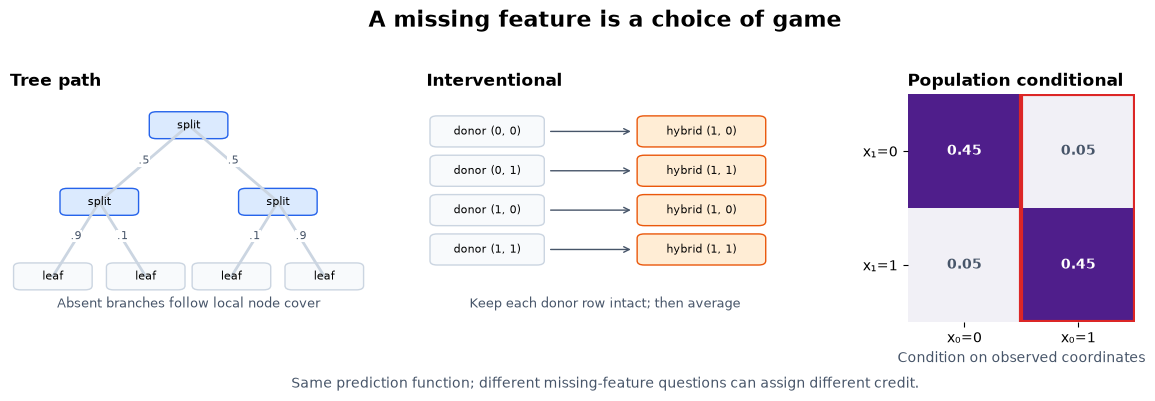

In [9]:
if MAIN:
    refresh_tree_default_methods()
    from chapter16_shapley_attribution_baselines.exercises.part3_model_specific_shap import tree_treeshap_plots as tree_plots

if MAIN:
    refresh_tree_default_methods()
    tree_show_figure(tree_plots.plot_missing_feature_games(), "01_missing_feature_games")

## 2️⃣ From a tree prediction to an exact coalition oracle

We represent one scalar-output tree with parallel arrays. Internal node `n` uses `feature[n]` and
`threshold[n]`; leaves have `left[n] == right[n] == -1`. `cover[n]` is the weighted number of
training examples reaching the node. This plain representation lets us inspect every operation that
an explainer performs.

### Exercise 1 — route a batch through one tree

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 15 minutes on this exercise.
> ```

Implement `tree_predict(tree, x)`. Route all unfinished rows together, replacing each row's current
node until every row reaches a leaf. First round `x` through `float32`, as scikit-learn does
internally, then store that rounded value in `float64` before comparing it with the tree's float64
threshold. The second cast prevents NumPy 1.26 from narrowing an array–scalar comparison back to
float32. Both details matter close to a learned split boundary.

In [10]:
def tree_predict(tree: dict, x: np.ndarray) -> np.ndarray:
    """Predict N rows with one scalar-output tree; match sklearn float32 routing."""
    x = np.asarray(x, dtype=np.float32).astype(np.float64)
    nodes = np.zeros(len(x), dtype=int)
    while True:
        active = np.flatnonzero(tree["left"][nodes] != -1)
        if not len(active):
            return tree["value"][nodes].copy()
        current = nodes[active]
        goes_left = x[active, tree["feature"][current]] <= tree["threshold"][current]
        nodes[active] = np.where(goes_left, tree["left"][current], tree["right"][current])


if MAIN:
    refresh_tree_default_methods()
    tree_tests.test_tree_predict(tree_predict)

tree_predict: repeated thresholds and float32 boundary passed


### Exercise 2 — evaluate the path-dependent game

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵🔵
> 
> You should spend up to 25 minutes on this exercise.
> ```

Implement `tree_path_game(tree, x, masks)`, returning one value per query and coalition. Recurse
from the root. At an internal node splitting feature $j$:

- if `masks[..., j]` is true, use the branch selected by the query;
- if it is false, average the left and right subtree values with weights `cover[left] / cover[node]`
and `cover[right] / cover[node]`.

The same feature can occur more than once on a path. Coalition membership is still a single Boolean
decision: if feature $j$ is present, it controls every split on $j$.

In [11]:
def tree_path_game(tree: dict, x: np.ndarray, masks: np.ndarray) -> np.ndarray:
    """Return (N, K) coalition values using local training-cover branch weights."""
    x = np.asarray(x, dtype=np.float32).astype(np.float64)
    masks = np.asarray(masks, dtype=bool)

    def visit(node):
        left, right = tree["left"][node], tree["right"][node]
        if left == -1:
            return np.full((len(x), len(masks)), tree["value"][node])
        feature = tree["feature"][node]
        lvalue, rvalue = visit(left), visit(right)
        weight = tree["cover"][left] / tree["cover"][node]
        absent = weight * lvalue + (1 - weight) * rvalue
        present = np.where(
            (x[:, feature] <= tree["threshold"][node])[:, None], lvalue, rvalue
        )
        return np.where(masks[None, :, feature], present, absent)

    return visit(0)


if MAIN:
    refresh_tree_default_methods()
    tree_tests.test_tree_path_game(tree_path_game)

tree_path_game: cover weighting and repeated-feature membership passed


### Exercise 3 — contract an exhaustive game into Shapley values

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵🔵
> 
> You should spend up to 20 minutes on this exercise.
> ```

For $d$ features, the Shapley value of feature $j$ is

$$
\phi_j=\sum_{S\subseteq[d]\setminus\{j\}} \frac{|S|!(d-|S|-1)!}{d!}\left[v(S\cup\{j\})-v(S)\right].
$$

Since $\binom{d-1}{|S|}$ subsets have the same size, the coefficient is equivalently
$1/[d\binom{d-1}{|S|}]$. Implement `exact_shapley(values)`, where the final axis stores every
coalition and feature zero is the least-significant bit. Preserve any leading batch axes.

In [12]:
def tree_exact_shapley(values: np.ndarray) -> np.ndarray:
    """Contract a (..., 2**D) game with the exact Shapley subset weights."""
    values = np.asarray(values, dtype=np.float64)
    d = int(math.log2(values.shape[-1]))
    if d < 1 or values.shape[-1] != 2**d:
        raise ValueError("The final axis must contain every subset of D >= 1 features.")
    phi = np.zeros((*values.shape[:-1], d))
    for feature in range(d):
        absent = [s for s in range(2**d) if not s & (1 << feature)]
        present = [s | (1 << feature) for s in absent]
        weights = np.array([1 / (d * math.comb(d - 1, s.bit_count())) for s in absent])
        phi[..., feature] = ((values[..., present] - values[..., absent]) * weights).sum(-1)
    return phi


if MAIN:
    refresh_tree_default_methods()
    tree_tests.test_exact_shapley(tree_exact_shapley)

exact_shapley: signed, interaction and all-ordering checks passed


In [13]:
def tree_coalition_masks(d: int) -> np.ndarray:
    """All subsets, with feature zero in the least-significant bit."""
    return np.array([[bool(s & (1 << j)) for j in range(d)] for s in range(2**d)])


if MAIN:
    refresh_tree_default_methods()
    tiny_masks = tree_coalition_masks(2)
if MAIN:
    refresh_tree_default_methods()
    tiny_tree = tree_tests.binary_tree()
if MAIN:
    refresh_tree_default_methods()
    tiny_x = np.array([[1.0, 1.0]])
if MAIN:
    refresh_tree_default_methods()
    tiny_game = tree_path_game(tiny_tree, tiny_x, tiny_masks)
if MAIN:
    refresh_tree_default_methods()
    tiny_phi = tree_exact_shapley(tiny_game)
if MAIN:
    refresh_tree_default_methods()
    print("coalition values:", tiny_game[0].tolist())
if MAIN:
    refresh_tree_default_methods()
    print("exact SHAP:      ", tiny_phi[0].tolist())

coalition values: [1.5, 2.8000000000000003, 2.5, 3.0]
exact SHAP:       [0.9000000000000001, 0.5999999999999999]


You should see coalition values `[1.5, 2.8, 2.5, 3.0]` and contributions close to `[0.9, 0.6]`. The
empty value $1.5$ plus both contributions reconstructs the prediction $3.0$. The allocation is
already less obvious than the additive formula $x_0+2x_1$: correlated training covers and the root
order change what “missing” means.

## 3️⃣ Replace $2^d$ coalitions with a path recurrence

At a leaf, each unique split feature has two path fractions:

- $z_j$: the fraction of training cover that takes this branch when feature $j$ is absent;
- $o_j$: an indicator that the query takes this branch when feature $j$ is present.

For an interventional query–donor pair, $z_j$ is instead the donor's branch indicator. A leaf
contributes only for compatible present/absent choices. TreeSHAP groups all compatible coalitions by
cardinality and updates those weights as the recursion descends. This avoids materializing all $2^d$
masks.

For a path containing $k$ unique features, define the stored weight at cardinality $s$ as

$$
W_k(s)=\sum_{\substack{S\subseteq[k]\\|S|=s}}
\left(\prod_{i\in S}o_i\right)
\left(\prod_{i\notin S}z_i\right)
\frac{s!(k-s)!}{(k+1)!}.
$$

This is the total probability-weighted Shapley coefficient of every compatible size-$s$ coalition on
the current path. Our representation starts directly with $W_0(0)=1$; it omits the dummy root entry
used to align arrays in the paper's pseudocode.

### Exercise 4 — extend cardinality weights

> ```yaml
> Difficulty: 🔴🔴🔴🔴⚪
> Importance: 🔵🔵🔵🔵🔵
> 
> You should spend up to 35 minutes on this exercise.
> ```

Suppose `weights[:, s]` is the accumulated Shapley path weight for choosing `s` present features
among the current unique path features. Adding one feature sends each old term to two places: absent
leaves the cardinality at `s`, while present moves it to `s+1`.

When a new feature is absent, a size-$s$ coalition stays at size $s$. The ratio of its new and old
factorial coefficients is

$$
\frac{s!(k+1-s)!/(k+2)!}{s!(k-s)!/(k+1)!}=\frac{k+1-s}{k+2}.
$$

When the feature is present, the coalition moves from size $s$ to $s+1$, and the corresponding ratio
is $(s+1)/(k+2)$. Implement `extend_path(weights, zero, one)` from these two cases. Do not mutate
the input.

In [14]:
def extend_path(weights: np.ndarray, zero: np.ndarray, one: np.ndarray) -> np.ndarray:
    """Add a unique feature to batched cardinality weights: (N, k+1) -> (N, k+2)."""
    weights = np.asarray(weights, dtype=np.float64)
    zero, one = np.asarray(zero), np.asarray(one)
    k = weights.shape[1] - 1
    extended = np.zeros((len(weights), k + 2))
    for size in range(k + 1):
        extended[:, size] += zero * weights[:, size] * (k + 1 - size) / (k + 2)
        extended[:, size + 1] += one * weights[:, size] * (size + 1) / (k + 2)
    return extended


if MAIN:
    refresh_tree_default_methods()
    tree_tests.test_extend_path(extend_path)

extend_path: all subsets and cardinality weights passed


### Exercise 5 — unwind an earlier feature

> ```yaml
> Difficulty: 🔴🔴🔴🔴🔴
> Importance: 🔵🔵🔵🔵🔵
> 
> You should spend up to 45 minutes on this exercise.
> ```

A feature may split twice along one root-to-leaf path, but it remains one player in the cooperative
game. Before processing its later split, TreeSHAP removes the earlier extension, carries its
fractions forward, and then inserts the feature once with the combined branch fractions.

Write $W$ for the weights before one feature was added and $W'$ for the weights after it was added.
If the extended path contains $n$ features, the forward recurrence is

$$
W'_s=zW_s\frac{n-s}{n+1}+oW_{s-1}\frac{s}{n+1},
$$

with out-of-range terms equal to zero. Implement the inverse `unwind_path(weights, zero, one)`. Work
backward from the final cardinality. Where `one != 0`, recover the preceding value from the present
term; where `one == 0`, recover it from the absent term. Reject a dead path with both fractions zero
and do not mutate `weights`.

In [15]:
def unwind_path(weights: np.ndarray, zero: np.ndarray, one: np.ndarray) -> np.ndarray:
    """Remove one feature's extension, without mutating its input or dividing by zero."""
    weights = np.asarray(weights, dtype=np.float64)
    zero, one = np.broadcast_arrays(np.asarray(zero), np.asarray(one))
    if np.any((zero == 0) & (one == 0)):
        raise ValueError("A dead path has no reversible extension; prune it first.")
    n = weights.shape[1] - 1
    if n < 1:
        raise ValueError("Cannot remove a feature from the empty path.")
    result = np.zeros((len(weights), n))
    next_one = weights[:, n].copy()
    nonzero = one != 0
    safe_one = np.where(nonzero, one, 1.0)
    safe_zero = np.where(nonzero, 1.0, zero)
    for size in range(n - 1, -1, -1):
        from_one = next_one * (n + 1) / ((size + 1) * safe_one)
        from_zero = weights[:, size] * (n + 1) / ((n - size) * safe_zero)
        result[:, size] = np.where(nonzero, from_one, from_zero)
        next_one = weights[:, size] - result[:, size] * zero * (n - size) / (n + 1)
    return result


if MAIN:
    refresh_tree_default_methods()
    tree_tests.test_unwind_path(unwind_path)

unwind_path: arbitrary removal, zero fractions and no mutation passed


### Exercise 6 — implement recursive TreeSHAP

> ```yaml
> Difficulty: 🔴🔴🔴🔴🔴
> Importance: 🔵🔵🔵🔵🔵
> 
> You should spend up to 60 minutes on this exercise.
> ```

Now assemble the recurrence in `tree_shap(tree, x, donor=None)`. With no donor, missing branches use
training-cover fractions and the function computes exact Shapley values for `tree_path_game`. With
one paired donor per query, a missing feature follows the donor branch; the result is exact for that
query–donor hybrid game.

Carry only live rows down each child. The path state contains unique feature IDs, their accumulated
zero and one fractions, and the cardinality weights. When the current split feature is already
present:

1. remove its earlier path extension;
2. remove its stored feature and fractions;
3. multiply the old fractions by the current branch fractions;
4. extend the path once with the combined fractions.

At a leaf, remove each feature in turn. The sum of the remaining path weights is the Shapley
coefficient accumulated over all positions at which that feature could enter. Multiply it by `(one -
zero)` and the leaf value.

More explicitly, after unwinding feature $j$ from a $k$-feature leaf path, that leaf contributes

$$
\text{leaf value}\times(o_j-z_j)\sum_{s=0}^{k-1}W^{(-j)}_{k-1}(s)
$$

to $\phi_j$. Summing this term over reachable leaves reconstructs the exact weighted marginal
contribution of $j$ without listing the coalitions individually.

In [16]:
def tree_shap(tree: dict, x: np.ndarray, donor: np.ndarray | None = None) -> np.ndarray:
    """Exact path-game SHAP, or paired-query/donor SHAP when donor has shape (N, D)."""
    x = np.asarray(x, dtype=np.float32).astype(np.float64)
    if donor is not None:
        donor = np.asarray(donor, dtype=np.float32).astype(np.float64)
        if donor.shape != x.shape:
            raise ValueError("Each query needs exactly one paired donor row.")
    phi = np.zeros(x.shape, dtype=np.float64)

    def visit(node, rows, features, zeros, ones, weights):
        left, right = tree["left"][node], tree["right"][node]
        if left == -1:
            for index, feature in enumerate(features):
                other_weights = unwind_path(weights, zeros[index], ones[index])
                phi[rows, feature] += (
                    other_weights.sum(1)
                    * (ones[index] - zeros[index])
                    * tree["value"][node]
                )
            return

        feature = tree["feature"][node]
        features, zeros, ones = list(features), list(zeros), list(ones)
        incoming_zero = incoming_one = np.ones(len(rows))
        if feature in features:
            index = features.index(feature)
            incoming_zero, incoming_one = zeros.pop(index), ones.pop(index)
            weights = unwind_path(weights, incoming_zero, incoming_one)
            features.pop(index)

        query_left = x[rows, feature] <= tree["threshold"][node]
        if donor is not None:
            donor_left = donor[rows, feature] <= tree["threshold"][node]
        for child, is_left in ((left, True), (right, False)):
            present = (query_left == is_left).astype(float)
            absent = (
                (donor_left == is_left).astype(float)
                if donor is not None
                else np.full(len(rows), tree["cover"][child] / tree["cover"][node])
            )
            zero, one = incoming_zero * absent, incoming_one * present
            keep = (zero != 0) | (one != 0)
            if not keep.any():
                continue
            visit(
                child,
                rows[keep],
                features + [feature],
                [z[keep] for z in zeros] + [zero[keep]],
                [o[keep] for o in ones] + [one[keep]],
                extend_path(weights[keep], zero[keep], one[keep]),
            )

    visit(0, np.arange(len(x)), [], [], [], np.ones((len(x), 1)))
    return phi


if MAIN:
    refresh_tree_default_methods()
    tree_tests.test_tree_shap(tree_shap)

tree_shap: repeated features, dead donor paths, constants and dummies passed


In [17]:
if MAIN:
    refresh_tree_default_methods()
    import itertools

if MAIN:
    refresh_tree_default_methods()
    import math

if MAIN:
    refresh_tree_default_methods()
    import time

if MAIN:
    refresh_tree_default_methods()
    import numpy as np

def tree__method(methods, name):
    """Resolve a taught method in both the package and AST-extracted notebook."""
    if methods is not None:
        return getattr(methods, name) if hasattr(methods, name) else methods[name]
    local = tree_curriculum_namespace().get(name)
    if callable(local):
        return local
    return getattr(tree__DEFAULT_METHODS, name)

def _as_query(query):
    query = np.asarray(query, dtype=float)
    if query.shape != (2,) or not np.isin(query, [0.0, 1.0]).all():
        raise ValueError("The binary fixture query must contain exactly two zeros/ones.")
    return query

The tiny fixtures construct two trees for the same binary function and one tree where a feature
appears at two thresholds. They expose every node value and cover used by later diagnostics.

In [18]:
def _binary_additive_tree(order=(0, 1), joint=((9.0, 1.0), (1.0, 9.0))):
    """Build an exact tree for f(x)=x0+2*x1 with population node covers."""
    order = tuple(int(feature) for feature in order)
    if sorted(order) != [0, 1]:
        raise ValueError("order must be a permutation of (0, 1).")
    joint = np.asarray(joint, dtype=float)
    if joint.shape != (2, 2) or np.any(joint <= 0):
        raise ValueError("joint must be a positive 2x2 table in (x0, x1) order.")
    examples = np.array(list(itertools.product([0, 1], repeat=2)))
    counts = joint.ravel()
    fields = {key: [] for key in ("left", "right", "feature", "threshold", "value", "cover")}

    def add(depth, keep):
        node = len(fields["left"])
        for key in fields:
            fields[key].append(-1)
        fields["cover"][node] = counts[keep].sum()
        fields["value"][node] = np.average(examples[keep] @ [1.0, 2.0], weights=counts[keep])
        fields["threshold"][node] = 0.5
        if depth < 2:
            feature = order[depth]
            fields["feature"][node] = feature
            fields["left"][node] = add(depth + 1, keep[examples[keep, feature] == 0])
            fields["right"][node] = add(depth + 1, keep[examples[keep, feature] == 1])
        return node

    add(0, np.arange(4))
    return {
        key: np.asarray(value, dtype=int if key in ("left", "right", "feature") else float)
        for key, value in fields.items()
    }

def _repeated_threshold_tree():
    """A hand-computable tree where x0 splits twice but remains one player."""
    return {
        "left": np.array([1, -1, 3, -1, -1]),
        "right": np.array([2, -1, 4, -1, -1]),
        "feature": np.array([0, -1, 0, -1, -1]),
        "threshold": np.array([1.0, 0.0, 2.0, 0.0, 0.0]),
        "value": np.array([20.0, 10.0, 80 / 3, 20.0, 30.0]),
        "cover": np.array([100.0, 40.0, 60.0, 20.0, 40.0]),
    }

The next group constructs population-conditional, empirical interventional and two path-dependent
games for the same binary prediction function. Direct enumeration here is a diagnostic oracle, not
an alternative implementation imported behind the exercises.

In [19]:
def _conditional_binary_game(query, joint):
    """Population-conditional game E[f(X) | X_S=query_S] by direct enumeration."""
    examples = np.array(list(itertools.product([0, 1], repeat=2)), dtype=float)
    probabilities = np.asarray(joint, dtype=float).ravel()
    probabilities /= probabilities.sum()
    targets = examples @ np.array([1.0, 2.0])
    masks = np.array(list(itertools.product([False, True], repeat=2)), dtype=bool)
    # Reorder lexicographic masks to the least-significant-feature convention.
    masks = masks[[0, 2, 1, 3]]
    values = []
    for mask in masks:
        matches = np.all(examples[:, mask] == query[mask], axis=1)
        values.append(np.average(targets[matches], weights=probabilities[matches]))
    return masks, np.asarray(values)

def _interventional_binary_game(query, joint):
    """Marginal/interventional game E[f(x_S, X_-S)] by direct enumeration."""
    examples = np.array(list(itertools.product([0, 1], repeat=2)), dtype=float)
    probabilities = np.asarray(joint, dtype=float).ravel()
    probabilities /= probabilities.sum()
    masks = np.array([[False, False], [True, False], [False, True], [True, True]])
    values = []
    for mask in masks:
        hybrids = np.where(mask, query, examples)
        values.append(np.average(hybrids @ np.array([1.0, 2.0]), weights=probabilities))
    return masks, np.asarray(values)

Now compare those definition-level games with each root ordering's cover-weighted path game and
Saabas allocation.

In [20]:
def correlated_games(query=(1.0, 1.0), joint=((0.45, 0.05), (0.05, 0.45)), methods=None):
    """Compare conditional, interventional and two cover-weighted path games.

    The two trees compute the same f(x)=x0+2*x1 on all binary inputs.  Only the
    root split changes, which makes any difference in their path attributions a
    property of the cover-weighted game rather than the predictive function.
    """
    query = _as_query(query)
    joint = np.asarray(joint, dtype=float)
    masks, conditional = _conditional_binary_game(query, joint)
    _, interventional = _interventional_binary_game(query, joint)
    trees = [_binary_additive_tree((0, 1), joint), _binary_additive_tree((1, 0), joint)]
    path_game = tree__method(methods, "tree_path_game")
    exact = tree__method(methods, "exact_shapley")
    saabas_fn = tree__method(methods, "saabas")
    games = np.vstack(
        [
            conditional,
            interventional,
            path_game(trees[0], query[None], masks)[0],
            path_game(trees[1], query[None], masks)[0],
        ]
    )
    shapley = exact(games)
    saabas_values = np.vstack([saabas_fn(tree, query[None])[1][0] for tree in trees])
    predictions = np.array(
        [tree__method(methods, "tree_predict")(tree, query[None])[0] for tree in trees]
    )
    return {
        "query": query,
        "joint": joint,
        "masks": masks,
        "game_names": [
            "Population conditional",
            "Interventional",
            "Path: x0 root",
            "Path: x1 root",
        ],
        "games": games,
        "shapley": shapley,
        "trees": trees,
        "saabas": saabas_values,
        "predictions": predictions,
        "empty_value": float(games[0, 0]),
    }

These checks enumerate path weights and evaluate a feature that appears at two thresholds. They are
the mechanism evidence behind the cardinality and repeated-feature figures.

In [21]:
def _enumerate_cardinality_weights(zeros, ones):
    """Definition-level subset enumeration for one unique-feature path."""
    zeros, ones = np.asarray(zeros, dtype=float), np.asarray(ones, dtype=float)
    count = len(zeros)
    answer = np.zeros(count + 1)
    for flags in itertools.product([False, True], repeat=count):
        size = sum(flags)
        product = math.prod(ones[j] if flag else zeros[j] for j, flag in enumerate(flags))
        answer[size] += (
            product
            * math.factorial(size)
            * math.factorial(count - size)
            / math.factorial(count + 1)
        )
    return answer

def path_cardinality_diagnostic(zeros=(0.2, 0.7, 0.5), ones=(1.0, 0.0, 1.0), methods=None):
    """Record each extend-path update and verify it against subset enumeration."""
    zeros, ones = np.asarray(zeros, dtype=float), np.asarray(ones, dtype=float)
    if zeros.shape != ones.shape or zeros.ndim != 1 or not len(zeros):
        raise ValueError(
            "zeros and ones must be non-empty one-dimensional arrays of equal length."
        )
    extend = tree__method(methods, "extend_path")
    weights = np.ones((1, 1))
    stages, exact_stages = [weights[0].copy()], [np.ones(1)]
    for index in range(len(zeros)):
        weights = extend(weights, zeros[[index]], ones[[index]])
        stages.append(weights[0].copy())
        exact_stages.append(
            _enumerate_cardinality_weights(zeros[: index + 1], ones[: index + 1])
        )
    return {
        "zeros": zeros,
        "ones": ones,
        "stages": stages,
        "enumerated_stages": exact_stages,
        "max_abs_error": float(
            max(np.max(np.abs(a - b)) for a, b in zip(stages, exact_stages))
        ),
    }

The repeated-feature evidence is separate because it tests a different invariant: two thresholds on
one coordinate still define one cooperative-game player, while an unused coordinate stays dummy.

In [22]:
def repeated_feature_diagnostic(methods=None):
    """Show that repeated x0 splits contract to one player and a dummy stays zero."""
    tree = _repeated_threshold_tree()
    query = np.array([[0.0, 99.0], [1.5, -7.0], [3.0, 4.0]])
    masks = tree__method(methods, "coalition_masks")(2)
    games = tree__method(methods, "tree_path_game")(tree, query, masks)
    phi = tree__method(methods, "tree_shap")(tree, query)
    base, saabas_values = tree__method(methods, "saabas")(tree, query)
    predictions = tree__method(methods, "tree_predict")(tree, query)
    return {
        "tree": tree,
        "query": query,
        "masks": masks,
        "games": games,
        "base": base,
        "phi": phi,
        "saabas": saabas_values,
        "prediction": predictions,
        "dummy_max_abs": float(np.max(np.abs(phi[:, 1]))),
        "additivity_max_abs_error": float(np.max(np.abs(base + phi.sum(1) - predictions))),
    }

Runtime needs its own fixed tree generator and timing harness. The generator supplies all dimensions
declared by the frozen sweep, including unused dummy features, so no dimension is removed after
seeing the timings.

In [23]:
def build_balanced_tree(depth, n_features=None, seed=161390):
    """Build the frozen balanced binary timing tree with one feature per level."""
    depth = int(depth)
    n_features = depth if n_features is None else int(n_features)
    if depth < 1 or n_features < depth:
        raise ValueError("depth must be positive and n_features must supply every tree level.")
    node_count = 2 ** (depth + 1) - 1
    leaf_start = 2**depth - 1
    left = np.full(node_count, -1, dtype=int)
    right = np.full(node_count, -1, dtype=int)
    feature = np.full(node_count, -1, dtype=int)
    threshold = np.zeros(node_count, dtype=float)
    value = np.zeros(node_count, dtype=float)
    cover = np.ones(node_count, dtype=float)
    for node in range(leaf_start):
        level = int(math.floor(math.log2(node + 1)))
        left[node], right[node], feature[node] = 2 * node + 1, 2 * node + 2, level
        threshold[node] = 0.5
    value[leaf_start:] = np.random.default_rng(seed).normal(loc=10.0, scale=3.0, size=2**depth)
    for node in range(leaf_start - 1, -1, -1):
        cover[node] = cover[left[node]] + cover[right[node]]
        value[node] = (
            cover[left[node]] * value[left[node]] + cover[right[node]] * value[right[node]]
        ) / cover[node]
    return {
        "left": left,
        "right": right,
        "feature": feature,
        "threshold": threshold,
        "value": value,
        "cover": cover,
        "n_features": np.array(n_features, dtype=int),
    }

def _fixed_queries(n_features):
    """Eight deterministic binary queries, with a visible 0..7 bit pattern."""
    integers = np.arange(8, dtype=int)
    return np.array(
        [
            [(number >> (feature % 3)) & 1 for feature in range(n_features)]
            for number in integers
        ],
        dtype=float,
    )

The benchmark retains three measurements per point and verifies the full dynamic-programming vector
against enumeration before recording any time.

In [24]:
def _benchmark_axis(specifications, methods, repeats):
    masks_fn = tree__method(methods, "coalition_masks")
    game_fn = tree__method(methods, "tree_path_game")
    exact_fn = tree__method(methods, "exact_shapley")
    dp_fn = tree__method(methods, "tree_shap")
    exact_times, dp_times, errors = [], [], []
    for depth, supplied_features in specifications:
        tree = build_balanced_tree(depth, supplied_features, seed=161390)
        query = _fixed_queries(supplied_features)
        masks = masks_fn(supplied_features)
        expected = exact_fn(game_fn(tree, query, masks))
        actual = dp_fn(tree, query)
        errors.append(float(np.max(np.abs(expected - actual))))
        current_exact, current_dp = [], []
        for _ in range(repeats):
            started = time.perf_counter()
            exact_fn(game_fn(tree, query, masks))
            current_exact.append(time.perf_counter() - started)
            started = time.perf_counter()
            dp_fn(tree, query)
            current_dp.append(time.perf_counter() - started)
        exact_times.append(current_exact)
        dp_times.append(current_dp)
    exact_times, dp_times = np.asarray(exact_times), np.asarray(dp_times)
    return {
        "exhaustive_seconds": exact_times,
        "dynamic_programming_seconds": dp_times,
        "exhaustive_median_seconds": np.median(exact_times, axis=1),
        "dynamic_programming_median_seconds": np.median(dp_times, axis=1),
        "max_abs_error": np.asarray(errors),
        "queries_per_timing": np.array(8, dtype=int),
        "repeats": np.array(repeats, dtype=int),
    }

def benchmark_runtime(methods=None, repeats=3):
    """Run both frozen timing sweeps and retain every wall-clock measurement."""
    repeats = int(repeats)
    if repeats != 3:
        raise ValueError("The frozen protocol requires exactly three timing repetitions.")
    dummy_features = np.array([3, 6, 9, 12, 15], dtype=int)
    depths = np.arange(2, 9, dtype=int)
    dummy = _benchmark_axis([(3, int(count)) for count in dummy_features], methods, repeats)
    depth = _benchmark_axis([(int(value), int(value)) for value in depths], methods, repeats)
    dummy["supplied_features"] = dummy_features
    dummy["tree_depth"] = np.array(3, dtype=int)
    depth["tree_depth"] = depths
    depth["supplied_features"] = depths.copy()
    return {"dummy_features": dummy, "depth": depth}

The editable play recomputes its tree, game and contributions from the chosen query, covers and root
feature. The aggregator stores deterministic mechanism evidence separately from wall-clock
measurements.

In [25]:
def tiny_tree_play(
    query=(1.0, 1.0),
    joint=((9.0, 1.0), (1.0, 9.0)),
    root_feature=0,
    methods=None,
):
    """Editable tiny-tree play: change the query, root feature, or four covers."""
    query = _as_query(query)
    root_feature = int(root_feature)
    if root_feature not in (0, 1):
        raise ValueError("root_feature must be 0 or 1.")
    tree = _binary_additive_tree((root_feature, 1 - root_feature), joint)
    masks = tree__method(methods, "coalition_masks")(2)
    game = tree__method(methods, "tree_path_game")(tree, query[None], masks)[0]
    phi = tree__method(methods, "tree_shap")(tree, query[None])[0]
    base, saabas_values = tree__method(methods, "saabas")(tree, query[None])
    prediction = tree__method(methods, "tree_predict")(tree, query[None])[0]
    return {
        "query": query,
        "joint": np.asarray(joint, dtype=float),
        "root_feature": np.array(root_feature, dtype=int),
        "tree": tree,
        "masks": masks,
        "game": game,
        "base": np.array(base[0]),
        "phi": phi,
        "saabas": saabas_values[0],
        "prediction": np.array(prediction),
    }

In [26]:
def tree_run_diagnostics(methods=None, include_timing=True):
    """Return exact mechanism evidence and a separately persisted timing branch."""
    mechanism = {
        "correlated": correlated_games(methods=methods),
        "cardinality": path_cardinality_diagnostic(methods=methods),
        "repeated_feature": repeated_feature_diagnostic(methods=methods),
        "tiny_play": tiny_tree_play(methods=methods),
    }
    timing = benchmark_runtime(methods=methods) if include_timing else {}
    if timing:
        mechanism["runtime_parity"] = {
            axis: {
                "coordinate": (
                    values["supplied_features"]
                    if axis == "dummy_features"
                    else values["tree_depth"]
                ),
                "max_abs_error": values["max_abs_error"],
            }
            for axis, values in timing.items()
        }
        mechanism["runtime_parity"]["dummy_feature_max_abs"] = np.array(
            np.max(timing["dummy_features"]["max_abs_error"])
        )
        mechanism["runtime_parity"]["depth_max_abs"] = np.array(
            np.max(timing["depth"]["max_abs_error"])
        )
        timing = {
            axis: {key: value for key, value in values.items() if key != "max_abs_error"}
            for axis, values in timing.items()
        }
    return {"mechanism": mechanism, "timing": timing}

## 4️⃣ Ensembles and empirical interventional backgrounds

Tree ensembles are sums of trees plus an offset. Shapley values are linear in the game:

$$
\phi_j\!\left(c+\sum_t \alpha_t v_t\right)=\sum_t\alpha_t\phi_j(v_t).
$$

The offset and every tree's empty value contribute to the base prediction. Signed weights matter:
gradient boosting adds many learning-rate-scaled trees, and a general ensemble adapter should not
assume every coefficient is positive.

### Exercise 7 — combine trees and donor backgrounds

> ```yaml
> Difficulty: 🔴🔴🔴🔴⚪
> Importance: 🔵🔵🔵🔵🔵
> 
> You should spend up to 35 minutes on this exercise.
> ```

Implement `ensemble_shap(ensemble, x, background=None)`. In path mode, explain each tree once and
compute its empty value from the all-absent path game. In interventional mode, pair every query with
every intact background row, run your donor TreeSHAP, reshape, and average across donors. Return a
base value for each query and an `(N,D)` contribution matrix.

In [27]:
def ensemble_shap(
    ensemble: dict, x: np.ndarray, background: np.ndarray | None = None
) -> tuple[np.ndarray, np.ndarray]:
    """Use tree and donor linearity; return base (N,) and contributions (N, D)."""
    x = np.asarray(x)
    phi = np.zeros(x.shape, dtype=float)
    base = np.full(len(x), float(ensemble["offset"]))
    for tree, weight in zip(ensemble["trees"], ensemble["weights"], strict=True):
        if background is None:
            contribution = tree_shap(tree, x)
            empty = tree_path_game(tree, x[:1], np.zeros((1, x.shape[1]), dtype=bool))[0, 0]
        else:
            background = np.asarray(background)
            if not len(background):
                raise ValueError("The empirical background cannot be empty.")
            queries = np.repeat(x, len(background), axis=0)
            donors = np.tile(background, (len(x), 1))
            contribution = tree_shap(tree, queries, donors).reshape(
                len(x), len(background), x.shape[1]
            ).mean(1)
            empty = tree_predict(tree, background).mean()
        phi += weight * contribution
        base += weight * empty
    return base, phi


if MAIN:
    refresh_tree_default_methods()
    tree_tests.test_ensemble_shap(ensemble_shap)

ensemble_shap: signed tree weights, offsets and donor averaging passed


### Exercise 8 — construct the empirical interventional oracle

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵🔵
> 
> You should spend up to 25 minutes on this exercise.
> ```

Implement `interventional_game(predict, x, background, masks)`. For each query and coalition, copy
present coordinates from the query and all missing coordinates from one intact donor. Average
predictions over donors only after evaluating every hybrid.

Do not replace the background by its mean. For nonlinear trees, $f(\mathbb E[B])\neq\mathbb
E[f(B)]$. Do not draw a different donor independently for each missing feature either; that would
define another game.

In [28]:
def interventional_game(
    predict, x: np.ndarray, background: np.ndarray, masks: np.ndarray
) -> np.ndarray:
    """Average predictions of intact-donor hybrids, retaining all supplied donors."""
    if not len(background):
        raise ValueError("The empirical background cannot be empty.")
    result = np.empty((len(x), len(masks)))
    for start in range(0, len(x), 8):
        query = x[start : start + 8]
        hybrids = np.where(
            masks[None, :, None, :], query[:, None, None, :], background[None, None, :, :]
        )
        predictions = predict(hybrids.reshape(-1, x.shape[1]))
        result[start : start + len(query)] = predictions.reshape(
            len(query), len(masks), len(background)
        ).mean(2)
    return result


if MAIN:
    refresh_tree_default_methods()
    tree_tests.test_interventional_game(interventional_game)

interventional_game: intact donors, nonlinear averaging and endpoints passed


## 5️⃣ A fast allocation can conserve the total and still be wrong

Saabas attribution follows only the query's decision path. At each visited split it gives that
feature the change from the parent node expectation to the selected child expectation. These changes
telescope, so the result reconstructs the prediction. But the ordering is fixed by the tree, rather
than averaged across every feature ordering.

### Exercise 9 — implement the Saabas control

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 25 minutes on this exercise.
> ```

First compute every node's cover-weighted expected leaf value. Then route each query down one path
and assign `expected[child] - expected[parent]` to the split feature. Accumulate repeated
appearances of the same feature. Return the root expectation and contribution matrix.

In [29]:
def saabas(tree: dict, x: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    """Assign each visited parent-to-child expectation change to its split feature."""
    x = np.asarray(x, dtype=np.float32).astype(np.float64)
    expected = np.zeros(len(tree["value"]))

    def expectation(node):
        left, right = tree["left"][node], tree["right"][node]
        if left == -1:
            expected[node] = tree["value"][node]
        else:
            expected[node] = (
                tree["cover"][left] * expectation(left)
                + tree["cover"][right] * expectation(right)
            ) / tree["cover"][node]
        return expected[node]

    expectation(0)
    phi = np.zeros(x.shape, dtype=float)
    for row, query in enumerate(x):
        node = 0
        while tree["left"][node] != -1:
            feature = tree["feature"][node]
            child = (
                tree["left"][node]
                if query[feature] <= tree["threshold"][node]
                else tree["right"][node]
            )
            phi[row, feature] += expected[child] - expected[node]
            node = child
    return np.full(len(x), expected[0]), phi


if MAIN:
    refresh_tree_default_methods()
    tree_tests.test_saabas(saabas)

saabas: efficient allocation that differs from Shapley passed


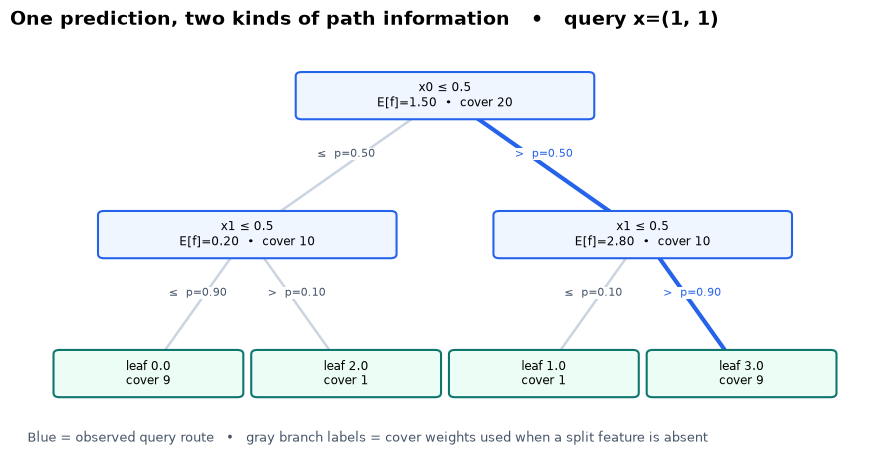

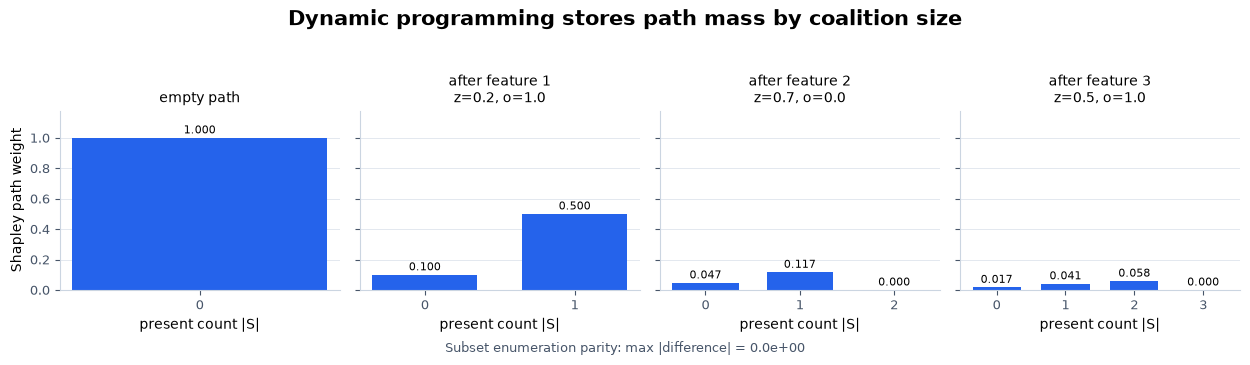

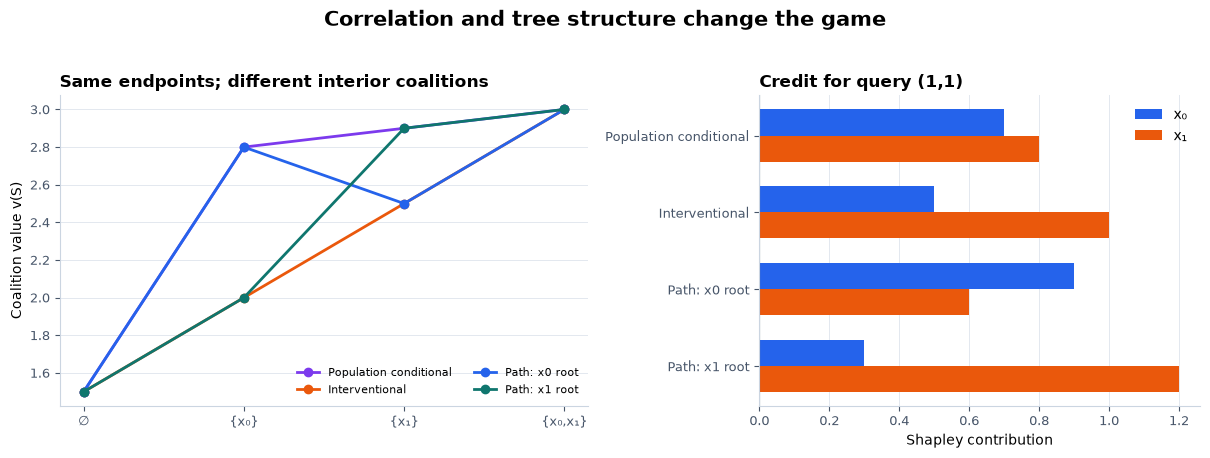

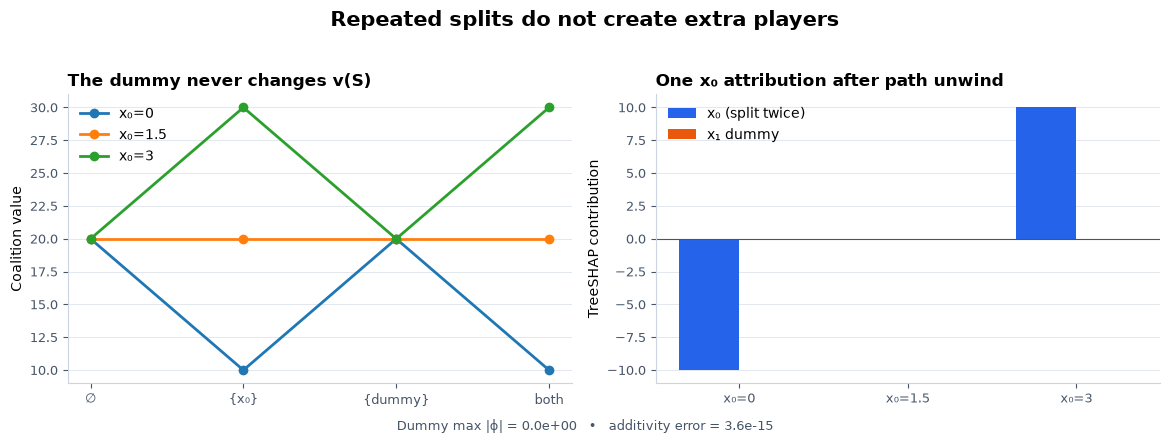

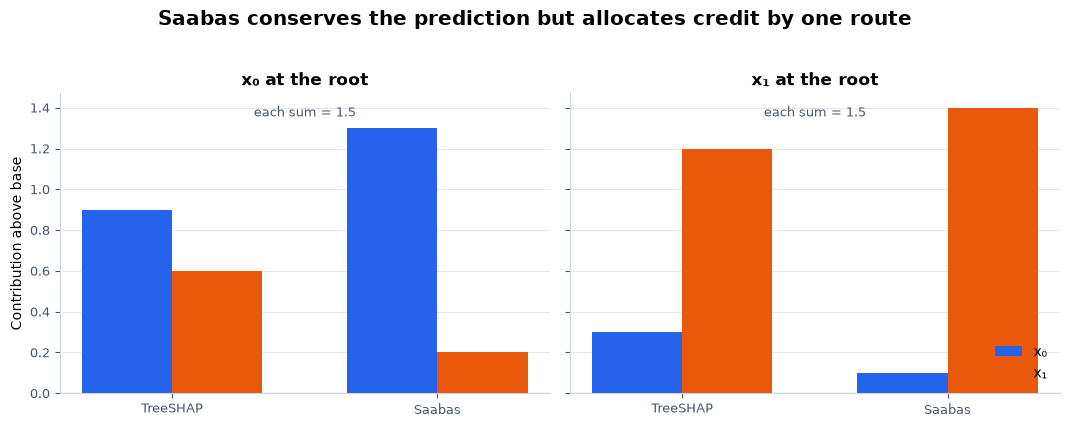

In [30]:
if MAIN:
    refresh_tree_default_methods()
    tree_diagnostics = tree_run_diagnostics(methods=tree_curriculum_namespace(), include_timing=True)
if MAIN:
    refresh_tree_default_methods()
    tree_show_figure(tree_plots.plot_tiny_tree(tree_diagnostics), "02_tiny_tree")
if MAIN:
    refresh_tree_default_methods()
    tree_show_figure(tree_plots.plot_cardinality_weights(tree_diagnostics), "03_cardinality_weights")
if MAIN:
    refresh_tree_default_methods()
    tree_show_figure(tree_plots.plot_correlated_games(tree_diagnostics), "04_correlated_games")
if MAIN:
    refresh_tree_default_methods()
    tree_show_figure(tree_plots.plot_repeated_feature(tree_diagnostics), "05_repeated_feature")
if MAIN:
    refresh_tree_default_methods()
    tree_show_figure(tree_plots.plot_saabas_control(tree_diagnostics), "06_saabas_control")

These figures expose the mechanism rather than treating the recurrence as a black box. The
cardinality panel compares dynamic weights with literal subset enumeration. The repeated-feature
panel shows why the second split must update the same player.

### Try It Yourself 1 — change a path, not just a number

Edit the query and node covers below. Before running, predict which leaf the query reaches and
whether increasing the cover of the *other* branch will raise or lower the empty-coalition value.
Then compare exhaustive and dynamic contributions.

This play is deliberately tiny: you can inspect every branch rather than trusting a polished plot.

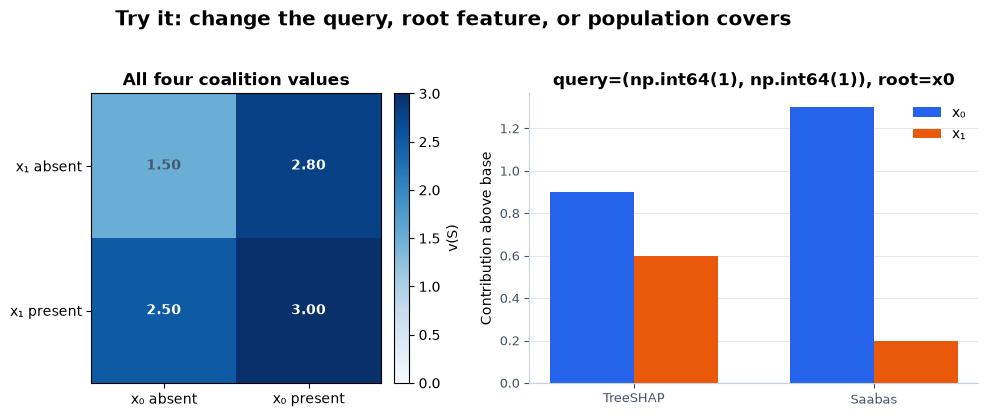

In [31]:
if MAIN:
    refresh_tree_default_methods()
    query = np.array([1.0, 1.0])
if MAIN:
    refresh_tree_default_methods()
    joint = np.array([[9.0, 1.0], [1.0, 9.0]])
root_feature = 0
if MAIN:
    refresh_tree_default_methods()
    tree_tiny_play = tiny_tree_play(query=query, joint=joint, root_feature=root_feature)
if MAIN:
    refresh_tree_default_methods()
    tree_show_figure(tree_plots.plot_tiny_tree_play(tree_tiny_play), "15_tiny_tree_play")

The correlated binary control separates four facts that are easy to blur together:

1. two trees can make identical full predictions;
2. their local cover-weighted path games can differ;
3. the empirical interventional game can differ from both path games;
4. the true conditional game for the specified population is yet another object.

The Saabas panel then gives a sharper negative control: conservation succeeds while Shapley parity
fails.

## 6️⃣ A frozen real-data study

The algorithm is ready; now we test whether it survives fitted models and held-out data. The
complete fitting and evaluation code below is inserted verbatim from `treeshap_study.py`. Read it
before running. It fits every predeclared family, seed and target control; computes rankings on the
explanation split; and only then evaluates deletion curves on the audit split.

The design was frozen before any native tree was fit. It includes:

- three model families × three seeds × clean or shuffled targets = **18 models**;
- path-dependent and 64-donor interventional explanations for every one of **272 held-out rows**;
- all 256 coalition values for both games on the first clean seed of each family;
- a training-target-mean prediction baseline and all nine shuffled-target fits;
- nested and independent background controls for the primary forest;
- 100 fixed random feature-deletion orders.

First adapt scikit-learn's estimators into the plain arrays used by your methods. Forest prediction
is an average of its trees; gradient boosting adds learning-rate-scaled trees to its constant
initializer. The adapter retains signed weights and verifies its predictions against scikit-learn
later.

In [32]:
if MAIN:
    refresh_tree_default_methods()
    import numpy as np

if MAIN:
    refresh_tree_default_methods()
    from sklearn.tree import DecisionTreeRegressor

if MAIN:
    refresh_tree_default_methods()
    from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

def adapt_tree(estimator):
    raw = estimator.tree_
    return {
        "left": raw.children_left.copy(),
        "right": raw.children_right.copy(),
        "feature": raw.feature.copy(),
        "threshold": raw.threshold.copy(),
        "value": raw.value[:, 0, 0].copy(),
        "cover": raw.weighted_n_node_samples.copy(),
    }

def adapt_ensemble(model, family):
    if family == "tree":
        estimators, weights, offset = [model], np.ones(1), 0.0
    elif family == "forest":
        estimators = model.estimators_
        weights, offset = np.full(len(estimators), 1 / len(estimators)), 0.0
    elif family == "boost":
        estimators = model.estimators_.ravel()
        weights = np.full(len(estimators), model.learning_rate)
        offset = float(model.init_.constant_[0, 0])
    else:
        raise ValueError(f"Unknown family {family}.")
    return {
        "trees": [adapt_tree(tree) for tree in estimators],
        "weights": weights,
        "offset": offset,
    }

def ensemble_predict(ensemble, x):
    return float(ensemble["offset"]) + sum(
        weight * tree_predict(tree, x)
        for tree, weight in zip(ensemble["trees"], ensemble["weights"], strict=True)
    )

def ensemble_path_game(ensemble, x, masks):
    return float(ensemble["offset"]) + sum(
        weight * tree_path_game(tree, x, masks)
        for tree, weight in zip(ensemble["trees"], ensemble["weights"], strict=True)
    )

def ensemble_saabas(ensemble, x):
    return sum(
        weight * saabas(tree, x)[1]
        for tree, weight in zip(ensemble["trees"], ensemble["weights"], strict=True)
    )

The fitting cell is the entire frozen model grid. Read the loop order, seeds and shuffled-target
construction. There is no validation search, retry, early stopping or model selection hidden in a
runner.

In [33]:
def tree_fit_models(train):
    models = {}
    for family in ("tree", "forest", "boost"):
        for seed_index in range(3):
            for target_kind in ("clean", "shuffled"):
                seed = 161310 + seed_index
                y = train["y"].copy()
                if target_kind == "shuffled":
                    y = y[np.random.default_rng(161320 + seed_index).permutation(len(y))]
                if family == "tree":
                    model = DecisionTreeRegressor(
                        max_depth=5, min_samples_leaf=8, random_state=seed
                    )
                elif family == "forest":
                    model = RandomForestRegressor(
                        n_estimators=32,
                        max_depth=5,
                        min_samples_leaf=8,
                        max_features=1.0,
                        bootstrap=True,
                        n_jobs=1,
                        random_state=seed,
                    )
                else:
                    model = GradientBoostingRegressor(
                        n_estimators=48,
                        learning_rate=0.05,
                        max_depth=3,
                        min_samples_leaf=8,
                        loss="squared_error",
                        subsample=1.0,
                        random_state=seed,
                    )
                model.fit(train["x"], y)
                key = f"{family}_{target_kind}_{seed_index}"
                models[key] = {
                    "sklearn": model,
                    "ensemble": adapt_ensemble(model, family),
                    "training_targets": y,
                    "parameters": model.get_params(),
                    "train_prediction": model.predict(train["x"]),
                }
    return {
        "models": models,
        "train_ids": train["ids"].copy(),
        "training_mean": float(train["y"].mean()),
    }

`explain_block` checks adapter prediction parity and additivity for all three allocations. For the
three first-seed clean families, it also constructs all 256 coalition values and requires your
dynamic program to match the exhaustive contraction. `prepare_study` fixes mean-absolute rankings
and the primary donor background using explanation rows only.

In [34]:
def tree_explain_block(fitted, x, background):
    result = {}
    masks = tree_coalition_masks(x.shape[1])
    exact_keys = {f"{family}_clean_0" for family in ("tree", "forest", "boost")}
    for key, item in fitted["models"].items():
        ensemble, model = item["ensemble"], item["sklearn"]
        prediction = ensemble_predict(ensemble, x)
        np.testing.assert_allclose(prediction, model.predict(x), atol=1e-10, rtol=1e-10)
        base_path, phi_path = ensemble_shap(ensemble, x)
        base_interventional, phi_interventional = ensemble_shap(ensemble, x, background)
        phi_saabas = ensemble_saabas(ensemble, x)
        for base, phi in (
            (base_path, phi_path),
            (base_interventional, phi_interventional),
            (base_path, phi_saabas),
        ):
            np.testing.assert_allclose(base + phi.sum(1), prediction, atol=1e-8, rtol=1e-8)
        result[key] = {
            "prediction": prediction,
            "base_path": base_path,
            "phi_path": phi_path,
            "base_interventional": base_interventional,
            "phi_interventional": phi_interventional,
            "phi_saabas": phi_saabas,
        }
        if key in exact_keys:
            game_path = ensemble_path_game(ensemble, x, masks)
            # Independent prediction route: exact hybrid games use the fitted sklearn model.
            game_interventional = interventional_game(model.predict, x, background, masks)
            for game, phi in ((game_path, phi_path), (game_interventional, phi_interventional)):
                np.testing.assert_allclose(tree_exact_shapley(game), phi, atol=1e-8, rtol=1e-8)
            result[key].update(game_path=game_path, game_interventional=game_interventional)
    return result

def tree_prepare_study(fitted, train, explain):
    order = tree_background_order(train["ids"], 161360)
    background = train["x"][order[:64]]
    block = tree_explain_block(fitted, explain["x"], background)
    rankings = {
        key: {
            name: np.argsort(-np.abs(item[f"phi_{name}"]).mean(0), kind="stable")
            for name in ("path", "interventional", "saabas")
        }
        for key, item in block.items()
    }
    return {
        "explanation": block,
        "rankings": rankings,
        "explain_ids": explain["ids"].copy(),
        "background_ids": train["ids"][order[:64]],
        "background": background,
        "audit_used_for_selection": False,
    }

The audit evaluator uses the already saved orderings, retains all random deletion orders and
alternate backgrounds, and computes performance for every model. Defining it does not load audit
rows; the explicit load remains below the persisted boundary.

In [35]:
def tree_evaluate_study(fitted, prepared, train, explain, audit):
    block = tree_explain_block(fitted, audit["x"], prepared["background"])
    rng = np.random.default_rng(161380)
    random_orders = np.array([rng.permutation(8) for _ in range(100)])
    deletion = {}
    for key, item in block.items():
        if "game_interventional" not in item:
            continue
        orders = np.vstack(
            [prepared["rankings"][key][name] for name in ("path", "interventional", "saabas")]
            + [random_orders]
        )
        masks_by_order = []
        for order in orders:
            mask, sequence = 255, [255]
            for feature in order:
                mask &= ~(1 << int(feature))
                sequence.append(mask)
            masks_by_order.append(sequence)
        predictions = item["game_interventional"][:, np.array(masks_by_order)]
        deletion[key] = {
            "orders": orders,
            "remaining_masks": np.array(masks_by_order),
            "mse": ((predictions - audit["y"][:, None, None]) ** 2).mean(0),
        }
    primary = fitted["models"]["forest_clean_0"]["ensemble"]
    all_x = np.vstack([explain["x"], audit["x"]])
    backgrounds = {}
    for size, seed in ((16, 161360), (128, 161360), (64, 161361), (64, 161362)):
        order = tree_background_order(train["ids"], seed)[:size]
        base, phi = ensemble_shap(primary, all_x, train["x"][order])
        backgrounds[f"{size}_{seed}"] = {"ids": train["ids"][order], "base": base, "phi": phi}
    return {
        "audit": block,
        "audit_ids": audit["ids"].copy(),
        "audit_targets": audit["y"].copy(),
        "deletion": deletion,
        "backgrounds": backgrounds,
        "performance": {
            key: float(np.mean((item["prediction"] - audit["y"]) ** 2))
            for key, item in block.items()
        },
        "mean_baseline_mse": float(np.mean((fitted["training_mean"] - audit["y"]) ** 2)),
    }

The real-row play is kept separate from evaluation. It recomputes either missing-feature game for a
single selected audit row and model; its default arguments are the frozen canonical play.

In [36]:
def tree_native_play(
    fitted, train, audit, model_key="forest_clean_0", row=0, size=64, game="interventional"
):
    query = audit["x"][[row]]
    indices = tree_background_order(train["ids"], 161360)[:size]
    background = train["x"][indices] if game == "interventional" else None
    if game not in ("interventional", "path"):
        raise ValueError("Choose interventional or path.")
    ensemble = fitted["models"][model_key]["ensemble"]
    base, phi = ensemble_shap(ensemble, query, background)
    return {
        "query": query,
        "source_id": audit["ids"][[row]],
        "base": base,
        "phi": phi,
        "prediction": ensemble_predict(ensemble, query),
        "target": audit["y"][[row]],
    }

### Fit, prepare, and cross the audit boundary

The next two cells make the split boundary visible. The first loads only training and explanation
rows, fits all 18 models, fixes feature rankings, and persists that prepared state. The literal
audit load appears only in the following cell.

### Visible supporting scientific function: `DETERMINISTIC_ARTIFACTS`

In [37]:
tree_helper_run_native_DETERMINISTIC_ARTIFACTS = (
    "fitted.pt",
    "prepared.pt",
    "evaluated.pt",
    "diagnostics.pt",
    "reference.pt",
    "play.pt",
)

### Visible supporting scientific function: `TIMING_ARTIFACT`

In [38]:
tree_helper_run_native_TIMING_ARTIFACT = "timings.pt"

### Visible supporting scientific function: `digest`

In [39]:
if MAIN:
    from pathlib import Path
if MAIN:
    import hashlib

def tree_helper_run_native_digest(path: Path) -> str:
    return hashlib.sha256(path.read_bytes()).hexdigest()

### Visible supporting scientific function: `_without_sklearn`

In [40]:
if MAIN:
    from typing import Any
if MAIN:
    import numpy as np

def tree_helper_run_native__without_sklearn(value: Any) -> Any:
    """Copy a nested fitted payload while removing live sklearn estimators."""
    if isinstance(value, dict):
        return {key: tree_helper_run_native__without_sklearn(item) for key, item in value.items() if key != "sklearn"}
    if isinstance(value, list):
        return [tree_helper_run_native__without_sklearn(item) for item in value]
    if isinstance(value, tuple):
        return tuple(tree_helper_run_native__without_sklearn(item) for item in value)
    if isinstance(value, np.ndarray):
        return value.copy()
    return value

### Visible supporting scientific function: `serializable_fitted`

In [41]:
def tree_helper_run_native_serializable_fitted(fitted: dict) -> dict:
    """Return fitted numerical/tree evidence without live sklearn estimators."""
    return tree_helper_run_native__without_sklearn(fitted)

### Visible supporting scientific function: `save_payload`

In [42]:
if MAIN:
    from typing import Any
if MAIN:
    from pathlib import Path
if MAIN:
    import torch

def tree_helper_run_native_save_payload(directory: Path, name: str, value: Any) -> Path:
    """Persist a named course-owned payload; fitted.pt is stripped of sklearn objects."""
    if Path(name).name != name or not name.endswith(".pt"):
        raise ValueError("Payload names must be simple .pt filenames.")
    path = Path(directory) / name
    path.parent.mkdir(parents=True, exist_ok=True)
    if name == "fitted.pt":
        value = tree_helper_run_native_serializable_fitted(value)
    torch.save(value, path)
    return path

### Visible supporting scientific function: `_reference_scalars`

In [43]:
if MAIN:
    from typing import Any
if MAIN:
    import numpy as np

def tree_helper_run_native__reference_scalars(value: Any, prefix: str = "") -> dict[str, int | float | bool | str]:
    """Flatten scalar reference outcomes for the JSON summary; arrays remain in reference.pt."""
    result: dict[str, int | float | bool | str] = {}
    if isinstance(value, dict):
        for key, item in value.items():
            result.update(tree_helper_run_native__reference_scalars(item, f"{prefix}.{key}" if prefix else str(key)))
    elif isinstance(value, (bool, str, int, float, np.bool_, np.integer, np.floating)):
        result[prefix] = value.item() if isinstance(value, np.generic) else value
    return result

### Visible supporting scientific function: `summarize`

In [44]:
if MAIN:
    from typing import Any

def tree_helper_run_native_summarize(
    fitted: dict,
    prepared: dict,
    evaluated: dict,
    diagnostics: dict,
    reference: dict,
) -> dict[str, Any]:
    models = fitted["models"]
    component_trees = sum(len(item["ensemble"]["trees"]) for item in models.values())
    exact_keys = [key for key, item in prepared["explanation"].items() if "game_path" in item]
    clean = {key: value for key, value in evaluated["performance"].items() if "_clean_" in key}
    shuffled = {
        key: value for key, value in evaluated["performance"].items() if "_shuffled_" in key
    }
    return {
        "model_fits": len(models),
        "clean_fits": len(clean),
        "shuffled_fits": len(shuffled),
        "component_trees": component_trees,
        "model_families": ["tree", "forest", "boost"],
        "training_seeds": [161310, 161311, 161312],
        "train_rows": len(fitted["train_ids"]),
        "explanation_row_count": len(prepared["explain_ids"]),
        "heldout_row_count": len(evaluated["audit_ids"]),
        "rows_explained_per_model": len(prepared["explain_ids"]) + len(evaluated["audit_ids"]),
        "model_row_explanations": len(models)
        * (len(prepared["explain_ids"]) + len(evaluated["audit_ids"])),
        "coalitions": 256,
        "exact_models": len(exact_keys),
        "exact_games": 2,
        "background_rows": len(prepared["background_ids"]),
        "background_variants": len(evaluated["backgrounds"]),
        "deletion_models": len(evaluated["deletion"]),
        "saabas_models": len(models),
        "random_order_controls": 100,
        "audit_used_for_selection": prepared["audit_used_for_selection"],
        "audit_mse_clean": clean,
        "audit_mse_shuffled": shuffled,
        "training_mean_audit_mse": evaluated["mean_baseline_mse"],
        "diagnostic_groups": sorted(diagnostics),
        "reference_scalars": tree_helper_run_native__reference_scalars(reference),
    }

### Visible supporting scientific function: `persist_completed`

In [45]:
if MAIN:
    from typing import Any
if MAIN:
    from pathlib import Path
if MAIN:
    import json

def tree_helper_run_native_persist_completed(
    directory: Path,
    fitted: dict,
    prepared: dict,
    evaluated: dict,
    diagnostics: dict,
    reference: dict,
    play: dict,
) -> dict[str, Any]:
    """Persist post-audit evidence, retaining timing in its own nondeterministic artifact."""
    directory = Path(directory)
    boundary_path = directory / "before_audit.json"
    if not boundary_path.exists():
        raise ValueError("Prepared evidence must be persisted before audit evaluation.")
    boundary = json.loads(boundary_path.read_text())
    if boundary.get("audit_loaded") is not False:
        raise ValueError("The recorded preparation boundary is invalid.")
    if tree_helper_run_native_digest(directory / "prepared.pt") != boundary.get("prepared_sha256"):
        raise ValueError("Prepared evidence changed after the audit boundary.")
    if diagnostics.keys() != {"mechanism", "timing"}:
        raise ValueError("Diagnostics must retain separate mechanism and timing branches.")
    tree_helper_run_native_save_payload(directory, "evaluated.pt", evaluated)
    tree_helper_run_native_save_payload(directory, "diagnostics.pt", diagnostics["mechanism"])
    tree_helper_run_native_save_payload(directory, tree_helper_run_native_TIMING_ARTIFACT, diagnostics["timing"])
    tree_helper_run_native_save_payload(directory, "reference.pt", reference)
    tree_helper_run_native_save_payload(directory, "play.pt", play)
    summary = tree_helper_run_native_summarize(fitted, prepared, evaluated, diagnostics["mechanism"], reference)
    (directory / "summary.json").write_text(json.dumps(summary, indent=2) + "\n")
    expected = set(tree_helper_run_native_DETERMINISTIC_ARTIFACTS) | {tree_helper_run_native_TIMING_ARTIFACT}
    present = {path.name for path in directory.glob("*.pt")}
    if present != expected:
        raise ValueError(f"Native artifact set mismatch: {sorted(present)}")
    return summary

### Visible supporting scientific function: `write_before_audit`

In [46]:
if MAIN:
    from typing import Any
if MAIN:
    from pathlib import Path
if MAIN:
    import hashlib
if MAIN:
    import json
if MAIN:
    import numpy as np

def tree_helper_run_native_write_before_audit(directory: Path, prepared: dict) -> dict[str, Any]:
    """Seal already-saved fitted/prepared payloads before the audit split is loaded."""
    directory = Path(directory)
    if prepared.get("audit_used_for_selection") is not False:
        raise ValueError("Prepared rankings must explicitly exclude the audit split.")
    fitted_path = directory / "fitted.pt"
    prepared_path = directory / "prepared.pt"
    if not fitted_path.is_file() or not prepared_path.is_file():
        raise ValueError("Save fitted.pt and prepared.pt before sealing the audit boundary.")
    boundary = {
        "phase": "prepared_before_audit",
        "audit_loaded": False,
        "fitted_sha256": tree_helper_run_native_digest(fitted_path),
        "prepared_sha256": tree_helper_run_native_digest(prepared_path),
        "explain_ids_sha256": hashlib.sha256(
            np.asarray(prepared["explain_ids"]).tobytes()
        ).hexdigest(),
        "background_ids_sha256": hashlib.sha256(
            np.asarray(prepared["background_ids"]).tobytes()
        ).hexdigest(),
    }
    (directory / "before_audit.json").write_text(json.dumps(boundary, indent=2) + "\n")
    return boundary

### Visible supporting scientific function: `write_notebook_summary`

In [47]:
if MAIN:
    from pathlib import Path
if MAIN:
    import json

def tree_helper_run_native_write_notebook_summary(output_root: Path, native_directory: Path, summary: dict) -> Path:
    """Write the small JSON index consumed by the fresh-kernel executor."""
    output_root = Path(output_root).resolve()
    native_directory = Path(native_directory).resolve()
    native_directory.relative_to(output_root)
    payload = dict(summary, native_directory=str(native_directory))
    path = output_root / "native_summary.json"
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(payload, indent=2) + "\n")
    return path

In [48]:
if MAIN:
    refresh_tree_default_methods()
    tree_persist_completed = tree_helper_run_native_persist_completed
if MAIN:
    refresh_tree_default_methods()
    tree_save_payload = tree_helper_run_native_save_payload
if MAIN:
    refresh_tree_default_methods()
    tree_write_before_audit = tree_helper_run_native_write_before_audit
if MAIN:
    refresh_tree_default_methods()
    tree_write_notebook_summary = tree_helper_run_native_write_notebook_summary

if MAIN:
    refresh_tree_default_methods()
    OUTPUT_ROOT = Path(
        os.environ.get("ARENA_TREESHAP_OUTPUT_DIRECTORY", canonical_dir / "artifacts" / "tree")
    )
if MAIN:
    refresh_tree_default_methods()
    NATIVE_DIR = OUTPUT_ROOT / "native"
if MAIN:
    refresh_tree_default_methods()
    NATIVE_DIR.mkdir(parents=True, exist_ok=True)

if MAIN:
    refresh_tree_default_methods()
    tree_train = tree_load_split("train")
if MAIN:
    refresh_tree_default_methods()
    tree_explain = tree_load_split("explain")
if MAIN:
    refresh_tree_default_methods()
    tree_fitted = tree_fit_models(tree_train)
if MAIN:
    refresh_tree_default_methods()
    tree_prepared = tree_prepare_study(tree_fitted, tree_train, tree_explain)
if MAIN:
    refresh_tree_default_methods()
    tree_save_payload(NATIVE_DIR, "fitted.pt", tree_fitted)
if MAIN:
    refresh_tree_default_methods()
    tree_save_payload(NATIVE_DIR, "prepared.pt", tree_prepared)
if MAIN:
    refresh_tree_default_methods()
    tree_write_before_audit(NATIVE_DIR, tree_prepared)
if MAIN:
    refresh_tree_default_methods()
    print("Prepared rankings saved before audit load:", not tree_prepared["audit_used_for_selection"])

Prepared rankings saved before audit load: True


Expected: `Prepared rankings saved before audit load: True`. This ordering does not make the audit
set magically unbiased for every later question. It means only that the predeclared rankings and
primary background were fixed without using audit rows or labels.

In [49]:
if MAIN:
    refresh_tree_default_methods()
    tree_audit = tree_load_split("audit")
if MAIN:
    refresh_tree_default_methods()
    tree_evaluated = tree_evaluate_study(tree_fitted, tree_prepared, tree_train, tree_explain, tree_audit)
if MAIN:
    refresh_tree_default_methods()
    print("Models evaluated:", len(tree_evaluated["performance"]))
if MAIN:
    refresh_tree_default_methods()
    print("Audit rows:", len(tree_evaluated["audit_ids"]))

Models evaluated: 18
Audit rows: 119


Expected: 18 models and 119 audit rows. Before interpreting feature values, inspect the predictive
control. Shuffled-target models should fail on held-out recipes; if they do not, attribution plots
from the clean models are not the first thing to debug.

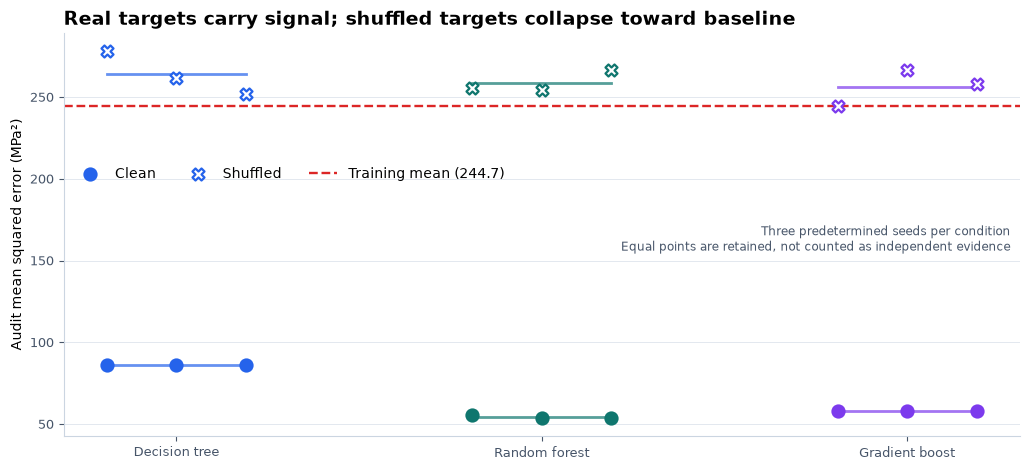

In [50]:
if MAIN:
    refresh_tree_default_methods()
    tree_show_figure(tree_plots.plot_performance(tree_evaluated), "07_audit_performance")

On the frozen run, the training-mean baseline had audit MSE **244.68 MPa²**. Clean decision trees
scored **86.38**, clean forests **53.74–55.68**, and clean boosted ensembles **58.19**. The
shuffled-target controls scored **244.30–277.88**, failing to improve reliably on the constant
predictor. This is the required gate before interpreting their attributions.

The three clean decision-tree fits and three clean boosted fits make identical full predictions
here; these algorithms have no effective stochastic choice under the frozen settings and data. Their
repeated seeds are reproducibility checks, not three independent uncertainty estimates. The
bootstrapped forests do vary across seeds.

### Independent reference comparison — including a failure

Our exhaustive subset calculations are independent of the dynamic program but reuse our tree
adapter. The next check adds the installed SHAP 0.49.1 `TreeExplainer` implementation: raw
regression output, explicit `tree_path_dependent` or `interventional` mode, and the exact frozen
background.

It compares actual predictions, bases and every coordinate of every local vector for all 18 models
and all 272 held-out rows. The compiled interventional implementation uses float32 contribution
buffers, so its frozen tolerance is `atol=2e-5, rtol=2e-6`; the float64 exhaustive oracle uses
`atol=rtol=1e-8`. These comparisons are stronger than checking only additivity.

The frozen expectation that unmodified SHAP 0.49.1 would meet that tolerance was **falsified**. Its
compiled interventional adapter narrows tree thresholds to float32. One learned threshold,
`10.099999904632568`, becomes `10.100000381469727`; a query whose sklearn input is rounded to the
latter value then takes the opposite branch. In the primary-forest example, the raw reference misses
two explanation rows by about **0.4902 MPa**. We retain every affected model-row pair and its arrays
across the full 18-model comparison.

We also run a separately labeled compatibility reference. It replaces every compiled-explainer
threshold by the greatest float32 number no larger than the original threshold. For every
float32-representable query $q$ and finite threshold $t$,

$$q\le t\quad\Longleftrightarrow\quad q\le \lfloor t\rfloor_{32}.$$

This global transformation is applied to a separate copied explainer before any row is explained. It
does not post-process individual examples or attribution arrays. It leaves the fitted model, student
algorithm, selected rows and tolerance unchanged, then recomputes reference attributions; affected
rows are expected to change. Its strict agreement supports the diagnosis while the raw failure
remains part of the result.

### Visible supporting scientific function: `COMPILED_INTERVENTIONAL_ATOL`

In [51]:
tree_helper_treeshap_reference_COMPILED_INTERVENTIONAL_ATOL = 2e-5

### Visible supporting scientific function: `COMPILED_INTERVENTIONAL_RTOL`

In [52]:
tree_helper_treeshap_reference_COMPILED_INTERVENTIONAL_RTOL = 2e-6

### Visible supporting scientific function: `EXACT_KEYS`

In [53]:
if MAIN:
    tree_helper_treeshap_reference_EXACT_KEYS = tuple(f"{family}_clean_0" for family in ("tree", "forest", "boost"))

### Visible supporting scientific function: `MODEL_KEYS`

In [54]:
if MAIN:
    tree_helper_treeshap_reference_MODEL_KEYS = tuple(
        f"{family}_{target}_{seed_index}"
        for family in ("tree", "forest", "boost")
        for seed_index in range(3)
        for target in ("clean", "shuffled")
    )

### Visible supporting scientific function: `_interventional_game_reference`

In [55]:
if MAIN:
    import numpy as np

def tree_helper_treeshap_reference__interventional_game_reference(predict, x, background):
    """Enumerate all intact-donor games for the rounded-threshold proof."""
    masks = np.array(
        [[bool(mask & (1 << feature)) for feature in range(8)] for mask in range(256)]
    )
    values = np.empty((len(x), len(masks)), dtype=np.float64)
    for start in range(0, len(x), 8):
        query = x[start : start + 8]
        hybrids = np.where(
            masks[None, :, None, :],
            query[:, None, None, :],
            background[None, None, :, :],
        )
        prediction = predict(hybrids.reshape(-1, 8))
        values[start : start + len(query)] = prediction.reshape(
            len(query), 256, 64
        ).mean(axis=2)
    return values

### Visible supporting scientific function: `_model_hash`

In [56]:
if MAIN:
    import hashlib
if MAIN:
    import pickle

def tree_helper_treeshap_reference__model_hash(model) -> str:
    return hashlib.sha256(pickle.dumps(model, protocol=5)).hexdigest()

### Visible supporting scientific function: `ATOL`

In [57]:
tree_helper_treeshap_reference_ATOL = tree_helper_treeshap_reference_RTOL = 1e-8

### Visible supporting scientific function: `_max_abs`

In [58]:
if MAIN:
    import numpy as np

def tree_helper_treeshap_reference__max_abs(actual: np.ndarray, expected: np.ndarray) -> float:
    actual, expected = np.asarray(actual), np.asarray(expected)
    if actual.shape != expected.shape:
        raise AssertionError(f"Shape mismatch: {actual.shape} != {expected.shape}")
    return float(np.max(np.abs(actual - expected), initial=0.0))

### Visible supporting scientific function: `_require_close`

In [59]:
if MAIN:
    import numpy as np

def tree_helper_treeshap_reference__require_close(name, actual, expected, *, atol=tree_helper_treeshap_reference_ATOL, rtol=tree_helper_treeshap_reference_RTOL) -> float:
    actual, expected = np.asarray(actual), np.asarray(expected)
    try:
        np.testing.assert_allclose(actual, expected, atol=atol, rtol=rtol)
    except AssertionError as error:
        raise AssertionError(f"{name} failed full-value parity.\n{error}") from error
    return tree_helper_treeshap_reference__max_abs(actual, expected)

### Visible supporting scientific function: `_floor_float32_thresholds`

In [60]:
if MAIN:
    import numpy as np

def tree_helper_treeshap_reference__floor_float32_thresholds(original: np.ndarray) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    nearest = np.asarray(original, dtype=np.float32)
    rounded_up = nearest.astype(np.float64) > np.asarray(original, dtype=np.float64)
    corrected = nearest.copy()
    corrected[rounded_up] = np.nextafter(
        corrected[rounded_up], np.float32(-np.inf)
    )
    return nearest, corrected, rounded_up

### Visible supporting scientific function: `_threshold_copies`

In [61]:
if MAIN:
    import copy
if MAIN:
    import numpy as np

def tree_helper_treeshap_reference__threshold_copies(raw_explainer, sklearn_model, all_source_x):
    original = raw_explainer.model.thresholds.copy()
    internal = (raw_explainer.model.children_left >= 0) & (raw_explainer.model.features >= 0)
    nearest, corrected_values, rounded_up = tree_helper_treeshap_reference__floor_float32_thresholds(original)
    change = internal & rounded_up

    corrected = copy.deepcopy(raw_explainer)
    corrected.model.thresholds[internal] = corrected_values[internal].astype(np.float64)
    corrected.expected_value = corrected.model.predict(corrected.data).mean(0)

    nearest_model = copy.deepcopy(raw_explainer)
    nearest_model.model.thresholds[internal] = nearest[internal].astype(np.float64)
    nearest_model.expected_value = nearest_model.model.predict(nearest_model.data).mean(0)

    positions = np.argwhere(change)
    trees = positions[:, 0] if len(positions) else np.empty(0, dtype=np.int64)
    nodes = positions[:, 1] if len(positions) else np.empty(0, dtype=np.int64)
    features = raw_explainer.model.features[change].astype(np.int64)
    changed_original = original[change]
    changed_nearest = nearest[change]
    changed_corrected = corrected_values[change]
    lower = np.nextafter(changed_corrected, np.float32(-np.inf))
    upper = np.nextafter(changed_corrected, np.float32(np.inf))
    neighbors = np.column_stack([lower, changed_corrected, upper]).astype(np.float32)
    original_routes = neighbors.astype(np.float64) <= changed_original[:, None]
    corrected_routes = neighbors <= changed_corrected[:, None]
    raw_routes = neighbors <= changed_nearest[:, None]
    expected_routes = np.tile(np.array([True, True, False]), (len(positions), 1))
    if not np.array_equal(original_routes, expected_routes):
        raise AssertionError("Float32 boundary neighbors do not bracket original thresholds.")
    if not np.array_equal(corrected_routes, expected_routes):
        raise AssertionError("Corrected threshold boundary proof failed.")

    source_mismatches_raw = np.zeros(len(positions), dtype=np.int64)
    for index, (feature, threshold, raw_threshold, fixed_threshold) in enumerate(
        zip(features, changed_original, changed_nearest, changed_corrected, strict=True)
    ):
        values = all_source_x[:, feature]
        original_route = values.astype(np.float64) <= threshold
        corrected_route = values <= fixed_threshold
        if not np.array_equal(original_route, corrected_route):
            raise AssertionError("Correction changed an original sklearn route on source data.")
        source_mismatches_raw[index] = np.count_nonzero(original_route != (values <= raw_threshold))

    corrected_source_route_disagreements = 0
    for tree_index, node_index in np.argwhere(internal):
        feature = raw_explainer.model.features[tree_index, node_index]
        values = all_source_x[:, feature]
        original_route = values.astype(np.float64) <= original[tree_index, node_index]
        corrected_route = values <= corrected_values[tree_index, node_index]
        corrected_source_route_disagreements += int(
            np.count_nonzero(original_route != corrected_route)
        )
    if corrected_source_route_disagreements:
        raise AssertionError("Floored thresholds changed original routes on source data.")

    corrected_prediction = corrected.model.predict(all_source_x)
    sklearn_prediction = sklearn_model.predict(all_source_x)
    corrected_prediction_error = tree_helper_treeshap_reference__require_close(
        "corrected explainer routes on all 1,030 source rows",
        corrected_prediction,
        sklearn_prediction,
    )
    nearest_prediction = nearest_model.model.predict(all_source_x)
    return corrected, nearest_model, {
        "component_tree_count": int(len(original)),
        "internal_threshold_count": int(np.count_nonzero(internal)),
        "rounded_up_threshold_count": int(np.count_nonzero(change)),
        "tree_index": trees,
        "node_index": nodes,
        "feature": features,
        "original": changed_original,
        "raw_nearest_float32": changed_nearest,
        "corrected_floor_float32": changed_corrected,
        "neighbor_values": neighbors,
        "original_neighbor_routes": original_routes,
        "raw_neighbor_routes": raw_routes,
        "corrected_neighbor_routes": corrected_routes,
        "source_raw_route_mismatch_count": source_mismatches_raw,
        "all_source_corrected_route_disagreement_count": corrected_source_route_disagreements,
        "all_source_corrected_prediction_max_abs_error": corrected_prediction_error,
        "all_source_raw_rounded_prediction_max_abs_error": tree_helper_treeshap_reference__max_abs(
            nearest_prediction, sklearn_prediction
        ),
        "all_source_raw_rounded_prediction_mismatch_count": int(
            np.count_nonzero(~np.isclose(nearest_prediction, sklearn_prediction, atol=tree_helper_treeshap_reference_ATOL, rtol=tree_helper_treeshap_reference_RTOL))
        ),
    }

### Visible supporting scientific function: `_compiled_reference`

In [62]:
if MAIN:
    import numpy as np

def tree_helper_treeshap_reference__compiled_reference(model, all_x, background, all_source_x, *, exact_raw_game=False):
    import shap

    model_hash_before = tree_helper_treeshap_reference__model_hash(model)
    path_explainer = shap.TreeExplainer(
        model, model_output="raw", feature_perturbation="tree_path_dependent"
    )
    if path_explainer.feature_perturbation != "tree_path_dependent":
        raise AssertionError("Path reference did not retain the explicit perturbation mode.")
    phi_path = np.asarray(
        path_explainer.shap_values(all_x, approximate=False, check_additivity=True),
        dtype=np.float64,
    )
    base_path = np.full(len(all_x), np.asarray(path_explainer.expected_value, dtype=np.float64).item())

    raw = shap.TreeExplainer(
        model,
        data=background,
        model_output="raw",
        feature_perturbation="interventional",
    )
    if raw.feature_perturbation != "interventional" or raw.model_output != "raw":
        raise AssertionError("Interventional reference changed the explicit mode/output.")
    if raw.data.shape != (64, 8) or raw.data.dtype != np.float32:
        raise AssertionError("TreeExplainer did not retain the complete float32 background.")
    if not np.array_equal(raw.data, background):
        raise AssertionError("TreeExplainer altered or subsampled the 64-row background.")
    phi_raw = np.asarray(
        # Preserve the unmodified library output even where SHAP's own loose
        # additivity guard raises; the strict residual is checked and returned below.
        raw.shap_values(all_x, approximate=False, check_additivity=False), dtype=np.float64
    )
    base_raw = np.full(len(all_x), np.asarray(raw.expected_value, dtype=np.float64).item())

    corrected, nearest_model, threshold_audit = tree_helper_treeshap_reference__threshold_copies(
        raw, model, all_source_x
    )
    if not np.array_equal(corrected.data, background) or corrected.data.shape != (64, 8):
        raise AssertionError("Corrected explainer must still use every frozen donor.")
    phi_corrected = np.asarray(
        corrected.shap_values(all_x, approximate=False, check_additivity=True),
        dtype=np.float64,
    )
    base_corrected = np.full(len(all_x), np.asarray(corrected.expected_value, dtype=np.float64).item())
    nearest_prediction = nearest_model.model.predict(all_x)
    nearest_base = np.full(len(all_x), np.asarray(nearest_model.expected_value, dtype=np.float64).item())
    raw_rounding_error = tree_helper_treeshap_reference__require_close(
        "unmodified C++ totals against nearest-float32 threshold model",
        nearest_base + phi_raw.sum(axis=1),
        nearest_prediction,
        atol=tree_helper_treeshap_reference_COMPILED_INTERVENTIONAL_ATOL,
        rtol=tree_helper_treeshap_reference_COMPILED_INTERVENTIONAL_RTOL,
    )
    model_hash_after = tree_helper_treeshap_reference__model_hash(model)
    if model_hash_before != model_hash_after:
        raise AssertionError("Reference construction mutated the fitted sklearn model.")
    result = {
        "prediction": np.asarray(model.predict(all_x), dtype=np.float64),
        "base_path": base_path,
        "phi_path": phi_path,
        "base_interventional_raw": base_raw,
        "phi_interventional_raw": phi_raw,
        "raw_nearest_threshold_prediction": nearest_prediction,
        "raw_nearest_threshold_base": nearest_base,
        "base_interventional_corrected": base_corrected,
        "phi_interventional_corrected": phi_corrected,
        "raw_nearest_threshold_additivity_max_abs_error": raw_rounding_error,
        "threshold_audit": threshold_audit,
        "sklearn_model_sha256_before": model_hash_before,
        "sklearn_model_sha256_after": model_hash_after,
    }
    if exact_raw_game:
        result["game_interventional_raw_nearest"] = tree_helper_treeshap_reference__interventional_game_reference(
            nearest_model.model.predict, all_x, background
        )
    return result

### Visible supporting scientific function: `_isclose_rows`

In [63]:
if MAIN:
    import numpy as np

def tree_helper_treeshap_reference__isclose_rows(actual, expected, *, atol, rtol) -> np.ndarray:
    close = np.isclose(np.asarray(actual), np.asarray(expected), atol=atol, rtol=rtol)
    return close if close.ndim == 1 else close.reshape(len(close), -1).all(axis=1)

### Visible supporting scientific function: `ADDENDUM_SHA256`

In [64]:
tree_helper_treeshap_reference_ADDENDUM_SHA256 = "2e639c56060d45131a093caeb838a8896399a2d6e89cba9fe477bcd9b816023e"

### Visible supporting scientific function: `HERE`

In [65]:
if MAIN:
    from pathlib import Path

if MAIN:
    tree_helper_treeshap_reference_HERE = tree_root_dir / 'chapter16_shapley_attribution_baselines' / "exercises" / 'part13_treeshap'

### Visible supporting scientific function: `_sha256`

In [66]:
if MAIN:
    from pathlib import Path
if MAIN:
    import hashlib

def tree_helper_treeshap_reference__sha256(path: Path) -> str:
    return hashlib.sha256(path.read_bytes()).hexdigest()

### Visible supporting scientific function: `_reference_environment`

In [67]:
if MAIN:
    from pathlib import Path
if MAIN:
    import json
if MAIN:
    import numpy as np

def tree_helper_treeshap_reference__reference_environment() -> dict:
    import shap
    import sklearn
    from shap.explainers import _tree

    manifest = json.loads((tree_helper_treeshap_reference_HERE / "author_reference.json").read_text())
    # The author reference is pinned by its SHAP version and the source hashes below. numpy and
    # scikit-learn are recorded, not required, so environment upgrades keep this check running.
    expected_versions = {"shap": "0.49.1"}
    actual_versions = {
        "numpy": np.__version__, "scikit_learn": sklearn.__version__, "shap": shap.__version__
    }
    if actual_versions["shap"] != expected_versions["shap"]:
        raise ValueError(f"Reference version mismatch: {actual_versions} != {expected_versions}")
    if getattr(_tree, "_cext", None) is None or not hasattr(_tree._cext, "dense_tree_shap"):
        raise RuntimeError("Installed SHAP C++ dense_tree_shap is unavailable.")

    # The installed SHAP source is pinned below. The author's cached source copies and paper PDF
    # are not needed to run the lesson, so they are not checked here.
    installed_tree_hash = tree_helper_treeshap_reference__sha256(Path(_tree.__file__))
    if installed_tree_hash != manifest["sources"]["explainers/_tree.py"]:
        raise ValueError("Installed SHAP TreeExplainer Python source is not the pinned source.")
    addendum_hash = tree_helper_treeshap_reference__sha256(tree_helper_treeshap_reference_HERE / "reference_boundary_addendum.md")
    if addendum_hash != tree_helper_treeshap_reference_ADDENDUM_SHA256:
        raise ValueError("The post-freeze threshold addendum changed.")
    return {
        "versions": actual_versions,
        "installed_tree_source_sha256": installed_tree_hash,
        "boundary_addendum_sha256": addendum_hash,
        "cext_module": str(Path(_tree._cext.__file__).resolve()),
    }

### Visible supporting scientific function: `_validate_block`

In [68]:
if MAIN:
    import numpy as np

def tree_helper_treeshap_reference__validate_block(name, block, rows):
    if set(block) != set(tree_helper_treeshap_reference_MODEL_KEYS):
        raise ValueError(f"{name} must contain exactly the 18 frozen model keys.")
    ordinary = {
        "prediction": (rows,),
        "base_path": (rows,),
        "phi_path": (rows, 8),
        "base_interventional": (rows,),
        "phi_interventional": (rows, 8),
        "phi_saabas": (rows, 8),
    }
    for key in tree_helper_treeshap_reference_MODEL_KEYS:
        item = block[key]
        for field, shape in ordinary.items():
            if field not in item or np.asarray(item[field]).shape != shape:
                raise ValueError(f"{name}[{key!r}][{field!r}] must have shape {shape}.")
        for field in ("game_path", "game_interventional"):
            present = field in item
            if key in tree_helper_treeshap_reference_EXACT_KEYS and (not present or np.asarray(item[field]).shape != (rows, 256)):
                raise ValueError(f"{name}[{key!r}][{field!r}] must have shape {(rows, 256)}.")
            if key not in tree_helper_treeshap_reference_EXACT_KEYS and present:
                raise ValueError(f"{name}[{key!r}] unexpectedly contains {field}.")

### Visible supporting scientific function: `_background_indices`

In [69]:
if MAIN:
    import hashlib
if MAIN:
    import numpy as np

def tree_helper_treeshap_reference__background_indices(train_ids: np.ndarray) -> np.ndarray:
    return np.array(
        sorted(
            range(len(train_ids)),
            key=lambda i: hashlib.sha256(
                f"arena16.13/background/161360/{int(train_ids[i])}".encode()
            ).digest(),
        ),
        dtype=np.int64,
    )[:64]

### Visible supporting scientific function: `_frozen_identity`

In [70]:
if MAIN:
    import json
if MAIN:
    import numpy as np
if MAIN:
    from chapter16_shapley_attribution_baselines.exercises.part3_model_specific_shap.tree_treeshap_data import source_data as tree_plumbing_treeshap_data_source_data

def tree_helper_treeshap_reference__frozen_identity():
    manifest = json.loads((tree_helper_treeshap_reference_HERE / "data_manifest.json").read_text())
    data = tree_plumbing_treeshap_data_source_data()
    ids = {
        name: np.asarray(manifest["splits"][name], dtype=np.int64)
        for name in ("train", "explain", "audit")
    }
    return data, ids

### Visible supporting scientific function: `_validate_identity`

In [71]:
if MAIN:
    import numpy as np

def tree_helper_treeshap_reference__validate_identity(fitted, prepared, evaluated, explain, audit):
    data, frozen_ids = tree_helper_treeshap_reference__frozen_identity()
    supplied = {
        "train": np.asarray(fitted["train_ids"]),
        "explain": np.asarray(explain["ids"]),
        "audit": np.asarray(audit["ids"]),
    }
    for name in ("train", "explain", "audit"):
        if not np.array_equal(supplied[name], frozen_ids[name]):
            raise ValueError(f"{name} row identity/order does not match the frozen manifest.")
    if not np.array_equal(np.asarray(prepared["explain_ids"]), frozen_ids["explain"]):
        raise ValueError("prepared explanation row order does not match the frozen manifest.")
    if not np.array_equal(np.asarray(evaluated["audit_ids"]), frozen_ids["audit"]):
        raise ValueError("evaluated audit row order does not match the frozen manifest.")

    for name, block in (("explain", explain), ("audit", audit)):
        expected = data[frozen_ids[name]]
        if not np.array_equal(np.asarray(block["x"]), expected[:, :8]):
            raise ValueError(f"{name} inputs do not match their frozen source-row order.")
        if not np.array_equal(np.asarray(block["y"]), expected[:, 8]):
            raise ValueError(f"{name} targets do not match their frozen source-row order.")
    if not np.array_equal(np.asarray(evaluated["audit_targets"]), data[frozen_ids["audit"], 8]):
        raise ValueError("evaluated audit targets do not match the frozen source rows.")

    order = tree_helper_treeshap_reference__background_indices(frozen_ids["train"])
    expected_background_ids = frozen_ids["train"][order]
    if not np.array_equal(np.asarray(prepared["background_ids"]), expected_background_ids):
        raise ValueError("Primary background IDs/order are not the frozen 64 donors.")
    expected_background = data[expected_background_ids, :8].astype(np.float32)
    actual_background = np.asarray(prepared["background"], dtype=np.float32)
    if actual_background.shape != (64, 8) or not np.array_equal(
        actual_background, expected_background
    ):
        raise ValueError("Primary background values are not all 64 frozen float32 donors.")
    return (
        data[:, :8].astype(np.float32),
        np.asarray(explain["x"], dtype=np.float32),
        np.asarray(audit["x"], dtype=np.float32),
        expected_background,
        frozen_ids,
    )

### Visible supporting scientific function: `subset_reference`

In [72]:
if MAIN:
    import math
if MAIN:
    import numpy as np

def tree_helper_treeshap_reference_subset_reference(game: np.ndarray) -> np.ndarray:
    """Exact all-subset contraction, independently written for actual games."""
    game = np.asarray(game, dtype=np.float64)
    coalition_count = game.shape[-1]
    d = coalition_count.bit_length() - 1
    if d < 1 or coalition_count != 2**d:
        raise ValueError("The final game axis must contain all 2**D coalitions.")
    result = np.zeros((*game.shape[:-1], d), dtype=np.float64)
    for feature in range(d):
        for mask in range(coalition_count):
            if mask & (1 << feature):
                continue
            size = mask.bit_count()
            weight = math.factorial(size) * math.factorial(d - size - 1) / math.factorial(d)
            result[..., feature] += weight * (
                game[..., mask | (1 << feature)] - game[..., mask]
            )
    return result

### Visible supporting scientific function: `check_reference`

In [73]:
if MAIN:
    import numpy as np

def tree_helper_treeshap_reference_check_reference(fitted, prepared, evaluated, explain, audit):
    """Check every fitted model and row, returning all numeric reference arrays.

    The unmodified interventional arrays are evidence of a pinned library
    failure.  Only the separately copied threshold-corrected explainer is
    required to match the actual finite-background game.
    """
    environment = tree_helper_treeshap_reference__reference_environment()
    if set(fitted["models"]) != set(tree_helper_treeshap_reference_MODEL_KEYS):
        raise ValueError("fitted['models'] must contain exactly the 18 frozen models.")
    tree_helper_treeshap_reference__validate_block("prepared explanation", prepared["explanation"], 153)
    tree_helper_treeshap_reference__validate_block("evaluated audit", evaluated["audit"], 119)
    all_source_x, explain_x, audit_x, background, frozen_ids = tree_helper_treeshap_reference__validate_identity(
        fitted, prepared, evaluated, explain, audit
    )
    all_x = np.vstack([explain_x, audit_x])
    split_slices = {"explanation": slice(0, 153), "audit": slice(153, 272)}
    stored_blocks = {
        "explanation": prepared["explanation"],
        "audit": evaluated["audit"],
    }

    references = {"explanation": {}, "audit": {}}
    threshold_audit = {}
    model_hashes = {}
    per_model_max_errors = {}
    max_errors = {
        "prediction": 0.0,
        "path_base": 0.0,
        "path_phi": 0.0,
        "interventional_raw_base": 0.0,
        "interventional_raw_phi": 0.0,
        "interventional_raw_prediction_residual": 0.0,
        "interventional_raw_nearest_threshold_additivity": 0.0,
        "interventional_corrected_base": 0.0,
        "interventional_corrected_phi": 0.0,
        "interventional_corrected_prediction_residual": 0.0,
        "exact_path_phi": 0.0,
        "exact_interventional_phi": 0.0,
        "exact_interventional_raw_phi": 0.0,
        "exact_raw_rounded_interventional_phi": 0.0,
    }
    affected = {name: [] for name in ("split", "model_index", "row_index", "source_id")}
    affected.update(
        prediction_residual=[], phi_max_abs_error=[],
        prediction_failed=[], phi_failed=[], base_failed=[],
    )

    for model_index, key in enumerate(tree_helper_treeshap_reference_MODEL_KEYS):
        item = fitted["models"][key]
        if "sklearn" not in item:
            raise ValueError(f"Live fitted model {key} lacks its sklearn estimator.")
        compiled = tree_helper_treeshap_reference__compiled_reference(
            item["sklearn"], all_x, background, all_source_x,
            exact_raw_game=key in tree_helper_treeshap_reference_EXACT_KEYS,
        )
        threshold_audit[key] = compiled.pop("threshold_audit")
        model_hashes[key] = {
            "before": compiled.pop("sklearn_model_sha256_before"),
            "after": compiled.pop("sklearn_model_sha256_after"),
        }
        max_errors["interventional_raw_nearest_threshold_additivity"] = max(
            max_errors["interventional_raw_nearest_threshold_additivity"],
            compiled.pop("raw_nearest_threshold_additivity_max_abs_error"),
        )
        per_model_max_errors[key] = {}

        for split, section in split_slices.items():
            stored = stored_blocks[split][key]
            ref = {
                field: np.asarray(values[section]).copy()
                for field, values in compiled.items()
            }
            ref["raw_prediction_residual"] = (
                ref["base_interventional_raw"]
                + ref["phi_interventional_raw"].sum(axis=1)
                - ref["prediction"]
            )
            ref["corrected_prediction_residual"] = (
                ref["base_interventional_corrected"]
                + ref["phi_interventional_corrected"].sum(axis=1)
                - ref["prediction"]
            )
            references[split][key] = ref

            errors = {
                "prediction": tree_helper_treeshap_reference__require_close(
                    f"{split} {key} prediction", stored["prediction"], ref["prediction"]
                ),
                "path_base": tree_helper_treeshap_reference__require_close(
                    f"{split} {key} path base", stored["base_path"], ref["base_path"]
                ),
                "path_phi": tree_helper_treeshap_reference__require_close(
                    f"{split} {key} path local values", stored["phi_path"], ref["phi_path"]
                ),
                "interventional_corrected_base": tree_helper_treeshap_reference__require_close(
                    f"{split} {key} corrected interventional base",
                    stored["base_interventional"],
                    ref["base_interventional_corrected"],
                    atol=tree_helper_treeshap_reference_COMPILED_INTERVENTIONAL_ATOL,
                    rtol=tree_helper_treeshap_reference_COMPILED_INTERVENTIONAL_RTOL,
                ),
                "interventional_corrected_phi": tree_helper_treeshap_reference__require_close(
                    f"{split} {key} corrected interventional local values",
                    stored["phi_interventional"],
                    ref["phi_interventional_corrected"],
                    atol=tree_helper_treeshap_reference_COMPILED_INTERVENTIONAL_ATOL,
                    rtol=tree_helper_treeshap_reference_COMPILED_INTERVENTIONAL_RTOL,
                ),
                "interventional_raw_base": tree_helper_treeshap_reference__max_abs(
                    stored["base_interventional"], ref["base_interventional_raw"]
                ),
                "interventional_raw_phi": tree_helper_treeshap_reference__max_abs(
                    stored["phi_interventional"], ref["phi_interventional_raw"]
                ),
                "interventional_raw_prediction_residual": float(
                    np.max(np.abs(ref["raw_prediction_residual"]), initial=0.0)
                ),
                "interventional_corrected_prediction_residual": tree_helper_treeshap_reference__require_close(
                    f"{split} {key} corrected interventional additivity",
                    ref["base_interventional_corrected"]
                    + ref["phi_interventional_corrected"].sum(axis=1),
                    ref["prediction"],
                    atol=tree_helper_treeshap_reference_COMPILED_INTERVENTIONAL_ATOL,
                    rtol=tree_helper_treeshap_reference_COMPILED_INTERVENTIONAL_RTOL,
                ),
            }
            tree_helper_treeshap_reference__require_close(
                f"{split} {key} path additivity",
                ref["base_path"] + ref["phi_path"].sum(axis=1),
                ref["prediction"],
            )
            tree_helper_treeshap_reference__require_close(
                f"{split} {key} Saabas additivity",
                np.asarray(stored["base_path"]) + np.asarray(stored["phi_saabas"]).sum(axis=1),
                ref["prediction"],
            )
            per_model_max_errors[key][split] = errors
            for name, value in errors.items():
                max_errors[name] = max(max_errors[name], value)

            raw_phi_close = tree_helper_treeshap_reference__isclose_rows(
                ref["phi_interventional_raw"], stored["phi_interventional"],
                atol=tree_helper_treeshap_reference_COMPILED_INTERVENTIONAL_ATOL,
                rtol=tree_helper_treeshap_reference_COMPILED_INTERVENTIONAL_RTOL,
            )
            raw_base_close = tree_helper_treeshap_reference__isclose_rows(
                ref["base_interventional_raw"], stored["base_interventional"],
                atol=tree_helper_treeshap_reference_COMPILED_INTERVENTIONAL_ATOL,
                rtol=tree_helper_treeshap_reference_COMPILED_INTERVENTIONAL_RTOL,
            )
            raw_prediction_close = tree_helper_treeshap_reference__isclose_rows(
                ref["base_interventional_raw"] + ref["phi_interventional_raw"].sum(axis=1),
                ref["prediction"],
                atol=tree_helper_treeshap_reference_COMPILED_INTERVENTIONAL_ATOL,
                rtol=tree_helper_treeshap_reference_COMPILED_INTERVENTIONAL_RTOL,
            )
            raw_rows_close = raw_phi_close & raw_base_close & raw_prediction_close
            ids = frozen_ids["explain" if split == "explanation" else "audit"]
            for row in np.flatnonzero(~raw_rows_close):
                affected["split"].append(0 if split == "explanation" else 1)
                affected["model_index"].append(model_index)
                affected["row_index"].append(int(row))
                affected["source_id"].append(int(ids[row]))
                affected["prediction_residual"].append(float(ref["raw_prediction_residual"][row]))
                affected["phi_max_abs_error"].append(
                    float(np.max(np.abs(
                        ref["phi_interventional_raw"][row]
                        - np.asarray(stored["phi_interventional"])[row]
                    )))
                )
                affected["prediction_failed"].append(not raw_prediction_close[row])
                affected["phi_failed"].append(not raw_phi_close[row])
                affected["base_failed"].append(not raw_base_close[row])

    exact_max = {
        "path_phi": 0.0,
        "interventional_phi": 0.0,
        "interventional_raw_phi": 0.0,
        "raw_rounded_interventional_phi": 0.0,
        "path_base": 0.0,
        "interventional_base": 0.0,
        "prediction": 0.0,
    }
    for split in ("explanation", "audit"):
        for key in tree_helper_treeshap_reference_EXACT_KEYS:
            stored = stored_blocks[split][key]
            ref = references[split][key]
            exact_path = tree_helper_treeshap_reference_subset_reference(stored["game_path"])
            exact_interventional = tree_helper_treeshap_reference_subset_reference(stored["game_interventional"])
            exact_max["path_base"] = max(
                exact_max["path_base"],
                tree_helper_treeshap_reference__require_close(
                    f"{split} {key} exact path empty coalition",
                    stored["game_path"][:, 0], stored["base_path"],
                ),
            )
            exact_max["interventional_base"] = max(
                exact_max["interventional_base"],
                tree_helper_treeshap_reference__require_close(
                    f"{split} {key} exact interventional empty coalition",
                    stored["game_interventional"][:, 0], stored["base_interventional"],
                ),
            )
            for game_name in ("game_path", "game_interventional"):
                exact_max["prediction"] = max(
                    exact_max["prediction"],
                    tree_helper_treeshap_reference__require_close(
                        f"{split} {key} {game_name} full coalition",
                        stored[game_name][:, -1], stored["prediction"],
                    ),
                )
            exact_max["path_phi"] = max(
                exact_max["path_phi"],
                tree_helper_treeshap_reference__require_close(
                    f"{split} {key} exhaustive path values", exact_path, stored["phi_path"]
                ),
                tree_helper_treeshap_reference__require_close(
                    f"{split} {key} compiled path versus exhaustive", ref["phi_path"], exact_path
                ),
            )
            exact_max["interventional_phi"] = max(
                exact_max["interventional_phi"],
                tree_helper_treeshap_reference__require_close(
                    f"{split} {key} exhaustive interventional values",
                    exact_interventional, stored["phi_interventional"],
                ),
                tree_helper_treeshap_reference__require_close(
                    f"{split} {key} corrected compiled versus exhaustive",
                    ref["phi_interventional_corrected"], exact_interventional,
                    atol=tree_helper_treeshap_reference_COMPILED_INTERVENTIONAL_ATOL,
                    rtol=tree_helper_treeshap_reference_COMPILED_INTERVENTIONAL_RTOL,
                ),
            )
            exact_max["interventional_raw_phi"] = max(
                exact_max["interventional_raw_phi"],
                tree_helper_treeshap_reference__max_abs(ref["phi_interventional_raw"], exact_interventional),
            )
            raw_rounded_exact = tree_helper_treeshap_reference_subset_reference(ref["game_interventional_raw_nearest"])
            exact_max["raw_rounded_interventional_phi"] = max(
                exact_max["raw_rounded_interventional_phi"],
                tree_helper_treeshap_reference__require_close(
                    f"{split} {key} raw C++ versus its rounded-threshold exact game",
                    ref["phi_interventional_raw"], raw_rounded_exact,
                    atol=tree_helper_treeshap_reference_COMPILED_INTERVENTIONAL_ATOL,
                    rtol=tree_helper_treeshap_reference_COMPILED_INTERVENTIONAL_RTOL,
                ),
            )
            tree_helper_treeshap_reference__require_close(
                f"{split} {key} raw rounded game empty coalition",
                ref["game_interventional_raw_nearest"][:, 0],
                ref["raw_nearest_threshold_base"],
            )
            tree_helper_treeshap_reference__require_close(
                f"{split} {key} raw rounded game full coalition",
                ref["game_interventional_raw_nearest"][:, -1],
                ref["raw_nearest_threshold_prediction"],
            )
    max_errors["exact_path_phi"] = exact_max["path_phi"]
    max_errors["exact_interventional_phi"] = exact_max["interventional_phi"]
    max_errors["exact_interventional_raw_phi"] = exact_max["interventional_raw_phi"]
    max_errors["exact_raw_rounded_interventional_phi"] = exact_max[
        "raw_rounded_interventional_phi"
    ]

    affected_arrays = {
        name: np.asarray(
            values,
            dtype=(
                np.float64
                if name in ("prediction_residual", "phi_max_abs_error")
                else np.bool_
                if name.endswith("_failed")
                else np.int64
            ),
        )
        for name, values in affected.items()
    }
    unmodified_passed = len(affected_arrays["row_index"]) == 0
    if unmodified_passed:
        raise AssertionError(
            "The pinned SHAP 0.49.1 raw interventional threshold failure was not reproduced."
        )
    threshold_counts = {
        "component_trees": int(
            sum(v["component_tree_count"] for v in threshold_audit.values())
        ),
        "internal_thresholds": int(
            sum(v["internal_threshold_count"] for v in threshold_audit.values())
        ),
        "corrected_thresholds": int(
            sum(v["rounded_up_threshold_count"] for v in threshold_audit.values())
        ),
        "raw_source_route_disagreements": int(
            sum(v["source_raw_route_mismatch_count"].sum() for v in threshold_audit.values())
        ),
        "corrected_source_route_disagreements": int(
            sum(
                v["all_source_corrected_route_disagreement_count"]
                for v in threshold_audit.values()
            )
        ),
    }
    if tuple(threshold_counts[name] for name in (
        "component_trees", "internal_thresholds", "corrected_thresholds",
        "raw_source_route_disagreements", "corrected_source_route_disagreements",
    )) != (486, 5480, 941, 217, 0):
        raise AssertionError(f"Frozen threshold audit counts changed: {threshold_counts}")
    return {
        "status": "PASS_WITH_EXPECTED_RAW_REFERENCE_FAILURE",
        "passes": {
            "row_identity": True,
            "background_identity_all_64": True,
            "prediction": True,
            "path_compiled": True,
            "interventional_unmodified": False,
            "interventional_threshold_corrected": True,
            "exhaustive_path": True,
            "exhaustive_interventional": True,
            "sklearn_models_unchanged": True,
        },
        "unmodified_interventional_passed": False,
        "threshold_corrected_interventional_passed": True,
        "model_keys": tree_helper_treeshap_reference_MODEL_KEYS,
        "counts": {
            "models": 18,
            "explanation_rows": 153,
            "audit_rows": 119,
            "model_rows": 18 * (153 + 119),
            "local_values_per_game": 18 * (153 + 119) * 8,
            "exact_models": 3,
            "exact_model_rows": 3 * (153 + 119),
            "background_rows": 64,
            "raw_affected_model_rows": len(affected_arrays["row_index"]),
            "raw_prediction_affected_model_rows": int(
                affected_arrays["prediction_failed"].sum()
            ),
            "raw_phi_affected_model_rows": int(affected_arrays["phi_failed"].sum()),
            **threshold_counts,
        },
        "explain_ids": frozen_ids["explain"].copy(),
        "audit_ids": frozen_ids["audit"].copy(),
        "background_ids": np.asarray(prepared["background_ids"]).copy(),
        "background_float32": background.copy(),
        "explanation": references["explanation"],
        "audit": references["audit"],
        "raw_affected_rows": affected_arrays,
        "threshold_audit": threshold_audit,
        "sklearn_model_hashes": model_hashes,
        "max_errors": max_errors,
        "exact_max_errors": exact_max,
        "per_model_max_errors": per_model_max_errors,
        "reference_environment": environment,
    }

Reference checks: {'row_identity': True, 'background_identity_all_64': True, 'prediction': True, 'path_compiled': True, 'interventional_unmodified': False, 'interventional_threshold_corrected': True, 'exhaustive_path': True, 'exhaustive_interventional': True, 'sklearn_models_unchanged': True}
Raw compiled parity passed: False
Threshold-compatible parity passed: True
Maximum absolute errors by check:
  prediction                   3.553e-14
  path_base                    1.421e-14
  path_phi                     2.842e-14
  interventional_raw_base      2.132e-14
  interventional_raw_phi       3.760e-01
  interventional_raw_prediction_residual 6.168e-01
  interventional_raw_nearest_threshold_additivity 3.142e-06
  interventional_corrected_base 2.132e-14
  interventional_corrected_phi 2.825e-06
  interventional_corrected_prediction_residual 3.142e-06
  exact_path_phi               2.842e-14
  exact_interventional_phi     1.456e-06
  exact_interventional_raw_phi 3.064e-01
  exact_raw_rounde

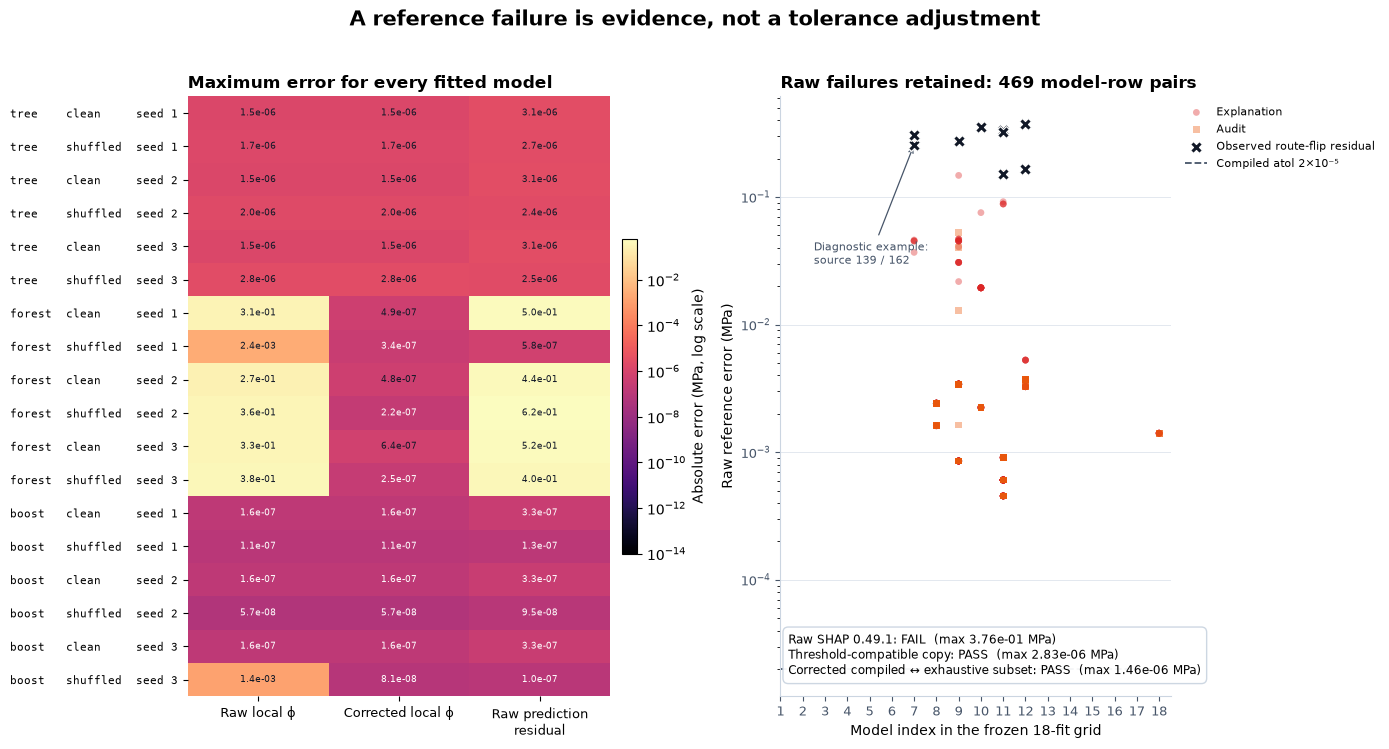

In [74]:
if MAIN:
    refresh_tree_default_methods()
    check_reference = tree_helper_treeshap_reference_check_reference

if MAIN:
    refresh_tree_default_methods()
    tree_reference = check_reference(tree_fitted, tree_prepared, tree_evaluated, tree_explain, tree_audit)
if MAIN:
    refresh_tree_default_methods()
    print("Reference checks:", tree_reference["passes"])
if MAIN:
    refresh_tree_default_methods()
    print("Raw compiled parity passed:", tree_reference["unmodified_interventional_passed"])
if MAIN:
    refresh_tree_default_methods()
    print(
        "Threshold-compatible parity passed:",
        tree_reference["threshold_corrected_interventional_passed"],
    )
if MAIN:
    refresh_tree_default_methods()
    print("Maximum absolute errors by check:")
if MAIN:
    refresh_tree_default_methods()
    for name, error in tree_reference["max_errors"].items():
        print(f"  {name:28s} {error:.3e}")
if MAIN:
    refresh_tree_default_methods()
    tree_show_figure(tree_plots.plot_reference_parity(tree_reference), "17_reference_parity")

<details><summary>Expected output and interpretation</summary>

The raw flag should be `False` and the threshold-compatible flag should be `True`. Across all 18
models, raw local-vector parity fails on 469 model-row pairs; raw base-plus-contribution sums fail
on
18. The maximum raw local-coordinate error is `0.376032` MPa and the maximum raw reconstruction
error is `0.616826` MPa. Do not erase these results or increase the tolerance.

After the global threshold correction, the maximum local-coordinate error is `2.825e-6` MPa and the
maximum reconstruction error is `3.142e-6` MPa, within the frozen tolerance. On all 816 rows of the
three exact model-family checks, the compiled reference for the rounded-threshold game agrees with
exhaustive enumeration to `1.456e-6`. Separately, the student recurrence against the original
float64 exhaustive audit games reaches about `2.49e-14`. Together these results diagnose numerical
routing semantics rather than hiding the failed control.

</details>

<details><summary>Numerical boundary - inspect the counterexample</summary>

In NumPy 1.26, comparing a float32 array with a `np.float64` scalar can narrow the scalar to float32
for the ufunc. That is why the student router first rounds inputs through float32 and then widens
them back to float64. The first cast matches sklearn's input domain; the second preserves the
original float64 threshold during comparison.

The independent reference check records every adjusted threshold plus its adjacent float32 values
and verifies the partition equivalence above. See `reference_boundary_addendum.md` beside this
notebook for the full post-freeze account.

</details>

### Signature result — one prediction, then the whole held-out block

A waterfall answers a local accounting question: relative to the chosen base, which coordinates move
this recipe's prediction up or down? The heatmaps then show all explanation rows, sorted by the
primary forest's prediction and using a shared diverging scale. Look for structure that repeats
across rows, and for features whose sign or magnitude changes between games.

The path and interventional columns need not agree. Their disagreement is evidence that the
missing-feature definition matters, not evidence that one implementation is approximate.

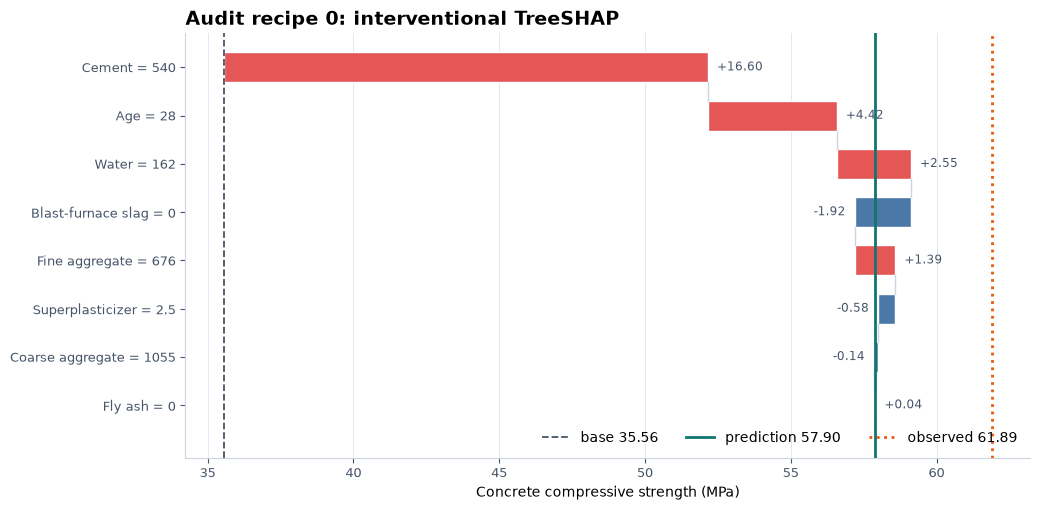

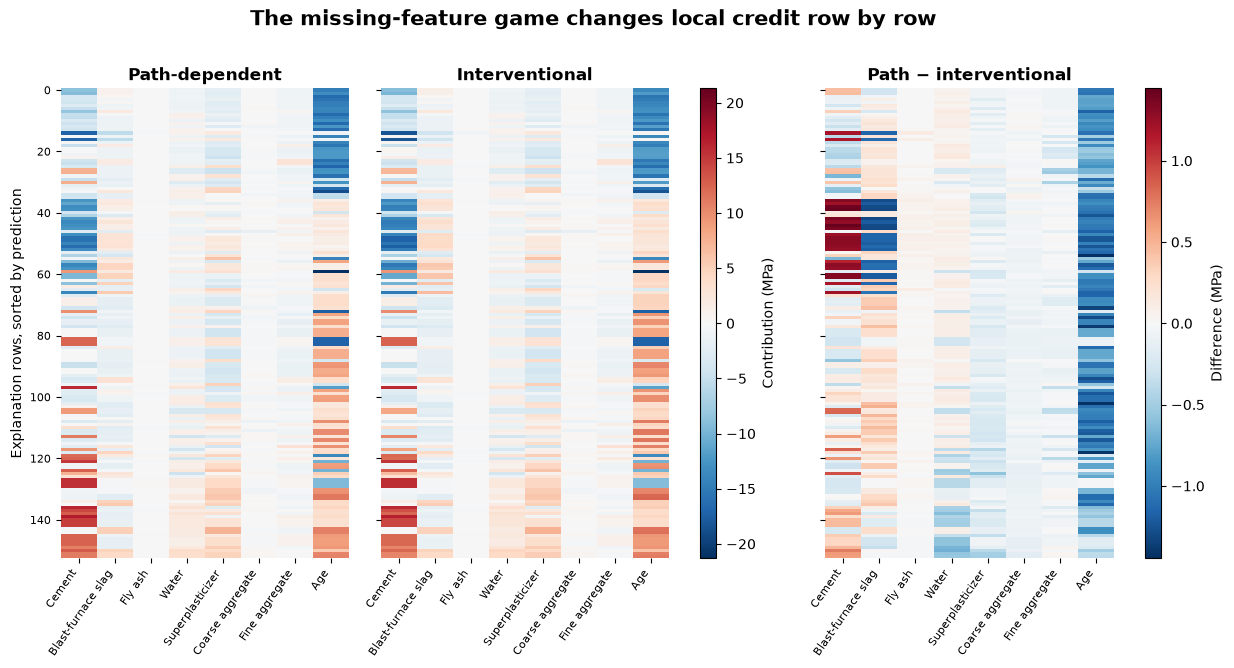

In [75]:
if MAIN:
    refresh_tree_default_methods()
    default_play = tree_native_play(
        tree_fitted, tree_train, tree_audit,
        model_key="forest_clean_0", row=0, size=64, game="interventional",
    )
if MAIN:
    refresh_tree_default_methods()
    tree_show_figure(
        tree_plots.plot_waterfall(
            default_play,
            tree_FEATURE_NAMES,
            title="Audit recipe 0: interventional TreeSHAP",
        ),
        "08_prediction_waterfall",
    )
if MAIN:
    refresh_tree_default_methods()
    tree_show_figure(
        tree_plots.plot_attribution_heatmaps(
            tree_prepared["explanation"]["forest_clean_0"],
            tree_FEATURE_NAMES,
            row_labels=tree_prepared["explain_ids"],
        ),
        "09_attribution_heatmaps",
    )

For the frozen default, source row 1 has observed strength **61.89 MPa** and predicted strength
**57.90 MPa**. The interventional base is **35.56 MPa**. Cement contributes **+16.60 MPa** and age
**+4.42 MPa**; slag contributes **−1.92 MPa**, with the other five coordinates completing the
waterfall. The path-dependent base is **36.52 MPa**. The prediction stays fixed while the reference
and allocation change.

### Controls across fits, backgrounds and deletion orderings

The model-variation panel retains all three seeds and all shuffled fits. The background panel
changes only the empirical donor set for the primary forest: a nested 16/64/128 sequence and two
independent 64-row sets. A stable full prediction can coexist with moving bases and attributions
because the reference game changed.

For deletion, the explanation split supplies one feature ordering for path SHAP, interventional SHAP
and Saabas. On audit rows, features are then removed according to those fixed orders and predictions
are read from the exact interventional coalition game. The comparison includes every one of 100
random orderings.

Deletion is a diagnostic of this fitted model under synthetic missingness. It is not retraining on
smaller recipes, and it is not an instruction to physically remove an ingredient.

In the frozen result, alternate-background bases for the primary forest range from **34.01** to
**37.84 MPa**, compared with **35.56 MPa** for the primary 64-row background. Path SHAP,
interventional SHAP and Saabas happen to produce the same mean-absolute ranking for the clean forest
and boost, so their deletion curves overlap. The clean tree differs only at the three-feature
prefix. This negative result is informative: these curves do not establish that a Shapley ordering
is more useful than the cheaper Saabas ordering on this model and dataset.

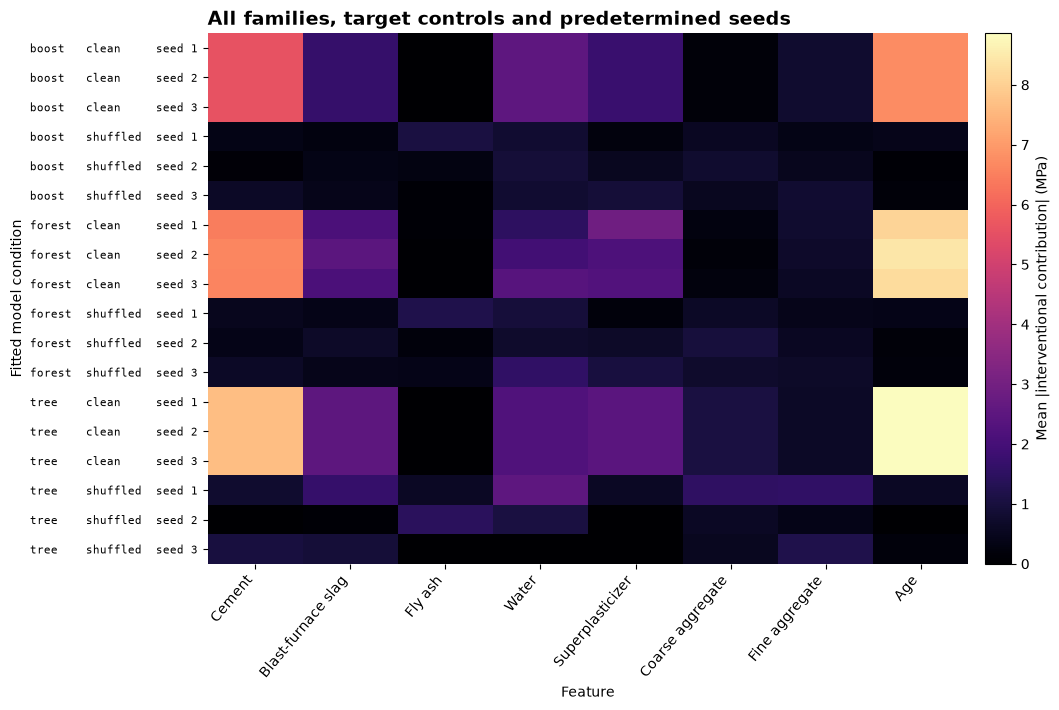

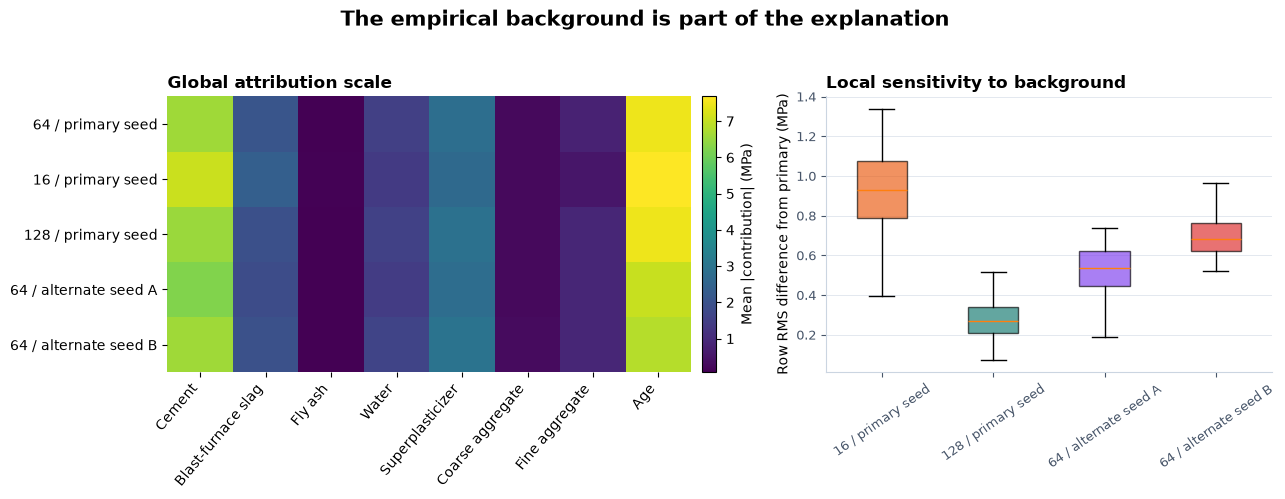

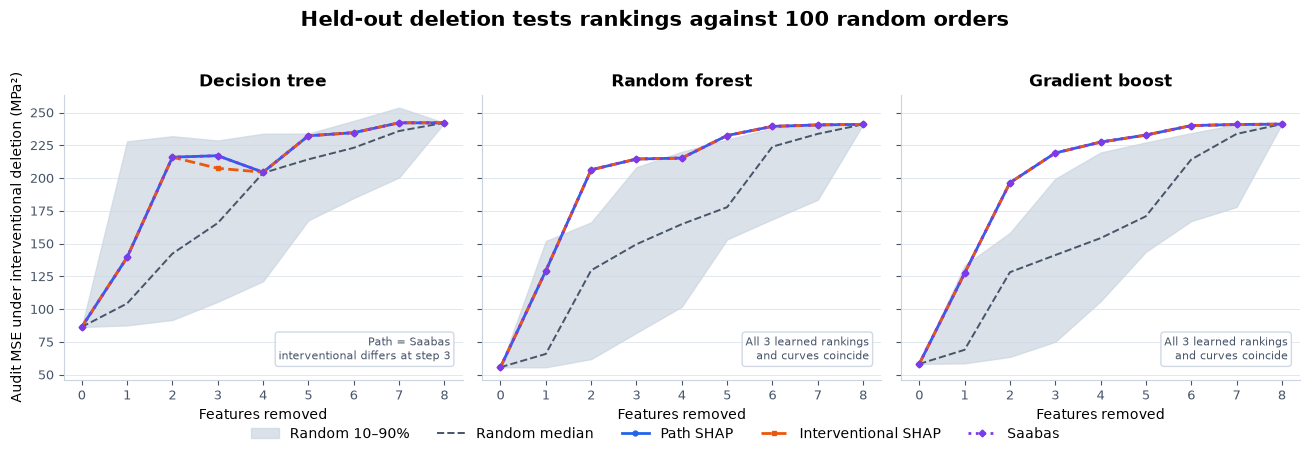

In [76]:
if MAIN:
    refresh_tree_default_methods()
    tree_show_figure(
        tree_plots.plot_model_variation(tree_prepared["explanation"], tree_FEATURE_NAMES),
        "10_model_seed_variation",
    )
if MAIN:
    refresh_tree_default_methods()
    tree_show_figure(
        tree_plots.plot_background_sensitivity(tree_prepared, tree_evaluated, tree_FEATURE_NAMES),
        "11_background_sensitivity",
    )
if MAIN:
    refresh_tree_default_methods()
    tree_show_figure(
        tree_plots.plot_deletion_curves(tree_evaluated),
        "12_deletion_curves",
    )

### Runtime: the exponential axis and the path-depth axis

The first timing control holds a depth-three tree fixed while supplying 3, 6, 9, 12 and 15 features.
Extra features are explicit dummies. Exhaustive enumeration still visits their coalitions unless it
removes dummies first; the path recurrence follows the same shallow tree. The second timing control
increases tree depth from two through eight with one feature per level.

Wall-clock curves describe this machine and implementation. In the frozen depth-2…8 sweep, this
readable Python dynamic program is slower than the vectorized exhaustive oracle at every point; at
depth eight it takes roughly 100 ms for eight queries, versus roughly 2 ms for enumeration. The
polynomial algorithm has larger Python constant factors at these small dimensions. On the fixed
depth-three dummy sweep, it wins only once enumeration is forced to pay for 12 and 15 supplied
features. The diagnostic stores all three timings and plots their medians. Algorithmic scaling does
not promise that this teaching implementation is faster on every small tree.

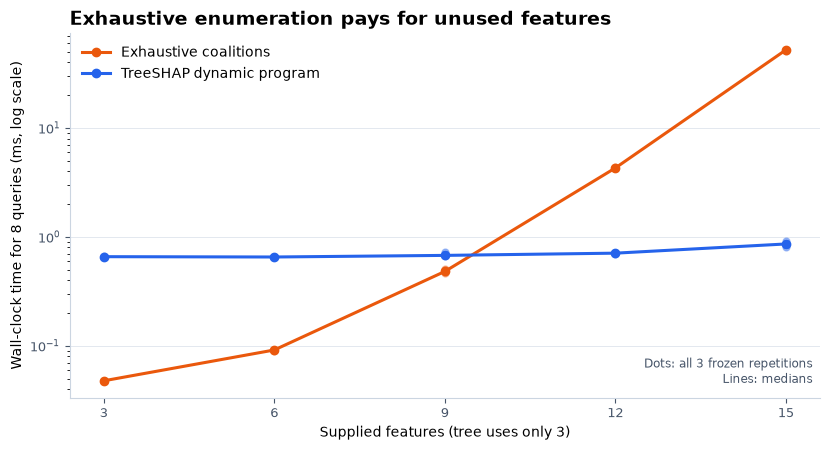

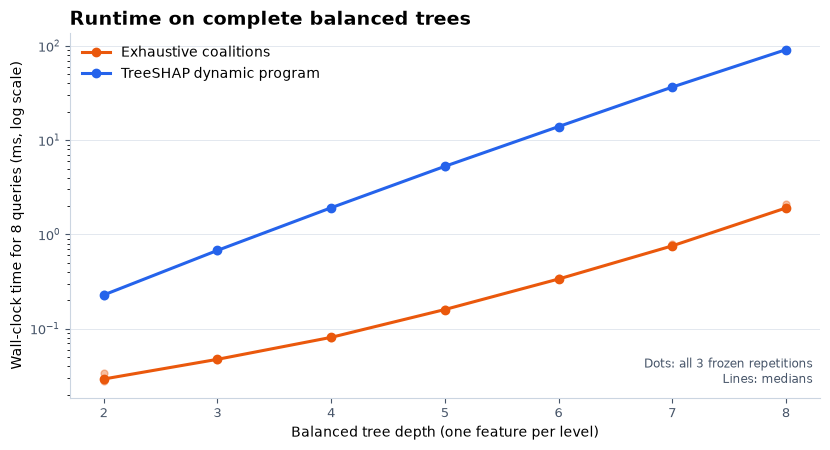

In [77]:
if MAIN:
    refresh_tree_default_methods()
    tree_show_figure(
        tree_plots.plot_runtime_dummy_features(tree_diagnostics["timing"]),
        "13_runtime_dummy_features",
    )
if MAIN:
    refresh_tree_default_methods()
    tree_show_figure(
        tree_plots.plot_runtime_depth(tree_diagnostics["timing"]),
        "14_runtime_depth",
    )

### Try It Yourself 2 — explain another recipe and another game

Change any four settings. `row` selects a held-out recipe; `model_key` can use `tree`, `forest`, or
`boost`, `clean` or `shuffled`, and seed index 0–2; `game` chooses the missing-feature definition;
`size` changes the empirical background when the interventional game is selected.

Before running, predict what should remain invariant. The full model prediction is fixed for a
chosen model and row. The base and individual contributions can move with the game or background.
This cell deliberately reuses audit rows after evaluation and is exploratory only. Choices made here
after seeing audit results cannot support a new confirmatory audit claim.

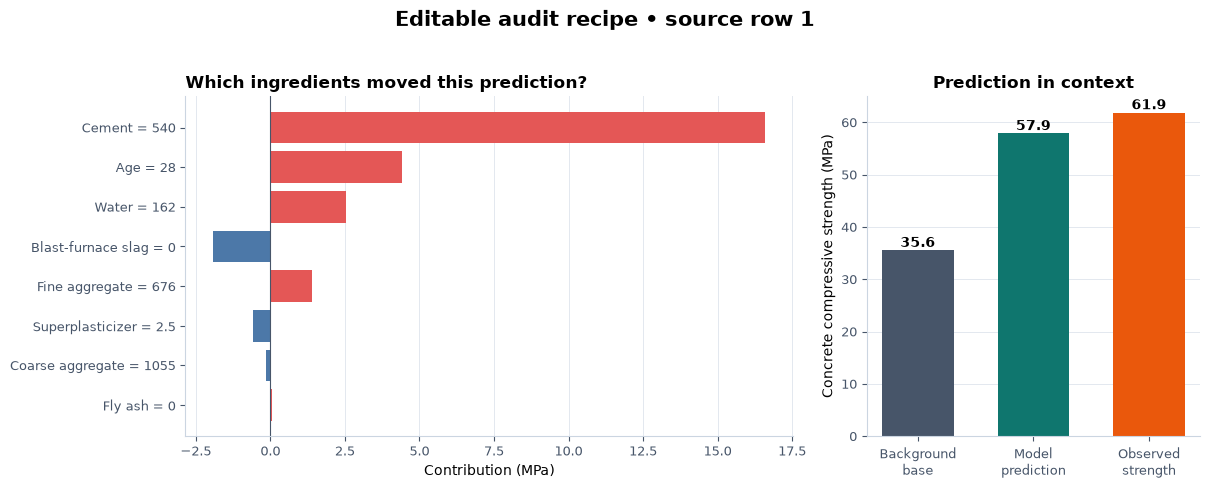

In [78]:
row = 0
model_key = "forest_clean_0"
game = "interventional"  # choose "interventional" or "path"
size = 64                 # used only by the interventional game

if MAIN:
    refresh_tree_default_methods()
    tree_real_play = tree_native_play(
        tree_fitted, tree_train, tree_audit,
        model_key=model_key, row=row, size=size, game=game,
    )
if MAIN:
    refresh_tree_default_methods()
    tree_show_figure(tree_plots.plot_real_recipe_play(tree_real_play, tree_FEATURE_NAMES), "16_real_recipe_play")

## Interpreting the study

Use the figures in this order.

1. **Predictive control:** compare clean fits with the training-mean baseline and shuffled-target
fits on held-out recipe groups.
2. **Numerical validity:** require exhaustive full-vector parity. Then inspect the raw library
failure and the separately labeled threshold-compatible parity; do not collapse them into one pass
flag.
3. **Local explanation:** read the waterfall as a decomposition relative to its displayed base.
4. **Across rows:** inspect the heatmap for recurring direction and heterogeneity rather than
reducing every feature to one mean bar.
5. **Definition sensitivity:** compare path and interventional games, then alternate backgrounds.
6. **Usefulness control:** compare fixed-order deletion curves with all random orders and the
efficient non-Shapley Saabas baseline.

A large positive contribution for cement, for example, means that this fitted model predicts more
strength for this recipe relative to the specified missing-feature reference. It does not identify
the effect of adding cement while holding a physically feasible recipe constant. Ingredient
quantities co-vary, duplicated recipes have conflicting outcomes, and laboratory identity is
unavailable.

## Limitations

- **The game is a modeling choice.** Path-dependent absence follows fitted tree structure and cover.
Empirical intervention follows a finite donor background. Neither is automatically the population
conditional game.
- **Hybrids may be off-support.** Copying present coordinates from one recipe and missing
coordinates from another can produce unrealistic mixtures.
- **The split unit is a recipe group, not a laboratory.** Identical seven-ingredient recipes remain
together, but unobserved laboratory or batch dependence can cross splits.
- **Prediction is not causation.** The study explains fixed regressors. It neither estimates
ingredient interventions nor retrains models after feature removal.
- **Background stability is finite.** The alternate-background panel probes several frozen samples;
it does not integrate over all reasonable reference populations.
- **Reference agreement has a scope.** Library parity supports this scalar-output scikit-learn path
under the installed SHAP version. It does not validate every tree package, missing-value convention,
classifier link, or output transform.
- **Timing is descriptive.** Python overhead, tree shape, batching and hardware affect the measured
curves.

## Further research and anomaly hunting

Good extensions change one scientific assumption at a time:

- find rows whose largest feature changes sign between path and interventional games, then inspect
their nearest background recipes;
- repeat the background control with a scientifically motivated reference population and state what
changed in the estimand;
- locate deletion curves where Saabas beats both Shapley rankings and determine whether the gain
comes from the tree's fixed split order;
- construct two larger functionally equivalent trees with different structures and quantify
path-game disagreement;
- profile a compiled or vectorized recurrence and ask where it crosses the exhaustive oracle on a
separately declared, bounded tree sweep rather than extending the frozen range after seeing it;
- extend the recurrence to explicit missing-value routes or categorical splits, adding exhaustive
fixtures before fitted-model use.

Do not treat an unexpected attribution as an error until you have identified the game, prediction,
base, row, model and reference population that generated it.

## Reading

- Scott Lundberg, Gabriel Erion & Su-In Lee, [*Consistent Individualized Feature Attribution for
Tree Ensembles*](https://arxiv.org/abs/1802.03888), especially Section 3 and Algorithms 1–2.
- [SHAP `TreeExplainer`
documentation](https://shap.readthedocs.io/en/latest/generated/shap.TreeExplainer.html), for the
current library's explicit perturbation modes and output choices.
- I-Cheng Yeh, [UCI Concrete Compressive
Strength](https://archive.ics.uci.edu/dataset/165/concrete+compressive+strength), for the source
data and measurement description.

In [79]:
# Persist the complete visible run. All scientific computations occurred above.
if MAIN:
    refresh_tree_default_methods()
    tree_summary = tree_persist_completed(
        NATIVE_DIR, tree_fitted, tree_prepared, tree_evaluated, tree_diagnostics, tree_reference, default_play
    )
if MAIN:
    refresh_tree_default_methods()
    tree_write_notebook_summary(OUTPUT_ROOT, NATIVE_DIR, tree_summary)
if MAIN:
    refresh_tree_default_methods()
    print("Saved notebook-native payloads to", NATIVE_DIR)

Saved notebook-native payloads to /home/bitwise/Documents/ARENA_3.0_Extended/.claude/worktrees/competent-kilby-be277c/chapter16_shapley_attribution_baselines/exercises/part3_model_specific_shap/artifacts/tree/native


# 2️⃣ DeepSHAP

> ##### Learning Objectives
>
> - Implement finite-change Rescale propagation and intact-donor averaging.
> - Separate completeness from exact feature credit and independent-library parity.
> - Diagnose epsilon limits, cancellation, affine, donor-mean and replacement controls.

## DeepSHAP: When Does Fast Attribution Match Exact SHAP?

> **Claim.** A DeepSHAP explanation can reconstruct a prediction exactly while assigning different
feature credit from exact Shapley values for the same empirical background game.

## Core Question

How does DeepSHAP replace ordinary derivatives with finite-change multipliers, and which controls
tell us whether its fast compositional explanation matches the exact feature game?

Consider

$$
f(x_0,x_1)=\operatorname{ReLU}(2x_0+x_1-2),\qquad x=(1,1),\quad b=(0,0).
$$

Neither feature can cross the threshold alone. The four intervention values are `(0, 0, 0, 1)`, so
exact Shapley splits the one-unit change evenly: `(0.5, 0.5)`. DeepSHAP's Rescale rule follows the
active full computation and divides the same change in proportion to the incoming linear
differences: `(2/3, 1/3)`. Both vectors sum to one. Completeness alone cannot decide which credit
allocation answers the feature-level game.

In this lab you will derive that result, implement the complete modified backward pass, and compare
it with all 256 coalitions on held-out concrete-strength predictions. The full lab runs on CPU in
float64. Allow **4–6 hours**; Exercises 2–5 contain the core DeepSHAP mechanism.

## Learning goals

By the end of the lab, you should be able to:

- distinguish an ordinary derivative from a finite-change multiplier;
- derive ReLU's Rescale secant and the modified chain rule;
- explain why background averaging means averaging attributions, not replacing many references by
their mean input;
- separate completeness, independent-library parity, and exact feature-Shapley agreement;
- enumerate the empirical donor-replacement game and contract it into exact Shapley values;
- use threshold, cancellation, affine, dummy, constant, epsilon, shuffled-target and random-order
controls;
- interpret observational feature replacement without calling it a physical intervention.

## Setup

The taught method supports an exact `nn.Sequential` chain containing distinct, non-inplace
`nn.Linear` and `nn.ReLU` modules and a scalar final output. This narrow contract keeps every
modified backward rule visible. Real DeepSHAP libraries support more operators through
backend-specific handlers; an unsupported module here raises an error rather than silently using an
ordinary gradient.

In [80]:
if MAIN:
    import itertools
if MAIN:
    import math
if MAIN:
    import os
if MAIN:
    import sys
if MAIN:
    from pathlib import Path
if MAIN:
    from types import SimpleNamespace

if MAIN:
    import matplotlib.pyplot as plt
if MAIN:
    import numpy as np
if MAIN:
    import torch
if MAIN:
    import torch as t
if MAIN:
    from IPython.display import display
if MAIN:
    from torch import Tensor, nn

if MAIN:
    torch.set_default_dtype(torch.float64)

deep_chapter = "chapter16_shapley_attribution_baselines"
deep_section = "part14_deepshap"
if MAIN:
    deep_root_dir = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path / deep_chapter).exists())
if MAIN:
    deep_exercises_dir = deep_root_dir / deep_chapter / "exercises"
if MAIN:
    deep_section_dir = deep_exercises_dir / deep_section
if MAIN:
    if str(deep_root_dir) not in sys.path:
        sys.path.append(str(deep_root_dir))
    if str(deep_exercises_dir) not in sys.path:
        sys.path.append(str(deep_exercises_dir))

if MAIN:
    from chapter16_shapley_attribution_baselines.exercises.part3_model_specific_shap import deep_deepshap_methods_tests as deep_tests
if MAIN:
    from chapter16_shapley_attribution_baselines.exercises.part3_model_specific_shap import deep_deepshap_plots as deep_plots
if MAIN:
    from chapter16_shapley_attribution_baselines.exercises.part3_model_specific_shap.deep_deepshap_data import load_split as deep_load_split

if MAIN:
    deep_FEATURE_NAMES = np.array([
        "Cement", "Slag", "Fly ash", "Water", "Superplasticizer",
        "Coarse aggregate", "Fine aggregate", "Age",
    ])
if MAIN:
    deep_RUN_OUTPUT = os.environ.get("ARENA_DEEPSHAP_OUTPUT_DIRECTORY")
if MAIN:
    deep_FIGURE_DIR = Path(
        os.environ.get("ARENA_DEEPSHAP_FIGURE_DIR", deep_RUN_OUTPUT or canonical_dir / "media" / 'deep')
    )
if MAIN:
    deep_SAVE_FIGURES = os.environ.get(
        "ARENA_DEEPSHAP_SAVE_FIGURES", "1" if deep_RUN_OUTPUT else "0"
    ) == "1"


def deep_show_figure(fig, stem):
    """Display a figure and optionally save the exact notebook rendering."""
    display(fig)
    if deep_SAVE_FIGURES:
        deep_FIGURE_DIR.mkdir(parents=True, exist_ok=True)
        fig.savefig(deep_FIGURE_DIR / f"{stem}.png", dpi=180, bbox_inches="tight")
    plt.close(fig)

The validators below are provided plumbing. Exact module types matter because a subclass can change
its forward computation, and repeated module objects would make saved states ambiguous. The nine
attribution functions remain in the exercises, where you can read and edit them.

### Visible supporting scientific function: `_check_widths`

In [81]:
if MAIN:
    from torch import Tensor, nn

def deep_helper_deepshap_methods__check_widths(layers: list[nn.Module], n_features: int) -> None:
    width = n_features
    for index, layer in enumerate(layers):
        if type(layer) is nn.Linear:
            if layer.in_features != width:
                raise ValueError(
                    f"Layer {index} expects {layer.in_features} values, but the previous "
                    f"state has width {width}."
                )
            width = layer.out_features

### Visible supporting scientific function: `_epsilon`

In [82]:
if MAIN:
    import math

def deep_helper_deepshap_methods__epsilon(value: float) -> float:
    if not isinstance(value, (int, float)) or isinstance(value, bool):
        raise TypeError("epsilon must be a finite nonnegative number.")
    value = float(value)
    if not math.isfinite(value) or value < 0:
        raise ValueError("epsilon must be a finite nonnegative number.")
    return value

### Visible supporting scientific function: `_layers`

In [83]:
if MAIN:
    from torch import Tensor, nn
if MAIN:
    import torch as t

def deep_helper_deepshap_methods__layers(model: nn.Sequential) -> list[nn.Module]:
    """Validate the deliberately narrow graph supported by the taught rules."""
    if type(model) is not nn.Sequential:
        raise TypeError("model must be an exact nn.Sequential instance.")
    layers = list(model)
    if not layers:
        raise ValueError("model cannot be empty.")
    if len({id(layer) for layer in layers}) != len(layers):
        raise ValueError("Every layer must be a distinct module; shared modules are unsupported.")
    for layer in layers:
        if type(layer) not in (nn.Linear, nn.ReLU):
            raise TypeError(
                f"Unsupported module {type(layer).__name__}; "
                "use exact nn.Linear and nn.ReLU modules."
            )
        if type(layer) is nn.ReLU and layer.inplace:
            raise ValueError(
                "In-place ReLU is unsupported because paired states must be preserved."
            )
        for parameter in layer.parameters(recurse=False):
            if parameter.device.type != "cpu" or parameter.dtype != t.float64:
                raise TypeError("Every model parameter must be a CPU float64 tensor.")
            if not t.isfinite(parameter).all():
                raise ValueError("Every model parameter must be finite.")
    if type(layers[-1]) is not nn.Linear or layers[-1].out_features != 1:
        raise ValueError("model must end with an exact scalar-output nn.Linear layer.")
    return layers

### Visible supporting scientific function: `_method_tensor`

In [84]:
if MAIN:
    from torch import Tensor, nn
if MAIN:
    import torch as t

def deep_helper_deepshap_methods__method_tensor(name: str, value: Tensor, ndim: int | None = None) -> Tensor:
    """Check the lesson's CPU-float64 tensor contract without changing the value."""
    if type(value) is not Tensor:
        raise TypeError(f"{name} must be a torch.Tensor.")
    if value.device.type != "cpu" or value.dtype != t.float64:
        raise TypeError(f"{name} must be a CPU float64 tensor.")
    if ndim is not None and value.ndim != ndim:
        raise ValueError(f"{name} must have {ndim} dimensions.")
    if value.numel() == 0:
        raise ValueError(f"{name} cannot be empty.")
    if not t.isfinite(value).all():
        raise ValueError(f"{name} must contain only finite values.")
    return value

### Visible supporting scientific function: `_model_output`

In [85]:
if MAIN:
    from torch import Tensor, nn
if MAIN:
    import torch as t

def deep_helper_deepshap_methods__model_output(model: nn.Sequential, x: Tensor) -> Tensor:
    output = model(x)
    if output.shape != (len(x), 1):
        raise ValueError("The model must return one scalar output per input row.")
    if not t.isfinite(output).all():
        raise ValueError("The model returned a nonfinite value.")
    return output[:, 0]

In [86]:
if MAIN:
    _check_widths = deep_helper_deepshap_methods__check_widths
if MAIN:
    _epsilon = deep_helper_deepshap_methods__epsilon
if MAIN:
    _layers = deep_helper_deepshap_methods__layers
if MAIN:
    _method_tensor = deep_helper_deepshap_methods__method_tensor
if MAIN:
    _model_output = deep_helper_deepshap_methods__model_output

The following diagnostic helpers build literal float64 layers and resolve only methods you have
already written. They contain no attribution implementation.

### Visible supporting scientific function: `DTYPE`

In [87]:
if MAIN:
    import torch

if MAIN:
    deep_helper_deepshap_diagnostics_DTYPE = torch.float64

### Visible supporting scientific function: `_linear`

In [88]:
if MAIN:
    from torch import Tensor, nn
if MAIN:
    import torch

def deep_helper_deepshap_diagnostics__linear(weight, bias):
    """Construct one deterministic float64 Linear layer from literal arrays."""
    weight = torch.as_tensor(weight, dtype=deep_helper_deepshap_diagnostics_DTYPE)
    bias = torch.as_tensor(bias, dtype=deep_helper_deepshap_diagnostics_DTYPE).reshape(-1)
    layer = nn.Linear(weight.shape[1], weight.shape[0], dtype=deep_helper_deepshap_diagnostics_DTYPE)
    with torch.no_grad():
        layer.weight.copy_(weight)
        layer.bias.copy_(bias)
    return layer

### Visible supporting scientific function: `_max_abs`

In [89]:
if MAIN:
    import torch

def deep_helper_deepshap_diagnostics__max_abs(left, right):
    difference = torch.as_tensor(left).detach() - torch.as_tensor(right).detach()
    return float(difference.abs().max())

### Visible supporting scientific function: `_method`

In [90]:
def deep_helper_deepshap_diagnostics__method(methods, name):
    """Resolve a taught function from a module, namespace, or mapping."""
    if methods is None:
        local = globals().get(name)
        if callable(local):
            return local
        deepshap_methods = SimpleNamespace(**deep_module_deepshap_methods_namespace())

        return getattr(deepshap_methods, name)
    if hasattr(methods, name):
        return getattr(methods, name)
    return methods[name]

### Visible supporting scientific function: `_prediction`

In [91]:
if MAIN:
    import torch

def deep_helper_deepshap_diagnostics__prediction(model, rows):
    with torch.no_grad():
        return model(rows).reshape(-1)

In [92]:
if MAIN:
    deep_DTYPE = deep_helper_deepshap_diagnostics_DTYPE
if MAIN:
    deep__linear = deep_helper_deepshap_diagnostics__linear
if MAIN:
    deep__max_abs = deep_helper_deepshap_diagnostics__max_abs
if MAIN:
    deep__method = deep_helper_deepshap_diagnostics__method
if MAIN:
    deep__prediction = deep_helper_deepshap_diagnostics__prediction

## 1️⃣ Save paired forward states

DeepSHAP compares a real input `x` with a reference `b`. The backward rule for a ReLU needs both
preactivation values, so our forward pass stores the input and the output of every layer for both
batches. If the model has $L$ layers, each returned list has $L+1$ entries.

### Exercise 1 — `paired_forward`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵⚪⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Return `(x_states, b_states)`. Do not combine the batches or pair their rows: `x` has shape `(N,D)`
and `background` has shape `(B,D)`.

In [93]:
def paired_forward(
    model: nn.Sequential, x: Tensor, background: Tensor
) -> tuple[list[Tensor], list[Tensor]]:
    """Save the input and every layer output for queries and references."""
    layers = _layers(model)
    _method_tensor("x", x, 2)
    _method_tensor("background", background, 2)
    if x.shape[1] != background.shape[1]:
        raise ValueError("x and background must have the same feature dimension.")
    _check_widths(layers, x.shape[1])

    with t.no_grad():
        x_value, b_value = x.clone(), background.clone()
        x_states, b_states = [x_value], [b_value]
        for layer in layers:
            x_value, b_value = layer(x_value), layer(b_value)
            x_states.append(x_value)
            b_states.append(b_value)
        if x_states[-1].shape != (len(x), 1) or b_states[-1].shape != (len(background), 1):
            raise ValueError("The model must return one scalar output per input row.")
        if not t.isfinite(x_states[-1]).all() or not t.isfinite(b_states[-1]).all():
            raise ValueError("The model returned a nonfinite value.")
    return x_states, b_states


if MAIN:
    deep_tests.test_paired_forward(paired_forward)

All tests in test_paired_forward passed!


## 2️⃣ Replace a ReLU derivative with a secant

For a unary activation $g$, Rescale assigns the finite-change multiplier

$$
s(z_x,z_b)=\frac{g(z_x)-g(z_b)}{z_x-z_b}.
$$

For ReLU, this slope is 0 if both values are non-positive, 1 if both are positive, and lies between
0 and 1 when the pair crosses zero. If $|z_x-z_b|<\epsilon$, the quotient is numerically unstable,
so our explicit convention uses the derivative at the reference: $\mathbb{1}[z_b>0]$. This matches
the supported library rule. The strict `>` also states the convention at exactly zero.

### Exercise 2 — `rescale_slope`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵🔵
> 
> You should spend up to 15-20 minutes on this exercise.
> ```

Implement broadcast-compatible ReLU secants. Guard the denominator *before* division; computing an
invalid quotient and masking it later can still introduce `nan` values or warnings.

In [94]:
def rescale_slope(zx: Tensor, zb: Tensor, epsilon: float = 1e-6) -> Tensor:
    """ReLU secants, using the reference derivative for small denominators."""
    _method_tensor("zx", zx)
    _method_tensor("zb", zb)
    epsilon = _epsilon(epsilon)
    try:
        zx, zb = t.broadcast_tensors(zx, zb)
    except RuntimeError as error:
        raise ValueError("zx and zb must be broadcast-compatible.") from error

    delta = zx - zb
    use_derivative = delta.eq(0) | delta.abs().lt(epsilon)
    safe_delta = t.where(use_derivative, t.ones_like(delta), delta)
    secant = (t.relu(zx) - t.relu(zb)) / safe_delta
    return t.where(use_derivative, (zb > 0).to(zb.dtype), secant)


if MAIN:
    deep_tests.test_rescale_slope(rescale_slope)

All tests in test_rescale_slope passed!


The first plot checks the secant away from zero and then magnifies the explicit epsilon boundary.
The visible diagnostic source calls the function you just wrote.

In [95]:
def diagnose_rescale_limits(methods):
    """Exercise the secant, exact-zero and named small-delta branches."""
    rescale_slope = deep__method(methods, "rescale_slope")
    reference = torch.tensor([-1.0, 0.5, -4e-7], dtype=deep_DTYPE)
    actual = torch.tensor([1.0, 0.5, 4e-7], dtype=deep_DTYPE)
    primary = rescale_slope(actual, reference, epsilon=1e-6)
    exact_nonzero = rescale_slope(actual, reference, epsilon=0.0)
    expected_primary = torch.tensor([0.5, 1.0, 0.0], dtype=deep_DTYPE)
    expected_exact = torch.tensor([0.5, 1.0, 0.5], dtype=deep_DTYPE)
    grid = torch.linspace(-2.0, 2.0, 161, dtype=deep_DTYPE)
    grid_reference = torch.full_like(grid, -1.0)
    return {
        "reference": reference,
        "actual": actual,
        "epsilon": 1e-6,
        "primary": primary,
        "exact_nonzero": exact_nonzero,
        "expected_primary": expected_primary,
        "expected_exact_nonzero": expected_exact,
        "curve": {
            "actual": grid,
            "reference": grid_reference,
            "slope": rescale_slope(grid, grid_reference, epsilon=1e-6),
        },
        "primary_max_abs_error": deep__max_abs(primary, expected_primary),
        "exact_nonzero_max_abs_error": deep__max_abs(exact_nonzero, expected_exact),
    }

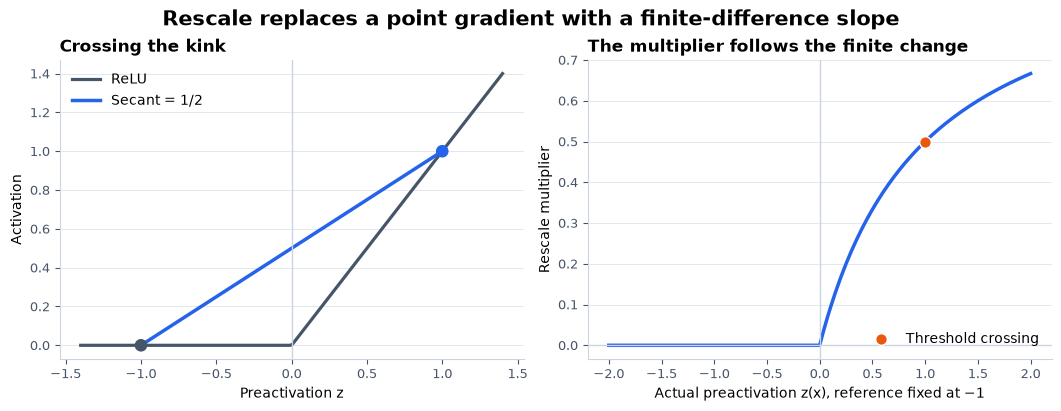

In [96]:
if MAIN:
    rescale_limits = diagnose_rescale_limits(deep_curriculum_namespace())
if MAIN:
    deep_show_figure(deep_plots.plot_rescale_limits(rescale_limits), "01_rescale_limits")

## 3️⃣ Propagate modified multipliers

Ordinary backpropagation composes local derivatives. DeepLIFT instead starts from contributions
$C_{\Delta x_i\Delta t}$ and defines a multiplier

$$
m_{\Delta x_i\Delta t}=\frac{C_{\Delta x_i\Delta t}}{\Delta x_i}.
$$

For an intermediate layer $y_j$, the modified chain rule is

$$
m_{\Delta x_i\Delta t}=\sum_j
m_{\Delta x_i\Delta y_j}\,m_{\Delta y_j\Delta t}.
$$

An affine layer uses its weight matrix. A ReLU uses the secant you just implemented. Starting from a
unit output multiplier and traversing the modules in reverse therefore looks like backpropagation,
but every ReLU factor depends on the pair `(x,b)` rather than one derivative at `x`.

### Exercise 3 — `rescale_multipliers`

> ```yaml
> Difficulty: 🔴🔴🔴🔴⚪
> Importance: 🔵🔵🔵🔵🔵
> 
> You should spend up to 35-50 minutes on this exercise.
> ```

Return one output-to-input multiplier for every input/reference pair, shape `(N,B,D)`.

In [97]:
def initialize_deep_16_rescale_multipliers():
    global rescale_multipliers
    @t.no_grad()
    def rescale_multipliers(
        model: nn.Sequential,
        x: Tensor,
        background: Tensor,
        epsilon: float = 1e-6,
    ) -> Tensor:
        """Propagate scalar-output Rescale multipliers to every input feature."""
        layers = _layers(model)
        epsilon = _epsilon(epsilon)
        x_states, b_states = paired_forward(model, x, background)
        multiplier = t.ones((len(x), len(background), 1), dtype=t.float64)

        for index in range(len(layers) - 1, -1, -1):
            layer = layers[index]
            if type(layer) is nn.Linear:
                multiplier = t.einsum("nro,oi->nri", multiplier, layer.weight)
            else:
                slope = rescale_slope(
                    x_states[index][:, None, :],
                    b_states[index][None, :, :],
                    epsilon,
                )
                multiplier = multiplier * slope
        return multiplier


if MAIN:
    initialize_deep_16_rescale_multipliers()


if MAIN:
    deep_tests.test_rescale_multipliers(rescale_multipliers)

All tests in test_rescale_multipliers passed!


## 4️⃣ Turn multipliers into single-reference contributions

For one reference $b$, Rescale contributions are

$$
\phi_i^{(b)}(x)=m_{\Delta x_i\Delta f}(x,b)(x_i-b_i).
$$

On a supported affine/ReLU chain with an exact secant at every changed ReLU, the modified chain rule
gives the summation-to-delta property

$$
\sum_i\phi_i^{(b)}(x)=f(x)-f(b).
$$

That identity is **local completeness**. The threshold example already proves that it does not imply
exact Shapley allocation over the original input features.

### Exercise 4 — `single_reference`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 15-20 minutes on this exercise.
> ```

Accept a one-dimensional reference and return `(N,D)` contributions.

In [98]:
def initialize_deep_19_single_reference():
    global single_reference
    @t.no_grad()
    def single_reference(
        model: nn.Sequential,
        x: Tensor,
        reference: Tensor,
        epsilon: float = 1e-6,
    ) -> Tensor:
        """Explain each query relative to one complete reference vector."""
        _method_tensor("x", x, 2)
        _method_tensor("reference", reference, 1)
        if x.shape[1] != reference.shape[0]:
            raise ValueError("reference must contain one value for every input feature.")
        multiplier = rescale_multipliers(model, x, reference[None, :], epsilon)[:, 0]
        return multiplier * (x - reference)


if MAIN:
    initialize_deep_19_single_reference()


if MAIN:
    deep_tests.test_single_reference(single_reference)

All tests in test_single_reference passed!


In [99]:
def near_zero_fixture():
    """Return the named ReLU crossing inside the 1e-6 fallback branch."""
    model = nn.Sequential(
        deep__linear([[1.0]], [0.0]),
        nn.ReLU(),
        deep__linear([[1.0]], [0.0]),
    ).eval()
    return {
        "model": model,
        "query": torch.tensor([[4e-7]], dtype=deep_DTYPE),
        "reference": torch.tensor([-4e-7], dtype=deep_DTYPE),
        "epsilon": 1e-6,
        "expected_primary_phi": torch.tensor([[0.0]], dtype=deep_DTYPE),
        "expected_exact_secant_phi": torch.tensor([[4e-7]], dtype=deep_DTYPE),
    }

In [100]:
def diagnose_near_zero(methods):
    """Expose the expected local-accuracy loss from the named epsilon branch."""
    single_reference = deep__method(methods, "single_reference")
    fixture = near_zero_fixture()
    model, query, reference = (
        fixture["model"],
        fixture["query"],
        fixture["reference"],
    )
    primary = single_reference(model, query, reference, epsilon=fixture["epsilon"])
    exact_secant = single_reference(model, query, reference, epsilon=0.0)
    prediction = deep__prediction(model, query)[0]
    base = deep__prediction(model, reference[None])[0]
    delta = prediction - base
    primary_residual = delta - primary.sum()
    exact_residual = delta - exact_secant.sum()
    return {
        "query": query,
        "reference": reference,
        "epsilon": fixture["epsilon"],
        "prediction": prediction,
        "base": base,
        "prediction_delta": delta,
        "primary_phi": primary,
        "exact_secant_phi": exact_secant,
        "expected_primary_phi": fixture["expected_primary_phi"],
        "expected_exact_secant_phi": fixture["expected_exact_secant_phi"],
        "primary_completeness_residual": primary_residual,
        "exact_secant_completeness_residual": exact_residual,
        "expected_primary_residual": torch.tensor(4e-7, dtype=deep_DTYPE),
        "primary_phi_max_abs_error": deep__max_abs(primary, fixture["expected_primary_phi"]),
        "exact_secant_phi_max_abs_error": deep__max_abs(
            exact_secant, fixture["expected_exact_secant_phi"]
        ),
    }

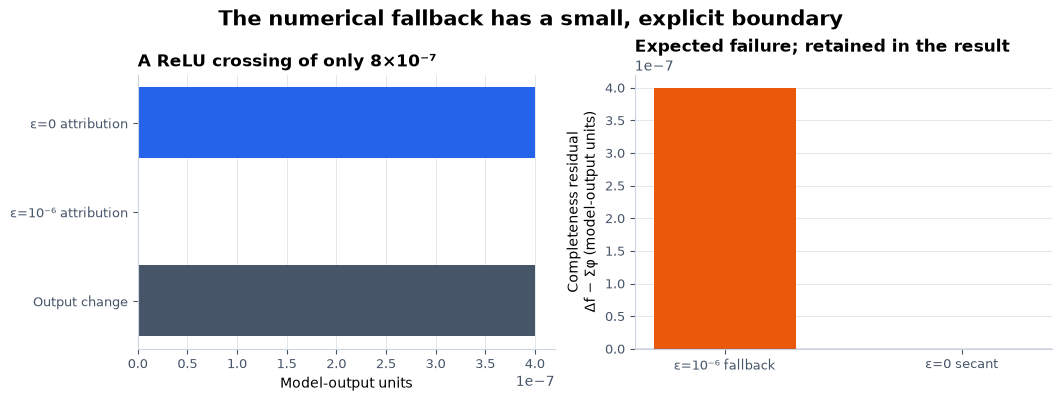

In [101]:
if MAIN:
    near_zero = diagnose_near_zero(deep_curriculum_namespace())
if MAIN:
    deep_show_figure(deep_plots.plot_near_zero(near_zero), "02_near_zero_epsilon")

The near-zero panel is intentionally a failed case at the primary epsilon. Its residual is shown at
its true scale, beside the exact nonzero-secant result at `epsilon=0`.

In [102]:
def affine_fixture():
    """Return affine, dummy-input and constant controls with exact answers."""
    query = torch.tensor([[4.0, 2.0]], dtype=deep_DTYPE)
    reference = torch.tensor([1.0, -1.0], dtype=deep_DTYPE)
    affine = nn.Sequential(deep__linear([[2.0, -3.0]], [5.0])).eval()

    dummy_query = torch.tensor([[4.0, 2.0, 9.0]], dtype=deep_DTYPE)
    dummy_reference = torch.tensor([1.0, -1.0, -4.0], dtype=deep_DTYPE)
    dummy = nn.Sequential(deep__linear([[2.0, -3.0, 0.0]], [5.0])).eval()
    constant = nn.Sequential(deep__linear([[0.0, 0.0]], [7.0])).eval()
    return {
        "affine": {
            "model": affine,
            "query": query,
            "reference": reference,
            "expected_phi": torch.tensor([[6.0, -9.0]], dtype=deep_DTYPE),
            "expected_base": torch.tensor(10.0, dtype=deep_DTYPE),
            "expected_prediction": torch.tensor(7.0, dtype=deep_DTYPE),
        },
        "dummy": {
            "model": dummy,
            "query": dummy_query,
            "reference": dummy_reference,
            "expected_phi": torch.tensor([[6.0, -9.0, 0.0]], dtype=deep_DTYPE),
            "expected_base": torch.tensor(10.0, dtype=deep_DTYPE),
            "expected_prediction": torch.tensor(7.0, dtype=deep_DTYPE),
        },
        "constant": {
            "model": constant,
            "query": query,
            "reference": reference,
            "expected_phi": torch.zeros((1, 2), dtype=deep_DTYPE),
            "expected_base": torch.tensor(7.0, dtype=deep_DTYPE),
            "expected_prediction": torch.tensor(7.0, dtype=deep_DTYPE),
        },
    }

In [103]:
def diagnose_affine_controls(methods):
    """Check exact affine credit, an unused input, and a constant network."""
    single_reference = deep__method(methods, "single_reference")
    answer = {}
    for name, fixture in affine_fixture().items():
        phi = single_reference(fixture["model"], fixture["query"], fixture["reference"])
        prediction = deep__prediction(fixture["model"], fixture["query"])[0]
        base = deep__prediction(fixture["model"], fixture["reference"][None])[0]
        answer[name] = {
            "query": fixture["query"],
            "reference": fixture["reference"],
            "phi": phi,
            "expected_phi": fixture["expected_phi"],
            "prediction": prediction,
            "expected_prediction": fixture["expected_prediction"],
            "base": base,
            "expected_base": fixture["expected_base"],
            "completeness_residual": prediction - base - phi.sum(),
            "phi_max_abs_error": deep__max_abs(phi, fixture["expected_phi"]),
        }
    answer["dummy_feature_max_abs"] = float(answer["dummy"]["phi"][0, 2].detach().abs())
    return answer

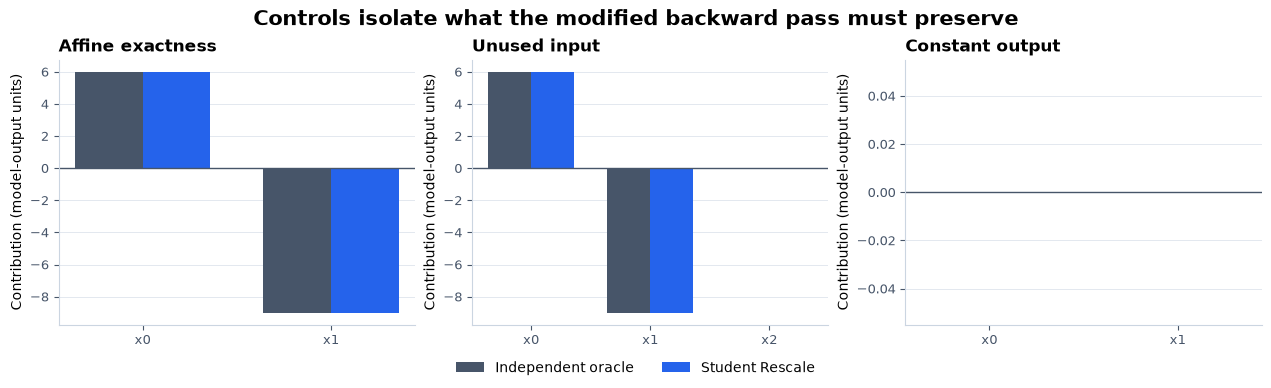

In [104]:
if MAIN:
    affine_controls = diagnose_affine_controls(deep_curriculum_namespace())
if MAIN:
    deep_show_figure(deep_plots.plot_affine_controls(affine_controls), "03_affine_controls")

An affine network is the exactness control: modified multipliers, ordinary gradients and exact
Shapley must coincide, while a zero-weight dummy input must receive zero credit.

## 5️⃣ Average explanations over a background

A single reference makes the answer depend on one baseline. DeepSHAP uses a finite empirical
background $B$:

$$
\phi_i(x;B)=\frac1{|B|}\sum_{b\in B}\phi_i^{(b)}(x),\qquad
\phi_0(B)=\frac1{|B|}\sum_{b\in B}f(b).
$$

When the per-reference rule is complete,

$$
\phi_0(B)+\sum_i\phi_i(x;B)=f(x).
$$

The average is outside the attribution computation. In general,

$$
\frac1{|B|}\sum_b \phi(x;b) \ne \phi\!\left(x;\frac1{|B|}\sum_b b\right)
$$

because a mean reference can cross different ReLU regions and is not one of the intact donor rows.

### Exercise 5 — `background_deepshap`

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵🔵
> 
> You should spend up to 20-30 minutes on this exercise.
> ```

Return `(base, phi)`, where `base` is a scalar tensor and `phi` has shape `(N,D)`.

In [105]:
def initialize_deep_30_background_deepshap():
    global background_deepshap
    @t.no_grad()
    def background_deepshap(
        model: nn.Sequential,
        x: Tensor,
        background: Tensor,
        epsilon: float = 1e-6,
    ) -> tuple[Tensor, Tensor]:
        """Average complete reference explanations and return E[f(background)]."""
        multiplier = rescale_multipliers(model, x, background, epsilon)
        pair_values = multiplier * (x[:, None, :] - background[None, :, :])
        with t.no_grad():
            base = _model_output(model, background).mean()
        return base, pair_values.mean(dim=1)


if MAIN:
    initialize_deep_30_background_deepshap()


if MAIN:
    deep_tests.test_background_deepshap(background_deepshap)

All tests in test_background_deepshap passed!


In [106]:
def background_average_fixture():
    """Return a nonlinear case where averaging references and inputs differ."""
    fixture = near_zero_fixture()
    fixture.update(
        {
            "query": torch.tensor([[2.0]], dtype=deep_DTYPE),
            "background": torch.tensor([[-2.0], [1.0]], dtype=deep_DTYPE),
            "expected_pair_phi": torch.tensor([[2.0], [1.0]], dtype=deep_DTYPE),
            "expected_mean_phi": torch.tensor([[1.5]], dtype=deep_DTYPE),
            "expected_base": torch.tensor(0.5, dtype=deep_DTYPE),
            "expected_mean_reference_phi": torch.tensor([[2.0]], dtype=deep_DTYPE),
            "expected_mean_reference_base": torch.tensor(0.0, dtype=deep_DTYPE),
        }
    )
    fixture.pop("reference")
    fixture.pop("epsilon")
    fixture.pop("expected_primary_phi")
    fixture.pop("expected_exact_secant_phi")
    return fixture

In [107]:
def deep_diagnose_background_average(methods):
    """Compare averaging attributions with explaining the mean reference."""
    single_reference = deep__method(methods, "single_reference")
    background_deepshap = deep__method(methods, "background_deepshap")
    fixture = background_average_fixture()
    model, query, background = fixture["model"], fixture["query"], fixture["background"]
    base, phi = background_deepshap(model, query, background)
    pair_phi = torch.stack(
        [single_reference(model, query, reference) for reference in background], dim=1
    ).squeeze(0)
    mean_reference = background.mean(dim=0)
    mean_reference_phi = single_reference(model, query, mean_reference)
    mean_reference_base = deep__prediction(model, mean_reference[None])[0]
    prediction = deep__prediction(model, query)[0]
    return {
        "query": query,
        "background": background,
        "mean_reference": mean_reference,
        "pair_phi": pair_phi,
        "expected_pair_phi": fixture["expected_pair_phi"],
        "phi": phi,
        "expected_phi": fixture["expected_mean_phi"],
        "base": base,
        "expected_base": fixture["expected_base"],
        "mean_reference_phi": mean_reference_phi,
        "expected_mean_reference_phi": fixture["expected_mean_reference_phi"],
        "mean_reference_base": mean_reference_base,
        "expected_mean_reference_base": fixture["expected_mean_reference_base"],
        "prediction": prediction,
        "averaging_gap": mean_reference_phi - phi,
        "phi_max_abs_error": deep__max_abs(phi, fixture["expected_mean_phi"]),
        "pair_phi_max_abs_error": deep__max_abs(pair_phi, fixture["expected_pair_phi"]),
    }

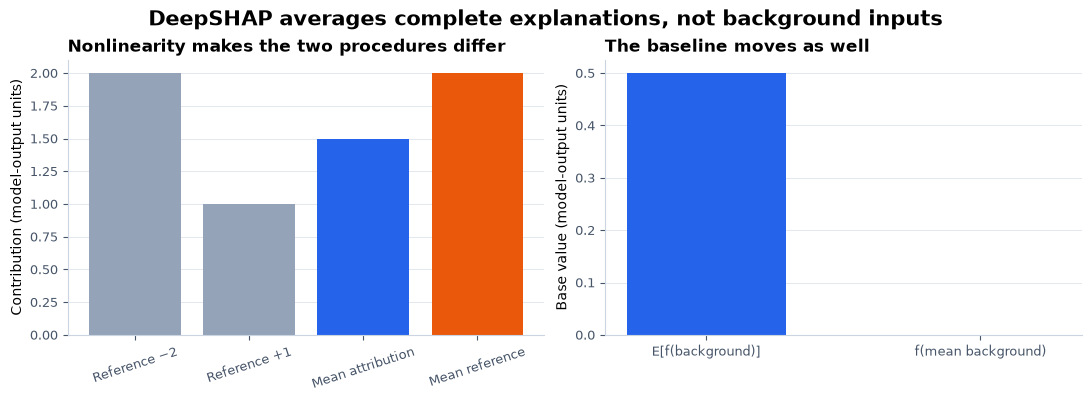

In [108]:
if MAIN:
    background_average = deep_diagnose_background_average(deep_curriculum_namespace())
if MAIN:
    deep_show_figure(deep_plots.plot_background_average(background_average), "04_background_average")

The control compares the correct average of pairwise explanations with the explanation relative to
the mean input. Their difference is visible precisely when the network is nonlinear across those
reference regions.

## 6️⃣ Define the exact empirical replacement game

DeepSHAP is fast because it composes local rules. To measure the approximation, we need an oracle
for the same finite background. For coalition $S$ and intact donor row $b$, define the hybrid

$$
h_i(x,b,S)=
\begin{cases}
x_i & i\in S,\\
b_i & i\notin S,
\end{cases}
\qquad
v_x(S)=\frac1{|B|}\sum_{b\in B} f(h(x,b,S)).
$$

Keeping each donor intact preserves correlations *within* a background row. It does not estimate a
conditional distribution for missing features. With eight features, evaluating all $2^8=256$
coalitions is affordable and gives a direct oracle for this explicitly stated marginal game.

In [109]:
def deep_coalition_masks(d: int) -> Tensor:
    """Return all Boolean coalitions in integer order, with feature zero as bit zero."""
    if type(d) is not int or d < 1:
        raise ValueError("d must be a positive integer.")
    subset = t.arange(2**d, dtype=t.int64)
    feature = t.arange(d, dtype=t.int64)
    return subset[:, None].bitwise_and(1 << feature).ne(0)

### Exercise 6 — `coalition_values`

> ```yaml
> Difficulty: 🔴🔴🔴🔴⚪
> Importance: 🔵🔵🔵🔵🔵
> 
> You should spend up to 35-50 minutes on this exercise.
> ```

Return `(N,K)` coalition values for masks `(K,D)`. Batch both source rows and flattened model
forwards. Never average donor inputs before the model call.

In [110]:
def coalition_values(
    model: nn.Sequential,
    x: Tensor,
    background: Tensor,
    masks: Tensor,
    row_batch: int = 8,
    forward_batch: int = 65_536,
) -> Tensor:
    """Evaluate every supplied intact-donor hybrid, then average over donors."""
    layers = _layers(model)
    _method_tensor("x", x, 2)
    _method_tensor("background", background, 2)
    if x.shape[1] != background.shape[1]:
        raise ValueError("x and background must have the same feature dimension.")
    _check_widths(layers, x.shape[1])
    if type(masks) is not Tensor or masks.device.type != "cpu" or masks.dtype != t.bool:
        raise TypeError("masks must be a CPU Boolean tensor.")
    if masks.ndim != 2 or masks.shape[1] != x.shape[1] or len(masks) == 0:
        raise ValueError("masks must have shape (nonempty coalitions, input features).")
    for name, size in (("row_batch", row_batch), ("forward_batch", forward_batch)):
        if type(size) is not int or size < 1:
            raise ValueError(f"{name} must be a positive integer.")

    result = t.empty((len(x), len(masks)), dtype=t.float64)
    with t.no_grad():
        for start in range(0, len(x), row_batch):
            query = x[start : start + row_batch]
            hybrids = t.where(
                masks[None, :, None, :],
                query[:, None, None, :],
                background[None, None, :, :],
            )
            flat = hybrids.reshape(-1, x.shape[1])
            predictions = t.cat(
                [
                    _model_output(model, flat[i : i + forward_batch])
                    for i in range(0, len(flat), forward_batch)
                ]
            )
            result[start : start + len(query)] = predictions.reshape(
                len(query), len(masks), len(background)
            ).mean(dim=2)
    return result


if MAIN:
    deep_tests.test_coalition_values(coalition_values)

All tests in test_coalition_values passed!


## 7️⃣ Contract every coalition into exact Shapley values

For $D$ features and feature $i$, exact Shapley is

$$
\phi_i=\sum_{S\subseteq [D]\setminus\{i\}}
\frac{|S|!(D-|S|-1)!}{D!}\left[v(S\cup\{i\})-v(S)\right].
$$

This is exact for the table it receives. It does not make the donor-replacement game conditional or
causal; those are properties of how `coalition_values` defined $v$, not of this contraction.

### Exercise 7 — `exact_shapley`

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵🔵
> 
> You should spend up to 25-35 minutes on this exercise.
> ```

Accept any leading batch shape and require the last dimension to be a power of two in bit order.

In [111]:
def deep_exact_shapley(values: Tensor) -> Tensor:
    """Contract a complete (..., 2**D) game with exact Shapley weights."""
    _method_tensor("values", values)
    if values.ndim < 1:
        raise ValueError("values must have a final coalition axis.")
    size = values.shape[-1]
    d = size.bit_length() - 1
    if d < 1 or size != 2**d:
        raise ValueError("The final values axis must contain all 2**D coalitions for D >= 1.")

    result = t.zeros((*values.shape[:-1], d), dtype=t.float64)
    subset_ids = t.arange(size, dtype=t.int64)
    for feature in range(d):
        absent = subset_ids[subset_ids.bitwise_and(1 << feature).eq(0)]
        weights = t.tensor(
            [1 / (d * math.comb(d - 1, int(subset).bit_count())) for subset in absent],
            dtype=t.float64,
        )
        marginal = values[..., absent | (1 << feature)] - values[..., absent]
        result[..., feature] = (marginal * weights).sum(dim=-1)
    return result


if MAIN:
    deep_tests.test_exact_shapley(deep_exact_shapley)

All tests in test_exact_shapley passed!


Before recomputing the threshold example, we need one ordinary-gradient baseline. We provide it
because it is a control rather than a DeepSHAP rule:

$$
\phi_i^{\text{grad-delta}}(x;B)
=\frac1{|B|}\sum_{b\in B}\frac{\partial f(x)}{\partial x_i}(x_i-b_i).
$$

It uses one endpoint gradient at `x`; it is not Expected Gradients or GradientSHAP. Its sum need not
reconstruct a nonlinear prediction difference.

In [112]:
def gradient_delta(model: nn.Sequential, x: Tensor, background: Tensor) -> Tensor:
    """Point gradient at x times x minus the mean background; not GradientSHAP."""
    layers = _layers(model)
    _method_tensor("x", x, 2)
    _method_tensor("background", background, 2)
    if x.shape[1] != background.shape[1]:
        raise ValueError("x and background must have the same feature dimension.")
    _check_widths(layers, x.shape[1])

    query = x.detach().clone().requires_grad_(True)
    with t.enable_grad():
        output = _model_output(model, query)
        gradient = t.autograd.grad(output.sum(), query)[0]
    if not t.isfinite(gradient).all():
        raise ValueError("The model produced a nonfinite input gradient.")
    return (gradient * (query - background.mean(dim=0))).detach()

In [113]:
if MAIN:
    deep_tests.test_gradient_delta(gradient_delta)

All tests in test_gradient_delta passed!


<details><summary>Expected output</summary>

```text
All tests in test_gradient_delta passed!
```

</details>

In [114]:
def deep_threshold_fixture(
    weights: Sequence[float] = (2.0, 1.0),
    bias: float = -2.0,
    query: Sequence[float] = (1.0, 1.0),
    reference: Sequence[float] = (0.0, 0.0),
):
    """Build ``ReLU(w @ x + bias)`` as a supported explicit Sequential."""
    weights = torch.as_tensor(weights, dtype=deep_DTYPE).reshape(1, -1)
    query = torch.as_tensor(query, dtype=deep_DTYPE).reshape(1, -1)
    reference = torch.as_tensor(reference, dtype=deep_DTYPE).reshape(-1)
    if query.shape[1] != weights.shape[1] or reference.shape != query.shape[1:]:
        raise ValueError("weights, query and reference must have one common feature size.")
    model = nn.Sequential(
        deep__linear(weights, [bias]),
        nn.ReLU(),
        deep__linear([[1.0]], [0.0]),
    ).eval()
    return {"model": model, "query": query, "reference": reference}

In [115]:
def diagnose_threshold(methods):
    """Show that Rescale can be complete while differing from exact Shapley."""
    single_reference = deep__method(methods, "single_reference")
    coalition_values = deep__method(methods, "coalition_values")
    exact_shapley = deep__method(methods, "exact_shapley")
    gradient_delta = deep__method(methods, "gradient_delta")
    fixture = deep_threshold_fixture()
    model, query, reference = (
        fixture["model"],
        fixture["query"],
        fixture["reference"],
    )
    masks = torch.tensor([[0, 0], [1, 0], [0, 1], [1, 1]], dtype=torch.bool)
    game = coalition_values(model, query, reference[None], masks)
    deep = single_reference(model, query, reference)
    exact = exact_shapley(game)
    gradient = gradient_delta(model, query, reference[None])
    prediction, base = game[0, -1], game[0, 0]
    expected_game = torch.tensor([[0.0, 0.0, 0.0, 1.0]], dtype=deep_DTYPE)
    expected_exact = torch.tensor([[0.5, 0.5]], dtype=deep_DTYPE)
    expected_deep = torch.tensor([[2.0 / 3.0, 1.0 / 3.0]], dtype=deep_DTYPE)
    expected_gradient = torch.tensor([[2.0, 1.0]], dtype=deep_DTYPE)
    full_minus_feature = torch.stack([prediction - game[0, 2], prediction - game[0, 1]])
    return {
        "query": query,
        "reference": reference,
        "masks": masks,
        "game": game,
        "expected_game": expected_game,
        "deep": deep,
        "expected_deep": expected_deep,
        "exact": exact,
        "expected_exact": expected_exact,
        "gradient": gradient,
        "expected_gradient": expected_gradient,
        "full_minus_feature": full_minus_feature,
        "expected_full_minus_feature": torch.ones(2, dtype=deep_DTYPE),
        "prediction": prediction,
        "base": base,
        "prediction_delta": prediction - base,
        "deep_completeness_residual": prediction - base - deep.sum(),
        "exact_completeness_residual": prediction - base - exact.sum(),
        "gradient_completeness_residual": prediction - base - gradient.sum(),
        "deep_exact_max_abs_error": deep__max_abs(deep, exact),
        "fixture_max_abs_error": max(
            deep__max_abs(game, expected_game),
            deep__max_abs(deep, expected_deep),
            deep__max_abs(exact, expected_exact),
            deep__max_abs(gradient, expected_gradient),
        ),
    }

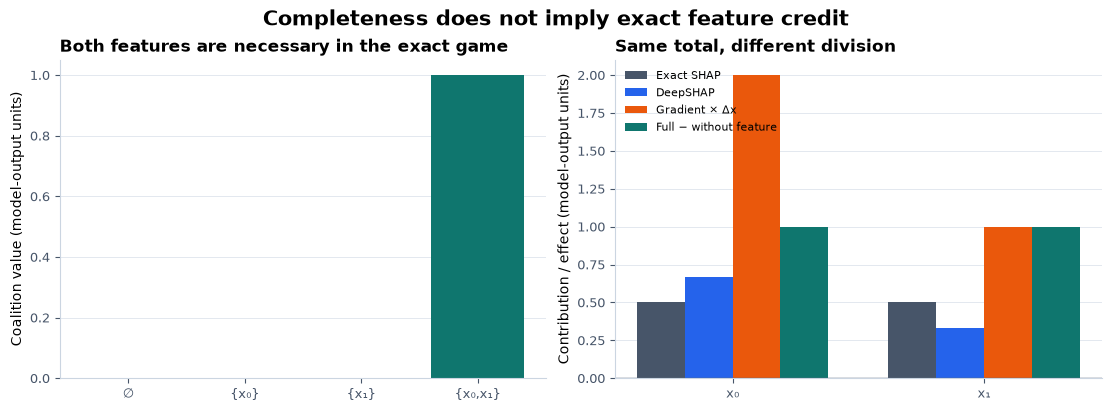

In [116]:
if MAIN:
    threshold = diagnose_threshold(deep_curriculum_namespace())
if MAIN:
    deep_show_figure(deep_plots.plot_threshold(threshold), "05_threshold_complete_not_exact")

This is the cold-open result recomputed from your own methods. Exact and DeepSHAP share the same
endpoint and both satisfy completeness, but their individual feature bars disagree.

## 8️⃣ Diagnose cancellation with RevealCancel groups

Rescale treats a nonlinear unit as one secant from total reference preactivation to total actual
preactivation. Opposing incoming changes can cancel before that secant is assigned. DeepLIFT's
historical RevealCancel rule instead groups positive and negative changes and computes a two-player
Shapley allocation through one activation.

For reference preactivation $z_0$, positive group $p\ge0$, negative group $n\le0$ and activation
$g$:

$$
\begin{aligned}
C_p &= \tfrac12[g(z_0+p)-g(z_0)]
     + \tfrac12[g(z_0+n+p)-g(z_0+n)],\\
C_n &= \tfrac12[g(z_0+n)-g(z_0)]
     + \tfrac12[g(z_0+p+n)-g(z_0+p)].
\end{aligned}
$$

This bounded diagnostic is not called by our DeepSHAP core or by the current SHAP Rescale path.

### Exercise 8 — `reveal_cancel_groups`

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵⚪⚪
> 
> You should spend up to 20-30 minutes on this exercise.
> ```

Implement the two grouped allocations for a broadcast-compatible unary activation.

In [117]:
def reveal_cancel_groups(
    activation,
    reference: Tensor,
    positive: Tensor,
    negative: Tensor,
) -> tuple[Tensor, Tensor]:
    """Two-player Shapley allocation of positive/negative groups through one activation."""
    if not callable(activation):
        raise TypeError("activation must be callable.")
    for name, value in (("reference", reference), ("positive", positive), ("negative", negative)):
        _method_tensor(name, value)
    try:
        reference, positive, negative = t.broadcast_tensors(reference, positive, negative)
    except RuntimeError as error:
        raise ValueError(
            "reference, positive and negative must be broadcast-compatible."
        ) from error
    if (positive < 0).any() or (negative > 0).any():
        raise ValueError("positive must be nonnegative and negative must be nonpositive.")

    def activate(value: Tensor) -> Tensor:
        output = activation(value)
        if type(output) is not Tensor or output.shape != value.shape:
            raise TypeError("activation must return a tensor with the same shape as its input.")
        if output.device.type != "cpu" or output.dtype != t.float64 or not t.isfinite(output).all():
            raise ValueError("activation must return finite CPU float64 values.")
        return output

    base = activate(reference)
    positive_first = activate(reference + positive)
    negative_first = activate(reference + negative)
    together = activate(reference + positive + negative)
    positive_value = 0.5 * (positive_first - base + together - negative_first)
    negative_value = 0.5 * (negative_first - base + together - positive_first)
    return positive_value, negative_value


if MAIN:
    deep_tests.test_reveal_cancel_groups(reveal_cancel_groups)

All tests in test_reveal_cancel_groups passed!


In [118]:
def min_fixture():
    """Return two graph forms of min(x0, x1) on nonnegative inputs."""
    first = nn.Sequential(
        deep__linear([[0.0, 1.0], [-1.0, 1.0]], [0.0, 0.0]),
        nn.ReLU(),
        deep__linear([[1.0, -1.0]], [0.0]),
    ).eval()
    mirrored = nn.Sequential(
        deep__linear([[1.0, 0.0], [1.0, -1.0]], [0.0, 0.0]),
        nn.ReLU(),
        deep__linear([[1.0, -1.0]], [0.0]),
    ).eval()
    return {
        "models": {"x1 route": first, "x0 route": mirrored},
        "query": torch.tensor([[1.0, 1.0]], dtype=deep_DTYPE),
        "reference": torch.tensor([0.0, 0.0], dtype=deep_DTYPE),
        "binary_inputs": torch.tensor(
            [[0.0, 0.0], [1.0, 0.0], [0.0, 1.0], [1.0, 1.0]], dtype=deep_DTYPE
        ),
        "expected_binary": torch.tensor([0.0, 0.0, 0.0, 1.0], dtype=deep_DTYPE),
        "expected_exact": torch.tensor([[0.5, 0.5]], dtype=deep_DTYPE),
        "expected_deep": {
            "x1 route": torch.tensor([[0.0, 1.0]], dtype=deep_DTYPE),
            "x0 route": torch.tensor([[1.0, 0.0]], dtype=deep_DTYPE),
        },
    }

In [119]:
def diagnose_cancellation(methods):
    """Compare two equivalent min graphs and the bounded RevealCancel repair."""
    single_reference = deep__method(methods, "single_reference")
    coalition_values = deep__method(methods, "coalition_values")
    exact_shapley = deep__method(methods, "exact_shapley")
    reveal_cancel = deep__method(methods, "reveal_cancel_groups")
    fixture = min_fixture()
    query, reference = fixture["query"], fixture["reference"]
    masks = torch.tensor([[0, 0], [1, 0], [0, 1], [1, 1]], dtype=torch.bool)
    positive, negative = reveal_cancel(
        torch.relu,
        torch.tensor(0.0, dtype=deep_DTYPE),
        torch.tensor(1.0, dtype=deep_DTYPE),
        torch.tensor(-1.0, dtype=deep_DTYPE),
    )
    reveal_phi = {
        "x1 route": torch.stack([-negative, 1.0 - positive])[None],
        "x0 route": torch.stack([1.0 - positive, -negative])[None],
    }
    models = {}
    for name, model in fixture["models"].items():
        game = coalition_values(model, query, reference[None], masks)
        deep = single_reference(model, query, reference)
        exact = exact_shapley(game)
        binary_prediction = deep__prediction(model, fixture["binary_inputs"])
        models[name] = {
            "binary_prediction": binary_prediction,
            "expected_binary": fixture["expected_binary"],
            "game": game,
            "deep": deep,
            "expected_deep": fixture["expected_deep"][name],
            "exact": exact,
            "expected_exact": fixture["expected_exact"],
            "reveal_cancel": reveal_phi[name],
            "binary_max_abs_error": deep__max_abs(binary_prediction, fixture["expected_binary"]),
            "deep_max_abs_error": deep__max_abs(deep, fixture["expected_deep"][name]),
            "exact_max_abs_error": deep__max_abs(exact, fixture["expected_exact"]),
            "reveal_cancel_max_abs_error": deep__max_abs(
                reveal_phi[name], fixture["expected_exact"]
            ),
        }
    return {
        "query": query,
        "reference": reference,
        "masks": masks,
        "models": models,
        "group_allocation": {"positive": positive, "negative": negative},
        "computational_domain": "nonnegative inputs",
        "deep_implementation_gap": models["x0 route"]["deep"] - models["x1 route"]["deep"],
    }

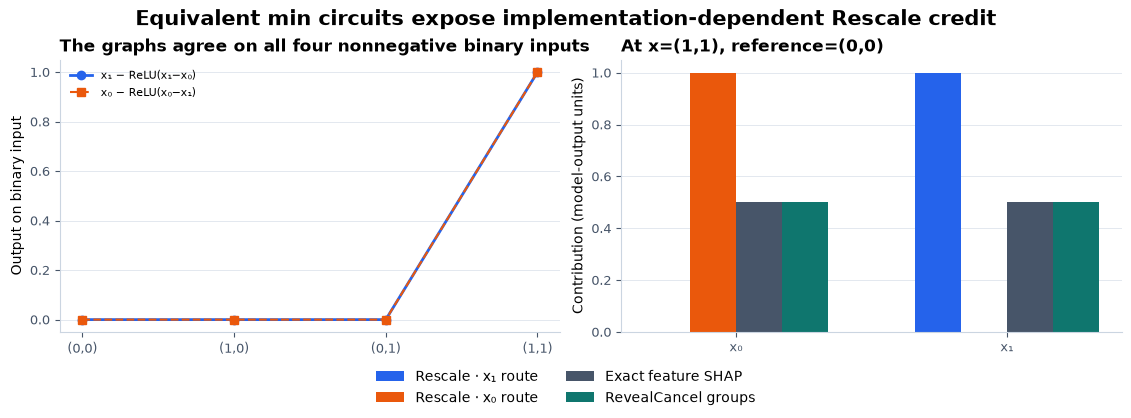

In [120]:
if MAIN:
    cancellation = diagnose_cancellation(deep_curriculum_namespace())
if MAIN:
    deep_show_figure(
        deep_plots.plot_cancellation(cancellation),
        "06_cancellation_implementation_dependence",
    )

The mirrored `min` implementations are a representation control. A feature attribution method that
follows hidden computational paths can change even when the tested input/output function does not.

## 9️⃣ Turn attribution rankings into intervention curves

Attribution agreement is one diagnostic. A second asks what the model does when features are
actually replaced. Rank features, then insert them into the empty coalition or delete them from the
full coalition. Because `values` already averages intact donor hybrids, every point can be looked up
without another model call.

For regressions whose full prediction lies below the empty value, reverse the attribution sign
before ranking so “largest first” means movement toward the full prediction. Treat an exactly zero
output difference as positive. Break ties by feature index so the result is reproducible.

### Exercise 9 — `ranked_replacement_curves`

> ```yaml
> Difficulty: 🔴🔴🔴🔴⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 35-45 minutes on this exercise.
> ```

Return a dictionary with `orders`, integer `insertion_masks` and `deletion_masks`, plus the
corresponding raw prediction values. Optional supplied orders must contain an exact permutation on
every row.

In [121]:
def ranked_replacement_curves(
    values: Tensor,
    phi: Tensor,
    orders: Tensor | None = None,
) -> dict[str, Tensor]:
    """Read insertion/deletion prefixes from a complete per-row coalition table."""
    _method_tensor("values", values, 2)
    _method_tensor("phi", phi, 2)
    n, size = values.shape
    d = size.bit_length() - 1
    if d < 1 or size != 2**d or phi.shape != (n, d):
        raise ValueError("values must be (N,2**D) and phi must be (N,D), with D >= 1.")

    if orders is None:
        direction = t.where(values[:, -1] - values[:, 0] >= 0, 1.0, -1.0)[:, None]
        orders = t.argsort(direction * phi, dim=1, descending=True, stable=True)
    else:
        if type(orders) is not Tensor or orders.device.type != "cpu" or orders.dtype != t.int64:
            raise TypeError("orders must be a CPU int64 tensor.")
        if orders.shape != (n, d):
            raise ValueError("orders must have shape (rows, features).")
        expected = t.arange(d, dtype=t.int64).expand(n, d)
        if not t.equal(orders.sort(dim=1).values, expected):
            raise ValueError("Every order row must contain each feature exactly once.")
        orders = orders.clone()

    insertion_masks = t.zeros((n, d + 1), dtype=t.int64)
    deletion_masks = t.full((n, d + 1), size - 1, dtype=t.int64)
    for step in range(d):
        bit = 1 << orders[:, step]
        insertion_masks[:, step + 1] = insertion_masks[:, step] | bit
        deletion_masks[:, step + 1] = deletion_masks[:, step] ^ bit
    return {
        "orders": orders,
        "insertion_masks": insertion_masks,
        "deletion_masks": deletion_masks,
        "insertion": values.gather(1, insertion_masks),
        "deletion": values.gather(1, deletion_masks),
    }


if MAIN:
    deep_tests.test_ranked_replacement_curves(ranked_replacement_curves)

All tests in test_ranked_replacement_curves passed!


In [122]:
def deep_replacement_fixture():
    """Return an additive three-player game with one exact dummy feature."""
    contributions = torch.tensor([3.0, -2.0, 0.0], dtype=deep_DTYPE)
    masks = torch.tensor(
        [[bool(mask & (1 << feature)) for feature in range(3)] for mask in range(8)]
    )
    values = 10.0 + (masks.to(deep_DTYPE) * contributions).sum(dim=1)
    return {
        "masks": masks,
        "values": values[None],
        "phi": contributions[None],
        "expected_order": torch.tensor([[0, 2, 1]], dtype=torch.long),
        "expected_insertion": torch.tensor([[10.0, 13.0, 13.0, 11.0]], dtype=deep_DTYPE),
        "expected_deletion": torch.tensor([[11.0, 8.0, 8.0, 10.0]], dtype=deep_DTYPE),
    }

In [123]:
def diagnose_replacement_control(methods):
    """Check ranked insertion/deletion endpoints and a zero-credit feature."""
    ranked_curves = deep__method(methods, "ranked_replacement_curves")
    fixture = deep_replacement_fixture()
    result = ranked_curves(fixture["values"], fixture["phi"])
    return {
        **fixture,
        "result": result,
        "order_max_abs_error": deep__max_abs(result["orders"], fixture["expected_order"]),
        "insertion_max_abs_error": deep__max_abs(result["insertion"], fixture["expected_insertion"]),
        "deletion_max_abs_error": deep__max_abs(result["deletion"], fixture["expected_deletion"]),
        "dummy_insertion_change": result["insertion"][0, 2] - result["insertion"][0, 1],
        "dummy_deletion_change": result["deletion"][0, 2] - result["deletion"][0, 1],
    }

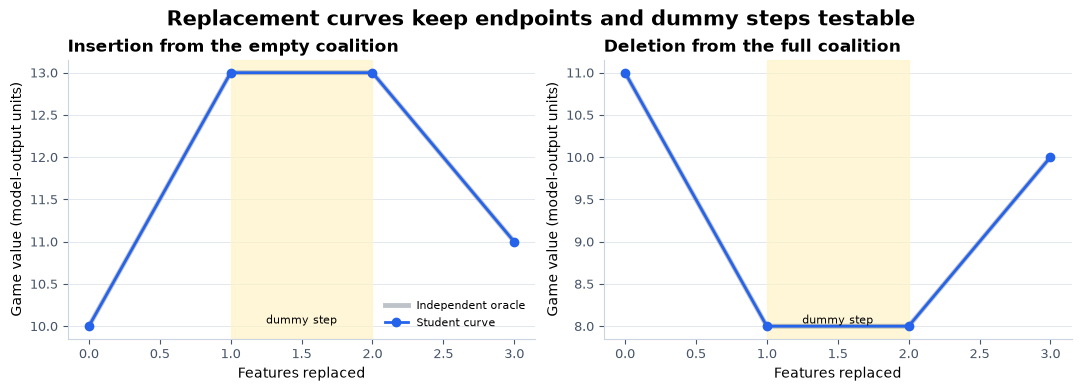

In [124]:
if MAIN:
    replacement_control = diagnose_replacement_control(deep_curriculum_namespace())
if MAIN:
    deep_show_figure(deep_plots.plot_replacement_control(replacement_control), "07_replacement_fixture")

## From the modified backward pass to a real study

We now have three comparisons for the same model and finite background: the fast compositional
DeepSHAP approximation, exhaustive feature Shapley and the ordinary gradient-times-delta control.

In [125]:
if MAIN:
    deep_curriculum_methods = SimpleNamespace(
        paired_forward=paired_forward,
        rescale_slope=rescale_slope,
        rescale_multipliers=rescale_multipliers,
        single_reference=single_reference,
        background_deepshap=background_deepshap,
        coalition_values=coalition_values,
        exact_shapley=deep_exact_shapley,
        reveal_cancel_groups=reveal_cancel_groups,
        ranked_replacement_curves=ranked_replacement_curves,
        coalition_masks=deep_coalition_masks,
        gradient_delta=gradient_delta,
    )

### Try It Yourself 1 — move the threshold

Edit the weights, bias, query, reference or epsilon. Look for regions where exact Shapley and
DeepSHAP agree, regions where both are complete but allocate differently, and the tiny interval
where the finite epsilon deliberately breaks completeness.

In [126]:
def deep_threshold_play(
    methods,
    weights: Sequence[float] = (2.0, 1.0),
    bias: float = -2.0,
    query: Sequence[float] = (1.0, 1.0),
    reference: Sequence[float] = (0.0, 0.0),
    epsilon: float = 1e-6,
):
    """Recompute the editable gate with the learner's implemented methods."""
    single_reference = deep__method(methods, "single_reference")
    coalition_values = deep__method(methods, "coalition_values")
    exact_shapley = deep__method(methods, "exact_shapley")
    gradient_delta = deep__method(methods, "gradient_delta")
    fixture = deep_threshold_fixture(weights, bias, query, reference)
    model, query_tensor, reference_tensor = (
        fixture["model"],
        fixture["query"],
        fixture["reference"],
    )
    dimension = query_tensor.shape[1]
    masks = torch.tensor(
        [
            [bool(mask & (1 << feature)) for feature in range(dimension)]
            for mask in range(2**dimension)
        ]
    )
    game = coalition_values(model, query_tensor, reference_tensor[None], masks)
    deep = single_reference(model, query_tensor, reference_tensor, epsilon=epsilon)
    exact = exact_shapley(game)
    gradient = gradient_delta(model, query_tensor, reference_tensor[None])
    return {
        "weights": torch.as_tensor(weights, dtype=deep_DTYPE),
        "bias": float(bias),
        "query": query_tensor,
        "reference": reference_tensor,
        "epsilon": float(epsilon),
        "masks": masks,
        "game": game,
        "prediction": game[0, -1],
        "base": game[0, 0],
        "deep": deep,
        "exact": exact,
        "gradient": gradient,
        "deep_completeness_residual": game[0, -1] - game[0, 0] - deep.sum(),
        "deep_exact_max_abs_error": deep__max_abs(deep, exact),
    }

In [127]:
def deep_run_diagnostics(methods=None, include_timing=True):
    """Collect every checkpoint after all nine methods have been defined.

    The lesson calls each diagnostic separately at its own checkpoint.  This
    convenience runner is reserved for the final native/reproduction harness,
    where the complete student-method namespace is already available.  There
    is no timing study in this section, so the separately persisted timing
    branch is intentionally empty.
    """

    def detach_tree(value):
        if isinstance(value, Tensor):
            return value.detach()
        if isinstance(value, dict):
            return {key: detach_tree(item) for key, item in value.items()}
        if isinstance(value, list):
            return [detach_tree(item) for item in value]
        if isinstance(value, tuple):
            return tuple(detach_tree(item) for item in value)
        return value

    mechanism = {
        "rescale_limits": diagnose_rescale_limits(methods),
        "near_zero": diagnose_near_zero(methods),
        "affine_controls": diagnose_affine_controls(methods),
        "background_average": deep_diagnose_background_average(methods),
        "threshold": diagnose_threshold(methods),
        "cancellation": diagnose_cancellation(methods),
        "replacement_control": diagnose_replacement_control(methods),
        "threshold_play": deep_threshold_play(methods),
    }
    return {"mechanism": detach_tree(mechanism), "timing": {} if include_timing else {}}

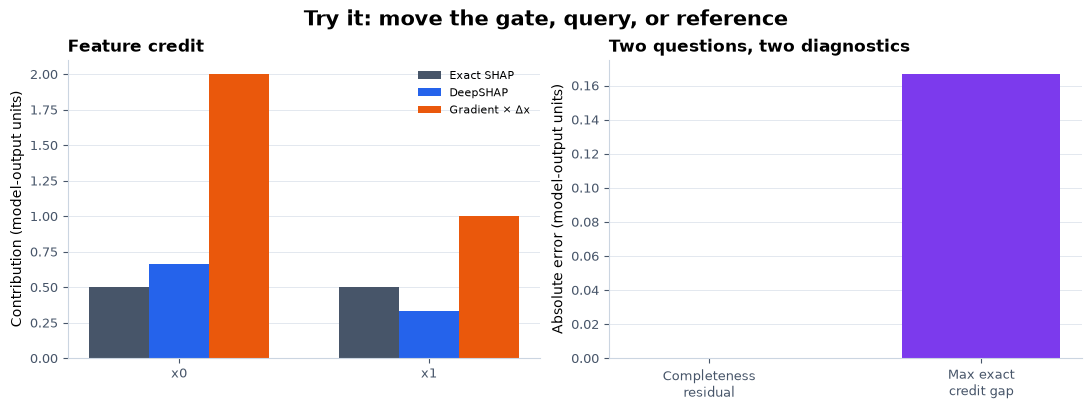

In [128]:
if MAIN:
    deep_tiny_play = deep_threshold_play(
        deep_curriculum_methods,
        weights=(2.0, 1.0),
        bias=-2.0,
        query=(1.0, 1.0),
        reference=(0.0, 0.0),
        epsilon=1e-6,
    )
if MAIN:
    deep_show_figure(deep_plots.plot_threshold_play(deep_tiny_play), "16_threshold_play")

<details><summary>Ideas to try</summary>

- Set both weights equal. Does symmetry force the two methods to agree?
- Move the bias until one feature can cross the threshold alone.
- Use `weights=(1,)`, `bias=0`, `query=(4e-7,)`, `reference=(-4e-7,)` and compare
`epsilon=1e-6` with `epsilon=0`.
- Scale every weight and the bias by the same positive constant. Which quantities scale, and which
ratios stay fixed?

</details>

## The frozen concrete-strength study

The data contain 1,030 public UCI concrete recipes with eight inputs and compressive strength in
MPa. Identical seven-ingredient recipes stay in the same split: 758 training rows, 153 explanation
rows and 119 audit rows. We train six fresh `8 -> 32 -> 32 -> 1` ReLU networks at three fixed seeds:
three with clean targets and three with independently shuffled targets. A ridge model is the affine
control. Every model operates in raw feature units after its training standardization is folded into
the first and last affine layers.

The shuffled networks and training-target mean test whether a visually detailed explanation can make
a poor predictor useful. The three clean seeds expose model variation; repeated agreement is not
treated as three independent uncertainty estimates. All seven models and all 272 held-out rows
remain in the results.

The fitting code is part of the lesson. It receives only the training split and retains its initial
state, standardized state, raw-unit state, loss trace, target permutation and training predictions.

In [129]:
if MAIN:
    from collections.abc import Mapping

if MAIN:
    from typing import Any

if MAIN:
    import numpy as np

if MAIN:
    import torch as t

if MAIN:
    from chapter16_shapley_attribution_baselines.exercises.part3_model_specific_shap.deep_deepshap_data import (
        background_order as deep_background_order,
    )

deep_FEATURES = 8

deep_HIDDEN = 32

deep_TRAINING_STEPS = 800

deep_LEARNING_RATE = 0.003

deep_WEIGHT_DECAY = 0.0001

deep_RIDGE_PENALTY = 0.01

deep_MODEL_SEEDS = (161410, 161411, 161412)

deep_SHUFFLE_SEEDS = (161420, 161421, 161422)

PRIMARY_BACKGROUND_SEED = 161460

INDEPENDENT_BACKGROUND_SEEDS = (161461, 161462)

deep_RANDOM_ORDER_SEED = 161480

In [130]:
if MAIN:
    deep_MODEL_KEYS = tuple(
        [f"clean_{index}" for index in range(3)]
        + [f"shuffled_{index}" for index in range(3)]
        + ["ridge"]
    )

deep_FEATURE_NAMES = (
    "Cement",
    "Slag",
    "Fly ash",
    "Water",
    "Superplasticizer",
    "Coarse aggregate",
    "Fine aggregate",
    "Age",
)

if MAIN:
    deep_MODEL_LABELS = {
        **{f"clean_{index}": f"clean MLP seed {seed}" for index, seed in enumerate(deep_MODEL_SEEDS)},
        **{
            f"shuffled_{index}": f"shuffled MLP seed {seed}"
            for index, seed in enumerate(deep_MODEL_SEEDS)
        },
        "ridge": "ridge control",
    }

deep_METHOD_NAMES = (
    "rescale_multipliers",
    "background_deepshap",
    "coalition_values",
    "exact_shapley",
    "gradient_delta",
    "coalition_masks",
    "ranked_replacement_curves",
)

deep_UNITS = {
    "input": "source feature units",
    "target": "MPa",
    "prediction": "MPa",
    "base": "MPa",
    "attribution": "MPa",
    "game": "MPa",
    "squared_error": "MPa squared",
}

### Visible supporting scientific function: `_clone_state`

In [131]:
if MAIN:
    from collections.abc import Mapping
if MAIN:
    import torch as t

def deep_helper_deepshap_study__clone_state(state: Mapping[str, t.Tensor]) -> dict[str, t.Tensor]:
    if not isinstance(state, Mapping):
        raise TypeError("A model state must be a tensor mapping.")
    cloned: dict[str, t.Tensor] = {}
    for name, value in state.items():
        if not isinstance(name, str) or not isinstance(value, t.Tensor):
            raise TypeError("State keys must be strings and values must be tensors.")
        if value.device.type != "cpu" or value.dtype != t.float64:
            raise TypeError("Every model-state tensor must be CPU float64.")
        if not bool(t.isfinite(value).all()):
            raise ValueError("Model-state tensors must be finite.")
        cloned[name] = value.detach().clone()
    return cloned

### Visible supporting scientific function: `_clone_tree`

In [132]:
if MAIN:
    from typing import Any
if MAIN:
    from collections.abc import Mapping
if MAIN:
    import torch as t

def deep_helper_deepshap_study__clone_tree(value: Any) -> Any:
    if isinstance(value, t.Tensor):
        return value.detach().clone()
    if isinstance(value, Mapping):
        return {name: deep_helper_deepshap_study__clone_tree(item) for name, item in value.items()}
    if isinstance(value, list):
        return [deep_helper_deepshap_study__clone_tree(item) for item in value]
    if isinstance(value, tuple):
        return tuple(deep_helper_deepshap_study__clone_tree(item) for item in value)
    return value

### Visible supporting scientific function: `_combine_explanations`

In [133]:
if MAIN:
    from collections.abc import Mapping
if MAIN:
    import torch as t

def deep_helper_deepshap_study__combine_explanations(
    explanation: Mapping[str, t.Tensor], audit: Mapping[str, t.Tensor]
) -> dict[str, t.Tensor]:
    if not t.allclose(explanation["base"], audit["base"], atol=0.0, rtol=0.0):
        raise ValueError("Primary background base changed between row blocks.")
    return {
        "base": explanation["base"].clone(),
        **{
            name: t.cat([explanation[name], audit[name]], dim=0)
            for name in (
                "prediction",
                "phi_deep",
                "phi_exact",
                "phi_gradient",
                "game",
                "pair_deep",
            )
        },
    }

### Visible supporting scientific function: `_combine_row_blocks`

In [134]:
if MAIN:
    from collections.abc import Mapping
if MAIN:
    import torch as t

def deep_helper_deepshap_study__combine_row_blocks(rows: Mapping[str, t.Tensor]) -> dict[str, t.Tensor]:
    """Concatenate explanation then audit rows and retain a numeric split label."""
    return {
        "x": t.cat([rows["explain_x"], rows["audit_x"]], dim=0),
        "y": t.cat([rows["explain_y"], rows["audit_y"]], dim=0),
        "ids": t.cat([rows["explain_ids"], rows["audit_ids"]], dim=0),
        "split": t.cat(
            [
                t.zeros(len(rows["explain_ids"]), dtype=t.int64),
                t.ones(len(rows["audit_ids"]), dtype=t.int64),
            ]
        ),
    }

### Visible supporting scientific function: `_float_tensor`

In [135]:
if MAIN:
    from typing import Any
if MAIN:
    import torch as t

def deep_helper_deepshap_study__float_tensor(value: Any, name: str, dimensions: int) -> t.Tensor:
    tensor = value if isinstance(value, t.Tensor) else t.as_tensor(value)
    if tensor.device.type != "cpu" or tensor.dtype != t.float64:
        raise TypeError(f"{name} must be a CPU float64 tensor or array.")
    if tensor.ndim != dimensions or not bool(t.isfinite(tensor).all()):
        raise ValueError(f"{name} has the wrong shape or contains nonfinite values.")
    return tensor.detach().clone()

### Visible supporting scientific function: `_ids_tensor`

In [136]:
if MAIN:
    from typing import Any
if MAIN:
    import torch as t

def deep_helper_deepshap_study__ids_tensor(value: Any, rows: int, name: str) -> t.Tensor:
    tensor = value if isinstance(value, t.Tensor) else t.as_tensor(value)
    if tensor.device.type != "cpu" or tensor.dtype != t.int64 or tensor.shape != (rows,):
        raise TypeError(f"{name} must be a one-dimensional CPU int64 array.")
    if len(t.unique(tensor)) != rows:
        raise ValueError(f"{name} must contain unique source-row identities.")
    return tensor.detach().clone()

### Visible supporting scientific function: `FEATURES`

In [137]:
deep_helper_deepshap_study_FEATURES = 8

### Visible supporting scientific function: `_normalization_tensors`

In [138]:
if MAIN:
    from typing import Any
if MAIN:
    from collections.abc import Mapping
if MAIN:
    import torch as t

def deep_helper_deepshap_study__normalization_tensors(normalization: Mapping[str, Any]) -> tuple[t.Tensor, ...]:
    if not isinstance(normalization, Mapping):
        raise TypeError("normalization must be a mapping.")
    x_mean = deep_helper_deepshap_study__float_tensor(normalization.get("x_mean"), "x_mean", 1)
    x_std = deep_helper_deepshap_study__float_tensor(normalization.get("x_std"), "x_std", 1)
    y_mean = deep_helper_deepshap_study__float_tensor(normalization.get("y_mean"), "y_mean", 0)
    y_std = deep_helper_deepshap_study__float_tensor(normalization.get("y_std"), "y_std", 0)
    if x_mean.shape != (deep_helper_deepshap_study_FEATURES,) or x_std.shape != (deep_helper_deepshap_study_FEATURES,):
        raise ValueError("Normalization must describe exactly eight input features.")
    if bool((x_std <= 0).any()) or not bool(y_std > 0):
        raise ValueError("Training standard deviations must be positive.")
    return x_mean, x_std, y_mean, y_std

### Visible supporting scientific function: `_output_tensor`

In [139]:
if MAIN:
    from typing import Any
if MAIN:
    import torch as t

def deep_helper_deepshap_study__output_tensor(value: Any, shape: tuple[int, ...], name: str) -> t.Tensor:
    if not isinstance(value, t.Tensor):
        raise TypeError(f"{name} must be a Torch tensor.")
    if value.device.type != "cpu" or value.dtype != t.float64 or tuple(value.shape) != shape:
        raise ValueError(f"{name} has the wrong dtype, device or shape.")
    if not bool(t.isfinite(value).all()):
        raise ValueError(f"{name} contains nonfinite values.")
    return value.detach().clone()

### Visible supporting scientific function: `_require_disjoint_ids`

In [140]:
if MAIN:
    import torch as t

def deep_helper_deepshap_study__require_disjoint_ids(**splits: t.Tensor) -> None:
    """Reject source-row reuse across named train, explanation and audit splits."""
    names = tuple(splits)
    for left_index, left_name in enumerate(names):
        left = splits[left_name]
        for right_name in names[left_index + 1 :]:
            right = splits[right_name]
            if bool(t.isin(left, right).any()):
                raise ValueError(
                    f"{left_name} and {right_name} source-row identities must be disjoint."
                )

### Visible supporting scientific function: `METHOD_NAMES`

In [141]:
deep_helper_deepshap_study_METHOD_NAMES = (
    "rescale_multipliers",
    "background_deepshap",
    "coalition_values",
    "exact_shapley",
    "gradient_delta",
    "coalition_masks",
    "ranked_replacement_curves",
)

### Visible supporting scientific function: `_require_methods`

In [142]:
if MAIN:
    from typing import Any

def deep_helper_deepshap_study__require_methods(methods: Any) -> None:
    missing = [name for name in deep_helper_deepshap_study_METHOD_NAMES if not callable(getattr(methods, name, None))]
    if missing:
        raise TypeError(f"Student methods namespace is missing {missing}.")

### Visible supporting scientific function: `_rows`

In [143]:
if MAIN:
    from typing import Any
if MAIN:
    from collections.abc import Mapping
if MAIN:
    import torch as t

def deep_helper_deepshap_study__rows(rows: Mapping[str, Any], name: str) -> tuple[t.Tensor, t.Tensor, t.Tensor]:
    if not isinstance(rows, Mapping) or not {"x", "y", "ids"} <= set(rows):
        raise TypeError(f"{name} must contain x, y and ids.")
    x = deep_helper_deepshap_study__float_tensor(rows["x"], f"{name}.x", 2)
    y = deep_helper_deepshap_study__float_tensor(rows["y"], f"{name}.y", 1)
    if x.shape != (len(y), deep_helper_deepshap_study_FEATURES) or len(y) == 0:
        raise ValueError(f"{name} must contain nonempty eight-feature rows.")
    ids = deep_helper_deepshap_study__ids_tensor(rows["ids"], len(y), f"{name}.ids")
    return x, y, ids

### Visible supporting scientific function: `HIDDEN`

In [144]:
deep_helper_deepshap_study_HIDDEN = 32

### Visible supporting scientific function: `_state_shapes`

In [145]:
def deep_helper_deepshap_study__state_shapes(kind: str) -> dict[str, tuple[int, ...]]:
    if kind == "mlp":
        return {
            "0.weight": (deep_helper_deepshap_study_HIDDEN, deep_helper_deepshap_study_FEATURES),
            "0.bias": (deep_helper_deepshap_study_HIDDEN,),
            "2.weight": (deep_helper_deepshap_study_HIDDEN, deep_helper_deepshap_study_HIDDEN),
            "2.bias": (deep_helper_deepshap_study_HIDDEN,),
            "4.weight": (1, deep_helper_deepshap_study_HIDDEN),
            "4.bias": (1,),
        }
    if kind == "ridge":
        return {"0.weight": (1, deep_helper_deepshap_study_FEATURES), "0.bias": (1,)}
    raise ValueError(f"Unsupported fitted-model kind: {kind!r}.")

### Visible supporting scientific function: `MODEL_KEYS`

In [146]:
if MAIN:
    deep_helper_deepshap_study_MODEL_KEYS = tuple(
        [f"clean_{index}" for index in range(3)]
        + [f"shuffled_{index}" for index in range(3)]
        + ["ridge"]
    )

### Visible supporting scientific function: `_validate_fitted`

In [147]:
if MAIN:
    from typing import Any
if MAIN:
    from collections.abc import Mapping

def deep_helper_deepshap_study__validate_fitted(fitted: Mapping[str, Any]) -> None:
    if not isinstance(fitted, Mapping) or fitted.get("phase") != "models_fitted_on_train_only":
        raise ValueError("Use the complete train-only fitted payload.")
    if not isinstance(fitted.get("models"), Mapping) or tuple(fitted["models"]) != deep_helper_deepshap_study_MODEL_KEYS:
        raise ValueError("The fitted payload must retain all seven models in frozen order.")
    deep_helper_deepshap_study__normalization_tensors(fitted.get("normalization"))
    x = deep_helper_deepshap_study__float_tensor(fitted.get("train_x_raw"), "train_x_raw", 2)
    y = deep_helper_deepshap_study__float_tensor(fitted.get("train_y_raw"), "train_y_raw", 1)
    if x.shape != (len(y), deep_helper_deepshap_study_FEATURES):
        raise ValueError("Fitted training arrays have incompatible shapes.")
    deep_helper_deepshap_study__ids_tensor(fitted.get("train_ids"), len(y), "train_ids")
    for key in deep_helper_deepshap_study_MODEL_KEYS:
        model = fitted["models"][key]
        expected_kind = "ridge" if key == "ridge" else "mlp"
        if model.get("kind") != expected_kind:
            raise ValueError(f"{key} has the wrong model kind.")
        make_model(model)

### Visible supporting scientific function: `_validate_rankings`

In [148]:
if MAIN:
    from typing import Any
if MAIN:
    from collections.abc import Mapping
if MAIN:
    import torch as t

def deep_helper_deepshap_study__validate_rankings(rankings: Any) -> None:
    if not isinstance(rankings, Mapping) or tuple(rankings) != deep_helper_deepshap_study_MODEL_KEYS:
        raise ValueError("Prepared rankings must retain all seven models in frozen order.")
    expected = t.arange(deep_helper_deepshap_study_FEATURES, dtype=t.int64)
    for key in deep_helper_deepshap_study_MODEL_KEYS:
        item = rankings[key]
        if not isinstance(item, Mapping) or set(item) != {"exact", "deep", "gradient"}:
            raise ValueError(f"{key} must retain exact, DeepSHAP and gradient rankings.")
        for name, order in item.items():
            if not isinstance(order, t.Tensor) or order.device.type != "cpu":
                raise TypeError(f"{key}/{name} ranking must be a CPU tensor.")
            if order.dtype != t.int64 or order.shape != (deep_helper_deepshap_study_FEATURES,):
                raise ValueError(f"{key}/{name} ranking must be one int64 feature order.")
            if not t.equal(order.sort().values, expected):
                raise ValueError(f"{key}/{name} ranking must contain each feature once.")

### Visible supporting scientific function: `_validate_evaluation_inputs`

In [149]:
if MAIN:
    from typing import Any
if MAIN:
    from collections.abc import Mapping
if MAIN:
    import torch as t

def deep_helper_deepshap_study__validate_evaluation_inputs(
    fitted: Mapping[str, Any],
    prepared: Mapping[str, Any],
    train: Mapping[str, Any],
    explain: Mapping[str, Any],
    audit: Mapping[str, Any],
) -> dict[str, t.Tensor]:
    """Recheck the persisted preparation boundary against all named row blocks."""
    deep_helper_deepshap_study__validate_fitted(fitted)
    if prepared.get("phase") != "rankings_frozen_before_audit":
        raise ValueError("Persist explanation rankings before audit evaluation.")
    if prepared.get("audit_used_for_selection") is not False:
        raise ValueError("Audit rows cannot select models, backgrounds or rankings.")
    train_x, train_y, train_ids = deep_helper_deepshap_study__rows(train, "train")
    explain_x, explain_y, explain_ids = deep_helper_deepshap_study__rows(explain, "explain")
    audit_x, audit_y, audit_ids = deep_helper_deepshap_study__rows(audit, "audit")
    deep_helper_deepshap_study__require_disjoint_ids(train=train_ids, explanation=explain_ids, audit=audit_ids)
    if not t.equal(train_ids, fitted["train_ids"]) or not t.equal(
        train_x, fitted["train_x_raw"]
    ) or not t.equal(train_y, fitted["train_y_raw"]):
        raise ValueError("Training rows changed after fitting.")
    if not t.equal(prepared["explain_ids"], explain_ids):
        raise ValueError("Explanation identities changed after rankings were frozen.")
    if not t.equal(prepared["explain_x_raw"], explain_x) or not t.equal(
        prepared["explain_targets"], explain_y
    ):
        raise ValueError("Explanation values changed after rankings were frozen.")
    expected_indices = deep__background_indices(train_ids)
    indices = prepared.get("background_indices")
    if not isinstance(indices, Mapping) or tuple(indices) != tuple(expected_indices):
        raise ValueError("Prepared background designs changed before audit evaluation.")
    if any(not t.equal(indices[name], expected_indices[name]) for name in expected_indices):
        raise ValueError("Prepared background indices changed before audit evaluation.")
    primary = expected_indices["primary64"]
    if not t.equal(prepared["background_ids"], train_ids[primary]) or not t.equal(
        prepared["background"], train_x[primary]
    ):
        raise ValueError("Primary background identities changed before audit evaluation.")
    deep_helper_deepshap_study__validate_rankings(prepared.get("rankings"))
    return {
        "train_x": train_x,
        "train_ids": train_ids,
        "explain_x": explain_x,
        "explain_y": explain_y,
        "explain_ids": explain_ids,
        "audit_x": audit_x,
        "audit_y": audit_y,
        "audit_ids": audit_ids,
    }

In [150]:
if MAIN:
    deep__clone_state = deep_helper_deepshap_study__clone_state
if MAIN:
    _clone_tree = deep_helper_deepshap_study__clone_tree
if MAIN:
    _combine_explanations = deep_helper_deepshap_study__combine_explanations
if MAIN:
    _combine_row_blocks = deep_helper_deepshap_study__combine_row_blocks
if MAIN:
    deep__float_tensor = deep_helper_deepshap_study__float_tensor
if MAIN:
    deep__ids_tensor = deep_helper_deepshap_study__ids_tensor
if MAIN:
    deep__normalization_tensors = deep_helper_deepshap_study__normalization_tensors
if MAIN:
    deep__output_tensor = deep_helper_deepshap_study__output_tensor
if MAIN:
    deep__require_disjoint_ids = deep_helper_deepshap_study__require_disjoint_ids
if MAIN:
    _require_methods = deep_helper_deepshap_study__require_methods
if MAIN:
    deep__rows = deep_helper_deepshap_study__rows
if MAIN:
    deep__state_shapes = deep_helper_deepshap_study__state_shapes
if MAIN:
    deep__validate_evaluation_inputs = deep_helper_deepshap_study__validate_evaluation_inputs
if MAIN:
    deep__validate_fitted = deep_helper_deepshap_study__validate_fitted
if MAIN:
    _validate_rankings = deep_helper_deepshap_study__validate_rankings

In [151]:
def deep__model_from_state(kind: str, state: Mapping[str, t.Tensor]) -> t.nn.Sequential:
    copied = deep__clone_state(state)
    shapes = deep__state_shapes(kind)
    if set(copied) != set(shapes):
        raise ValueError(f"{kind} state has unexpected parameter names.")
    if any(tuple(copied[name].shape) != shape for name, shape in shapes.items()):
        raise ValueError(f"{kind} state has an unexpected parameter shape.")
    if kind == "mlp":
        model = t.nn.Sequential(
            t.nn.Linear(deep_FEATURES, deep_HIDDEN, dtype=t.float64),
            t.nn.ReLU(),
            t.nn.Linear(deep_HIDDEN, deep_HIDDEN, dtype=t.float64),
            t.nn.ReLU(),
            t.nn.Linear(deep_HIDDEN, 1, dtype=t.float64),
        )
    else:
        model = t.nn.Sequential(t.nn.Linear(deep_FEATURES, 1, dtype=t.float64))
    model.load_state_dict(copied, strict=True)
    model.eval()
    return model

def make_model(item: Mapping[str, Any]) -> t.nn.Sequential:
    """Reconstruct a raw-input, raw-output Sequential solely from saved state."""
    if not isinstance(item, Mapping) or "kind" not in item or "state" not in item:
        raise TypeError("A fitted model item must contain kind and raw state.")
    return deep__model_from_state(str(item["kind"]), item["state"])

In [152]:
def deep__fold_mlp_state(
    standardized_state: Mapping[str, t.Tensor], normalization: Mapping[str, Any]
) -> dict[str, t.Tensor]:
    """Fold input and output standardization into the first and last affine layers."""
    state = deep__clone_state(standardized_state)
    if set(state) != set(deep__state_shapes("mlp")):
        raise ValueError("Cannot fold an unexpected MLP state.")
    x_mean, x_std, y_mean, y_std = deep__normalization_tensors(normalization)
    first_weight = state["0.weight"].clone()
    state["0.weight"] = first_weight / x_std[None, :]
    state["0.bias"] = state["0.bias"] - first_weight @ (x_mean / x_std)
    state["4.weight"] = y_std * state["4.weight"]
    state["4.bias"] = y_std * state["4.bias"] + y_mean
    return state

def deep__fold_ridge_state(
    standardized_state: Mapping[str, t.Tensor], normalization: Mapping[str, Any]
) -> dict[str, t.Tensor]:
    """Fold standardized linear regression back into raw feature and MPa units."""
    state = deep__clone_state(standardized_state)
    if set(state) != set(deep__state_shapes("ridge")):
        raise ValueError("Cannot fold an unexpected ridge state.")
    x_mean, x_std, y_mean, y_std = deep__normalization_tensors(normalization)
    weight = state["0.weight"].clone()
    state["0.weight"] = y_std * weight / x_std[None, :]
    state["0.bias"] = y_std * (
        state["0.bias"] - (weight * (x_mean / x_std)[None, :]).sum(1)
    ) + y_mean
    return state

def deep__folding_error(
    kind: str,
    standardized_state: Mapping[str, t.Tensor],
    raw_state: Mapping[str, t.Tensor],
    normalization: Mapping[str, Any],
    x_raw: t.Tensor,
) -> float:
    x_mean, x_std, y_mean, y_std = deep__normalization_tensors(normalization)
    standard_model = deep__model_from_state(kind, standardized_state)
    raw_model = deep__model_from_state(kind, raw_state)
    with t.no_grad():
        expected = standard_model((x_raw - x_mean) / x_std).squeeze(-1) * y_std + y_mean
        actual = raw_model(x_raw).squeeze(-1)
    return float((actual - expected).abs().max())

In [153]:
def deep__training_normalization(
    x_raw: t.Tensor, y_raw: t.Tensor
) -> tuple[dict[str, t.Tensor], t.Tensor, t.Tensor]:
    """Compute train-only moments and return standardized training coordinates."""
    normalization = {
        "x_mean": x_raw.mean(0),
        "x_std": x_raw.std(0, correction=0),
        "y_mean": y_raw.mean(),
        "y_std": y_raw.std(correction=0),
    }
    x_mean, x_std, y_mean, y_std = deep__normalization_tensors(normalization)
    x = (x_raw - x_mean) / x_std
    y = (y_raw - y_mean) / y_std
    return normalization, x, y

In [154]:
def deep__train_mlp(network: t.nn.Sequential, x: t.Tensor, labels: t.Tensor) -> t.Tensor:
    """Run the fixed full-batch Adam loop and retain every pre-update loss."""
    optimizer = t.optim.Adam(
        network.parameters(), lr=deep_LEARNING_RATE, weight_decay=deep_WEIGHT_DECAY
    )
    losses: list[t.Tensor] = []
    network.train()
    with t.enable_grad():
        for _ in range(deep_TRAINING_STEPS):
            optimizer.zero_grad()
            loss = (network(x).squeeze(-1) - labels).square().mean()
            loss.backward()
            optimizer.step()
            losses.append(loss.detach().clone())
    return t.stack(losses)

In [155]:
def _fold_mlp_result(
    network: t.nn.Sequential,
    normalization: Mapping[str, Any],
    x_raw: t.Tensor,
) -> tuple[dict[str, t.Tensor], dict[str, t.Tensor], t.Tensor, float]:
    """Freeze both MLP coordinate systems and verify raw-unit prediction parity."""
    standardized_state = deep__clone_state(network.state_dict())
    raw_state = deep__fold_mlp_state(standardized_state, normalization)
    folding_error = deep__folding_error(
        "mlp", standardized_state, raw_state, normalization, x_raw
    )
    if folding_error > 1e-10:
        raise AssertionError("Raw-unit MLP folding changed its training predictions.")
    with t.no_grad():
        prediction = deep__model_from_state("mlp", raw_state)(x_raw).squeeze(-1)
    return standardized_state, raw_state, prediction, folding_error

In [156]:
def deep_fit_one_mlp_control(
    control: str,
    index: int,
    x: t.Tensor,
    y: t.Tensor,
    x_raw: t.Tensor,
    y_raw: t.Tensor,
    normalization: Mapping[str, Any],
) -> dict[str, Any]:
    """Train one predeclared clean or label-shuffled MLP and fold it to raw units."""
    if control not in {"clean", "shuffled"} or index not in range(3):
        raise ValueError("Choose a clean or shuffled control and seed index 0, 1 or 2.")
    seed = deep_MODEL_SEEDS[index]
    t.manual_seed(seed)
    network = t.nn.Sequential(
        t.nn.Linear(deep_FEATURES, deep_HIDDEN, dtype=t.float64),
        t.nn.ReLU(),
        t.nn.Linear(deep_HIDDEN, deep_HIDDEN, dtype=t.float64),
        t.nn.ReLU(),
        t.nn.Linear(deep_HIDDEN, 1, dtype=t.float64),
    )
    initial_state = deep__clone_state(network.state_dict())
    permutation = t.arange(len(y), dtype=t.int64)
    shuffle_seed = None
    if control == "shuffled":
        shuffle_seed = deep_SHUFFLE_SEEDS[index]
        permutation = t.from_numpy(
            np.random.default_rng(shuffle_seed).permutation(len(y))
        )
    labels = y[permutation]
    loss_trace = deep__train_mlp(network, x, labels)
    standardized_state, raw_state, prediction, folding_error = _fold_mlp_result(
        network, normalization, x_raw
    )
    return {
        "kind": "mlp",
        "control": control,
        "seed": seed,
        "initial_state": initial_state,
        "standardized_state": standardized_state,
        "state": raw_state,
        "loss_trace": loss_trace,
        "target_permutation": permutation.clone(),
        "training_targets_raw": y_raw[permutation].clone(),
        "training_prediction": prediction.clone(),
        "folding_max_abs_error": folding_error,
        "parameters": {
            "architecture": [deep_FEATURES, deep_HIDDEN, deep_HIDDEN, 1],
            "steps": deep_TRAINING_STEPS,
            "learning_rate": deep_LEARNING_RATE,
            "weight_decay": deep_WEIGHT_DECAY,
            "optimizer": "Adam",
            "risk": "mean_squared_error",
            "batch": "full_training_split",
            "shuffle_seed": shuffle_seed,
            "dtype": "float64",
            "parameter_count": sum(value.numel() for value in raw_state.values()),
        },
    }

In [157]:
def deep_fit_ridge_control(
    x: t.Tensor,
    y: t.Tensor,
    x_raw: t.Tensor,
    y_raw: t.Tensor,
    normalization: Mapping[str, Any],
) -> dict[str, Any]:
    """Solve the fixed standardized ridge control once, excluding its intercept."""
    design = t.cat([x, t.ones((len(x), 1), dtype=t.float64)], dim=1)
    penalty = t.eye(deep_FEATURES + 1, dtype=t.float64) * deep_RIDGE_PENALTY
    penalty[-1, -1] = 0.0
    coefficients = t.linalg.solve(
        design.T @ design / len(x) + penalty,
        design.T @ y / len(x),
    )
    ridge_standardized_state = {
        "0.weight": coefficients[:deep_FEATURES][None, :].clone(),
        "0.bias": coefficients[deep_FEATURES:].clone(),
    }
    ridge_state = deep__fold_ridge_state(ridge_standardized_state, normalization)
    ridge_error = deep__folding_error(
        "ridge", ridge_standardized_state, ridge_state, normalization, x_raw
    )
    if ridge_error > 1e-10:
        raise AssertionError("Raw-unit ridge folding changed its training predictions.")
    with t.no_grad():
        ridge_prediction = deep__model_from_state("ridge", ridge_state)(x_raw).squeeze(-1)
    ridge_loss = (
        (deep__model_from_state("ridge", ridge_standardized_state)(x).squeeze(-1) - y)
        .square()
        .mean()
        .detach()
    )
    return {
        "kind": "ridge",
        "control": "ridge",
        "seed": 0,
        "initial_state": {},
        "standardized_state": deep__clone_state(ridge_standardized_state),
        "state": ridge_state,
        "loss_trace": ridge_loss[None].clone(),
        "target_permutation": t.arange(len(y_raw), dtype=t.int64),
        "training_targets_raw": y_raw.clone(),
        "training_prediction": ridge_prediction.clone(),
        "folding_max_abs_error": ridge_error,
        "parameters": {
            "penalty": deep_RIDGE_PENALTY,
            "penalize_intercept": False,
            "risk": "mean_squared_error",
            "dtype": "float64",
            "parameter_count": deep_FEATURES + 1,
        },
    }

In [158]:
def deep_fit_models(train: Mapping[str, Any]) -> dict[str, Any]:
    """Fit six fixed MLPs and one ridge using training rows only."""
    x_raw, y_raw, train_ids = deep__rows(train, "train")
    t.set_num_threads(4)
    t.use_deterministic_algorithms(True)
    normalization, x, y = deep__training_normalization(x_raw, y_raw)
    models = {
        f"{control}_{index}": deep_fit_one_mlp_control(
            control, index, x, y, x_raw, y_raw, normalization
        )
        for control in ("clean", "shuffled")
        for index in range(3)
    }
    models["ridge"] = deep_fit_ridge_control(x, y, x_raw, y_raw, normalization)
    return {
        "models": models,
        "normalization": {name: value.detach().clone() for name, value in normalization.items()},
        "train_ids": train_ids,
        "train_x_raw": x_raw,
        "train_y_raw": y_raw,
        "units": dict(deep_UNITS),
        "feature_names": deep_FEATURE_NAMES,
        "model_labels": dict(deep_MODEL_LABELS),
        "phase": "models_fitted_on_train_only",
    }

In [159]:
if MAIN:
    deep_train = deep_load_split("train")
if MAIN:
    deep_explain = deep_load_split("explain")
if MAIN:
    deep_fitted = deep_fit_models(deep_train)

The primary background contains 64 training rows selected by a fixed source-ID hash, independent of
inputs, labels, predictions and attributions. The explanation split fixes feature rankings before
the audit labels are loaded. `explain_block` evaluates every model with the same student methods and
stores predictions, pairwise DeepSHAP values, the complete 256-coalition game, exact Shapley and the
ordinary gradient-times-delta baseline.

In [160]:
def _explain_model(
    item: Mapping[str, Any],
    x: t.Tensor,
    background: t.Tensor,
    methods: Any,
) -> dict[str, t.Tensor]:
    model = make_model(item)
    rows, donors = len(x), len(background)
    with t.no_grad():
        prediction = model(x).squeeze(-1)
        expected_base = model(background).squeeze(-1).mean()
    base, phi_deep = methods.background_deepshap(model, x, background)
    multipliers = methods.rescale_multipliers(model, x, background)
    pair_deep = multipliers * (x[:, None, :] - background[None, :, :])
    masks = methods.coalition_masks(deep_FEATURES)
    game = methods.coalition_values(model, x, background, masks)
    phi_exact = methods.exact_shapley(game)
    phi_gradient = methods.gradient_delta(model, x, background)

    prediction = deep__output_tensor(prediction, (rows,), "prediction")
    base = deep__output_tensor(base, (), "base")
    phi_deep = deep__output_tensor(phi_deep, (rows, deep_FEATURES), "phi_deep")
    pair_deep = deep__output_tensor(pair_deep, (rows, donors, deep_FEATURES), "pair_deep")
    game = deep__output_tensor(game, (rows, 2**deep_FEATURES), "game")
    phi_exact = deep__output_tensor(phi_exact, (rows, deep_FEATURES), "phi_exact")
    phi_gradient = deep__output_tensor(phi_gradient, (rows, deep_FEATURES), "phi_gradient")
    if not t.allclose(base, expected_base, atol=1e-10, rtol=1e-10):
        raise AssertionError("DeepSHAP base is not the mean background prediction.")
    if not t.allclose(phi_deep, pair_deep.mean(1), atol=1e-10, rtol=1e-10):
        raise AssertionError("DeepSHAP must average complete per-reference explanations.")
    if not t.allclose(game[:, 0], base.expand(rows), atol=1e-10, rtol=1e-10):
        raise AssertionError("The empty coalition does not equal the empirical background base.")
    if not t.allclose(game[:, -1], prediction, atol=1e-10, rtol=1e-10):
        raise AssertionError("The full coalition does not equal the raw model prediction.")
    return {
        "prediction": prediction,
        "base": base,
        "phi_deep": phi_deep,
        "phi_exact": phi_exact,
        "phi_gradient": phi_gradient,
        "game": game,
        "pair_deep": pair_deep,
    }

def deep_explain_block(
    fitted: Mapping[str, Any],
    rows: Mapping[str, Any],
    background: Any,
    methods: Any,
) -> dict[str, dict[str, t.Tensor]]:
    """Explain every retained model on one named row block in raw units."""
    deep__validate_fitted(fitted)
    _require_methods(methods)
    x, _, _ = deep__rows(rows, "rows")
    background_tensor = deep__float_tensor(background, "background", 2)
    if background_tensor.shape[1:] != (deep_FEATURES,) or len(background_tensor) == 0:
        raise ValueError("background must contain nonempty eight-feature donor rows.")
    return {
        key: _explain_model(fitted["models"][key], x, background_tensor, methods)
        for key in deep_MODEL_KEYS
    }

In [161]:
def deep__background_indices(train_ids: t.Tensor) -> dict[str, t.Tensor]:
    primary = t.from_numpy(deep_background_order(train_ids.numpy(), PRIMARY_BACKGROUND_SEED))
    independent_a = t.from_numpy(
        deep_background_order(train_ids.numpy(), INDEPENDENT_BACKGROUND_SEEDS[0])
    )
    independent_b = t.from_numpy(
        deep_background_order(train_ids.numpy(), INDEPENDENT_BACKGROUND_SEEDS[1])
    )
    if len(primary) < 128:
        raise ValueError("The frozen study requires at least 128 training donors.")
    return {
        "primary64": primary[:64].clone(),
        "nested16": primary[:16].clone(),
        "nested128": primary[:128].clone(),
        "independent64_a": independent_a[:64].clone(),
        "independent64_b": independent_b[:64].clone(),
    }

In [162]:
def deep_prepare_study(
    fitted: Mapping[str, Any],
    train: Mapping[str, Any],
    explain: Mapping[str, Any],
    methods: Any,
) -> dict[str, Any]:
    """Explain and rank on the explanation split without receiving audit rows."""
    deep__validate_fitted(fitted)
    train_x, train_y, train_ids = deep__rows(train, "train")
    explain_x, explain_y, explain_ids = deep__rows(explain, "explain")
    deep__require_disjoint_ids(train=train_ids, explanation=explain_ids)
    if not t.equal(train_ids, fitted["train_ids"]):
        raise ValueError("Training identities changed after fitting.")
    if not t.equal(train_x, fitted["train_x_raw"]) or not t.equal(
        train_y, fitted["train_y_raw"]
    ):
        raise ValueError("Training values changed after fitting.")
    indices = deep__background_indices(train_ids)
    primary = train_x[indices["primary64"]]
    models = deep_explain_block(fitted, explain, primary, methods)
    rankings = {
        key: {
            "exact": t.argsort(
                models[key]["phi_exact"].abs().mean(0), descending=True, stable=True
            ),
            "deep": t.argsort(models[key]["phi_deep"].abs().mean(0), descending=True, stable=True),
            "gradient": t.argsort(
                models[key]["phi_gradient"].abs().mean(0), descending=True, stable=True
            ),
        }
        for key in deep_MODEL_KEYS
    }
    return {
        "models": models,
        "explain_ids": explain_ids,
        "explain_x_raw": explain_x,
        "explain_targets": explain_y,
        "background_ids": train_ids[indices["primary64"]],
        "background": primary,
        "background_indices": indices,
        "rankings": rankings,
        "audit_used_for_selection": False,
        "units": dict(deep_UNITS),
        "feature_names": deep_FEATURE_NAMES,
        "model_labels": dict(deep_MODEL_LABELS),
        "phase": "rankings_frozen_before_audit",
    }

The next boundary is scientific, not cosmetic. `prepare_study` fixes the background and rankings
using train and explanation data. The executor persists both fitted and prepared payloads and their
hashes before the following literal audit load. No audit outcome can affect those choices.

### Visible supporting scientific function: `_serializable`

In [163]:
if MAIN:
    from typing import Any
if MAIN:
    import numpy as np
if MAIN:
    import torch

def deep_helper_run_native__serializable(value: Any) -> Any:
    """Copy numerical fit evidence while rejecting opaque live model objects."""
    if isinstance(value, torch.nn.Module):
        raise TypeError("Fitted evidence must store states, not live torch.nn.Module objects.")
    if isinstance(value, dict):
        return {key: deep_helper_run_native__serializable(item) for key, item in value.items()}
    if isinstance(value, list):
        return [deep_helper_run_native__serializable(item) for item in value]
    if isinstance(value, tuple):
        return tuple(deep_helper_run_native__serializable(item) for item in value)
    if isinstance(value, np.ndarray):
        return value.copy()
    if isinstance(value, torch.Tensor):
        return value.detach().cpu().clone()
    return value

### Visible supporting scientific function: `serializable_fitted`

In [164]:
def deep_helper_run_native_serializable_fitted(fitted: dict) -> dict:
    """Return the full numerical fit payload without opaque PyTorch modules."""
    return deep_helper_run_native__serializable(fitted)

### Visible supporting scientific function: `save_payload`

In [165]:
if MAIN:
    from typing import Any
if MAIN:
    from pathlib import Path
if MAIN:
    import torch

def deep_helper_run_native_save_payload(directory: Path, name: str, value: Any) -> Path:
    """Persist a named course-owned payload; fitted.pt contains states, not model objects."""
    if Path(name).name != name or not name.endswith(".pt"):
        raise ValueError("Payload names must be simple .pt filenames.")
    path = Path(directory) / name
    path.parent.mkdir(parents=True, exist_ok=True)
    if name == "fitted.pt":
        value = deep_helper_run_native_serializable_fitted(value)
    torch.save(value, path)
    return path

### Visible supporting scientific function: `digest`

In [166]:
if MAIN:
    from pathlib import Path
if MAIN:
    import hashlib

def deep_helper_run_native_digest(path: Path) -> str:
    return hashlib.sha256(path.read_bytes()).hexdigest()

### Visible supporting scientific function: `write_before_audit`

In [167]:
if MAIN:
    from typing import Any
if MAIN:
    from pathlib import Path
if MAIN:
    import hashlib
if MAIN:
    import json
if MAIN:
    import numpy as np

def deep_helper_run_native_write_before_audit(directory: Path, prepared: dict) -> dict[str, Any]:
    """Seal already-saved fitted/prepared payloads before the audit split is loaded."""
    directory = Path(directory)
    if prepared.get("audit_used_for_selection") is not False:
        raise ValueError("Prepared rankings must explicitly exclude the audit split.")
    fitted_path = directory / "fitted.pt"
    prepared_path = directory / "prepared.pt"
    if not fitted_path.is_file() or not prepared_path.is_file():
        raise ValueError("Save fitted.pt and prepared.pt before sealing the audit boundary.")
    boundary = {
        "phase": "prepared_before_audit",
        "audit_loaded": False,
        "fitted_sha256": deep_helper_run_native_digest(fitted_path),
        "prepared_sha256": deep_helper_run_native_digest(prepared_path),
        "explain_ids_sha256": hashlib.sha256(
            np.asarray(prepared["explain_ids"]).tobytes()
        ).hexdigest(),
        "background_ids_sha256": hashlib.sha256(
            np.asarray(prepared["background_ids"]).tobytes()
        ).hexdigest(),
    }
    (directory / "before_audit.json").write_text(json.dumps(boundary, indent=2) + "\n")
    return boundary

In [168]:
if MAIN:
    deep_save_payload = deep_helper_run_native_save_payload
if MAIN:
    deep_write_before_audit = deep_helper_run_native_write_before_audit

if MAIN:
    native_dir = Path(deep_RUN_OUTPUT or canonical_dir / "artifacts" / "deep") / "native"
if MAIN:
    deep_prepared = deep_prepare_study(deep_fitted, deep_train, deep_explain, deep_curriculum_methods)
if MAIN:
    deep_save_payload(native_dir, "fitted.pt", deep_fitted)
if MAIN:
    deep_save_payload(native_dir, "prepared.pt", deep_prepared)
if MAIN:
    deep_write_before_audit(native_dir, deep_prepared)

In [169]:
if MAIN:
    deep_audit = deep_load_split("audit")

Evaluation keeps the full audit arrays. The primary audit replacement experiment uses one global
mean-absolute feature ranking for each model and method, fixed on all 153 explanation rows and then
passed explicitly as the order for every audit row. It compares exact Shapley, DeepSHAP and
gradient-times-delta with 100 fixed random orders. Background variants use nested sizes 16, 64 and
128 plus independent 64-row draws, and recompute both the DeepSHAP approximation and exact game for
the primary clean model on all 272 held-out rows.

In [170]:
def _ranked_curves(
    game: t.Tensor, phi: t.Tensor, order: t.Tensor, methods: Any
) -> dict[str, t.Tensor]:
    expanded = order[None, :].expand(len(game), deep_FEATURES).clone()
    curve = methods.ranked_replacement_curves(game, phi, expanded)
    expected = {
        "orders": (len(game), deep_FEATURES),
        "insertion_masks": (len(game), deep_FEATURES + 1),
        "deletion_masks": (len(game), deep_FEATURES + 1),
        "insertion": (len(game), deep_FEATURES + 1),
        "deletion": (len(game), deep_FEATURES + 1),
    }
    if not isinstance(curve, Mapping) or set(curve) != set(expected):
        raise ValueError("Replacement curves returned an unexpected payload.")
    result: dict[str, t.Tensor] = {}
    for name, shape in expected.items():
        value = curve[name]
        if name.endswith("masks") or name == "orders":
            if not isinstance(value, t.Tensor) or value.dtype != t.int64:
                raise TypeError(f"{name} must be a long tensor.")
            if value.device.type != "cpu" or tuple(value.shape) != shape:
                raise ValueError(f"{name} has the wrong shape or device.")
            result[name] = value.detach().clone()
        else:
            result[name] = deep__output_tensor(value, shape, name)
    return result

In [171]:
def _random_curves(game: t.Tensor, orders: t.Tensor, methods: Any) -> dict[str, t.Tensor]:
    curves = [
        _ranked_curves(game, t.zeros((len(game), deep_FEATURES), dtype=t.float64), order, methods)
        for order in orders
    ]
    return {
        "orders": orders.clone(),
        **{
            name: t.stack([curve[name] for curve in curves])
            for name in ("insertion_masks", "deletion_masks", "insertion", "deletion")
        },
    }

In [172]:
def deep__performance_table(
    fitted: Mapping[str, Any],
    models: Mapping[str, Mapping[str, t.Tensor]],
    audit_y: t.Tensor,
) -> dict[str, dict[str, Any]]:
    """Retain audit MSE for every model and the train-only mean baseline."""
    performance = {
        key: {
            "kind": fitted["models"][key]["kind"],
            "control": fitted["models"][key]["control"],
            "mse": (models[key]["prediction"] - audit_y).square().mean(),
        }
        for key in deep_MODEL_KEYS
    }
    performance["training_mean"] = {
        "kind": "constant",
        "control": "training_mean",
        "mse": (audit_y - fitted["train_y_raw"].mean()).square().mean(),
    }
    return performance

def deep__fixed_random_orders() -> t.Tensor:
    """Draw the one frozen stream of 100 random feature-order controls."""
    rng = np.random.default_rng(deep_RANDOM_ORDER_SEED)
    return t.from_numpy(np.stack([rng.permutation(deep_FEATURES) for _ in range(100)]))

In [173]:
def _evaluate_replacements(
    models: Mapping[str, Mapping[str, t.Tensor]],
    rankings: Mapping[str, Mapping[str, t.Tensor]],
    random_orders: t.Tensor,
    methods: Any,
) -> dict[str, Any]:
    """Evaluate fixed global and random orders on every audit model and row."""
    replacement: dict[str, Any] = {}
    for key in deep_MODEL_KEYS:
        replacement[key] = {
            name: _ranked_curves(
                models[key]["game"], models[key][f"phi_{name}"], rankings[key][name], methods
            )
            for name in ("exact", "deep", "gradient")
        }
        replacement[key]["random"] = _random_curves(
            models[key]["game"], random_orders, methods
        )
    return replacement

In [174]:
def _evaluate_background_variants(
    fitted: Mapping[str, Any],
    prepared: Mapping[str, Any],
    audit_models: Mapping[str, Mapping[str, t.Tensor]],
    rows: Mapping[str, t.Tensor],
    combined: Mapping[str, t.Tensor],
    methods: Any,
) -> dict[str, Any]:
    """Compare clean_0 on all held-out rows under five prespecified backgrounds."""
    primary = _combine_explanations(
        prepared["models"]["clean_0"], audit_models["clean_0"]
    )
    variants: dict[str, Any] = {
        "primary64": {
            **primary,
            "background": prepared["background"].clone(),
            "background_ids": prepared["background_ids"].clone(),
        }
    }
    for name in ("nested16", "nested128", "independent64_a", "independent64_b"):
        indices = prepared["background_indices"][name]
        background = rows["train_x"][indices]
        variants[name] = {
            **_explain_model(fitted["models"]["clean_0"], combined["x"], background, methods),
            "background": background.clone(),
            "background_ids": rows["train_ids"][indices].clone(),
        }
    for result in variants.values():
        result.update(
            row_ids=combined["ids"].clone(),
            row_split=combined["split"].clone(),
            targets=combined["y"].clone(),
        )
    return variants

In [175]:
def deep_evaluate_study(
    fitted: Mapping[str, Any],
    prepared: Mapping[str, Any],
    train: Mapping[str, Any],
    explain: Mapping[str, Any],
    audit: Mapping[str, Any],
    methods: Any,
) -> dict[str, Any]:
    """Evaluate frozen rankings, controls and backgrounds on the audit split."""
    _require_methods(methods)
    rows = deep__validate_evaluation_inputs(fitted, prepared, train, explain, audit)
    models = deep_explain_block(fitted, audit, prepared["background"], methods)
    performance = deep__performance_table(fitted, models, rows["audit_y"])
    random_orders = deep__fixed_random_orders()
    replacement = _evaluate_replacements(
        models, prepared["rankings"], random_orders, methods
    )
    combined = _combine_row_blocks(rows)
    background_variants = _evaluate_background_variants(
        fitted, prepared, models, rows, combined, methods
    )

    return {
        "models": models,
        "audit_ids": rows["audit_ids"],
        "audit_targets": rows["audit_y"],
        "performance": performance,
        "replacement_curves": replacement,
        "random_orders": random_orders,
        "background_variants": background_variants,
        "background_variant_order": (
            "primary64",
            "nested16",
            "nested128",
            "independent64_a",
            "independent64_b",
        ),
        "combined_explanation_audit_ids": combined["ids"],
        "combined_split": combined["split"],
        "combined_split_labels": ("explanation", "audit"),
        "model_order": deep_MODEL_KEYS,
        "model_labels": dict(deep_MODEL_LABELS),
        "feature_names": deep_FEATURE_NAMES,
        "units": dict(deep_UNITS),
        "audit_used_for_selection": False,
        "phase": "audit_evaluated_after_frozen_rankings",
    }

In [176]:
if MAIN:
    deep_evaluated = deep_evaluate_study(deep_fitted, deep_prepared, deep_train, deep_explain, deep_audit, deep_curriculum_methods)

In [177]:
def deep_native_play(
    fitted: Mapping[str, Any],
    train: Mapping[str, Any],
    audit: Mapping[str, Any],
    methods: Any,
    model_key: str = "clean_0",
    row: int = 0,
    size: int = 64,
) -> dict[str, Any]:
    """Recompute one audit recipe under an editable model and nested background."""
    deep__validate_fitted(fitted)
    _require_methods(methods)
    train_x, _, train_ids = deep__rows(train, "train")
    audit_x, audit_y, audit_ids = deep__rows(audit, "audit")
    if model_key not in deep_MODEL_KEYS:
        raise ValueError("Choose one of the seven retained model keys.")
    if not 0 <= row < len(audit_x):
        raise ValueError("Choose an existing audit row.")
    if size not in (16, 64, 128):
        raise ValueError("Choose a nested background size of 16, 64 or 128.")
    order = t.from_numpy(deep_background_order(train_ids.numpy(), PRIMARY_BACKGROUND_SEED))
    indices = order[:size]
    background = train_x[indices]
    x = audit_x[row : row + 1]
    result = _explain_model(fitted["models"][model_key], x, background, methods)
    curves = {
        name: _clone_tree(
            methods.ranked_replacement_curves(
                result["game"], result[f"phi_{name}"]
            )
        )
        for name in ("exact", "deep", "gradient")
    }
    return {
        "model_key": model_key,
        "source_id": int(audit_ids[row]),
        "query": x[0].clone(),
        "target": audit_y[row].clone(),
        "prediction": result["prediction"][0].clone(),
        "base": result["base"].clone(),
        "deep": result["phi_deep"][0].clone(),
        "exact": result["phi_exact"][0].clone(),
        "gradient": result["phi_gradient"][0].clone(),
        "game": result["game"][0].clone(),
        "pair_deep": result["pair_deep"][0].clone(),
        "curves": curves,
        "background_size": size,
        "background_ids": train_ids[indices].clone(),
        "background": background.clone(),
        "units": dict(deep_UNITS),
        "feature_names": deep_FEATURE_NAMES,
        "model_label": deep_MODEL_LABELS[model_key],
        "audit_reuse": "exploratory",
    }

The independent reference reconstructs every saved raw-unit model without importing the student
methods. Installed `shap.DeepExplainer` checks all 15,232 averaged attribution coordinates. A more
expensive donor-level check covers the first explanation and first audit row for all seven models
and all 64 donors: 896 pair explanations and 7,168 coordinates. The exhaustive reference separately
checks every one of the 1,904 model-row games.

### Visible supporting scientific function: `DETERMINISTIC_ARTIFACTS`

In [178]:
deep_helper_run_native_DETERMINISTIC_ARTIFACTS = (
    "fitted.pt",
    "prepared.pt",
    "evaluated.pt",
    "diagnostics.pt",
    "reference.pt",
    "play.pt",
)

### Visible supporting scientific function: `TIMING_ARTIFACT`

In [179]:
deep_helper_run_native_TIMING_ARTIFACT = "timings.pt"

### Visible supporting scientific function: `_loss_trace`

In [180]:
if MAIN:
    from typing import Any

def deep_helper_run_native__loss_trace(item: dict) -> Any:
    """Return a model's retained optimizer trace under the canonical field names."""
    for name in ("loss_trace", "training_loss", "losses"):
        if name in item:
            return item[name]
    return ()

### Visible supporting scientific function: `_reference_scalars`

In [181]:
if MAIN:
    from typing import Any
if MAIN:
    import numpy as np

def deep_helper_run_native__reference_scalars(value: Any, prefix: str = "") -> dict[str, int | float | bool | str]:
    """Flatten scalar reference outcomes for the JSON summary; arrays remain in reference.pt."""
    result: dict[str, int | float | bool | str] = {}
    if isinstance(value, dict):
        for key, item in value.items():
            result.update(deep_helper_run_native__reference_scalars(item, f"{prefix}.{key}" if prefix else str(key)))
    elif isinstance(value, (bool, str, int, float, np.bool_, np.integer, np.floating)):
        result[prefix] = value.item() if isinstance(value, np.generic) else value
    return result

### Visible supporting scientific function: `summarize`

In [182]:
if MAIN:
    from typing import Any

def deep_helper_run_native_summarize(
    fitted: dict,
    prepared: dict,
    evaluated: dict,
    diagnostics: dict,
    reference: dict,
) -> dict[str, Any]:
    """Build a compact index; complete arrays remain in the six deterministic payloads."""
    models = fitted["models"]
    keys = list(models)
    clean_keys = [key for key in keys if key.startswith("clean_")]
    shuffled_keys = [key for key in keys if key.startswith("shuffled_")]
    ridge_keys = [key for key in keys if key == "ridge" or models[key].get("kind") == "ridge"]
    mlp_keys = [key for key in keys if key not in ridge_keys]
    rows_per_model = len(prepared["explain_ids"]) + len(evaluated["audit_ids"])
    optimizer_updates = sum(len(deep_helper_run_native__loss_trace(models[key])) for key in mlp_keys)
    background_variants = evaluated.get("backgrounds", evaluated.get("background_variants", {}))
    replacement = evaluated.get("replacement", evaluated.get("replacement_curves", {}))
    return {
        "model_fits": len(models),
        "mlp_fits": len(mlp_keys),
        "ridge_fits": len(ridge_keys),
        "clean_fits": len(clean_keys),
        "shuffled_fits": len(shuffled_keys),
        "optimizer_updates": optimizer_updates,
        "model_keys": keys,
        "training_seeds": [161410, 161411, 161412],
        "train_rows": len(fitted["train_ids"]),
        "explanation_row_count": len(prepared["explain_ids"]),
        "heldout_row_count": len(evaluated["audit_ids"]),
        "rows_explained_per_model": rows_per_model,
        "model_row_explanations": len(models) * rows_per_model,
        "coalitions": 256,
        "exact_models": len(models),
        "exact_model_rows": len(models) * rows_per_model,
        "coalition_values": len(models) * rows_per_model * 256,
        "primary_hybrid_predictions": len(models)
        * rows_per_model
        * 256
        * len(prepared["background_ids"]),
        "attribution_coordinates_per_method": len(models) * rows_per_model * 8,
        "background_rows": len(prepared["background_ids"]),
        "background_variants": len(background_variants),
        "replacement_models": len(replacement),
        "random_order_controls": 100,
        "pair_model_rows": len(models) * rows_per_model * len(prepared["background_ids"]),
        "pair_local_values": len(models)
        * rows_per_model
        * len(prepared["background_ids"])
        * 8,
        "audit_used_for_selection": prepared["audit_used_for_selection"],
        "diagnostic_groups": sorted(diagnostics),
        "reference_scalars": deep_helper_run_native__reference_scalars(reference),
    }

### Visible supporting scientific function: `persist_completed`

In [183]:
if MAIN:
    from typing import Any
if MAIN:
    from pathlib import Path
if MAIN:
    import json

def deep_helper_run_native_persist_completed(
    directory: Path,
    fitted: dict,
    prepared: dict,
    evaluated: dict,
    diagnostics: dict,
    reference: dict,
    play: dict,
) -> dict[str, Any]:
    """Persist post-audit evidence, retaining timing in its own nondeterministic artifact."""
    directory = Path(directory)
    boundary_path = directory / "before_audit.json"
    if not boundary_path.exists():
        raise ValueError("Prepared evidence must be persisted before audit evaluation.")
    boundary = json.loads(boundary_path.read_text())
    if boundary.get("audit_loaded") is not False:
        raise ValueError("The recorded preparation boundary is invalid.")
    if deep_helper_run_native_digest(directory / "prepared.pt") != boundary.get("prepared_sha256"):
        raise ValueError("Prepared evidence changed after the audit boundary.")
    if diagnostics.keys() != {"mechanism", "timing"}:
        raise ValueError("Diagnostics must retain separate mechanism and timing branches.")
    deep_helper_run_native_save_payload(directory, "evaluated.pt", evaluated)
    deep_helper_run_native_save_payload(directory, "diagnostics.pt", diagnostics["mechanism"])
    deep_helper_run_native_save_payload(directory, deep_helper_run_native_TIMING_ARTIFACT, diagnostics["timing"])
    deep_helper_run_native_save_payload(directory, "reference.pt", reference)
    deep_helper_run_native_save_payload(directory, "play.pt", play)
    summary = deep_helper_run_native_summarize(fitted, prepared, evaluated, diagnostics["mechanism"], reference)
    (directory / "summary.json").write_text(json.dumps(summary, indent=2) + "\n")
    expected = set(deep_helper_run_native_DETERMINISTIC_ARTIFACTS) | {deep_helper_run_native_TIMING_ARTIFACT}
    present = {path.name for path in directory.glob("*.pt")}
    if present != expected:
        raise ValueError(f"Native artifact set mismatch: {sorted(present)}")
    return summary

### Visible supporting scientific function: `write_notebook_summary`

In [184]:
if MAIN:
    from pathlib import Path
if MAIN:
    import json

def deep_helper_run_native_write_notebook_summary(output_root: Path, native_directory: Path, summary: dict) -> Path:
    """Write the small JSON index consumed by the fresh-kernel executor."""
    output_root = Path(output_root).resolve()
    native_directory = Path(native_directory).resolve()
    native_directory.relative_to(output_root)
    payload = dict(summary, native_directory=str(native_directory))
    path = output_root / "native_summary.json"
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(payload, indent=2) + "\n")
    return path

### Visible supporting scientific function: `AUTHOR_ATOL`

In [185]:
deep_helper_deepshap_reference_AUTHOR_ATOL = 1e-7

### Visible supporting scientific function: `AUTHOR_RTOL`

In [186]:
deep_helper_deepshap_reference_AUTHOR_RTOL = 1e-8

### Visible supporting scientific function: `BACKGROUND_ROWS`

In [187]:
deep_helper_deepshap_reference_BACKGROUND_ROWS = 64

### Visible supporting scientific function: `EXACT_ATOL`

In [188]:
deep_helper_deepshap_reference_EXACT_ATOL = 1e-10

### Visible supporting scientific function: `EXACT_RTOL`

In [189]:
deep_helper_deepshap_reference_EXACT_RTOL = 1e-10

### Visible supporting scientific function: `MODEL_KEYS`

In [190]:
deep_helper_deepshap_reference_MODEL_KEYS = (
    "clean_0",
    "clean_1",
    "clean_2",
    "shuffled_0",
    "shuffled_1",
    "shuffled_2",
    "ridge",
)

### Visible supporting scientific function: `_array`

In [191]:
if MAIN:
    from typing import Any
if MAIN:
    import numpy as np
if MAIN:
    import torch as t

def deep_helper_deepshap_reference__array(value: Any) -> np.ndarray:
    if isinstance(value, t.Tensor):
        return value.detach().cpu().numpy()
    return np.asarray(value)

### Visible supporting scientific function: `_state_hash`

In [192]:
if MAIN:
    from typing import Any
if MAIN:
    from collections.abc import Mapping
if MAIN:
    import hashlib
if MAIN:
    import numpy as np
if MAIN:
    import torch as t

def deep_helper_deepshap_reference__state_hash(state: Mapping[str, Any]) -> str:
    if not isinstance(state, Mapping):
        raise TypeError("A model state must be a tensor mapping.")
    digest = hashlib.sha256()
    for name in sorted(state):
        value = state[name]
        if not isinstance(name, str) or not isinstance(value, t.Tensor):
            raise TypeError("State keys must be strings and values must be tensors.")
        if value.device.type != "cpu" or value.dtype != t.float64:
            raise TypeError("Every raw model-state tensor must be CPU float64.")
        array = value.detach().numpy()
        if not np.isfinite(array).all():
            raise ValueError("Raw model-state tensors must be finite.")
        digest.update(name.encode())
        digest.update(str(array.dtype).encode())
        digest.update(np.asarray(array.shape, dtype="<i8").tobytes())
        digest.update(np.ascontiguousarray(array).astype("<f8", copy=False).tobytes())
    return digest.hexdigest()

### Visible supporting scientific function: `_model_hash`

In [193]:
if MAIN:
    import torch as t

def deep_helper_deepshap_reference__model_hash(model: t.nn.Module) -> str:
    return deep_helper_deepshap_reference__state_hash(model.state_dict())

### Visible supporting scientific function: `_max_abs`

In [194]:
if MAIN:
    from typing import Any
if MAIN:
    import numpy as np

def deep_helper_deepshap_reference__max_abs(actual: Any, expected: Any) -> float:
    difference = np.abs(deep_helper_deepshap_reference__array(actual).astype(np.float64) - deep_helper_deepshap_reference__array(expected).astype(np.float64))
    return float(difference.max(initial=0.0))

### Visible supporting scientific function: `_require_close`

In [195]:
if MAIN:
    from typing import Any
if MAIN:
    import numpy as np

def deep_helper_deepshap_reference__require_close(
    name: str,
    actual: Any,
    expected: Any,
    *,
    atol: float = deep_helper_deepshap_reference_EXACT_ATOL,
    rtol: float = deep_helper_deepshap_reference_EXACT_RTOL,
) -> float:
    actual_array = deep_helper_deepshap_reference__array(actual)
    expected_array = deep_helper_deepshap_reference__array(expected)
    if actual_array.shape != expected_array.shape or not np.allclose(
        actual_array, expected_array, atol=atol, rtol=rtol
    ):
        raise AssertionError(
            f"{name} failed full-value parity: shape {actual_array.shape} versus "
            f"{expected_array.shape}, max absolute error {deep_helper_deepshap_reference__max_abs(actual_array, expected_array):.12g}."
        )
    return deep_helper_deepshap_reference__max_abs(actual_array, expected_array)

### Visible supporting scientific function: `_validate_reference_model`

In [196]:
if MAIN:
    import torch as t

def deep_helper_deepshap_reference__validate_reference_model(model: t.nn.Module) -> list[t.nn.Module]:
    """Enforce the exact, deliberately narrow author-parity model boundary."""
    if type(model) is not t.nn.Sequential:
        raise TypeError("model must be an exact nn.Sequential instance.")
    layers = list(model)
    if not layers or type(layers[-1]) is not t.nn.Linear or layers[-1].out_features != 1:
        raise ValueError("model must end with an exact scalar-output nn.Linear layer.")
    if len({id(layer) for layer in layers}) != len(layers):
        raise ValueError("Shared modules are unsupported by the reference boundary.")
    previous_width: int | None = None
    for index, layer in enumerate(layers):
        if type(layer) not in (t.nn.Linear, t.nn.ReLU):
            raise TypeError("Only exact nn.Linear and nn.ReLU modules are supported.")
        if type(layer) is t.nn.ReLU:
            if layer.inplace:
                raise ValueError("In-place ReLU modules are unsupported.")
            if index == 0 or index == len(layers) - 1:
                raise ValueError("A ReLU must occur between affine layers.")
        else:
            if previous_width is not None and layer.in_features != previous_width:
                raise ValueError("Adjacent layer dimensions are incompatible.")
            previous_width = layer.out_features
        for parameter in layer.parameters(recurse=False):
            if parameter.device.type != "cpu" or parameter.dtype != t.float64:
                raise TypeError("Every model parameter must be CPU float64.")
            if not bool(t.isfinite(parameter).all()):
                raise ValueError("Every model parameter must be finite.")
    return layers

### Visible supporting scientific function: `_author_deep`

In [197]:
if MAIN:
    import numpy as np
if MAIN:
    import torch as t

def deep_helper_deepshap_reference__author_deep(
    model: t.nn.Sequential, x: np.ndarray, background: np.ndarray
) -> dict[str, np.ndarray | float | str]:
    """Call source-pinned SHAP explicitly, retaining complete local vectors."""
    import shap

    deep_helper_deepshap_reference__validate_reference_model(model)
    x_tensor = t.as_tensor(np.array(x, copy=True), dtype=t.float64)
    background_tensor = t.as_tensor(np.array(background, copy=True), dtype=t.float64)
    state_before = deep_helper_deepshap_reference__model_hash(model)
    training_before = bool(model.training)
    explainer = shap.DeepExplainer(model, background_tensor)
    backend_data = getattr(explainer.explainer, "data", None)
    if not isinstance(backend_data, list) or len(backend_data) != 1:
        raise AssertionError("DeepExplainer did not retain one explicit background tensor.")
    if backend_data[0].shape != background_tensor.shape or not t.equal(
        backend_data[0], background_tensor
    ):
        raise AssertionError("DeepExplainer changed, summarized or reordered the background.")
    raw_phi = explainer.shap_values(x_tensor, check_additivity=False)
    if isinstance(raw_phi, list):
        raise AssertionError("The scalar-output reference unexpectedly returned multiple outputs.")
    phi = np.asarray(raw_phi, dtype=np.float64)
    if phi.shape == (len(x), x.shape[1], 1):
        phi = phi[..., 0]
    if phi.shape != x.shape or not np.isfinite(phi).all():
        raise AssertionError("DeepExplainer returned an unexpected local-value array.")
    expected = np.asarray(explainer.expected_value, dtype=np.float64).reshape(-1)
    if expected.shape != (1,) or not np.isfinite(expected).all():
        raise AssertionError("DeepExplainer returned an unexpected expected value.")
    with t.no_grad():
        prediction = model(x_tensor).squeeze(-1).detach().numpy().copy()
        direct_base = float(model(background_tensor).squeeze(-1).mean())
    state_after = deep_helper_deepshap_reference__model_hash(model)
    if state_after != state_before or bool(model.training) != training_before:
        raise AssertionError("SHAP DeepExplainer changed model parameters or training state.")
    base = float(expected[0])
    deep_helper_deepshap_reference__require_close("DeepExplainer expected base", np.array(base), np.array(direct_base))
    return {
        "prediction": prediction,
        "base": base,
        "phi": phi.copy(),
        "local_accuracy_residual": prediction - base - phi.sum(axis=1),
        "model_state_sha256": state_after,
    }

### Visible supporting scientific function: `_bounded_pair_author`

In [198]:
if MAIN:
    import numpy as np
if MAIN:
    import torch as t

def deep_helper_deepshap_reference__bounded_pair_author(
    model: t.nn.Sequential, x: np.ndarray, background: np.ndarray
) -> dict[str, np.ndarray | float]:
    if x.shape != (1, background.shape[1]):
        raise ValueError("The bounded donor check requires exactly one query row.")
    pair_phi = np.empty((len(background), background.shape[1]), dtype=np.float64)
    pair_base = np.empty(len(background), dtype=np.float64)
    pair_residual = np.empty(len(background), dtype=np.float64)
    prediction: float | None = None
    for donor_index in range(len(background)):
        result = deep_helper_deepshap_reference__author_deep(model, x, background[donor_index : donor_index + 1])
        pair_phi[donor_index] = np.asarray(result["phi"])[0]
        pair_base[donor_index] = float(result["base"])
        pair_residual[donor_index] = np.asarray(result["local_accuracy_residual"])[0]
        current_prediction = float(np.asarray(result["prediction"])[0])
        if prediction is None:
            prediction = current_prediction
        elif current_prediction != prediction:
            raise AssertionError("The query prediction changed across single-donor explainers.")
    return {
        "prediction": float(prediction),
        "base": pair_base,
        "phi": pair_phi,
        "local_accuracy_residual": pair_residual,
    }

### Visible supporting scientific function: `FEATURES`

In [199]:
deep_helper_deepshap_reference_FEATURES = 8

### Visible supporting scientific function: `HIDDEN`

In [200]:
deep_helper_deepshap_reference_HIDDEN = 32

### Visible supporting scientific function: `_model_from_item`

In [201]:
if MAIN:
    from typing import Any
if MAIN:
    from collections.abc import Mapping
if MAIN:
    import torch as t

def deep_helper_deepshap_reference__model_from_item(item: Mapping[str, Any]) -> t.nn.Sequential:
    if not isinstance(item, Mapping) or item.get("kind") not in ("mlp", "ridge"):
        raise ValueError("Each fitted item must declare kind 'mlp' or 'ridge'.")
    state = item.get("state")
    if not isinstance(state, Mapping):
        raise TypeError("Each fitted item must contain a raw tensor state.")
    if item["kind"] == "mlp":
        expected = {
            "0.weight": (deep_helper_deepshap_reference_HIDDEN, deep_helper_deepshap_reference_FEATURES),
            "0.bias": (deep_helper_deepshap_reference_HIDDEN,),
            "2.weight": (deep_helper_deepshap_reference_HIDDEN, deep_helper_deepshap_reference_HIDDEN),
            "2.bias": (deep_helper_deepshap_reference_HIDDEN,),
            "4.weight": (1, deep_helper_deepshap_reference_HIDDEN),
            "4.bias": (1,),
        }
        model = t.nn.Sequential(
            t.nn.Linear(deep_helper_deepshap_reference_FEATURES, deep_helper_deepshap_reference_HIDDEN, dtype=t.float64),
            t.nn.ReLU(),
            t.nn.Linear(deep_helper_deepshap_reference_HIDDEN, deep_helper_deepshap_reference_HIDDEN, dtype=t.float64),
            t.nn.ReLU(),
            t.nn.Linear(deep_helper_deepshap_reference_HIDDEN, 1, dtype=t.float64),
        )
    else:
        expected = {"0.weight": (1, deep_helper_deepshap_reference_FEATURES), "0.bias": (1,)}
        model = t.nn.Sequential(t.nn.Linear(deep_helper_deepshap_reference_FEATURES, 1, dtype=t.float64))
    if set(state) != set(expected):
        raise ValueError("Raw model state has unexpected parameter names.")
    copied: dict[str, t.Tensor] = {}
    for name, shape in expected.items():
        value = state[name]
        if not isinstance(value, t.Tensor) or value.device.type != "cpu" or value.dtype != t.float64:
            raise TypeError("Raw state values must be CPU float64 tensors.")
        if tuple(value.shape) != shape or not bool(t.isfinite(value).all()):
            raise ValueError(f"Raw state tensor {name!r} has the wrong shape or values.")
        copied[name] = value.detach().clone()
    model.load_state_dict(copied, strict=True)
    model.eval()
    deep_helper_deepshap_reference__validate_reference_model(model)
    return model

### Visible supporting scientific function: `HERE`

In [202]:
if MAIN:
    from pathlib import Path

if MAIN:
    deep_helper_deepshap_reference_HERE = deep_root_dir / 'chapter16_shapley_attribution_baselines' / "exercises" / 'part14_deepshap'

### Visible supporting scientific function: `_sha256`

In [203]:
if MAIN:
    from pathlib import Path
if MAIN:
    import hashlib

def deep_helper_deepshap_reference__sha256(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        for block in iter(lambda: handle.read(1 << 20), b""):
            digest.update(block)
    return digest.hexdigest()

### Visible supporting scientific function: `_reference_environment`

In [204]:
if MAIN:
    from typing import Any
if MAIN:
    from pathlib import Path
if MAIN:
    import json
if MAIN:
    import numpy as np
if MAIN:
    import torch as t

def deep_helper_deepshap_reference__reference_environment() -> dict[str, Any]:
    """Verify the installed SHAP files against the author manifest by hash."""
    import shap
    import sklearn
    from shap.explainers import _deep

    manifest_path = deep_helper_deepshap_reference_HERE / "author_reference.json"
    manifest = json.loads(manifest_path.read_text())
    actual_versions = {
        "numpy": np.__version__,
        "torch": t.__version__,
        "scikit_learn": sklearn.__version__,
        "shap": shap.__version__,
    }
    # The author reference is pinned by its SHAP version and the source hashes below. numpy, torch
    # and scikit-learn are recorded, not required, so environment upgrades keep this check running.
    expected_versions = {"shap": "0.49.1"}
    if actual_versions["shap"] != expected_versions["shap"] or manifest.get("version") != "0.49.1":
        raise ValueError(f"Reference version mismatch: {actual_versions}.")
    expected_source_keys = {
        "shap/explainers/_deep/__init__.py",
        "shap/explainers/_deep/deep_pytorch.py",
        "shap/explainers/_deep/deep_utils.py",
        "LICENSE",
    }
    if set(manifest.get("sources", {})) != expected_source_keys:
        raise ValueError("The SHAP author-source manifest has unexpected entries.")
    # The installed SHAP sources are pinned below. The author's cached source copies, paper PDFs
    # and historical DeepLIFT sources are not needed to run the lesson, so they are not checked here.
    package_root = Path(shap.__file__).resolve().parent
    installed_hashes: dict[str, str] = {}
    for name, record in manifest["sources"].items():
        if name != "LICENSE":
            installed = package_root / record["installed_relative_path"]
            installed_digest = deep_helper_deepshap_reference__sha256(installed)
            if installed_digest != record["installed_sha256"] or installed_digest != record["sha256"]:
                raise ValueError(f"Installed SHAP source is not the pinned v0.49.1 file: {name}.")
            installed_hashes[name] = installed_digest
    return {
        "versions": actual_versions,
        "author_manifest_sha256": deep_helper_deepshap_reference__sha256(manifest_path),
        "installed_source_sha256": installed_hashes,
        "deep_module": str(Path(_deep.__file__).resolve()),
    }

### Visible supporting scientific function: `_float64_array`

In [205]:
if MAIN:
    from typing import Any
if MAIN:
    import numpy as np
if MAIN:
    import torch as t

def deep_helper_deepshap_reference__float64_array(value: Any, shape: tuple[int, ...], name: str) -> np.ndarray:
    if isinstance(value, t.Tensor):
        if value.device.type != "cpu" or value.dtype != t.float64:
            raise TypeError(f"{name} must be a CPU float64 tensor or float64 array.")
    array = deep_helper_deepshap_reference__array(value)
    if array.dtype != np.float64 or array.shape != shape:
        raise ValueError(f"{name} must have float64 shape {shape}.")
    if not np.isfinite(array).all():
        raise ValueError(f"{name} contains nonfinite values.")
    return np.array(array, copy=True)

### Visible supporting scientific function: `_validate_block`

In [206]:
if MAIN:
    from typing import Any
if MAIN:
    from collections.abc import Mapping
if MAIN:
    import numpy as np

def deep_helper_deepshap_reference__validate_block(name: str, block: Any, rows: int) -> dict[str, dict[str, np.ndarray | float]]:
    if not isinstance(block, Mapping) or tuple(block) != deep_helper_deepshap_reference_MODEL_KEYS:
        raise ValueError(f"{name} must contain the seven models in frozen order.")
    shapes = {
        "prediction": (rows,),
        "base": (),
        "phi_deep": (rows, deep_helper_deepshap_reference_FEATURES),
        "phi_exact": (rows, deep_helper_deepshap_reference_FEATURES),
        "phi_gradient": (rows, deep_helper_deepshap_reference_FEATURES),
        "game": (rows, 2**deep_helper_deepshap_reference_FEATURES),
        "pair_deep": (rows, deep_helper_deepshap_reference_BACKGROUND_ROWS, deep_helper_deepshap_reference_FEATURES),
    }
    result: dict[str, dict[str, np.ndarray | float]] = {}
    for key in deep_helper_deepshap_reference_MODEL_KEYS:
        item = block[key]
        if not isinstance(item, Mapping):
            raise TypeError(f"{name}[{key!r}] must be a mapping.")
        converted: dict[str, np.ndarray | float] = {}
        for field, shape in shapes.items():
            array = deep_helper_deepshap_reference__float64_array(item.get(field), shape, f"{name}[{key}].{field}")
            converted[field] = float(array) if shape == () else array
        result[key] = converted
    return result

### Visible supporting scientific function: `PRIMARY_BACKGROUND_SEED`

In [207]:
deep_helper_deepshap_reference_PRIMARY_BACKGROUND_SEED = 161460

### Visible supporting scientific function: `_background_indices`

In [208]:
if MAIN:
    import hashlib
if MAIN:
    import numpy as np

def deep_helper_deepshap_reference__background_indices(train_ids: np.ndarray) -> np.ndarray:
    return np.array(
        sorted(
            range(len(train_ids)),
            key=lambda index: hashlib.sha256(
                f"arena16.14/background/{deep_helper_deepshap_reference_PRIMARY_BACKGROUND_SEED}/{int(train_ids[index])}".encode()
            ).digest(),
        ),
        dtype=np.int64,
    )[:deep_helper_deepshap_reference_BACKGROUND_ROWS]

### Visible supporting scientific function: `_frozen_identity`

In [209]:
if MAIN:
    import json
if MAIN:
    import numpy as np
if MAIN:
    from chapter16_shapley_attribution_baselines.exercises.part3_model_specific_shap.deep_deepshap_data import source_data as deep_plumbing_deepshap_data_source_data

def deep_helper_deepshap_reference__frozen_identity() -> tuple[np.ndarray, dict[str, np.ndarray]]:
    manifest = json.loads((deep_helper_deepshap_reference_HERE / "data_manifest.json").read_text())
    data = deep_plumbing_deepshap_data_source_data()
    ids = {
        name: np.asarray(manifest["splits"][name], dtype=np.int64)
        for name in ("train", "explain", "audit")
    }
    if data.shape != (1030, 9) or {name: len(value) for name, value in ids.items()} != {
        "train": 758,
        "explain": 153,
        "audit": 119,
    }:
        raise ValueError("The frozen Concrete source or split sizes changed.")
    return data, ids

### Visible supporting scientific function: `_int64_array`

In [210]:
if MAIN:
    from typing import Any
if MAIN:
    import numpy as np
if MAIN:
    import torch as t

def deep_helper_deepshap_reference__int64_array(value: Any, shape: tuple[int, ...], name: str) -> np.ndarray:
    if isinstance(value, t.Tensor):
        if value.device.type != "cpu" or value.dtype != t.int64:
            raise TypeError(f"{name} must be a CPU int64 tensor or int64 array.")
    array = deep_helper_deepshap_reference__array(value)
    if array.dtype != np.int64 or array.shape != shape:
        raise ValueError(f"{name} must have int64 shape {shape}.")
    return np.array(array, copy=True)

### Visible supporting scientific function: `_validate_rows`

In [211]:
if MAIN:
    from typing import Any
if MAIN:
    from collections.abc import Mapping
if MAIN:
    import numpy as np

def deep_helper_deepshap_reference__validate_rows(name: str, supplied: Mapping[str, Any], data: np.ndarray, ids: np.ndarray) -> None:
    if not isinstance(supplied, Mapping):
        raise TypeError(f"{name} must be a row mapping.")
    actual_ids = deep_helper_deepshap_reference__int64_array(supplied.get("ids"), (len(ids),), f"{name}.ids")
    x = deep_helper_deepshap_reference__float64_array(supplied.get("x"), (len(ids), deep_helper_deepshap_reference_FEATURES), f"{name}.x")
    y = deep_helper_deepshap_reference__float64_array(supplied.get("y"), (len(ids),), f"{name}.y")
    if not np.array_equal(actual_ids, ids):
        raise ValueError(f"{name} row identity/order does not match the frozen manifest.")
    if not np.array_equal(x, data[ids, :deep_helper_deepshap_reference_FEATURES]) or not np.array_equal(y, data[ids, deep_helper_deepshap_reference_FEATURES]):
        raise ValueError(f"{name} values do not match their frozen source rows.")

### Visible supporting scientific function: `_validate_identity`

In [212]:
if MAIN:
    from typing import Any
if MAIN:
    from collections.abc import Mapping
if MAIN:
    import numpy as np

def deep_helper_deepshap_reference__validate_identity(
    fitted: Mapping[str, Any],
    prepared: Mapping[str, Any],
    evaluated: Mapping[str, Any],
    train: Mapping[str, Any],
    explain: Mapping[str, Any],
    audit: Mapping[str, Any],
) -> dict[str, np.ndarray]:
    data, ids = deep_helper_deepshap_reference__frozen_identity()
    for name, supplied in (("train", train), ("explain", explain), ("audit", audit)):
        deep_helper_deepshap_reference__validate_rows(name, supplied, data, ids[name])
    fitted_ids = deep_helper_deepshap_reference__int64_array(fitted.get("train_ids"), (758,), "fitted.train_ids")
    fitted_x = deep_helper_deepshap_reference__float64_array(fitted.get("train_x_raw"), (758, deep_helper_deepshap_reference_FEATURES), "fitted.train_x_raw")
    fitted_y = deep_helper_deepshap_reference__float64_array(fitted.get("train_y_raw"), (758,), "fitted.train_y_raw")
    if not np.array_equal(fitted_ids, ids["train"]):
        raise ValueError("Fitted training row identity/order changed.")
    if not np.array_equal(fitted_x, data[ids["train"], :deep_helper_deepshap_reference_FEATURES]) or not np.array_equal(
        fitted_y, data[ids["train"], deep_helper_deepshap_reference_FEATURES]
    ):
        raise ValueError("Fitted training values changed.")
    if not np.array_equal(
        deep_helper_deepshap_reference__int64_array(prepared.get("explain_ids"), (153,), "prepared.explain_ids"), ids["explain"]
    ):
        raise ValueError("Prepared explanation row identity/order changed.")
    if not np.array_equal(
        deep_helper_deepshap_reference__float64_array(prepared.get("explain_x_raw"), (153, deep_helper_deepshap_reference_FEATURES), "prepared.explain_x_raw"),
        data[ids["explain"], :deep_helper_deepshap_reference_FEATURES],
    ):
        raise ValueError("Prepared explanation values changed.")
    if not np.array_equal(
        deep_helper_deepshap_reference__float64_array(prepared.get("explain_targets"), (153,), "prepared.explain_targets"),
        data[ids["explain"], deep_helper_deepshap_reference_FEATURES],
    ):
        raise ValueError("Prepared explanation targets changed.")
    if not np.array_equal(
        deep_helper_deepshap_reference__int64_array(evaluated.get("audit_ids"), (119,), "evaluated.audit_ids"), ids["audit"]
    ):
        raise ValueError("Evaluated audit row identity/order changed.")
    if not np.array_equal(
        deep_helper_deepshap_reference__float64_array(evaluated.get("audit_targets"), (119,), "evaluated.audit_targets"),
        data[ids["audit"], deep_helper_deepshap_reference_FEATURES],
    ):
        raise ValueError("Evaluated audit targets changed.")
    background_indices = deep_helper_deepshap_reference__background_indices(ids["train"])
    background_ids = ids["train"][background_indices]
    background = data[background_ids, :deep_helper_deepshap_reference_FEATURES]
    actual_ids = deep_helper_deepshap_reference__int64_array(prepared.get("background_ids"), (deep_helper_deepshap_reference_BACKGROUND_ROWS,), "background_ids")
    actual_background = deep_helper_deepshap_reference__float64_array(
        prepared.get("background"), (deep_helper_deepshap_reference_BACKGROUND_ROWS, deep_helper_deepshap_reference_FEATURES), "background"
    )
    if not np.array_equal(actual_ids, background_ids):
        raise ValueError("Primary background IDs/order are not the frozen 64 donors.")
    if not np.array_equal(actual_background, background):
        raise ValueError("Primary background values are not all 64 frozen float64 donors.")
    supplied_indices = prepared.get("background_indices", {}).get("primary64")
    if not np.array_equal(
        deep_helper_deepshap_reference__int64_array(supplied_indices, (deep_helper_deepshap_reference_BACKGROUND_ROWS,), "background_indices.primary64"),
        background_indices,
    ):
        raise ValueError("Primary background positions changed.")
    primary = evaluated.get("background_variants", {}).get("primary64", {})
    if not np.array_equal(
        deep_helper_deepshap_reference__int64_array(primary.get("background_ids"), (deep_helper_deepshap_reference_BACKGROUND_ROWS,), "primary64.background_ids"),
        background_ids,
    ) or not np.array_equal(
        deep_helper_deepshap_reference__float64_array(primary.get("background"), (deep_helper_deepshap_reference_BACKGROUND_ROWS, deep_helper_deepshap_reference_FEATURES), "primary64.background"),
        background,
    ):
        raise ValueError("Evaluated primary background changed.")
    combined_ids = np.concatenate([ids["explain"], ids["audit"]])
    combined_split = np.concatenate(
        [np.zeros(153, dtype=np.int64), np.ones(119, dtype=np.int64)]
    )
    for owner, supplied_ids, supplied_split in (
        (
            "evaluated",
            evaluated.get("combined_explanation_audit_ids"),
            evaluated.get("combined_split"),
        ),
        ("primary64", primary.get("row_ids"), primary.get("row_split")),
    ):
        if not np.array_equal(
            deep_helper_deepshap_reference__int64_array(supplied_ids, (272,), f"{owner}.combined_ids"), combined_ids
        ) or not np.array_equal(
            deep_helper_deepshap_reference__int64_array(supplied_split, (272,), f"{owner}.combined_split"), combined_split
        ):
            raise ValueError(f"{owner} combined row identity/order changed.")
    return {
        "train_ids": ids["train"].copy(),
        "explain_ids": ids["explain"].copy(),
        "audit_ids": ids["audit"].copy(),
        "background_indices": background_indices,
        "background_ids": background_ids,
        "background": background.copy(),
        "explain_x": data[ids["explain"], :deep_helper_deepshap_reference_FEATURES].copy(),
        "audit_x": data[ids["audit"], :deep_helper_deepshap_reference_FEATURES].copy(),
    }

### Visible supporting scientific function: `_coalition_game`

In [213]:
if MAIN:
    import numpy as np
if MAIN:
    import torch as t

def deep_helper_deepshap_reference__coalition_game(model: t.nn.Sequential, x: np.ndarray, background: np.ndarray) -> np.ndarray:
    features = x.shape[1]
    masks = np.array(
        [[bool(mask & (1 << feature)) for feature in range(features)] for mask in range(2**features)]
    )
    values = np.empty((len(x), len(masks)), dtype=np.float64)
    with t.no_grad():
        for row_index, row in enumerate(x):
            hybrids = np.where(masks[:, None, :], row[None, None, :], background[None, :, :])
            prediction = model(t.as_tensor(hybrids.reshape(-1, features), dtype=t.float64))
            values[row_index] = prediction.reshape(len(masks), len(background)).mean(1).numpy()
    return values

### Visible supporting scientific function: `_linear_model`

In [214]:
if MAIN:
    import torch as t

def deep_helper_deepshap_reference__linear_model(weight: list[list[float]], bias: list[float]) -> t.nn.Sequential:
    model = t.nn.Sequential(t.nn.Linear(len(weight[0]), len(weight), dtype=t.float64))
    with t.no_grad():
        model[0].weight.copy_(t.tensor(weight, dtype=t.float64))
        model[0].bias.copy_(t.tensor(bias, dtype=t.float64))
    model.eval()
    return model

### Visible supporting scientific function: `_relu_model`

In [215]:
if MAIN:
    import torch as t

def deep_helper_deepshap_reference__relu_model(
    first_weight: list[list[float]], first_bias: list[float], final_weight: list[float]
) -> t.nn.Sequential:
    model = t.nn.Sequential(
        t.nn.Linear(len(first_weight[0]), len(first_weight), dtype=t.float64),
        t.nn.ReLU(),
        t.nn.Linear(len(first_weight), 1, dtype=t.float64),
    )
    with t.no_grad():
        model[0].weight.copy_(t.tensor(first_weight, dtype=t.float64))
        model[0].bias.copy_(t.tensor(first_bias, dtype=t.float64))
        model[2].weight.copy_(t.tensor([final_weight], dtype=t.float64))
        model[2].bias.zero_()
    model.eval()
    return model

### Visible supporting scientific function: `permutation_reference`

In [216]:
if MAIN:
    from typing import Any
if MAIN:
    import itertools
if MAIN:
    import numpy as np

def deep_helper_deepshap_reference_permutation_reference(values: Any) -> tuple[np.ndarray, int]:
    """Average marginal contributions over every feature permutation.

    This deliberately slow definition is used only for small hand games.  It is
    algorithmically separate from the subset-weight contraction used for the
    real eight-feature games.
    """
    game = np.asarray(values, dtype=np.float64)
    if game.ndim < 1 or not np.isfinite(game).all():
        raise ValueError("values must be a finite array with a coalition axis.")
    size = game.shape[-1]
    features = size.bit_length() - 1
    if features < 1 or size != 2**features:
        raise ValueError("The final axis must contain all 2**D coalitions for D >= 1.")
    permutations = tuple(itertools.permutations(range(features)))
    result = np.zeros((*game.shape[:-1], features), dtype=np.float64)
    for order in permutations:
        before = 0
        for feature in order:
            after = before | (1 << feature)
            result[..., feature] += game[..., after] - game[..., before]
            before = after
    result /= len(permutations)
    return result, len(permutations)

### Visible supporting scientific function: `ridge_closed_form`

In [217]:
if MAIN:
    from typing import Any
if MAIN:
    import numpy as np

def deep_helper_deepshap_reference_ridge_closed_form(
    weight: Any, bias: Any, x: Any, background: Any
) -> dict[str, np.ndarray | float]:
    """Analytic empirical-background SHAP values for one affine scalar model."""
    x_array = np.asarray(x, dtype=np.float64)
    background_array = np.asarray(background, dtype=np.float64)
    weight_array = np.asarray(weight, dtype=np.float64).reshape(-1)
    bias_value = float(np.asarray(bias, dtype=np.float64).reshape(-1)[0])
    if x_array.ndim != 2 or background_array.ndim != 2:
        raise ValueError("x and background must be two-dimensional.")
    if x_array.shape[1] != background_array.shape[1] or x_array.shape[1] != len(weight_array):
        raise ValueError("Affine inputs, donors and weights have incompatible shapes.")
    if not all(np.isfinite(value).all() for value in (x_array, background_array, weight_array)):
        raise ValueError("Affine reference inputs must be finite.")
    mean_background = background_array.mean(axis=0)
    base = float(mean_background @ weight_array + bias_value)
    prediction = x_array @ weight_array + bias_value
    phi = (x_array - mean_background) * weight_array
    return {"base": base, "prediction": prediction, "phi": phi}

### Visible supporting scientific function: `known_diagnostics`

In [218]:
if MAIN:
    from typing import Any
if MAIN:
    import numpy as np
if MAIN:
    import torch as t

def deep_helper_deepshap_reference_known_diagnostics() -> dict[str, Any]:
    """Run the predeclared hand cases through independent algebra and SHAP."""
    threshold = deep_helper_deepshap_reference__relu_model([[2.0, 1.0]], [-2.0], [1.0])
    one = np.array([[1.0, 1.0]], dtype=np.float64)
    zero = np.array([[0.0, 0.0]], dtype=np.float64)
    threshold_game = deep_helper_deepshap_reference__coalition_game(threshold, one, zero)
    threshold_exact, threshold_permutations = deep_helper_deepshap_reference_permutation_reference(threshold_game)
    threshold_author = deep_helper_deepshap_reference__author_deep(threshold, one, zero)
    deep_helper_deepshap_reference__require_close("threshold coalition table", threshold_game, [[0.0, 0.0, 0.0, 1.0]])
    deep_helper_deepshap_reference__require_close("threshold exact Shapley", threshold_exact, [[0.5, 0.5]])
    deep_helper_deepshap_reference__require_close("threshold author DeepSHAP", threshold_author["phi"], [[2 / 3, 1 / 3]])

    minimum = deep_helper_deepshap_reference__relu_model([[0.0, 1.0], [-1.0, 1.0]], [0.0, 0.0], [1.0, -1.0])
    mirrored = deep_helper_deepshap_reference__relu_model([[1.0, 0.0], [1.0, -1.0]], [0.0, 0.0], [1.0, -1.0])
    min_game = deep_helper_deepshap_reference__coalition_game(minimum, one, zero)
    mirrored_game = deep_helper_deepshap_reference__coalition_game(mirrored, one, zero)
    min_exact, min_permutations = deep_helper_deepshap_reference_permutation_reference(min_game)
    mirrored_exact, mirrored_permutations = deep_helper_deepshap_reference_permutation_reference(mirrored_game)
    min_author = deep_helper_deepshap_reference__author_deep(minimum, one, zero)
    mirrored_author = deep_helper_deepshap_reference__author_deep(mirrored, one, zero)
    binary_inputs = np.array([[0.0, 0.0], [1.0, 0.0], [0.0, 1.0], [1.0, 1.0]])
    with t.no_grad():
        min_table = minimum(t.as_tensor(binary_inputs, dtype=t.float64)).squeeze(-1).numpy()
        mirrored_table = mirrored(t.as_tensor(binary_inputs, dtype=t.float64)).squeeze(-1).numpy()
    expected_min_table = binary_inputs.min(axis=1)
    deep_helper_deepshap_reference__require_close("minimum binary domain", min_table, expected_min_table)
    deep_helper_deepshap_reference__require_close("mirrored minimum binary domain", mirrored_table, expected_min_table)
    deep_helper_deepshap_reference__require_close("minimum exact Shapley", min_exact, [[0.5, 0.5]])
    deep_helper_deepshap_reference__require_close("mirrored exact Shapley", mirrored_exact, [[0.5, 0.5]])
    deep_helper_deepshap_reference__require_close("minimum author DeepSHAP", min_author["phi"], [[0.0, 1.0]])
    deep_helper_deepshap_reference__require_close("mirrored author DeepSHAP", mirrored_author["phi"], [[1.0, 0.0]])

    nearzero = deep_helper_deepshap_reference__relu_model([[1.0]], [0.0], [1.0])
    nearzero_x = np.array([[4e-7]], dtype=np.float64)
    nearzero_background = np.array([[-4e-7]], dtype=np.float64)
    nearzero_author = deep_helper_deepshap_reference__author_deep(nearzero, nearzero_x, nearzero_background)
    nearzero_delta = np.array([4e-7], dtype=np.float64)
    deep_helper_deepshap_reference__require_close("near-zero guarded author value", nearzero_author["phi"], [[0.0]])
    nearzero_passed = bool(
        np.allclose(
            np.asarray(nearzero_author["base"]) + np.asarray(nearzero_author["phi"]).sum(1),
            np.asarray(nearzero_author["prediction"]),
            atol=deep_helper_deepshap_reference_AUTHOR_ATOL,
            rtol=deep_helper_deepshap_reference_AUTHOR_RTOL,
        )
    )
    if nearzero_passed:
        raise AssertionError("The predeclared near-zero conservation failure disappeared.")

    affine = deep_helper_deepshap_reference__linear_model([[2.0, -3.0]], [5.0])
    affine_x = np.array([[4.0, 2.0]], dtype=np.float64)
    affine_background = np.array([[1.0, -1.0], [2.0, 0.0]], dtype=np.float64)
    affine_analytic = deep_helper_deepshap_reference_ridge_closed_form([[2.0, -3.0]], [5.0], affine_x, affine_background)
    affine_author = deep_helper_deepshap_reference__author_deep(affine, affine_x, affine_background)
    affine_game = deep_helper_deepshap_reference__coalition_game(affine, affine_x, affine_background)
    affine_exact, affine_permutations = deep_helper_deepshap_reference_permutation_reference(affine_game)
    deep_helper_deepshap_reference__require_close("affine base", np.array(affine_analytic["base"]), np.array(9.5))
    deep_helper_deepshap_reference__require_close("affine contribution", affine_analytic["phi"], [[5.0, -7.5]])
    deep_helper_deepshap_reference__require_close("affine author", affine_author["phi"], affine_analytic["phi"])
    deep_helper_deepshap_reference__require_close("affine exact", affine_exact, affine_analytic["phi"])

    background_relu = deep_helper_deepshap_reference__relu_model([[1.0, 1.0]], [0.0], [1.0])
    background_x = np.array([[2.0, 1.0]], dtype=np.float64)
    background_two = np.array([[0.0, 0.0], [1.0, -1.0]], dtype=np.float64)
    background_author = deep_helper_deepshap_reference__author_deep(background_relu, background_x, background_two)
    background_game = deep_helper_deepshap_reference__coalition_game(background_relu, background_x, background_two)
    background_exact, background_permutations = deep_helper_deepshap_reference_permutation_reference(background_game)
    deep_helper_deepshap_reference__require_close("two-background author", background_author["phi"], [[1.5, 1.5]])
    deep_helper_deepshap_reference__require_close("two-background exact", background_exact, [[1.5, 1.5]])

    constant = deep_helper_deepshap_reference__linear_model([[0.0, 0.0]], [3.0])
    constant_author = deep_helper_deepshap_reference__author_deep(constant, affine_x, affine_background)
    deep_helper_deepshap_reference__require_close("constant author", constant_author["phi"], [[0.0, 0.0]])
    dummy = deep_helper_deepshap_reference__linear_model([[2.0, -3.0, 0.0]], [5.0])
    dummy_x = np.array([[4.0, 2.0, 99.0]], dtype=np.float64)
    dummy_background = np.array([[1.0, -1.0, -10.0], [2.0, 0.0, 30.0]], dtype=np.float64)
    dummy_author = deep_helper_deepshap_reference__author_deep(dummy, dummy_x, dummy_background)
    dummy_game = deep_helper_deepshap_reference__coalition_game(dummy, dummy_x, dummy_background)
    dummy_exact, dummy_permutations = deep_helper_deepshap_reference_permutation_reference(dummy_game)
    deep_helper_deepshap_reference__require_close("dummy author", dummy_author["phi"][:, 2], [0.0])
    deep_helper_deepshap_reference__require_close("dummy exact", dummy_exact[:, 2], [0.0])

    return {
        "threshold": {
            "game": threshold_game,
            "exact": threshold_exact,
            "deep_explainer": np.asarray(threshold_author["phi"]),
            "single_feature_necessity": np.array([[1.0, 1.0]]),
            "permutation_count": threshold_permutations,
        },
        "minimum": {
            "binary_inputs": binary_inputs,
            "minimum_outputs": min_table,
            "mirrored_outputs": mirrored_table,
            "game": min_game,
            "mirrored_game": mirrored_game,
            "exact": min_exact,
            "mirrored_exact": mirrored_exact,
            "deep_explainer": np.asarray(min_author["phi"]),
            "mirrored_deep_explainer": np.asarray(mirrored_author["phi"]),
            "representations_equal_on_binary_domain": True,
            "permutation_counts": np.array([min_permutations, mirrored_permutations]),
        },
        "nearzero": {
            "x": nearzero_x,
            "background": nearzero_background,
            "prediction_delta": nearzero_delta,
            "deep_explainer": np.asarray(nearzero_author["phi"]),
            "epsilon_zero_secant": nearzero_delta[:, None],
            "local_accuracy_residual": np.asarray(nearzero_author["local_accuracy_residual"]),
            "conservation_passed_at_primary_tolerance": nearzero_passed,
            "expected_failure_disclosed": not nearzero_passed,
        },
        "affine": {
            "base": float(affine_analytic["base"]),
            "prediction": np.asarray(affine_analytic["prediction"]),
            "analytic": np.asarray(affine_analytic["phi"]),
            "deep_explainer": np.asarray(affine_author["phi"]),
            "exact": affine_exact,
            "game": affine_game,
            "permutation_count": affine_permutations,
        },
        "two_background_relu": {
            "game": background_game,
            "deep_explainer": np.asarray(background_author["phi"]),
            "exact": background_exact,
            "permutation_count": background_permutations,
        },
        "constant": {
            "deep_explainer": np.asarray(constant_author["phi"]),
            "local_accuracy_residual": np.asarray(constant_author["local_accuracy_residual"]),
        },
        "dummy": {
            "game": dummy_game,
            "deep_explainer": np.asarray(dummy_author["phi"]),
            "exact": dummy_exact,
            "permutation_count": dummy_permutations,
        },
    }

### Visible supporting scientific function: `subset_reference`

In [219]:
if MAIN:
    from typing import Any
if MAIN:
    import math
if MAIN:
    import numpy as np

def deep_helper_deepshap_reference_subset_reference(values: Any) -> np.ndarray:
    """Contract complete games with independently constructed Shapley weights."""
    game = np.asarray(values, dtype=np.float64)
    if game.ndim < 1 or not np.isfinite(game).all():
        raise ValueError("values must be a finite array with a coalition axis.")
    size = game.shape[-1]
    features = size.bit_length() - 1
    if features < 1 or size != 2**features:
        raise ValueError("The final axis must contain all 2**D coalitions for D >= 1.")
    result = np.zeros((*game.shape[:-1], features), dtype=np.float64)
    subset_ids = np.arange(size, dtype=np.int64)
    for feature in range(features):
        absent = subset_ids[(subset_ids & (1 << feature)) == 0]
        cardinality = np.fromiter((int(mask).bit_count() for mask in absent), dtype=np.int64)
        weights = np.array(
            [1.0 / (features * math.comb(features - 1, int(k))) for k in cardinality],
            dtype=np.float64,
        )
        result[..., feature] = (
            (game[..., absent | (1 << feature)] - game[..., absent]) * weights
        ).sum(axis=-1)
    return result

### Visible supporting scientific function: `validate_reference`

In [220]:
if MAIN:
    from typing import Any
if MAIN:
    from collections.abc import Mapping
if MAIN:
    import numpy as np
if MAIN:
    import torch as t

def deep_helper_deepshap_reference_validate_reference(
    fitted: Mapping[str, Any],
    prepared: Mapping[str, Any],
    evaluated: Mapping[str, Any],
    train: Mapping[str, Any],
    explain: Mapping[str, Any],
    audit: Mapping[str, Any],
) -> dict[str, Any]:
    """Validate and return complete independent author/algebraic references.

    Author parity covers every averaged local vector.  Donor-level author
    parity is separately and accurately labelled as the two predeclared rows
    (first explanation and first audit row) for every model and all 64 donors.
    Neural DeepSHAP-versus-exact differences are returned as measurements and
    are never used as an acceptance threshold.
    """
    environment = deep_helper_deepshap_reference__reference_environment()
    if not isinstance(fitted, Mapping) or fitted.get("phase") != "models_fitted_on_train_only":
        raise ValueError("Use the complete train-only fitted payload.")
    if not isinstance(fitted.get("models"), Mapping) or tuple(fitted["models"]) != deep_helper_deepshap_reference_MODEL_KEYS:
        raise ValueError("The fitted payload must retain all seven models in frozen order.")
    if prepared.get("phase") != "rankings_frozen_before_audit" or evaluated.get(
        "phase"
    ) != "audit_evaluated_after_frozen_rankings":
        raise ValueError("Use the prepared and evaluated payloads from the frozen study phases.")
    if prepared.get("audit_used_for_selection") is not False or evaluated.get(
        "audit_used_for_selection"
    ) is not False:
        raise ValueError("Audit rows must not select models or rankings.")
    identity = deep_helper_deepshap_reference__validate_identity(fitted, prepared, evaluated, train, explain, audit)
    explanation = deep_helper_deepshap_reference__validate_block("prepared.models", prepared.get("models"), 153)
    audit_block = deep_helper_deepshap_reference__validate_block("evaluated.models", evaluated.get("models"), 119)
    background = identity["background"]
    combined_x = np.concatenate([identity["explain_x"], identity["audit_x"]], axis=0)
    split_slices = {"explanation": slice(0, 153), "audit": slice(153, 272)}
    stored_blocks = {"explanation": explanation, "audit": audit_block}
    row_ids = {"explanation": identity["explain_ids"], "audit": identity["audit_ids"]}

    references: dict[str, dict[str, Any]] = {"explanation": {}, "audit": {}}
    bounded_pairs: dict[str, dict[str, Any]] = {"explanation": {}, "audit": {}}
    descriptive: dict[str, dict[str, Any]] = {"explanation": {}, "audit": {}}
    per_model_errors: dict[str, dict[str, float]] = {}
    ridge_reference: dict[str, Any] = {}
    state_hashes: dict[str, str] = {}
    maxima: dict[str, float] = {
        "prediction": 0.0,
        "base": 0.0,
        "author_phi_deep": 0.0,
        "author_local_accuracy": 0.0,
        "own_local_accuracy": 0.0,
        "own_pair_mean": 0.0,
        "bounded_pair_phi": 0.0,
        "bounded_pair_base": 0.0,
        "bounded_pair_local_accuracy": 0.0,
        "bounded_pair_prediction": 0.0,
        "bounded_pair_average": 0.0,
        "exact_phi": 0.0,
        "exact_efficiency": 0.0,
        "ridge_analytic_prediction": 0.0,
        "ridge_analytic_base": 0.0,
        "ridge_analytic_phi": 0.0,
    }

    for key in deep_helper_deepshap_reference_MODEL_KEYS:
        item = fitted["models"][key]
        model = deep_helper_deepshap_reference__model_from_item(item)
        item_state_before = deep_helper_deepshap_reference__state_hash(item["state"])
        state_hashes[key] = item_state_before
        author = deep_helper_deepshap_reference__author_deep(model, combined_x, background)
        if author["model_state_sha256"] != deep_helper_deepshap_reference__model_hash(model):
            raise AssertionError("Author reference changed a reconstructed model state.")
        model_errors = {name: 0.0 for name in maxima}

        for split, row_slice in split_slices.items():
            stored = stored_blocks[split][key]
            author_prediction = np.asarray(author["prediction"])[row_slice].copy()
            author_phi = np.asarray(author["phi"])[row_slice].copy()
            author_residual = np.asarray(author["local_accuracy_residual"])[row_slice].copy()
            stored_prediction = np.asarray(stored["prediction"])
            stored_base = float(stored["base"])
            stored_phi = np.asarray(stored["phi_deep"])
            stored_pair = np.asarray(stored["pair_deep"])
            game = np.asarray(stored["game"])
            exact = deep_helper_deepshap_reference_subset_reference(game)
            exact_residual = game[:, -1] - game[:, 0] - exact.sum(axis=1)
            own_residual = stored_prediction - stored_base - stored_phi.sum(axis=1)

            errors = {
                "prediction": deep_helper_deepshap_reference__require_close(
                    f"{split} {key} raw prediction", author_prediction, stored_prediction
                ),
                "base": deep_helper_deepshap_reference__require_close(
                    f"{split} {key} expected base",
                    np.array(author["base"]),
                    np.array(stored_base),
                ),
                "author_phi_deep": deep_helper_deepshap_reference__require_close(
                    f"{split} {key} author DeepSHAP",
                    author_phi,
                    stored_phi,
                    atol=deep_helper_deepshap_reference_AUTHOR_ATOL,
                    rtol=deep_helper_deepshap_reference_AUTHOR_RTOL,
                ),
                "author_local_accuracy": deep_helper_deepshap_reference__require_close(
                    f"{split} {key} author local accuracy",
                    float(author["base"]) + author_phi.sum(axis=1),
                    author_prediction,
                    atol=deep_helper_deepshap_reference_AUTHOR_ATOL,
                    rtol=deep_helper_deepshap_reference_AUTHOR_RTOL,
                ),
                "own_local_accuracy": deep_helper_deepshap_reference__require_close(
                    f"{split} {key} learner local accuracy",
                    stored_base + stored_phi.sum(axis=1),
                    stored_prediction,
                    atol=deep_helper_deepshap_reference_AUTHOR_ATOL,
                    rtol=deep_helper_deepshap_reference_AUTHOR_RTOL,
                ),
                "own_pair_mean": deep_helper_deepshap_reference__require_close(
                    f"{split} {key} complete pair mean", stored_pair.mean(axis=1), stored_phi
                ),
                "exact_phi": deep_helper_deepshap_reference__require_close(
                    f"{split} {key} exact coalition contraction", exact, stored["phi_exact"]
                ),
                "exact_efficiency": deep_helper_deepshap_reference__require_close(
                    f"{split} {key} exact-game efficiency",
                    game[:, 0] + exact.sum(axis=1),
                    game[:, -1],
                ),
            }
            deep_helper_deepshap_reference__require_close(f"{split} {key} empty coalition", game[:, 0], np.full(len(game), stored_base))
            deep_helper_deepshap_reference__require_close(f"{split} {key} full coalition", game[:, -1], stored_prediction)

            reference_item = {
                "prediction": author_prediction,
                "base_deep_explainer": float(author["base"]),
                "phi_deep_explainer": author_phi,
                "local_accuracy_residual": author_residual,
                "phi_exact_independent": exact,
                "exact_efficiency_residual": exact_residual,
                "deep_minus_exact": author_phi - exact,
            }
            references[split][key] = reference_item
            difference = author_phi - exact
            descriptive[split][key] = {
                "deep_minus_exact": difference.copy(),
                "max_abs": float(np.abs(difference).max(initial=0.0)),
                "mean_abs": float(np.abs(difference).mean()),
                "rmse": float(np.sqrt(np.square(difference).mean())),
                "is_acceptance_gate": False,
            }

            pair = deep_helper_deepshap_reference__bounded_pair_author(
                model,
                (identity["explain_x"] if split == "explanation" else identity["audit_x"])[0:1],
                background,
            )
            pair_errors = {
                "bounded_pair_phi": deep_helper_deepshap_reference__require_close(
                    f"{split} {key} bounded donor-level DeepSHAP",
                    pair["phi"],
                    stored_pair[0],
                    atol=deep_helper_deepshap_reference_AUTHOR_ATOL,
                    rtol=deep_helper_deepshap_reference_AUTHOR_RTOL,
                ),
                "bounded_pair_base": deep_helper_deepshap_reference__require_close(
                    f"{split} {key} bounded donor bases",
                    pair["base"],
                    model(t.as_tensor(background, dtype=t.float64)).detach().squeeze(-1).numpy(),
                ),
                "bounded_pair_local_accuracy": deep_helper_deepshap_reference__require_close(
                    f"{split} {key} bounded donor local accuracy",
                    np.asarray(pair["base"]) + np.asarray(pair["phi"]).sum(axis=1),
                    np.full(deep_helper_deepshap_reference_BACKGROUND_ROWS, float(pair["prediction"])),
                    atol=deep_helper_deepshap_reference_AUTHOR_ATOL,
                    rtol=deep_helper_deepshap_reference_AUTHOR_RTOL,
                ),
                "bounded_pair_prediction": deep_helper_deepshap_reference__require_close(
                    f"{split} {key} bounded query prediction",
                    np.array(pair["prediction"]),
                    np.array(stored_prediction[0]),
                ),
                "bounded_pair_average": max(
                    deep_helper_deepshap_reference__require_close(
                        f"{split} {key} bounded-pair attribution average",
                        np.asarray(pair["phi"]).mean(axis=0),
                        author_phi[0],
                        atol=deep_helper_deepshap_reference_AUTHOR_ATOL,
                        rtol=deep_helper_deepshap_reference_AUTHOR_RTOL,
                    ),
                    deep_helper_deepshap_reference__require_close(
                        f"{split} {key} bounded-pair base average",
                        np.array(np.asarray(pair["base"]).mean()),
                        np.array(author["base"]),
                    ),
                ),
            }
            bounded_pairs[split][key] = {
                "row_index": 0,
                "source_id": int(row_ids[split][0]),
                "background_ids": identity["background_ids"].copy(),
                "prediction": float(pair["prediction"]),
                "base_per_reference": np.asarray(pair["base"]).copy(),
                "phi_deep_explainer_per_reference": np.asarray(pair["phi"]).copy(),
                "local_accuracy_residual_per_reference": np.asarray(
                    pair["local_accuracy_residual"]
                ).copy(),
                "scope": "first row only; all 64 donors in frozen source-ID order",
            }
            errors.update(pair_errors)
            for name, error in errors.items():
                model_errors[name] = max(model_errors[name], error)
                maxima[name] = max(maxima[name], error)

            if key == "ridge":
                state = item["state"]
                analytic = deep_helper_deepshap_reference_ridge_closed_form(
                    deep_helper_deepshap_reference__array(state["0.weight"]),
                    deep_helper_deepshap_reference__array(state["0.bias"]),
                    identity["explain_x"] if split == "explanation" else identity["audit_x"],
                    background,
                )
                ridge_errors = {
                    "ridge_analytic_prediction": deep_helper_deepshap_reference__require_close(
                        f"{split} ridge analytic prediction", analytic["prediction"], stored_prediction
                    ),
                    "ridge_analytic_base": deep_helper_deepshap_reference__require_close(
                        f"{split} ridge analytic base",
                        np.array(analytic["base"]),
                        np.array(stored_base),
                    ),
                    "ridge_analytic_phi": max(
                        deep_helper_deepshap_reference__require_close(
                            f"{split} ridge analytic learner DeepSHAP", analytic["phi"], stored_phi
                        ),
                        deep_helper_deepshap_reference__require_close(
                            f"{split} ridge analytic exact Shapley", analytic["phi"], exact
                        ),
                        deep_helper_deepshap_reference__require_close(
                            f"{split} ridge analytic author DeepSHAP", analytic["phi"], author_phi
                        ),
                    ),
                }
                ridge_reference[split] = {
                    "base": float(analytic["base"]),
                    "prediction": np.asarray(analytic["prediction"]).copy(),
                    "phi": np.asarray(analytic["phi"]).copy(),
                }
                for name, error in ridge_errors.items():
                    model_errors[name] = max(model_errors[name], error)
                    maxima[name] = max(maxima[name], error)

        if deep_helper_deepshap_reference__state_hash(item["state"]) != item_state_before or deep_helper_deepshap_reference__model_hash(model) != item_state_before:
            raise AssertionError(f"Reference evaluation changed the raw state for {key}.")
        per_model_errors[key] = model_errors

    diagnostics = deep_helper_deepshap_reference_known_diagnostics()
    passes = {
        "row_identity": True,
        "background_identity_all_64": True,
        "author_deep_explainer_all_model_rows": True,
        "expected_base": True,
        "bounded_pair_author": True,
        "own_full_pair_shape_finite_and_mean": True,
        "exact_game_contraction": True,
        "ridge_analytic": True,
        "model_states_unchanged": True,
        "tiny_threshold": True,
        "tiny_min_equivalent_representations": True,
        "nearzero_expected_failure_disclosed": bool(
            diagnostics["nearzero"]["expected_failure_disclosed"]
        ),
        "reference_model_boundaries": True,
    }
    if not all(passes.values()):
        raise AssertionError("An independent reference acceptance check failed.")
    return {
        "status": "PASS",
        "summary": {
            "author_averaged_vector_parity_passed": True,
            "author_bounded_pair_parity_passed": True,
            "exact_game_contraction_passed": True,
            "ridge_analytic_parity_passed": True,
            "neural_deep_vs_exact_is_descriptive": True,
            "nearzero_expected_failure_disclosed": True,
        },
        "passes": passes,
        "tolerances": {
            "author_deep_explainer": {"atol": deep_helper_deepshap_reference_AUTHOR_ATOL, "rtol": deep_helper_deepshap_reference_AUTHOR_RTOL},
            "exact_algebraic": {"atol": deep_helper_deepshap_reference_EXACT_ATOL, "rtol": deep_helper_deepshap_reference_EXACT_RTOL},
        },
        "counts": {
            "models": 7,
            "explanation_rows": 153,
            "audit_rows": 119,
            "model_rows": 1904,
            "background_rows": 64,
            "local_values": 15232,
            "author_attribution_coordinates": 15232,
            "own_pair_model_row_backgrounds": 121856,
            "own_pair_coordinates": 974848,
            "bounded_author_pair_checks": 896,
            "bounded_author_pair_coordinates": 7168,
            "pair_model_rows": 896,
            "pair_local_values": 7168,
            "exact_game_model_rows": 1904,
            "coalition_values": 487424,
        },
        "model_keys": deep_helper_deepshap_reference_MODEL_KEYS,
        "units": {"prediction": "MPa", "base": "MPa", "attribution": "MPa"},
        "identity": identity,
        "explanation": references["explanation"],
        "audit": references["audit"],
        "bounded_pair_reference": bounded_pairs,
        "max_errors": maxima,
        "per_model_max_errors": per_model_errors,
        "deep_vs_exact": {
            "role": "descriptive approximation comparison; not an author-parity gate",
            "is_acceptance_gate": False,
            **descriptive,
        },
        "ridge_analytic": ridge_reference,
        "diagnostics": diagnostics,
        "model_state_sha256": state_hashes,
        "reference_environment": environment,
    }

In [221]:
if MAIN:
    deep_validate_reference = deep_helper_deepshap_reference_validate_reference
if MAIN:
    deep_persist_completed = deep_helper_run_native_persist_completed
if MAIN:
    deep_write_notebook_summary = deep_helper_run_native_write_notebook_summary

if MAIN:
    deep_reference = deep_validate_reference(deep_fitted, deep_prepared, deep_evaluated, deep_train, deep_explain, deep_audit)
if MAIN:
    deep_diagnostics = deep_run_diagnostics(deep_curriculum_methods, include_timing=True)
if MAIN:
    deep_fixed_play = deep_native_play(deep_fitted, deep_train, deep_audit, deep_curriculum_methods)
if MAIN:
    deep_summary = deep_persist_completed(
        native_dir,
        deep_fitted,
        deep_prepared,
        deep_evaluated,
        deep_diagnostics,
        deep_reference,
        deep_fixed_play,
    )
if MAIN:
    deep_write_notebook_summary(Path(deep_RUN_OUTPUT or canonical_dir / "artifacts" / "deep"), native_dir, deep_summary)

if MAIN:
    print("Independent DeepExplainer averaged-vector parity:", deep_reference["status"])
if MAIN:
    print("Averaged coordinates checked:", deep_reference["counts"]["author_attribution_coordinates"])
if MAIN:
    print("Bounded donor coordinates checked:", deep_reference["counts"]["bounded_author_pair_coordinates"])
if MAIN:
    print("Exact game rows checked:", deep_reference["counts"]["exact_game_model_rows"])

Independent DeepExplainer averaged-vector parity: PASS
Averaged coordinates checked: 15232
Bounded donor coordinates checked: 7168
Exact game rows checked: 1904


## Signature result: fast, complete, and measurably approximate

The first panel establishes that predictive skill belongs to the clean models rather than the
shuffled or mean controls. The next panels retain every signed feature value and every held-out row:
an identity-line scatter, row-by-feature error heatmaps, one predeclared-row waterfall, and a direct
three-method comparison. Do not replace these with only an aggregate error or a selected dramatic
example.

The frozen native study completed seven fresh fits in 8.01 seconds on the development CPU. Audit
mean-squared error was `31.04`, `35.61` and `36.58` MPa² for the three clean MLPs, compared with
`99.65` for ridge and `244.68` for the training-target mean. The shuffled-target controls were much
worse at `452.79`, `643.67` and `576.97` MPa². The explanation machinery can produce detailed values
for those controls, but it cannot turn them into useful predictors.

Across all 272 held-out rows, the three clean MLPs' mean absolute DeepSHAP-minus-exact coordinate
errors were `1.415`, `1.585` and `1.943` MPa; their largest coordinate errors were `10.87`, `17.75`
and `13.01` MPa. Yet their largest completeness residuals were only `4.97e-14`, `6.75e-14` and
`1.07e-13` MPa. Ridge is the decisive exactness control: its mean coordinate gap was `1.14e-15` MPa.
The installed DeepExplainer agreed with the student Rescale values to `1.71e-13` MPa, so the neural
gaps are approximation measurements rather than an implementation-parity failure.

The fixed source row 1 has target `61.89` MPa, prediction `70.6716` MPa and background base
`35.5483` MPa. Its exact versus DeepSHAP contributions differ visibly for coarse aggregate (`3.3873`
versus `6.9269` MPa), fine aggregate (`-2.4350` versus `-5.1074` MPa) and age (`2.9834` versus
`4.5909` MPa). This row was fixed before the audit was evaluated; it was not selected for a large
gap.

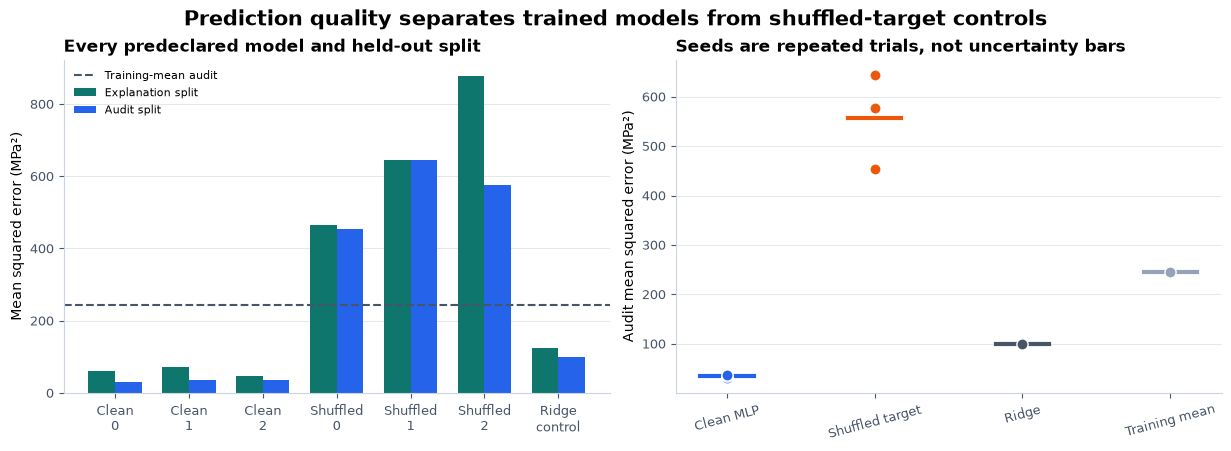

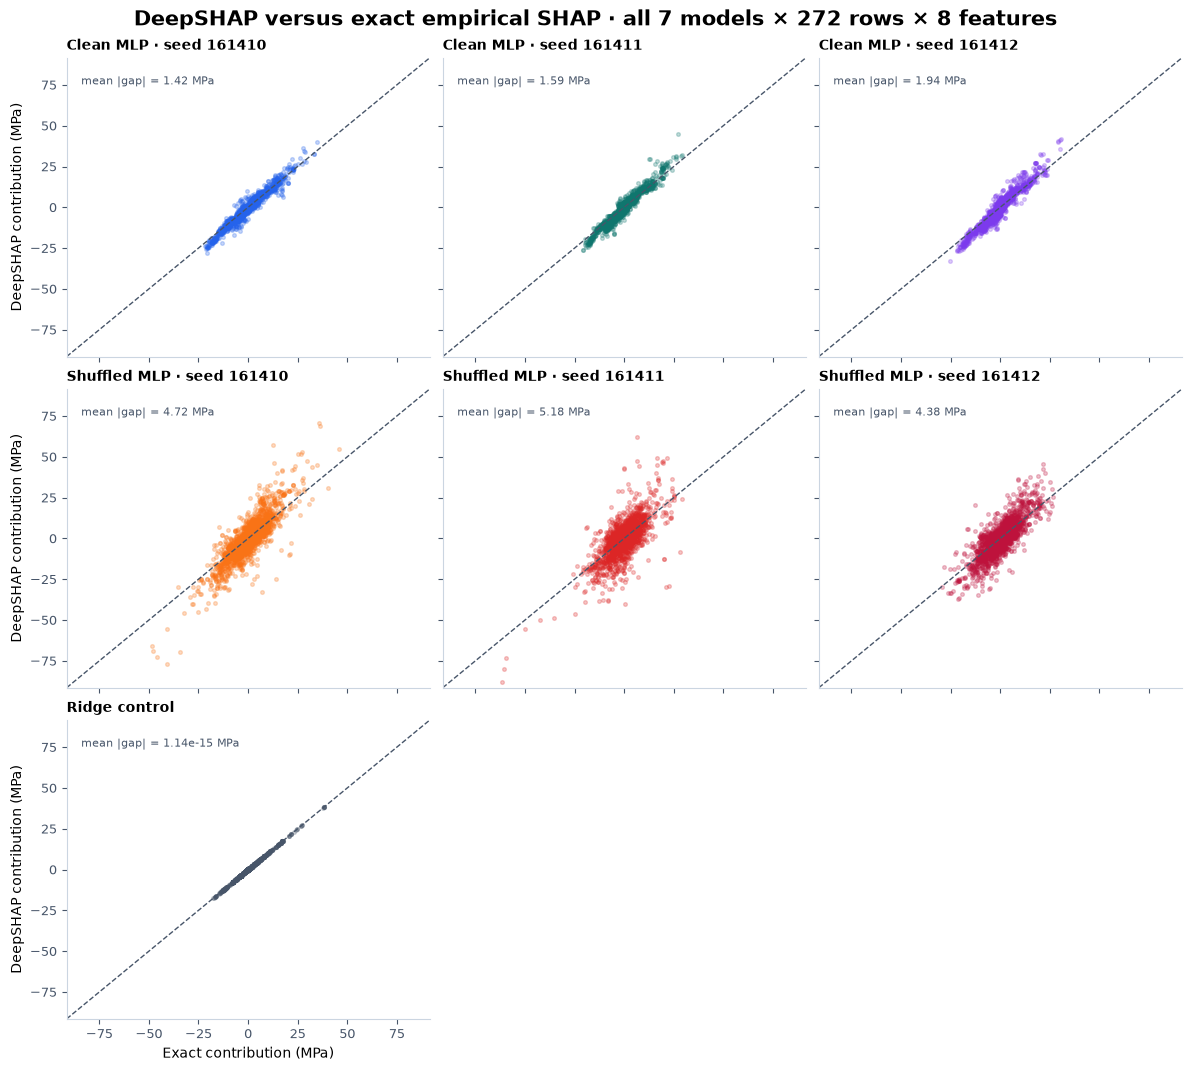

In [222]:
if MAIN:
    deep_show_figure(deep_plots.plot_performance(deep_prepared, deep_evaluated), "08_performance_controls")
if MAIN:
    deep_show_figure(deep_plots.plot_signed_parity(deep_prepared, deep_evaluated), "09_signed_parity_all_rows")

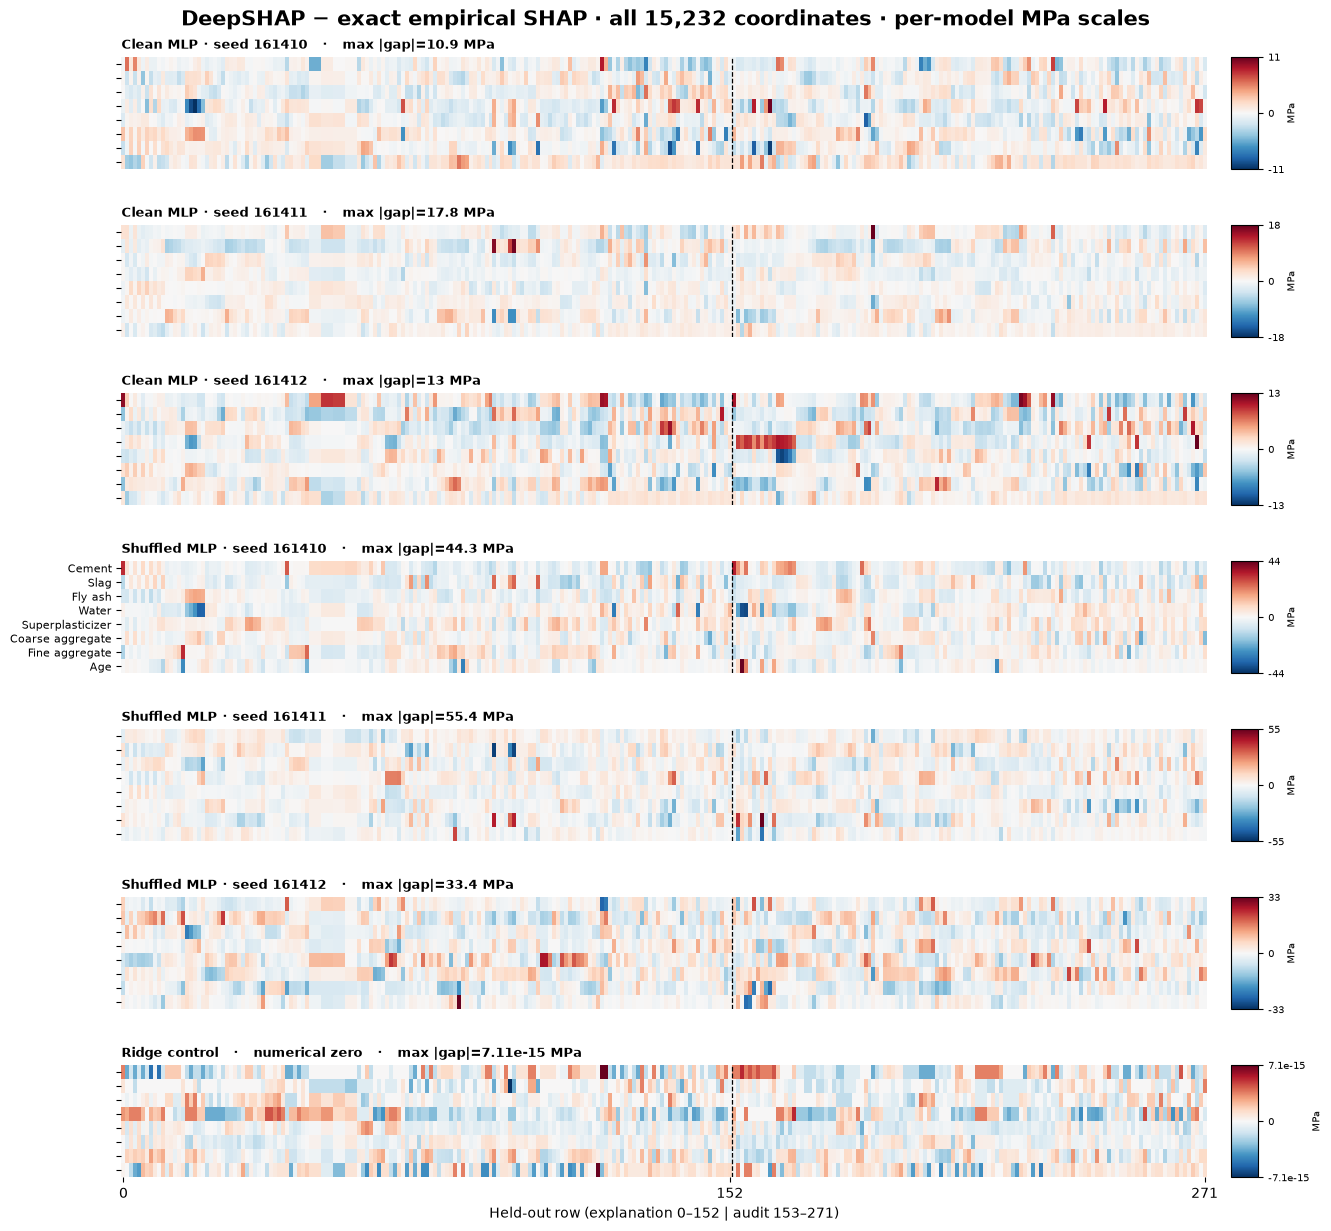

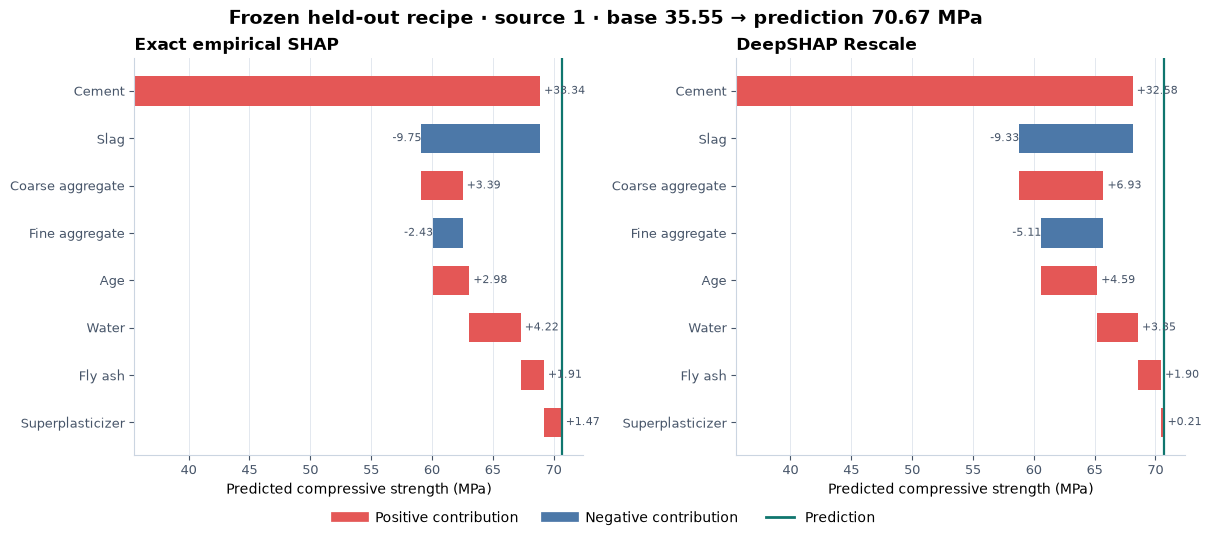

In [223]:
if MAIN:
    deep_show_figure(deep_plots.plot_error_heatmaps(deep_prepared, deep_evaluated), "10_error_heatmaps_all_rows")
if MAIN:
    deep_show_figure(
        deep_plots.plot_fixed_waterfall(deep_fixed_play, feature_names=deep_FEATURE_NAMES),
        "11_fixed_waterfall",
    )

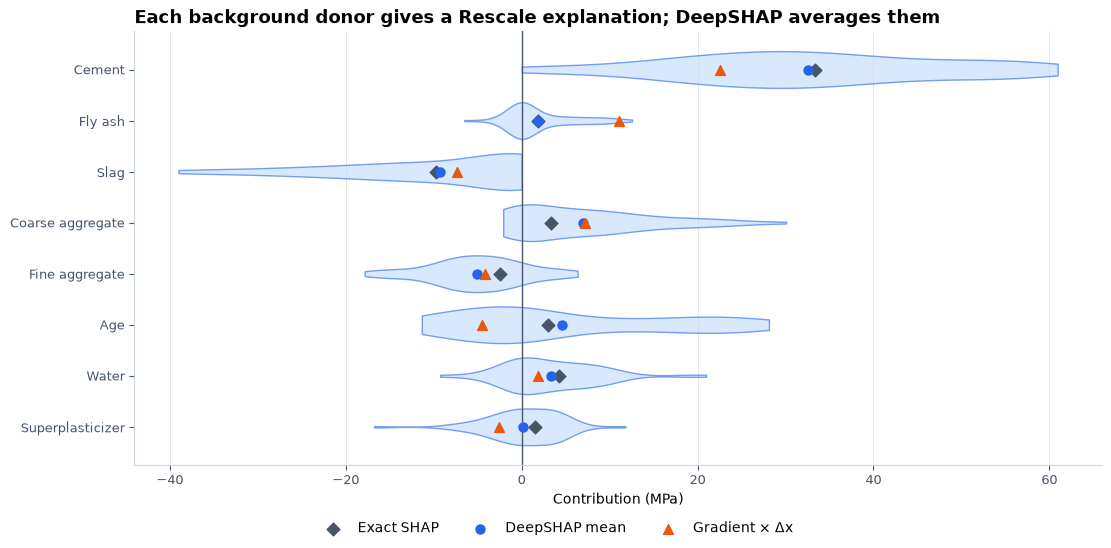

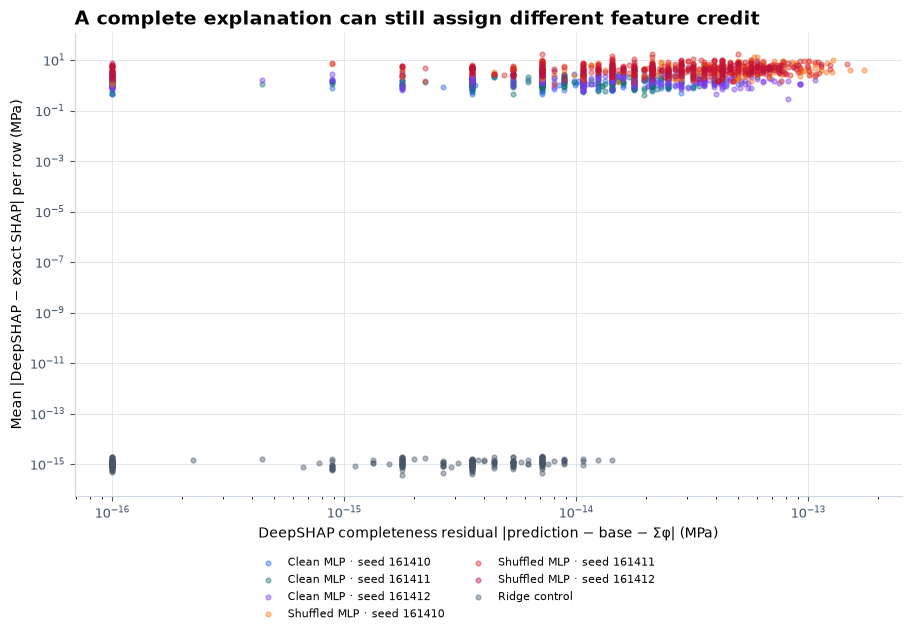

In [224]:
if MAIN:
    deep_show_figure(
        deep_plots.plot_fixed_attribution_comparison(deep_fixed_play, feature_names=deep_FEATURE_NAMES),
        "12_fixed_attribution_comparison",
    )
if MAIN:
    deep_show_figure(
        deep_plots.plot_completeness_vs_exact(deep_prepared, deep_evaluated),
        "13_completeness_vs_exact",
    )

### Three different questions about numerical validity

1. **Completeness:** does `base + phi.sum()` reproduce this model prediction? The finite-epsilon
near-zero control records its known exception rather than hiding it in a loose tolerance.
2. **Independent implementation parity:** does the student Rescale method agree with installed
`shap.DeepExplainer` on the explicitly supported affine/ReLU chain?
3. **Exact feature-game agreement:** does either implementation equal exhaustive Shapley for the
same donor background and all 256 coalitions?

A method can pass the first two and fail the third. Independent-library agreement checks our
implementation of DeepSHAP; exhaustive agreement checks DeepSHAP as an approximation to this game.

## Background sensitivity and replacement controls

Changing a finite background changes both the base value and the game. The background panel shows
DeepSHAP movement beside exact-oracle movement, so sampling sensitivity is not mislabeled as
composition error. The replacement panel then compares ranked prefixes in raw MPa. Exact attribution
does not guarantee a monotone or uniformly superior prefix curve; these curves are model-behavior
diagnostics.

For the primary clean model, moving from the 64-row background to nested 16/128 backgrounds changed
exact coordinates by `0.784`/`0.593` MPa on average; the two independent 64-row backgrounds changed
them by `0.942`/`0.759` MPa. Their base predictions ranged from `32.581` to `38.012` MPa. These
finite-background movements are large enough to interpret alongside, rather than underneath, the
`1.278`–`1.531` MPa mean approximation gaps across the five background designs.

On the primary clean model, exact and DeepSHAP global orders agree that cement comes first but swap
slag and age next. DeepSHAP's first two insertions produced an average oriented gain of `11.319`
MPa, versus `5.796` MPa for the exact order; both orders were identical after the third feature and
ended at `12.022` MPa. This is a useful negative result: a better early replacement curve is not
evidence that an attribution vector is closer to exact Shapley.

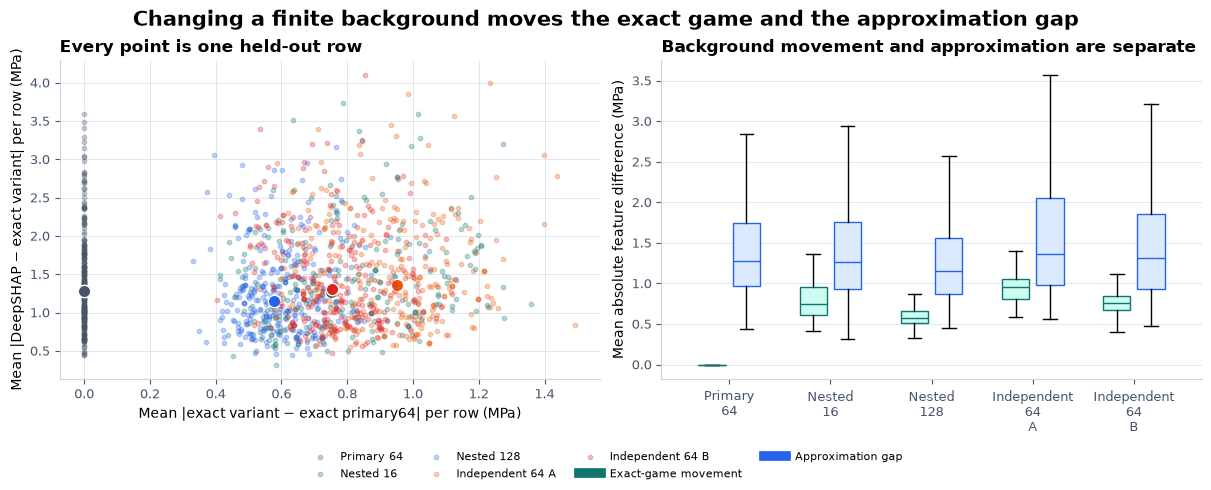

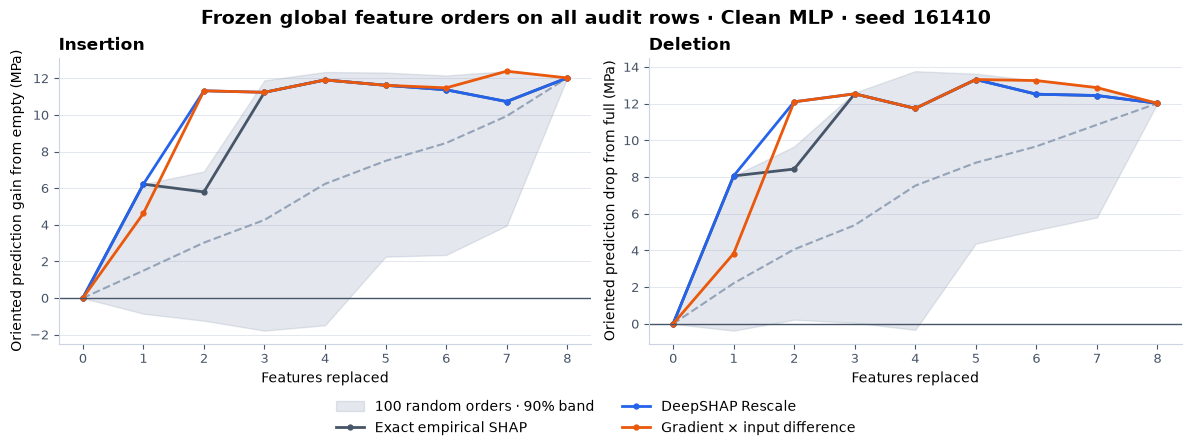

In [225]:
if MAIN:
    deep_show_figure(deep_plots.plot_background_sensitivity(deep_evaluated), "14_background_sensitivity")
if MAIN:
    deep_show_figure(deep_plots.plot_replacement_curves(deep_evaluated), "15_replacement_curves")

### Try It Yourself 2 — choose a recipe, model and background

The canonical first run uses `clean_0`, audit row 0 (source row 1) and the frozen 64-row background.
After reproducing that result, edit the arguments. The play recomputes the approximate explanation,
exact game and replacement curves rather than slicing a cached chart. Its curves use the local
per-row ordering from Exercise 9, oriented by `sign(f(x)-base)`. They are exploratory and distinct
from the primary experiment's frozen global explanation-split rankings.

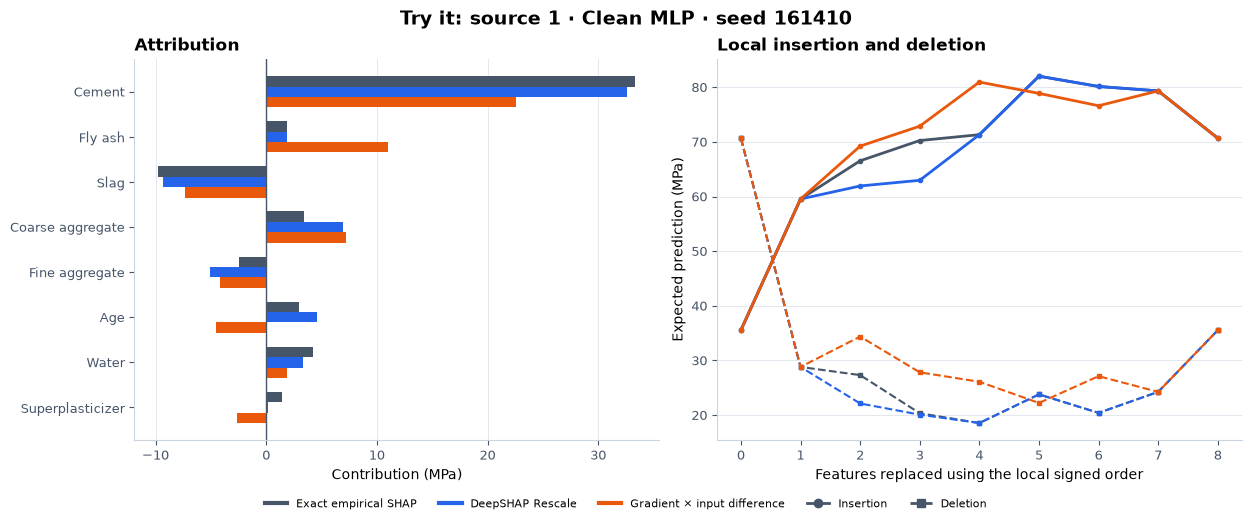

In [226]:
if MAIN:
    play = deep_native_play(
        deep_fitted,
        deep_train,
        deep_audit,
        deep_curriculum_methods,
        model_key="clean_0",
        row=0,
        size=64,
    )
if MAIN:
    deep_show_figure(
        deep_plots.plot_real_recipe_play(play, feature_names=deep_FEATURE_NAMES),
        "17_real_recipe_play",
    )

<details><summary>Ideas to try</summary>

- Compare `clean_0`, `clean_1`, `clean_2`, `shuffled_0` and `ridge` on the same source row.
- Keep the model and row fixed while changing the nested background size from 16 to 64 to 128.
- Find a row where the DeepSHAP and exact rankings agree even though their signed magnitudes differ.
- Find an overshooting deletion curve and inspect which interaction makes a replacement reverse the
expected direction.

These choices occur after audit evaluation. They are exploratory diagnostics and cannot support a
new confirmatory audit claim.

</details>

## How to interpret the study

Read the figures in this order:

1. Confirm that clean models beat the training-mean and shuffled-target controls. Attribution from
a model without held-out predictive skill does not rescue the predictor.
2. Require exact endpoint identities and full-vector parity with the exhaustive oracle for the
affine control. Then inspect independent DeepExplainer parity separately.
3. Check completeness and exact error side by side. Near-zero epsilon failure is a stated numerical
rule; larger exact errors with small completeness residuals are approximation behavior.
4. Compare all-row signed errors before the fixed-row waterfall. A waterfall explains where one
prediction came from; it does not establish a population pattern.
5. Read background movement beside exact movement, and replacement curves beside random-order
bands. Do not infer a universal method ranking from one model or overlapping curves.

For the concrete data, replacing one recorded quantity while borrowing the others from observed
training recipes creates synthetic model inputs. These are computational interventions on the
network. They are not randomized experiments on concrete production, and the empirical background is
not evidence that the attributions are physical causal effects.

## Limitations and method scope

The student method covers scalar affine/ReLU `nn.Sequential` chains with distinct modules. It
rejects convolution, pooling, softmax, multiplication, residual branches, shared modules,
normalization layers and custom operators. Current DeepSHAP libraries use backend-specific rules for
some additional components, and unsupported behavior can vary by backend. Agreement here should not
be generalized to an arbitrary PyTorch graph.

DeepSHAP is deterministic for a fixed model, query, background and epsilon. It is an approximation
to exact feature Shapley for a composed nonlinear graph, even when its local sum is exact. Exact
enumeration scales as $2^D$ and is available here only because the study has eight inputs. A finite
background approximates a chosen reference distribution and can move the answer materially.

RevealCancel explains one historical response to cancellation. It is not part of the taught DeepSHAP
core or the installed library comparison. Gradient-times-delta is a deterministic baseline, not
GradientSHAP or Expected Gradients; those methods require their own sampling and path-integral
lesson.

## Further research and anomaly hunting

- Characterize which ReLU activation patterns make Rescale equal exact input-feature Shapley.
- Construct functionally equivalent networks with increasingly different DeepSHAP allocations.
- Locate the smallest background for which ranking and signed-value conclusions stabilize, while
recomputing the exact oracle at every size.
- Extend the visible dispatcher by one operator and design an exact fixture that can falsify its
rule before applying it to a real model.
- Compare the finite-epsilon fallback with a scale-aware alternative without choosing its threshold
from audit errors.

## Reading

- Lundberg & Lee,
[*A Unified Approach to Interpreting Model Predictions*](https://arxiv.org/abs/1705.07874),
especially the Deep SHAP discussion and compositional approximation.
- Shrikumar, Greenside & Kundaje, [*Learning Important Features Through Propagating Activation
Differences*](https://arxiv.org/abs/1704.02685), plus its supplement for Rescale and RevealCancel.
- The current SHAP PyTorch DeepExplainer
[source](https://github.com/shap/shap/blob/master/shap/explainers/_deep/deep_pytorch.py) and
[documentation](https://shap.readthedocs.io/en/latest/generated/shap.DeepExplainer.html).
- Yeh, [*Concrete Compressive Strength*](https://doi.org/10.24432/C5PK67), the observational dataset
used for the held-out study.

# 3️⃣ Expected Gradients

> ##### Learning Objectives
>
> - Implement reproducible path schedules, gradients, sampled contributions and standard errors.
> - Compare quadrature and Monte Carlo estimates without equating paths with discrete Shapley.
> - Track target changes under noise, background choices and distance diagnostics.

## Expected Gradients: Which Expectation Does GradientSHAP Estimate?

> **Claim.** Expected Gradients can converge to a complete continuous-path attribution while
> disagreeing with exact Shapley values for the same finite background. Gaussian query noise changes
> the prediction target as well as the estimator.

## Core Question

Which expectation does a GradientSHAP implementation estimate, and how can we distinguish Monte
Carlo error from a different attribution target?

Start with the smallest useful example:

$$
f(z)=\operatorname{ReLU}(z),\qquad x=1,\qquad b=-1.
$$

At a uniformly sampled point $b+\alpha(x-b)$, the path contribution is

$$
C(\alpha)=(x-b)f'(b+\alpha(x-b))=
\begin{cases}
0,&\alpha<\tfrac12,\\
2,&\alpha>\tfrac12.
\end{cases}
$$

Thus one draw is a Bernoulli-valued estimate, even though the population attribution is exactly
$E[C]=1$. Its variance is 1 and the ordinary standard error of a $K$-draw mean is $1/\sqrt K$. A
finite explanation need not sum exactly to $f(x)-f(b)=1$; that residual is sampling error.

You will build this estimator from explicit donor and path schedules, then compare it with numerical
quadrature and exhaustive feature-coalition Shapley. The real study uses every held-out concrete
recipe and the same seven raw-MPa models as section 16.14. It runs on CPU in float64. Allow **4–6
hours**; Exercises 3–7 contain the core gradient, estimator and integration logic.

## Learning goals

By the end of the lab, you should be able to:

- derive Integrated Gradients and Expected Gradients from a straight-line path;
- create row-stable, prefix-stable donor and alpha schedules without mutating global RNG state;
- retain individual gradient-times-displacement samples before averaging them;
- compute the ordinary plug-in Monte Carlo standard error from an unbiased sample-variance
estimate, and explain what it does and does not measure;
- distinguish a full-background base from the sampled-donor average in one finite run;
- use all-background Gauss-Legendre quadrature as an approximate numerical control;
- prove that a complete path allocation can differ from discrete feature Shapley;
- explain why Gaussian query noise changes the target to a smoothed prediction;
- use global explanation-split rankings for audit replacement curves and local rankings only for
exploratory plays.

## Setup

The student implementation supports deterministic scalar-output PyTorch models that act
independently on each row. Tensors and model parameters use CPU float64. Explicit schedules make
sampling semantics reviewable and allow smaller budgets to be literal prefixes of larger ones.

In [227]:
if MAIN:
    import hashlib
if MAIN:
    import math
if MAIN:
    import os
if MAIN:
    import sys
if MAIN:
    from collections.abc import Mapping, Sequence
if MAIN:
    from pathlib import Path
if MAIN:
    from types import SimpleNamespace
if MAIN:
    from typing import Any

if MAIN:
    import matplotlib.pyplot as plt
if MAIN:
    import numpy as np
if MAIN:
    import torch
if MAIN:
    import torch as t
if MAIN:
    from IPython.display import display
if MAIN:
    from torch import Tensor, nn

if MAIN:
    torch.set_default_dtype(torch.float64)

gradient_chapter = "chapter16_shapley_attribution_baselines"
gradient_section = "part15_gradientshap"
if MAIN:
    gradient_root_dir = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path / gradient_chapter).exists())
if MAIN:
    gradient_exercises_dir = gradient_root_dir / gradient_chapter / "exercises"
if MAIN:
    gradient_section_dir = gradient_exercises_dir / gradient_section
if MAIN:
    if str(gradient_root_dir) not in sys.path:
        sys.path.append(str(gradient_root_dir))
    if str(gradient_exercises_dir) not in sys.path:
        sys.path.append(str(gradient_exercises_dir))

if MAIN:
    from chapter16_shapley_attribution_baselines.exercises.part3_model_specific_shap import gradient_gradientshap_methods_tests as gradient_tests
if MAIN:
    from chapter16_shapley_attribution_baselines.exercises.part3_model_specific_shap import gradient_gradientshap_plots as gradient_plots
if MAIN:
    from chapter16_shapley_attribution_baselines.exercises.part3_model_specific_shap.gradient_gradientshap_data import (
        background_order as gradient_background_order,
        load_manifest as load_manifest,
        load_split as gradient_load_split,
        tensor_mapping_sha256 as tensor_mapping_sha256,
    )

if MAIN:
    gradient_FEATURE_NAMES = np.array([
        "Cement", "Slag", "Fly ash", "Water", "Superplasticizer",
        "Coarse aggregate", "Fine aggregate", "Age",
    ])
if MAIN:
    gradient_RUN_OUTPUT = os.environ.get("ARENA_GRADIENTSHAP_OUTPUT_DIRECTORY")
if MAIN:
    gradient_FIGURE_DIR = Path(
        os.environ.get("ARENA_GRADIENTSHAP_FIGURE_DIR", gradient_RUN_OUTPUT or canonical_dir / "media" / 'gradient')
    )
if MAIN:
    gradient_SAVE_FIGURES = os.environ.get(
        "ARENA_GRADIENTSHAP_SAVE_FIGURES", "1" if gradient_RUN_OUTPUT else "0"
    ) == "1"


def gradient_show_figure(fig, stem):
    """Display a figure and optionally save the exact notebook rendering."""
    display(fig)
    if gradient_SAVE_FIGURES:
        gradient_FIGURE_DIR.mkdir(parents=True, exist_ok=True)
        fig.savefig(gradient_FIGURE_DIR / f"{stem}.png", dpi=180, bbox_inches="tight")
    plt.close(fig)

The named helpers below are mechanical tensor, model, schedule, and state validators. They check the
lesson's declared boundary but do not implement any attribution operation. Every Expected Gradients
method remains in the exercises.

### Visible supporting scientific function: `_eg_float_tensor`

In [228]:
if MAIN:
    from torch import Tensor, nn
if MAIN:
    import torch as t

def gradient_helper_gradientshap_methods__eg_float_tensor(name: str, value: Tensor, ndim: int | None = None) -> Tensor:
    """Check the lesson's CPU-float64 tensor contract without changing the value."""
    if type(value) is not Tensor:
        raise TypeError(f"{name} must be a torch.Tensor.")
    if value.device.type != "cpu" or value.dtype != t.float64:
        raise TypeError(f"{name} must be a CPU float64 tensor.")
    if ndim is not None and value.ndim != ndim:
        raise ValueError(f"{name} must have {ndim} dimensions.")
    if value.numel() == 0:
        raise ValueError(f"{name} cannot be empty.")
    if not t.isfinite(value).all():
        raise ValueError(f"{name} must contain only finite values.")
    return value

### Visible supporting scientific function: `_eg_index_tensor`

In [229]:
if MAIN:
    from torch import Tensor, nn
if MAIN:
    import torch as t

def gradient_helper_gradientshap_methods__eg_index_tensor(name: str, value: Tensor, ndim: int | None = None) -> Tensor:
    """Check a CPU int64 index tensor without coercing or aliasing it."""
    if type(value) is not Tensor:
        raise TypeError(f"{name} must be a torch.Tensor.")
    if value.device.type != "cpu" or value.dtype != t.int64:
        raise TypeError(f"{name} must be a CPU int64 tensor.")
    if ndim is not None and value.ndim != ndim:
        raise ValueError(f"{name} must have {ndim} dimensions.")
    if value.numel() == 0:
        raise ValueError(f"{name} cannot be empty.")
    return value

### Visible supporting scientific function: `_eg_model`

In [230]:
if MAIN:
    from torch import Tensor, nn
if MAIN:
    import torch as t

def gradient_helper_gradientshap_methods__eg_model(model: nn.Module) -> nn.Module:
    """Validate the CPU-float64 state used by the lesson's scalar models."""
    if not isinstance(model, nn.Module):
        raise TypeError("model must be a torch.nn.Module.")
    for parameter in model.parameters():
        if parameter.device.type != "cpu" or parameter.dtype != t.float64:
            raise TypeError("Every model parameter must be a CPU float64 tensor.")
        if not t.isfinite(parameter).all():
            raise ValueError("Every model parameter must be finite.")
    for buffer in model.buffers():
        if buffer.device.type != "cpu":
            raise TypeError("Every model buffer must be on CPU.")
        if buffer.is_floating_point():
            if buffer.dtype != t.float64:
                raise TypeError("Every floating model buffer must be float64.")
            if not t.isfinite(buffer).all():
                raise ValueError("Every floating model buffer must be finite.")
    return model

### Visible supporting scientific function: `_eg_model_output`

In [231]:
if MAIN:
    from torch import Tensor, nn
if MAIN:
    import torch as t

def gradient_helper_gradientshap_methods__eg_model_output(model: nn.Module, inputs: Tensor) -> Tensor:
    """Return one scalar per row; callers control whether gradients are enabled."""
    output = model(inputs)
    if type(output) is not Tensor:
        raise TypeError("The model must return a torch.Tensor.")
    if output.shape == (len(inputs), 1):
        output = output[:, 0]
    elif output.shape != (len(inputs),):
        raise ValueError("The model must return one scalar output per input row.")
    if output.device.type != "cpu" or output.dtype != t.float64:
        raise TypeError("The model must return CPU float64 outputs.")
    if not t.isfinite(output).all():
        raise ValueError("The model returned a nonfinite value.")
    return output

### Visible supporting scientific function: `_eg_positive_int`

In [232]:
def gradient_helper_gradientshap_methods__eg_positive_int(name: str, value: int) -> int:
    if type(value) is not int or value < 1:
        raise ValueError(f"{name} must be a positive integer.")
    return value

### Visible supporting scientific function: `_eg_preserve_execution_state`

In [233]:
if MAIN:
    from collections.abc import Iterator
if MAIN:
    import contextlib
if MAIN:
    from torch import Tensor, nn
if MAIN:
    import numpy as np
if MAIN:
    import random
if MAIN:
    import torch as t

def initialize_helper_gradient_3_5_gradient_helper_gradientshap_methods__eg_preserve_execution_state():
    global gradient_helper_gradientshap_methods__eg_preserve_execution_state
    @contextlib.contextmanager
    def gradient_helper_gradientshap_methods__eg_preserve_execution_state(model: nn.Module) -> Iterator[None]:
        """Restore global RNG, default dtype, module modes, buffers, and parameter grads."""
        python_state = random.getstate()
        numpy_state = np.random.get_state()
        torch_state = t.random.get_rng_state()
        default_dtype = t.get_default_dtype()
        module_modes = [(module, module.training) for module in model.modules()]
        buffers = [(buffer, buffer.detach().clone()) for buffer in model.buffers()]
        gradients = [
            (
                parameter,
                parameter.grad,
                None if parameter.grad is None else parameter.grad.detach().clone(),
            )
            for parameter in model.parameters()
        ]
        try:
            yield
        finally:
            random.setstate(python_state)
            np.random.set_state(numpy_state)
            t.random.set_rng_state(torch_state)
            t.set_default_dtype(default_dtype)
            for module, training in module_modes:
                module.training = training
            with t.no_grad():
                for buffer, saved in buffers:
                    buffer.copy_(saved)
                for parameter, original, saved in gradients:
                    if original is None:
                        parameter.grad = None
                    else:
                        parameter.grad = original
                        original.copy_(saved)


if MAIN:
    initialize_helper_gradient_3_5_gradient_helper_gradientshap_methods__eg_preserve_execution_state()

### Visible supporting scientific function: `_eg_seed_words`

In [234]:
if MAIN:
    import hashlib

def gradient_helper_gradientshap_methods__eg_seed_words(seed: int, source_id: int, stream_tag: str) -> int:
    """Derive one local 128-bit PCG64 seed from the declared lesson namespace."""
    name = f"arena16.15/gradientshap/v1/{seed}/{source_id}/{stream_tag}"
    return int.from_bytes(hashlib.sha256(name.encode()).digest()[:16], "little")

### Visible supporting scientific function: `_eg_validate_paths`

In [235]:
if MAIN:
    from torch import Tensor, nn

def gradient_helper_gradientshap_methods__eg_validate_paths(
    x: Tensor,
    background: Tensor,
    indices: Tensor,
    alpha: Tensor,
    noise: Tensor | None = None,
) -> tuple[int, int, int]:
    gradient_helper_gradientshap_methods__eg_float_tensor("x", x, 2)
    gradient_helper_gradientshap_methods__eg_float_tensor("background", background, 2)
    gradient_helper_gradientshap_methods__eg_index_tensor("indices", indices, 2)
    gradient_helper_gradientshap_methods__eg_float_tensor("alpha", alpha, 2)
    if x.shape[1] != background.shape[1]:
        raise ValueError("x and background must have the same feature dimension.")
    if indices.shape != alpha.shape or indices.shape[0] != len(x):
        raise ValueError("indices and alpha must both have shape (rows of x, samples).")
    if indices.min() < 0 or indices.max() >= len(background):
        raise ValueError("Every donor index must select a supplied background row.")
    if alpha.min() < 0 or alpha.max() > 1:
        raise ValueError("Every alpha must lie in the closed interval [0, 1].")
    n_rows, samples = indices.shape
    n_features = x.shape[1]
    if noise is not None:
        gradient_helper_gradientshap_methods__eg_float_tensor("noise", noise, 3)
        if noise.shape != (n_rows, samples, n_features):
            raise ValueError("noise must have shape (rows of x, samples, input features).")
    return n_rows, samples, n_features

In [236]:
if MAIN:
    _eg_float_tensor = gradient_helper_gradientshap_methods__eg_float_tensor
if MAIN:
    _eg_index_tensor = gradient_helper_gradientshap_methods__eg_index_tensor
if MAIN:
    _eg_model = gradient_helper_gradientshap_methods__eg_model
if MAIN:
    _eg_model_output = gradient_helper_gradientshap_methods__eg_model_output
if MAIN:
    _eg_positive_int = gradient_helper_gradientshap_methods__eg_positive_int
if MAIN:
    _eg_preserve_execution_state = gradient_helper_gradientshap_methods__eg_preserve_execution_state
if MAIN:
    _eg_seed_words = gradient_helper_gradientshap_methods__eg_seed_words
if MAIN:
    _eg_validate_paths = gradient_helper_gradientshap_methods__eg_validate_paths

Diagnostic fixtures construct literal affine, quadratic, ReLU and constant functions. Each staged
check resolves only methods already defined above it.

In [237]:
if MAIN:
    gradient_DTYPE = t.float64

def gradient__method(methods, name):
    if methods is None:
        gradientshap_methods = SimpleNamespace(**gradient_module_gradientshap_methods_namespace())

        candidate = getattr(gradientshap_methods, name)
    elif isinstance(methods, Mapping):
        candidate = methods.get(name)
    else:
        candidate = getattr(methods, name, None)
    if not callable(candidate):
        raise TypeError(
            f"Learner method namespace must provide a callable {name!r}; "
            "pass globals(), a mapping, or a SimpleNamespace built from the taught methods."
        )
    return candidate

def gradient__linear(weight, bias):
    weight = t.as_tensor(weight, dtype=gradient_DTYPE)
    bias = t.as_tensor(bias, dtype=gradient_DTYPE).reshape(-1)
    layer = nn.Linear(weight.shape[1], weight.shape[0], dtype=gradient_DTYPE)
    with t.no_grad():
        layer.weight.copy_(weight)
        layer.bias.copy_(bias)
    return layer

def gradient__prediction(model, rows):
    with t.no_grad():
        return model(rows).reshape(-1)

def gradient__max_abs(left, right):
    left = t.as_tensor(left, dtype=gradient_DTYPE)
    right = t.as_tensor(right, dtype=gradient_DTYPE)
    return float((left - right).abs().max())

def _relu_model():
    return nn.Sequential(gradient__linear([[1.0]], [0.0]), nn.ReLU()).eval()

def _threshold_model(weights=(2.0, 1.0), bias=-2.0):
    weights = t.as_tensor(weights, dtype=gradient_DTYPE).reshape(1, -1)
    return nn.Sequential(gradient__linear(weights, [bias]), nn.ReLU()).eval()

def _quadratic_model():
    class Quadratic(nn.Module):
        def forward(self, rows):
            return rows[:, 0].square()

    return Quadratic().eval()

def _two_feature_shapley(values):
    values = t.as_tensor(values, dtype=gradient_DTYPE).reshape(4)
    phi_0 = ((values[1] - values[0]) + (values[3] - values[2])) / 2
    phi_1 = ((values[2] - values[0]) + (values[3] - values[1])) / 2
    return t.stack((phi_0, phi_1))

## From Integrated Gradients to an expectation

For a differentiable scalar function $f:\mathbb R^D\to\mathbb R$, query $x$, and fixed baseline $b$,
straight-line Integrated Gradients is

$$
\operatorname{IG}_i(x;b)
=(x_i-b_i)\int_0^1
\frac{\partial f\bigl(b+\alpha(x-b)\bigr)}{\partial x_i}\,d\alpha.
$$

If the line-restricted function is absolutely continuous, the chain rule and fundamental theorem of
calculus give

$$
\begin{aligned}
f(x)-f(b)
&=\int_0^1 \frac{d}{d\alpha}f\bigl(b+\alpha(x-b)\bigr)\,d\alpha\\
&=\sum_i (x_i-b_i)\int_0^1
\partial_i f\bigl(b+\alpha(x-b)\bigr)\,d\alpha\\
&=\sum_i \operatorname{IG}_i(x;b).
\end{aligned}
$$

Expected Gradients also samples the baseline $B$:

$$
\operatorname{EG}_i(x;P_B)
=\mathbb E_{b\sim P_B,\,\alpha\sim U(0,1)}
\left[(x_i-b_i)\partial_i f\bigl(b+\alpha(x-b)\bigr)\right].
$$

For this lesson, $P_B$ is uniform over declared intact background rows. The expectation therefore
sums to $f(x)-\mathbb E_b[f(b)]$ under the same path regularity assumptions. A finite sample mean is
unbiased for this quantity, but it is not exactly complete draw by draw.

## 1️⃣ Build a reproducible path schedule

A schedule contains a donor index and one uniform $\alpha$ for every source row and draw. The
important invariant is stronger than ordinary seeded reproducibility: each source ID owns
independent donor and alpha streams. Therefore changing row order, row batching, or the maximum
budget does not change an existing row's prefix.

A single generator that first draws an `(N,K)` donor array and then an `(N,K)` alpha array violates
this invariant. Increasing `K` advances the generator farther before any alpha is drawn, so even the
old alpha prefix changes.

### Exercise 1 — `sample_path_schedule`

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵🔵
> 
> You should spend up to 20-30 minutes on this exercise.
> ```

Return CPU arrays `indices` and `alpha`, each with shape `(N,K)`. Donor indices are int64 in `[0,
background_rows)`; alphas are float64 in `[0,1)`. Derive separate local streams from the fixed seed,
source ID, and stream name. Never alter NumPy's global RNG.

In [238]:
def sample_path_schedule(
    source_ids: Tensor,
    background_rows: int,
    samples: int,
    seed: int,
) -> tuple[Tensor, Tensor]:
    """Draw donor indices and alphas from independent local streams for each source ID."""
    _eg_index_tensor("source_ids", source_ids, 1)
    background_rows = _eg_positive_int("background_rows", background_rows)
    samples = _eg_positive_int("samples", samples)
    if type(seed) is not int or seed < 0 or seed >= 2**64:
        raise ValueError("seed must be an integer in [0, 2**64).")
    if (source_ids < 0).any():
        raise ValueError("source_ids must be nonnegative integers.")
    if len(t.unique(source_ids)) != len(source_ids):
        raise ValueError("source_ids must be unique so every row names one sampling stream.")

    indices = np.empty((len(source_ids), samples), dtype=np.int64)
    alpha = np.empty((len(source_ids), samples), dtype=np.float64)
    for row, source_id in enumerate(source_ids.tolist()):
        donor_rng = np.random.Generator(
            np.random.PCG64(_eg_seed_words(seed, source_id, "baseline"))
        )
        alpha_rng = np.random.Generator(
            np.random.PCG64(_eg_seed_words(seed, source_id, "alpha"))
        )
        indices[row] = donor_rng.integers(0, background_rows, size=samples, dtype=np.int64)
        alpha[row] = alpha_rng.random(samples, dtype=np.float64)
    return t.tensor(indices, dtype=t.int64), t.tensor(alpha, dtype=t.float64)


if MAIN:
    gradient_tests.test_sample_path_schedule(sample_path_schedule)

All tests in test_sample_path_schedule passed!


In [239]:
def schedule_fixture():
    return {
        "source_ids": t.tensor([101, 305, 909], dtype=t.int64),
        "background_rows": 5,
        "short_samples": 8,
        "long_samples": 32,
        "seed": 161510,
    }

In [240]:
def diagnose_schedule(sample_path_schedule_fn):
    fixture = schedule_fixture()
    source_ids = fixture["source_ids"]
    args = (fixture["background_rows"], fixture["seed"])
    indices_8, alpha_8 = sample_path_schedule_fn(
        source_ids, args[0], fixture["short_samples"], args[1]
    )
    indices_32, alpha_32 = sample_path_schedule_fn(
        source_ids, args[0], fixture["long_samples"], args[1]
    )
    reordered = source_ids[t.tensor([2, 0], dtype=t.int64)]
    reorder_indices, reorder_alpha = sample_path_schedule_fn(
        reordered, args[0], fixture["short_samples"], args[1]
    )
    single_indices, single_alpha = sample_path_schedule_fn(
        source_ids[:1], args[0], fixture["short_samples"], args[1]
    )
    return {
        **fixture,
        "indices_8": indices_8,
        "alpha_8": alpha_8,
        "indices_32": indices_32,
        "alpha_32": alpha_32,
        "prefix_match": bool(
            t.equal(indices_8, indices_32[:, :8]) and t.equal(alpha_8, alpha_32[:, :8])
        ),
        "reorder_match": bool(
            t.equal(reorder_indices, indices_8[[2, 0]])
            and t.equal(reorder_alpha, alpha_8[[2, 0]])
        ),
        "single_row_match": bool(
            t.equal(single_indices, indices_8[:1]) and t.equal(single_alpha, alpha_8[:1])
        ),
    }

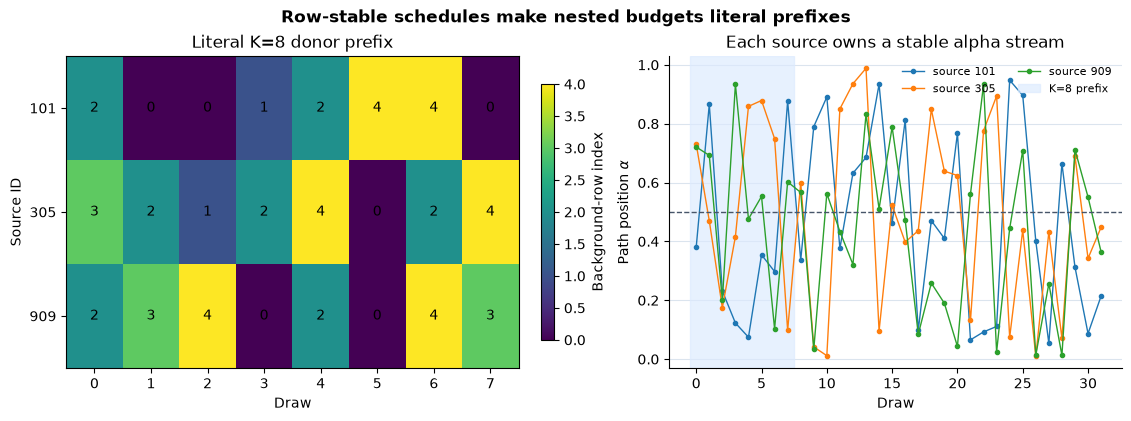

In [241]:
if MAIN:
    schedule_check = diagnose_schedule(sample_path_schedule)
if MAIN:
    gradient_show_figure(gradient_plots.plot_schedule_prefix(schedule_check), "01_schedule_prefix")

## 2️⃣ Interpolate both the point and displacement

For donor $b_k$, path position $\alpha_k$, and optional query perturbation $\epsilon_k$, define

$$
\tilde x_k=x+\epsilon_k,\qquad
p_k=b_k+\alpha_k(\tilde x_k-b_k),\qquad
\Delta_k=\tilde x_k-b_k.
$$

The gradient is evaluated at $p_k$ and multiplied by the same $\Delta_k$. Noise must appear in both
expressions. Perturbing the point while retaining the clean displacement computes a hybrid quantity
that is not the noisy Expected Gradients target.

### Exercise 2 — `interpolate_paths`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵🔵
> 
> You should spend up to 15-20 minutes on this exercise.
> ```

Gather donors using `indices`, broadcast each query across its draw axis, and return `(points,
deltas)` with shape `(N,K,D)`. With `noise=None`, use an exact zero perturbation without drawing any
random numbers.

In [242]:
def interpolate_paths(
    x: Tensor,
    background: Tensor,
    indices: Tensor,
    alpha: Tensor,
    noise: Tensor | None = None,
) -> tuple[Tensor, Tensor]:
    """Return sampled path points and query-minus-donor deltas, both shaped N,K,D."""
    _eg_validate_paths(x, background, indices, alpha, noise)
    donors = background[indices]
    query = x[:, None, :] if noise is None else x[:, None, :] + noise
    delta = query - donors
    points = donors + alpha[:, :, None] * delta
    return points, delta


if MAIN:
    gradient_tests.test_interpolate_paths(interpolate_paths)

All tests in test_interpolate_paths passed!


In [243]:
def path_fixture():
    return {
        "query": t.tensor([[2.0, 1.0]], dtype=gradient_DTYPE),
        "background": t.tensor([[-1.0, 0.0], [0.0, 2.0]], dtype=gradient_DTYPE),
        "indices": t.tensor([[0, 1, 0, 1]], dtype=t.int64),
        "alpha": t.tensor([[0.20, 0.35, 0.75, 0.90]], dtype=gradient_DTYPE),
    }

In [244]:
def diagnose_interpolation(interpolate_paths_fn):
    fixture = path_fixture()
    points, deltas = interpolate_paths_fn(
        fixture["query"],
        fixture["background"],
        fixture["indices"],
        fixture["alpha"],
    )
    donors = fixture["background"][fixture["indices"]]
    expected = donors + fixture["alpha"][..., None] * (fixture["query"][:, None, :] - donors)
    return {
        **fixture,
        "donors": donors,
        "points": points,
        "deltas": deltas,
        "expected_points": expected,
        "max_abs_error": gradient__max_abs(points, expected),
    }

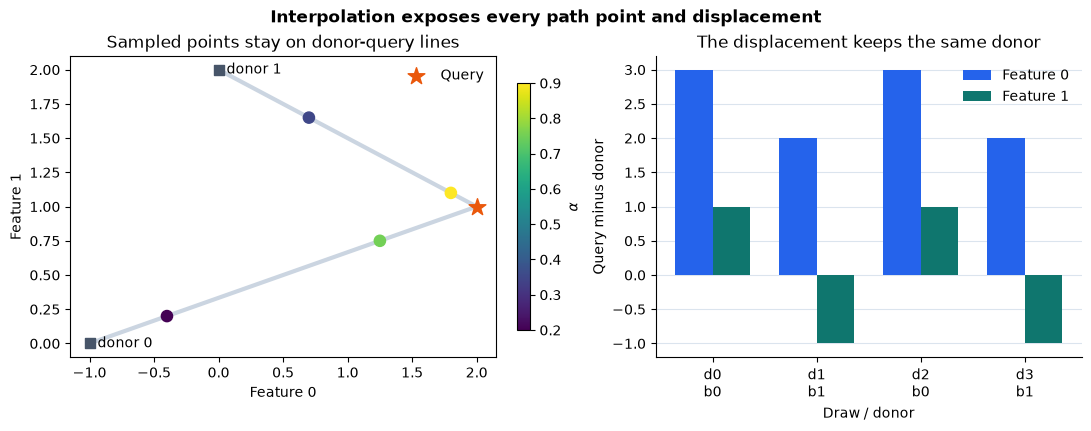

In [245]:
if MAIN:
    path_check = diagnose_interpolation(interpolate_paths)
if MAIN:
    gradient_show_figure(gradient_plots.plot_path_interpolation(path_check), "02_path_interpolation")

## 3️⃣ Differentiate a scalar row-wise model

Flattening `(N,K,D)` path points to `(N*K,D)` lets one backward call evaluate many samples. For a
model that applies the same scalar function independently to every row,

$$
\nabla_P\sum_r f(P_r)
=\bigl(\nabla f(P_1),\ldots,\nabla f(P_{NK})\bigr).
$$

The equality depends on row independence. Merely observing one scalar per row does not prove it for
a model with batch-dependent operations. This lesson validates a deliberately narrow graph before
using the sum-of-outputs trick.

The helper must also preserve the supported caller state: input storage, model training mode,
buffers, global RNG state, and any existing parameter gradients. The supported study models do not
mutate their parameter values during `forward`. The returned gradient is fresh CPU float64 storage.

### Exercise 3 — `input_gradients`

> ```yaml
> Difficulty: 🔴🔴🔴🔴⚪
> Importance: 🔵🔵🔵🔵🔵
> 
> You should spend up to 30-40 minutes on this exercise.
> ```

Differentiate the model in bounded `forward_batch` chunks and restore its original mode. Do not use
`loss.backward()`, which accumulates parameter gradients. Use `torch.autograd.grad` with respect to
a fresh point tensor.

In [246]:
def input_gradients(
    model: nn.Module,
    points: Tensor,
    forward_batch: int = 32_768,
) -> Tensor:
    """Differentiate a deterministic scalar function applied independently to each row.

    The sum-of-outputs gradient is valid only under that batch-independence assumption.
    This function preserves the caller's tensors, RNG states, model modes, buffers, and
    parameter gradients. A scalar function constant with respect to its input gets zero
    input gradients.
    """
    model = _eg_model(model)
    _eg_float_tensor("points", points, 3)
    forward_batch = _eg_positive_int("forward_batch", forward_batch)
    flat_points = points.reshape(-1, points.shape[-1])
    flat_gradients = t.empty_like(flat_points)

    with _eg_preserve_execution_state(model):
        for start in range(0, len(flat_points), forward_batch):
            chunk = flat_points[start : start + forward_batch].detach().clone().requires_grad_(True)
            with t.enable_grad():
                output = _eg_model_output(model, chunk)
                if output.requires_grad:
                    gradient = t.autograd.grad(output.sum(), chunk, allow_unused=True)[0]
                else:
                    gradient = None
            if gradient is None:
                gradient = t.zeros_like(chunk)
            if not t.isfinite(gradient).all():
                raise ValueError("The model produced a nonfinite input gradient.")
            flat_gradients[start : start + len(chunk)] = gradient.detach()
    return flat_gradients.reshape(points.shape)


if MAIN:
    gradient_tests.test_input_gradients(input_gradients)

All tests in test_input_gradients passed!


In [247]:
def gradient_fixture():
    affine = nn.Sequential(gradient__linear([[2.0, -3.0]], [0.5])).eval()
    affine_points = t.tensor(
        [[[-1.0, 0.0], [0.5, 2.0], [2.0, -1.0], [3.0, 3.0]]],
        dtype=gradient_DTYPE,
    )
    z = t.linspace(-1.0, 1.5, 21, dtype=gradient_DTYPE)
    return {
        "affine_model": affine,
        "affine_points": affine_points,
        "affine_expected": t.tensor([2.0, -3.0], dtype=gradient_DTYPE),
        "quadratic_model": _quadratic_model(),
        "quadratic_points": z.reshape(1, -1, 1),
        "quadratic_expected": (2 * z).reshape(1, -1, 1),
    }

In [248]:
def diagnose_gradients(input_gradients_fn):
    fixture = gradient_fixture()
    affine = input_gradients_fn(fixture["affine_model"], fixture["affine_points"])
    quadratic = input_gradients_fn(fixture["quadratic_model"], fixture["quadratic_points"])
    return {
        "affine_points": fixture["affine_points"],
        "affine_gradients": affine,
        "affine_expected": fixture["affine_expected"],
        "affine_max_abs_error": gradient__max_abs(affine, fixture["affine_expected"]),
        "quadratic_points": fixture["quadratic_points"],
        "quadratic_gradients": quadratic,
        "quadratic_expected": fixture["quadratic_expected"],
        "quadratic_max_abs_error": gradient__max_abs(quadratic, fixture["quadratic_expected"]),
    }

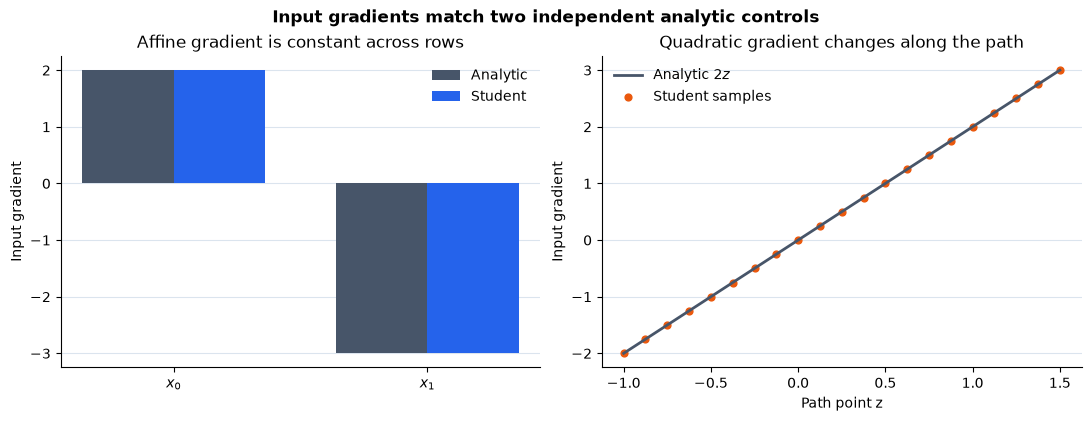

In [249]:
if MAIN:
    gradient_check = diagnose_gradients(input_gradients)
if MAIN:
    gradient_show_figure(gradient_plots.plot_gradient_controls(gradient_check), "03_gradient_controls")

## 4️⃣ Retain every Expected Gradients draw

For explicit schedule entries $(j_{nk},\alpha_{nk})$, choose donor $b_{nk}=B_{j_{nk}}$, form
$p_{nk}=b_{nk}+\alpha_{nk}(x_n-b_{nk})$, and retain

$$
C_{nki}=(x_{ni}-b_{nki})\partial_i f(p_{nk}).
$$

The estimator is the draw mean, but averaging here would throw away the evidence needed to measure
Monte Carlo uncertainty, inspect discrete samples, and reuse literal prefixes. This function returns
the full `(N,K,D)` contribution tensor.

For the opening ReLU, alphas `(0.25,0.75)` produce path points `(-0.5,0.5)`, gradients `(0,1)`, and
contributions `(0,2)`. For $f(z)=z^2$, $x=1$, $b=0$, the same alphas produce contributions
`(0.5,1.5)`. An endpoint-gradient implementation would return two in both quadratic draws and fail.

### Exercise 4 — `expected_gradient_samples`

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵🔵
> 
> You should spend up to 20-30 minutes on this exercise.
> ```

Compose `interpolate_paths` and `input_gradients`, then multiply gradients by displacements.
Preserve all draws and return fresh storage.

In [250]:
def expected_gradient_samples(
    model: nn.Module,
    x: Tensor,
    background: Tensor,
    indices: Tensor,
    alpha: Tensor,
    forward_batch: int = 32_768,
) -> Tensor:
    """Return clean Expected Gradients Monte Carlo contributions, shape N,K,D."""
    points, delta = interpolate_paths(x, background, indices, alpha)
    gradients = input_gradients(model, points, forward_batch)
    return gradients * delta


if MAIN:
    gradient_tests.test_expected_gradient_samples(expected_gradient_samples)

All tests in test_expected_gradient_samples passed!


In [251]:
def sample_fixture():
    return {
        "relu_model": _relu_model(),
        "relu_query": t.tensor([[1.0]], dtype=gradient_DTYPE),
        "relu_background": t.tensor([[-1.0]], dtype=gradient_DTYPE),
        "source_ids": t.tensor([17], dtype=t.int64),
        "samples": 128,
        "seed": 161510,
        "quadratic_model": _quadratic_model(),
        "quadratic_query": t.tensor([[1.0]], dtype=gradient_DTYPE),
        "quadratic_background": t.tensor([[0.0]], dtype=gradient_DTYPE),
        "quadratic_indices": t.tensor([[0, 0]], dtype=t.int64),
        "quadratic_alpha": t.tensor([[0.25, 0.75]], dtype=gradient_DTYPE),
    }

In [252]:
def diagnose_expected_gradient_samples(
    expected_gradient_samples_fn,
    sample_path_schedule_fn,
):
    fixture = sample_fixture()
    indices, alpha = sample_path_schedule_fn(
        fixture["source_ids"], 1, fixture["samples"], fixture["seed"]
    )
    relu_samples = expected_gradient_samples_fn(
        fixture["relu_model"],
        fixture["relu_query"],
        fixture["relu_background"],
        indices,
        alpha,
    )
    quadratic_samples = expected_gradient_samples_fn(
        fixture["quadratic_model"],
        fixture["quadratic_query"],
        fixture["quadratic_background"],
        fixture["quadratic_indices"],
        fixture["quadratic_alpha"],
    )
    relu_expected = (alpha > 0.5).to(gradient_DTYPE)[..., None] * 2.0
    quadratic_expected = (2 * fixture["quadratic_alpha"])[..., None]
    return {
        "alpha": alpha,
        "relu_samples": relu_samples,
        "relu_expected": relu_expected,
        "relu_max_abs_error": gradient__max_abs(relu_samples, relu_expected),
        "quadratic_alpha": fixture["quadratic_alpha"],
        "quadratic_samples": quadratic_samples,
        "quadratic_expected": quadratic_expected,
        "quadratic_max_abs_error": gradient__max_abs(quadratic_samples, quadratic_expected),
        "population_mean": t.tensor(1.0, dtype=gradient_DTYPE),
        "population_variance": t.tensor(1.0, dtype=gradient_DTYPE),
    }

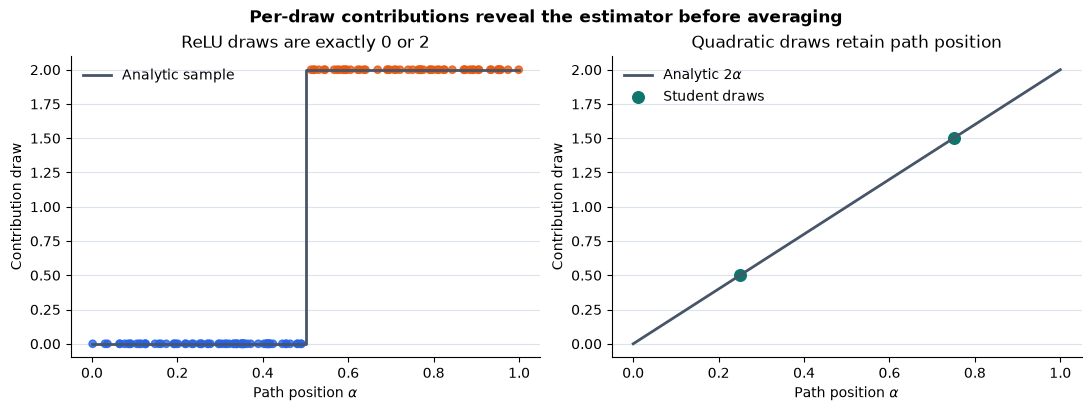

In [253]:
if MAIN:
    sample_check = diagnose_expected_gradient_samples(
        expected_gradient_samples,
        sample_path_schedule,
    )
if MAIN:
    gradient_show_figure(gradient_plots.plot_relu_samples(sample_check), "04_relu_samples")

## 5️⃣ Estimate a mean and its Monte Carlo standard error

For one feature coordinate with draws $C_1,\ldots,C_K$, define

$$
\widehat\phi_K=\frac1K\sum_{k=1}^K C_k,
\qquad
s_K^2=\frac1{K-1}\sum_{k=1}^K(C_k-\widehat\phi_K)^2,
\qquad
\widehat{\operatorname{SE}}_K=\frac{s_K}{\sqrt K}.
$$

The `K-1` denominator makes $s_K^2$ the unbiased sample-variance estimator. The standard error
estimates variability of the sample mean under repeated schedules. It is not a standard deviation of
feature importance, a model confidence interval, or a bound on error against exact coalition
Shapley. Coordinates also share donor and alpha draws, so their errors are correlated.

Nested budgets use literal prefixes of the same contribution tensor. That pairing makes a running
plot interpretable: only additional draws change the estimate.

### Exercise 5 — `summarize_expected_gradients`

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵🔵
> 
> You should spend up to 20-30 minutes on this exercise.
> ```

For every requested budget, return the prefix mean and ordinary standard error. Validate increasing,
unique budgets that fit inside the draw axis. Do not use SHAP's package-reported uncertainty field;
we will inspect its different formula later.

In [254]:
def summarize_expected_gradients(
    samples: Tensor,
    budgets: tuple[int, ...],
) -> tuple[Tensor, Tensor]:
    """Return ordinary sample SE, not SHAP 0.49.1's variance/sqrt(K) proxy."""
    _eg_float_tensor("samples", samples, 3)
    if type(budgets) is not tuple or not budgets:
        raise TypeError("budgets must be a nonempty tuple of sample counts.")
    if any(type(budget) is not int for budget in budgets):
        raise TypeError("Every budget must be an integer sample count.")
    if any(budget < 2 or budget > samples.shape[1] for budget in budgets):
        raise ValueError("Every budget must be between 2 and the available sample count.")
    if any(left >= right for left, right in zip(budgets, budgets[1:])):
        raise ValueError("budgets must be strictly increasing nested prefixes.")

    means, standard_errors = [], []
    for budget in budgets:
        prefix = samples[:, :budget]
        means.append(prefix.mean(dim=1))
        standard_errors.append(prefix.std(dim=1, correction=1) / math.sqrt(budget))
    return t.stack(means), t.stack(standard_errors)


if MAIN:
    gradient_tests.test_summarize_expected_gradients(summarize_expected_gradients)

All tests in test_summarize_expected_gradients passed!


In [255]:
def diagnose_convergence(
    sample_path_schedule_fn,
    expected_gradient_samples_fn,
    summarize_expected_gradients_fn,
):
    fixture = sample_fixture()
    indices, alpha = sample_path_schedule_fn(
        fixture["source_ids"], 1, fixture["samples"], fixture["seed"]
    )
    samples = expected_gradient_samples_fn(
        fixture["relu_model"],
        fixture["relu_query"],
        fixture["relu_background"],
        indices,
        alpha,
    )
    budgets = (2, 4, 8, 16, 32, 64, 128)
    means, standard_errors = summarize_expected_gradients_fn(samples, budgets)
    budget_tensor = t.tensor(budgets, dtype=gradient_DTYPE)
    return {
        "budgets": t.tensor(budgets, dtype=t.int64),
        "means": means[:, 0, 0],
        "standard_errors": standard_errors[:, 0, 0],
        "population_mean": t.tensor(1.0, dtype=gradient_DTYPE),
        "analytic_standard_error": budget_tensor.rsqrt(),
        "absolute_error": (means[:, 0, 0] - 1.0).abs(),
        "samples": samples,
    }

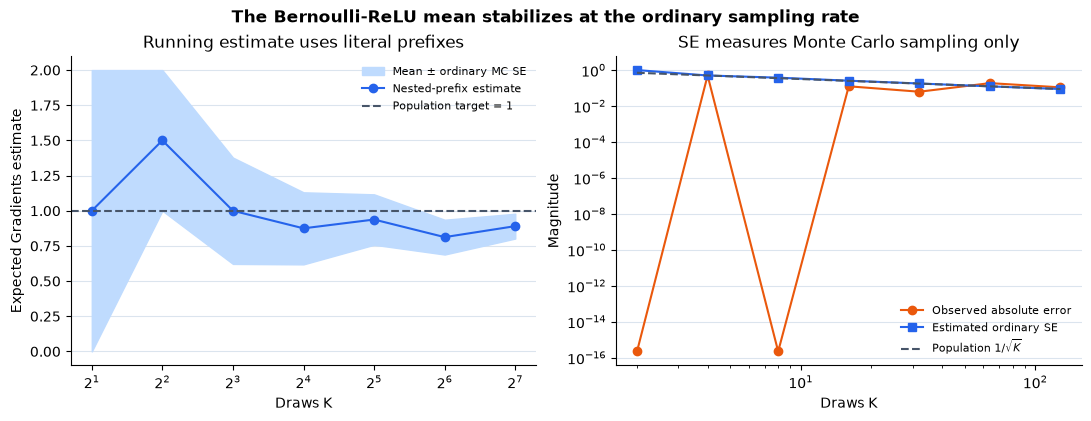

In [256]:
if MAIN:
    convergence_check = diagnose_convergence(
        sample_path_schedule,
        expected_gradient_samples,
        summarize_expected_gradients,
    )
if MAIN:
    gradient_show_figure(gradient_plots.plot_mc_convergence(convergence_check), "05_mc_convergence")

The running estimate should wander between the two possible ReLU contributions before stabilizing
near one. The band is labeled **ordinary Monte Carlo SE** because that is the only uncertainty it
represents. Erion et al. found 100–200 samples adequate on their benchmarks; that empirical result
is not a universal stopping rule for this model or dataset.

## 6️⃣ Report the finite estimate against its actual base

The finite empirical-background target is

$$
\phi_0(B)=\frac1{|B|}\sum_{b\in B}f(b),
\qquad
\phi_0(B)+\sum_i\operatorname{EG}_i(x;B)=f(x).
$$

`expected_gradients` reports the deterministic full-background base, the finite draw mean, and its
ordinary SE. The finite residual

$$
r_K=\phi_0(B)+\sum_i\widehat\phi_{K,i}-f(x)
$$

contains both donor-sampling and alpha-sampling error. Replacing the base by the sampled donors'
mean prediction can make one component disappear from a diagnostic while silently changing the
quantity being checked.

### Exercise 6 — `expected_gradients`

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵🔵
> 
> You should spend up to 20-30 minutes on this exercise.
> ```

Compose your per-draw estimator, average the draw axis, compute the ordinary SE, and evaluate the
model on every supplied background row for the base. Return all declared fields without mutating the
inputs or the supported model execution state.

In [257]:
def expected_gradients(
    model: nn.Module,
    x: Tensor,
    background: Tensor,
    indices: Tensor,
    alpha: Tensor,
    forward_batch: int = 32_768,
) -> tuple[Tensor, Tensor, Tensor]:
    """Return full-background base, clean Expected Gradients, and ordinary estimator SE."""
    _, samples, _ = _eg_validate_paths(x, background, indices, alpha)
    if samples < 2:
        raise ValueError(
            "Expected Gradients needs at least two samples to estimate standard error."
        )
    contributions = expected_gradient_samples(
        model, x, background, indices, alpha, forward_batch
    )
    means, standard_errors = summarize_expected_gradients(contributions, (samples,))
    model = _eg_model(model)
    with _eg_preserve_execution_state(model), t.no_grad():
        base = _eg_model_output(model, background).mean().detach().clone()
    return base, means[0], standard_errors[0]


if MAIN:
    gradient_tests.test_expected_gradients(expected_gradients)

All tests in test_expected_gradients passed!


In [258]:
def estimator_fixture():
    affine = nn.Sequential(gradient__linear([[2.0, -3.0]], [0.5])).eval()
    dummy = nn.Sequential(gradient__linear([[2.0, -3.0, 0.0]], [0.5])).eval()
    constant = nn.Sequential(gradient__linear([[0.0, 0.0]], [2.0])).eval()
    return {
        "affine_model": affine,
        "affine_query": t.tensor([[2.0, 1.0]], dtype=gradient_DTYPE),
        "affine_background": t.tensor([[0.0, 0.0], [1.0, 2.0]], dtype=gradient_DTYPE),
        "balanced_indices": t.tensor([[0, 1, 0, 1]], dtype=t.int64),
        "balanced_alpha": t.tensor([[0.15, 0.35, 0.65, 0.85]], dtype=gradient_DTYPE),
        "affine_expected_phi": t.tensor([[3.0, 0.0]], dtype=gradient_DTYPE),
        "dummy_model": dummy,
        "dummy_query": t.tensor([[2.0, 1.0, 9.0]], dtype=gradient_DTYPE),
        "dummy_background": t.tensor([[0.0, 0.0, -5.0], [1.0, 2.0, 7.0]], dtype=gradient_DTYPE),
        "constant_model": constant,
        "relu_model": _relu_model(),
        "relu_query": t.tensor([[1.0]], dtype=gradient_DTYPE),
        "relu_background": t.tensor([[-1.0]], dtype=gradient_DTYPE),
        "relu_indices": t.zeros((1, 5), dtype=t.int64),
        "relu_alpha": t.tensor([[0.10, 0.20, 0.30, 0.40, 0.60]], dtype=gradient_DTYPE),
    }

In [259]:
def diagnose_expected_gradients(expected_gradients_fn, sample_path_schedule_fn):
    fixture = estimator_fixture()
    affine_base, affine_phi, affine_se = expected_gradients_fn(
        fixture["affine_model"],
        fixture["affine_query"],
        fixture["affine_background"],
        fixture["balanced_indices"],
        fixture["balanced_alpha"],
    )
    scheduled_indices, scheduled_alpha = sample_path_schedule_fn(
        t.tensor([41], dtype=t.int64), 2, 32, 161510
    )
    dummy_base, dummy_phi, dummy_se = expected_gradients_fn(
        fixture["dummy_model"],
        fixture["dummy_query"],
        fixture["dummy_background"],
        scheduled_indices,
        scheduled_alpha,
    )
    constant_base, constant_phi, constant_se = expected_gradients_fn(
        fixture["constant_model"],
        fixture["affine_query"],
        fixture["affine_background"],
        scheduled_indices,
        scheduled_alpha,
    )
    relu_base, relu_phi, relu_se = expected_gradients_fn(
        fixture["relu_model"],
        fixture["relu_query"],
        fixture["relu_background"],
        fixture["relu_indices"],
        fixture["relu_alpha"],
    )

    def result(model, query, base, phi, se):
        prediction = gradient__prediction(model, query)[0]
        return {
            "base": base,
            "phi": phi,
            "standard_error": se,
            "prediction": prediction,
            "reconstruction": base + phi.sum(),
            "residual": base + phi.sum() - prediction,
        }

    return {
        "affine": result(
            fixture["affine_model"],
            fixture["affine_query"],
            affine_base,
            affine_phi,
            affine_se,
        ),
        "dummy": result(
            fixture["dummy_model"],
            fixture["dummy_query"],
            dummy_base,
            dummy_phi,
            dummy_se,
        ),
        "constant": result(
            fixture["constant_model"],
            fixture["affine_query"],
            constant_base,
            constant_phi,
            constant_se,
        ),
        "finite_relu": result(
            fixture["relu_model"],
            fixture["relu_query"],
            relu_base,
            relu_phi,
            relu_se,
        ),
        "affine_expected_phi": fixture["affine_expected_phi"],
        "affine_max_abs_error": gradient__max_abs(affine_phi, fixture["affine_expected_phi"]),
        "dummy_max_abs": float(dummy_phi[:, 2].abs().max()),
        "constant_max_abs": float(constant_phi.abs().max()),
    }

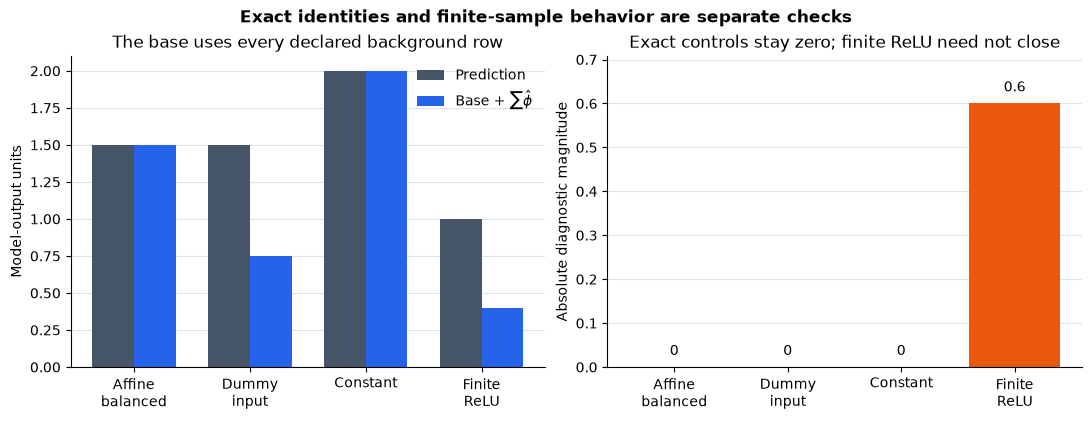

In [260]:
if MAIN:
    estimator_check = diagnose_expected_gradients(
        expected_gradients,
        sample_path_schedule,
    )
if MAIN:
    gradient_show_figure(gradient_plots.plot_estimator_controls(estimator_check), "06_estimator_controls")

## 7️⃣ Replace random alpha draws with bounded quadrature

Monte Carlo sampling is the main estimator, but a deterministic alpha-integration control helps us
measure its error. Let $(q_\ell,w_\ell)$ be Gauss-Legendre nodes and weights on `[-1,1]`. Mapping

$$
\alpha_\ell=\frac{q_\ell+1}{2},\qquad \omega_\ell=\frac{w_\ell}{2}
$$

gives the pairwise approximation

$$
\widehat{\operatorname{IG}}_i(x;b)
=(x_i-b_i)\sum_{\ell=1}^{L}\omega_\ell
\partial_i f\bigl(b+\alpha_\ell(x-b)\bigr).
$$

Evaluate every query against every intact donor, returning `(N,B,D)` pair attributions. Averaging
that donor axis removes donor-sampling variation, while doubling the node count tests alpha
integration drift.

This remains numerical quadrature. A ReLU path has a step-discontinuous gradient at each kink, so
finite Gauss-Legendre integration is not an exact oracle. It is exact for the affine fixture and
should integrate the quadratic fixture to floating-point precision; for piecewise-linear networks,
report the 256-to-512-node change rather than declaring 512 exact.

### Exercise 7 — `gauss_legendre_pairs`

> ```yaml
> Difficulty: 🔴🔴🔴🔴⚪
> Importance: 🔵🔵🔵🔵🔵
> 
> You should spend up to 35-50 minutes on this exercise.
> ```

Construct nodes with NumPy, map them to `[0,1]`, and evaluate all query/donor paths in bounded row
and forward batches. Multiply the weighted average gradient by each query-minus-donor displacement.

In [261]:
def gauss_legendre_pairs(
    model: nn.Module,
    x: Tensor,
    background: Tensor,
    n_nodes: int,
    row_batch: int = 4,
    forward_batch: int = 32_768,
) -> Tensor:
    """Approximate every query-donor Integrated Gradients path by finite quadrature.

    ReLU path gradients jump, so finite-node quadrature remains a numerical control
    rather than exact path truth.
    """
    model = _eg_model(model)
    _eg_float_tensor("x", x, 2)
    _eg_float_tensor("background", background, 2)
    if x.shape[1] != background.shape[1]:
        raise ValueError("x and background must have the same feature dimension.")
    n_nodes = _eg_positive_int("n_nodes", n_nodes)
    row_batch = _eg_positive_int("row_batch", row_batch)
    forward_batch = _eg_positive_int("forward_batch", forward_batch)

    raw_nodes, raw_weights = np.polynomial.legendre.leggauss(n_nodes)
    nodes = t.tensor((raw_nodes + 1) / 2, dtype=t.float64)
    weights = t.tensor(raw_weights / 2, dtype=t.float64)
    pairs = t.empty((len(x), len(background), x.shape[1]), dtype=t.float64)

    for start in range(0, len(x), row_batch):
        query = x[start : start + row_batch]
        delta = query[:, None, :] - background[None, :, :]
        points = background[None, :, None, :] + nodes[None, None, :, None] * delta[:, :, None, :]
        packed = points.reshape(len(query), len(background) * n_nodes, x.shape[1])
        gradients = input_gradients(model, packed, forward_batch).reshape(points.shape)
        mean_gradient = (gradients * weights[None, None, :, None]).sum(dim=2)
        pairs[start : start + len(query)] = mean_gradient * delta
    return pairs


if MAIN:
    gradient_tests.test_gauss_legendre_pairs(gauss_legendre_pairs)

All tests in test_gauss_legendre_pairs passed!


In [262]:
def quadrature_fixture():
    return {
        "relu_model": _relu_model(),
        "query": t.tensor([[1.0]], dtype=gradient_DTYPE),
        "background": t.tensor([[-2.0]], dtype=gradient_DTYPE),
        "nodes": (4, 8, 16, 32, 64, 128, 256, 512),
        "analytic": t.tensor(1.0, dtype=gradient_DTYPE),
        "quadratic_model": _quadratic_model(),
        "quadratic_query": t.tensor([[1.0]], dtype=gradient_DTYPE),
        "quadratic_background": t.tensor([[0.0]], dtype=gradient_DTYPE),
    }

In [263]:
def diagnose_quadrature(gauss_legendre_pairs_fn, input_gradients_fn):
    fixture = quadrature_fixture()
    estimates = []
    for nodes in fixture["nodes"]:
        pair = gauss_legendre_pairs_fn(
            fixture["relu_model"], fixture["query"], fixture["background"], nodes
        )
        estimates.append(pair[0, 0, 0])
    estimates = t.stack(estimates)
    quadratic = gauss_legendre_pairs_fn(
        fixture["quadratic_model"],
        fixture["quadratic_query"],
        fixture["quadratic_background"],
        2,
    )[0, 0, 0]
    probe_points = t.tensor([[[-0.5], [0.25], [1.0]]], dtype=gradient_DTYPE)
    probe_gradients = input_gradients_fn(fixture["quadratic_model"], probe_points)
    return {
        "nodes": t.tensor(fixture["nodes"], dtype=t.int64),
        "relu_estimates": estimates,
        "analytic": fixture["analytic"],
        "absolute_error": (estimates - fixture["analytic"]).abs(),
        "successive_drift": t.cat((t.zeros(1, dtype=gradient_DTYPE), estimates.diff().abs())),
        "quadratic_n2": quadratic,
        "quadratic_error": float(abs(quadratic - 1.0)),
        "quadratic_probe_gradients": probe_gradients,
        "quadratic_probe_expected": 2 * probe_points,
    }

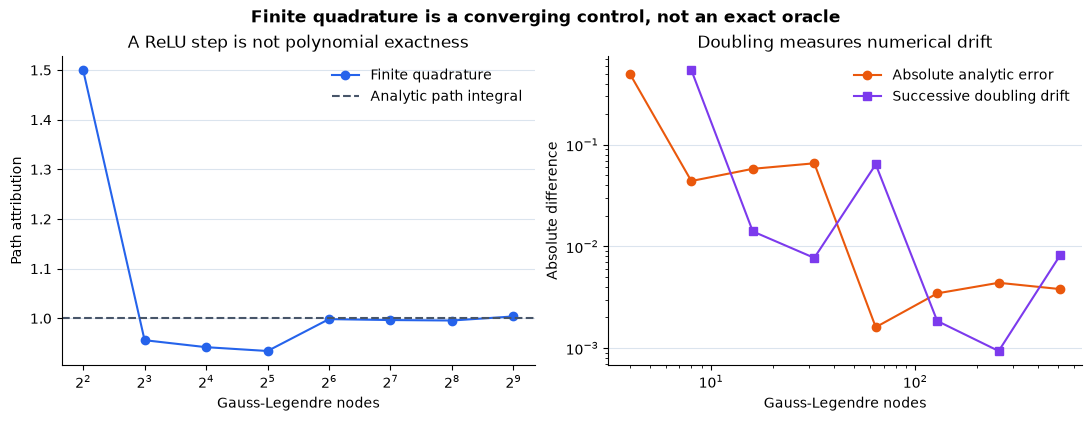

In [264]:
if MAIN:
    quadrature_check = diagnose_quadrature(
        gauss_legendre_pairs,
        input_gradients,
    )
if MAIN:
    gradient_show_figure(gradient_plots.plot_quadrature_doubling(quadrature_check), "07_quadrature_doubling")

### Why averaging attributions is not using the mean baseline

For $f(z)=\operatorname{ReLU}(z)$, $x=2$, and background `(-2,1)`, the two complete path
attributions are `(2,1)`. Their average is `1.5`, and the full-background base is `mean(0,1)=0.5`,
so `0.5+1.5=2`. The mean baseline is `-0.5`, whose single path attribution is `2`. Nonlinearity sits
inside the baseline average:

$$
\mathbb E_b[\operatorname{IG}(x;b)]
\ne \operatorname{IG}(x;\mathbb E[b]).
$$

In [265]:
def gradient_diagnose_background_average(gauss_legendre_pairs_fn):
    model = _relu_model()
    query = t.tensor([[2.0]], dtype=gradient_DTYPE)
    background = t.tensor([[-2.0], [1.0]], dtype=gradient_DTYPE)
    mean_background = background.mean(dim=0, keepdim=True)
    pair_256 = gauss_legendre_pairs_fn(model, query, background, 256)[0, :, 0]
    pair_512 = gauss_legendre_pairs_fn(model, query, background, 512)[0, :, 0]
    mean_reference_512 = gauss_legendre_pairs_fn(model, query, mean_background, 512)[0, 0, 0]
    return {
        "background": background[:, 0],
        "pair_256": pair_256,
        "pair_512": pair_512,
        "pair_expected": t.tensor([2.0, 1.0], dtype=gradient_DTYPE),
        "mean_pair": pair_512.mean(),
        "mean_reference": mean_reference_512,
        "expected_mean_pair": t.tensor(1.5, dtype=gradient_DTYPE),
        "expected_mean_reference": t.tensor(2.0, dtype=gradient_DTYPE),
        "base": gradient__prediction(model, background).mean(),
        "mean_reference_base": gradient__prediction(model, mean_background)[0],
        "quadrature_drift": (pair_512 - pair_256).abs(),
    }

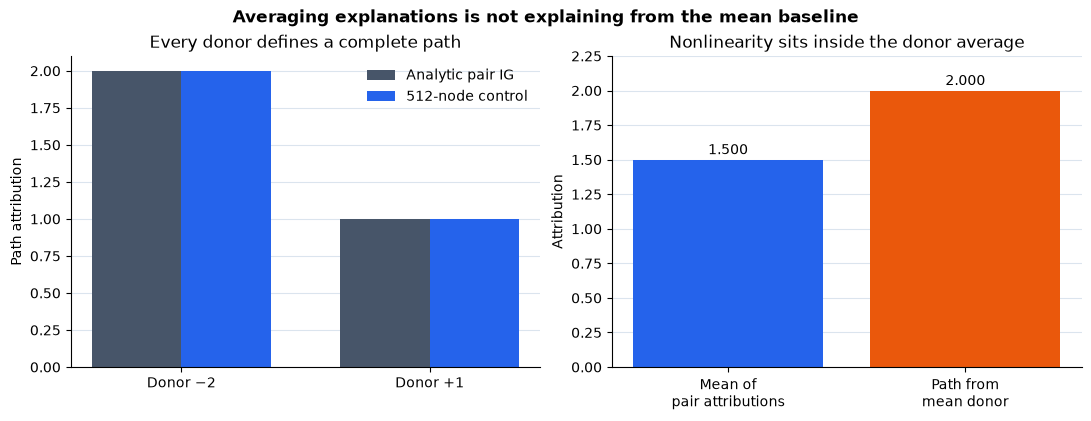

In [266]:
if MAIN:
    background_check = gradient_diagnose_background_average(gauss_legendre_pairs)
if MAIN:
    gradient_show_figure(gradient_plots.plot_background_average(background_check), "08_background_average")

## 8️⃣ Make Gaussian query noise part of the method call

Some GradientSHAP implementations perturb the query before drawing a path. With
$\epsilon\sim\mathcal N(0,\sigma^2I)$ and $\tilde x=x+\epsilon$, the retained sample is

$$
C_{ki}^{\sigma}
=(\tilde x_{ki}-b_{ki})
\partial_i f\bigl(b_k+\alpha_k(\tilde x_k-b_k)\bigr).
$$

Under the path assumptions, its population sum is

$$
\sum_i \operatorname{EG}^{\sigma}_i(x;B)
=\mathbb E_\epsilon[f(x+\epsilon)]-\mathbb E_b[f(b)],
$$

which is generally not the clean target $f(x)-\mathbb E_b[f(b)]$. Noise is therefore more than a
variance setting: it defines an average over a distribution of nearby queries.

For $f(z)=\operatorname{ReLU}(z)$, clean query $x=0$, donor $b=-1$, and $\epsilon\sim\mathcal
N(0,\sigma^2)$,

$$
\mathbb E[\operatorname{ReLU}(\epsilon)]-\operatorname{ReLU}(-1)
=\frac{\sigma}{\sqrt{2\pi}}.
$$

At $\sigma=1$, the noisy target is about `0.3989422804`, while the clean target is zero. Comparing
the noisy attribution sum with zero and calling the difference a completeness failure would be a
category error.

### Exercise 8 — `noisy_expected_gradient_samples`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵🔵
> 
> You should spend up to 15-20 minutes on this exercise.
> ```

Accept the noise tensor explicitly rather than sampling inside the method. Use it in both the noisy
query and displacement. For an exact zero noise tensor, the result must equal the clean estimator
bitwise under the same schedule.

In [267]:
def noisy_expected_gradient_samples(
    model: nn.Module,
    x: Tensor,
    background: Tensor,
    indices: Tensor,
    alpha: Tensor,
    noise: Tensor,
    forward_batch: int = 32_768,
) -> Tensor:
    """Use x+noise in point and delta, targeting the noise-smoothed query output."""
    points, delta = interpolate_paths(x, background, indices, alpha, noise)
    gradients = input_gradients(model, points, forward_batch)
    return gradients * delta


if MAIN:
    gradient_tests.test_noisy_expected_gradient_samples(noisy_expected_gradient_samples)

All tests in test_noisy_expected_gradient_samples passed!


In [268]:
def noise_fixture(samples=65_536):
    rng = np.random.default_rng(161512)
    return {
        "model": _relu_model(),
        "query": t.tensor([[0.0]], dtype=gradient_DTYPE),
        "background": t.tensor([[-1.0]], dtype=gradient_DTYPE),
        "indices": t.zeros((1, samples), dtype=t.int64),
        "alpha": t.tensor(rng.random((1, samples)), dtype=gradient_DTYPE),
        "standard_normal": t.tensor(rng.standard_normal((1, samples, 1)), dtype=gradient_DTYPE),
        "sigmas": t.tensor([0.0, 0.25, 0.50, 1.0], dtype=gradient_DTYPE),
    }

In [269]:
def diagnose_noise_target(
    noisy_expected_gradient_samples_fn,
    expected_gradient_samples_fn,
    summarize_expected_gradients_fn,
):
    fixture = noise_fixture()
    clean = expected_gradient_samples_fn(
        fixture["model"],
        fixture["query"],
        fixture["background"],
        fixture["indices"],
        fixture["alpha"],
    )
    estimates, standard_errors = [], []
    zero_samples = None
    for sigma in fixture["sigmas"]:
        noise = sigma * fixture["standard_normal"]
        samples = noisy_expected_gradient_samples_fn(
            fixture["model"],
            fixture["query"],
            fixture["background"],
            fixture["indices"],
            fixture["alpha"],
            noise,
        )
        mean, standard_error = summarize_expected_gradients_fn(samples, (samples.shape[1],))
        estimates.append(mean[0, 0, 0])
        standard_errors.append(standard_error[0, 0, 0])
        if float(sigma) == 0.0:
            zero_samples = samples
    estimates = t.stack(estimates)
    standard_errors = t.stack(standard_errors)
    analytic = fixture["sigmas"] / math.sqrt(2 * math.pi)
    return {
        "sigmas": fixture["sigmas"],
        "estimates": estimates,
        "standard_errors": standard_errors,
        "analytic_smoothed_target": analytic,
        "clean_target": t.zeros_like(analytic),
        "clean_residual": estimates,
        "smoothed_residual": estimates - analytic,
        "zero_noise_equal": bool(t.equal(clean, zero_samples)),
        "samples": int(fixture["alpha"].shape[1]),
    }

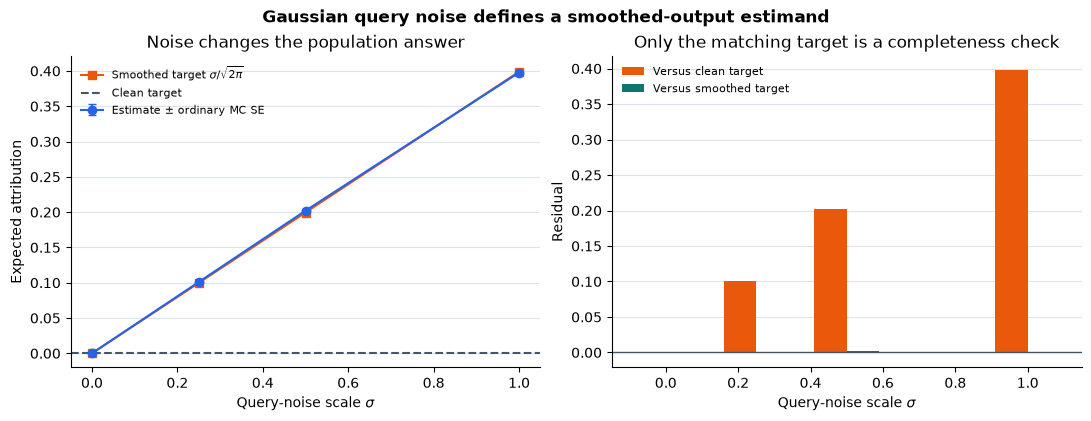

In [270]:
if MAIN:
    noise_check = diagnose_noise_target(
        noisy_expected_gradient_samples,
        expected_gradient_samples,
        summarize_expected_gradients,
    )
if MAIN:
    gradient_show_figure(gradient_plots.plot_noise_target(noise_check), "09_gaussian_target_shift")

## 9️⃣ Turn a global attribution order into a coalition intervention

Expected Gradients follows continuous diagonal paths. A replacement curve instead follows a sequence
of discrete feature coalitions. Given a complete `(N,2**D)` coalition table, an order
$j_0,\ldots,j_{D-1}$ defines insertion masks

$$
0,\quad 2^{j_0},\quad 2^{j_0}+2^{j_1},\quad\ldots,\quad 2^D-1,
$$

and deletion masks in reverse from the full coalition. Looking up their raw values exposes what the
model does under donor replacement without pretending the ranking and game are the same object.

The primary audit study ranks each method once by mean absolute attribution over all 153 explanation
rows, fixes those global orders, then applies them to every audit row. The default local play may
instead order one row by `sign(f(x)-base) * phi`; that exploratory ranking cannot support a new
confirmatory audit claim.

### Exercise 9 — `ranked_coalition_curves`

> ```yaml
> Difficulty: 🔴🔴🔴🔴⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 30-40 minutes on this exercise.
> ```

Return raw insertion and deletion values, their integer masks, and the feature order. Validate an
explicit order as a row-wise permutation. If `orders=None`, derive the local signed order with a
stable feature-index tie break.

In [271]:
def ranked_coalition_curves(
    values: Tensor,
    phi: Tensor,
    orders: Tensor | None = None,
) -> dict[str, Tensor]:
    """Gather raw insertion and deletion prefixes from complete coalition tables."""
    _eg_float_tensor("values", values, 2)
    _eg_float_tensor("phi", phi, 2)
    n_rows, size = values.shape
    n_features = size.bit_length() - 1
    if n_features < 1 or size != 2**n_features or phi.shape != (n_rows, n_features):
        raise ValueError("values must be (N,2**D) and phi must be (N,D), with D >= 1.")

    if orders is None:
        direction = t.where(values[:, -1] - values[:, 0] >= 0, 1.0, -1.0)[:, None]
        orders = t.argsort(direction * phi, dim=1, descending=True, stable=True)
    else:
        _eg_index_tensor("orders", orders, 2)
        if orders.shape != (n_rows, n_features):
            raise ValueError("orders must have shape (rows, features).")
        expected = t.arange(n_features, dtype=t.int64).expand(n_rows, n_features)
        if not t.equal(orders.sort(dim=1).values, expected):
            raise ValueError("Every order row must contain each feature exactly once.")
        orders = orders.clone()

    insertion_masks = t.zeros((n_rows, n_features + 1), dtype=t.int64)
    deletion_masks = t.full((n_rows, n_features + 1), size - 1, dtype=t.int64)
    for step in range(n_features):
        bit = 1 << orders[:, step]
        insertion_masks[:, step + 1] = insertion_masks[:, step] | bit
        deletion_masks[:, step + 1] = deletion_masks[:, step] ^ bit
    return {
        "orders": orders,
        "insertion_masks": insertion_masks,
        "deletion_masks": deletion_masks,
        "insertion": values.gather(1, insertion_masks),
        "deletion": values.gather(1, deletion_masks),
    }


if MAIN:
    gradient_tests.test_ranked_coalition_curves(ranked_coalition_curves)

All tests in test_ranked_coalition_curves passed!


In [272]:
def gradient_threshold_fixture():
    return {
        "model": _threshold_model(),
        "query": t.tensor([[1.0, 1.0]], dtype=gradient_DTYPE),
        "background": t.tensor([[0.0, 0.0]], dtype=gradient_DTYPE),
        "coalition_values": t.tensor([[0.0, 0.0, 0.0, 1.0]], dtype=gradient_DTYPE),
        "exact_shapley": t.tensor([[0.5, 0.5]], dtype=gradient_DTYPE),
        "analytic_path": t.tensor([[2 / 3, 1 / 3]], dtype=gradient_DTYPE),
        "necessity_drop": t.tensor([1.0, 1.0], dtype=gradient_DTYPE),
    }

In [273]:
def kink_fixture():
    first = nn.Sequential(
        gradient__linear([[0.0, 1.0], [-1.0, 1.0]], [0.0, 0.0]),
        nn.ReLU(),
        gradient__linear([[1.0, -1.0]], [0.0]),
    ).eval()
    mirrored = nn.Sequential(
        gradient__linear([[1.0, 0.0], [1.0, -1.0]], [0.0, 0.0]),
        nn.ReLU(),
        gradient__linear([[1.0, -1.0]], [0.0]),
    ).eval()
    return {
        "models": {"x1 route": first, "x0 route": mirrored},
        "query": t.tensor([[1.0, 1.0]], dtype=gradient_DTYPE),
        "background": t.tensor([[0.0, 0.0]], dtype=gradient_DTYPE),
        "binary_inputs": t.tensor(
            [[0.0, 0.0], [1.0, 0.0], [0.0, 1.0], [1.0, 1.0]], dtype=gradient_DTYPE
        ),
        "expected_binary": t.tensor([0.0, 0.0, 0.0, 1.0], dtype=gradient_DTYPE),
        "exact_shapley": t.tensor([[0.5, 0.5]], dtype=gradient_DTYPE),
    }

In [274]:
def gradient_replacement_fixture():
    contributions = t.tensor([3.0, -2.0, 0.0], dtype=gradient_DTYPE)
    masks = t.arange(8, dtype=t.int64)
    present = (masks[:, None].bitwise_and(1 << t.arange(3)) != 0).to(gradient_DTYPE)
    return {
        "values": (10.0 + present @ contributions).reshape(1, -1),
        "phi": contributions.reshape(1, -1),
        "all_orders": t.tensor(
            [[0, 1, 2], [0, 2, 1], [1, 0, 2], [1, 2, 0], [2, 0, 1], [2, 1, 0]],
            dtype=t.int64,
        ),
    }

In [275]:
def diagnose_path_vs_coalition(gauss_legendre_pairs_fn, ranked_coalition_curves_fn):
    threshold = gradient_threshold_fixture()
    path_256 = gauss_legendre_pairs_fn(
        threshold["model"], threshold["query"], threshold["background"], 256
    ).mean(dim=1)
    path_512 = gauss_legendre_pairs_fn(
        threshold["model"], threshold["query"], threshold["background"], 512
    ).mean(dim=1)
    threshold_orders = t.tensor([[0, 1], [1, 0]], dtype=t.int64)
    threshold_curves = [
        ranked_coalition_curves_fn(
            threshold["coalition_values"], path_512, order.reshape(1, -1)
        )
        for order in threshold_orders
    ]

    kink = kink_fixture()
    kink_phi, kink_outputs = {}, {}
    for name, model in kink["models"].items():
        kink_phi[name] = gauss_legendre_pairs_fn(
            model, kink["query"], kink["background"], 32
        ).mean(dim=1)
        kink_outputs[name] = gradient__prediction(model, kink["binary_inputs"])

    replacement = gradient_replacement_fixture()
    local_curve = ranked_coalition_curves_fn(replacement["values"], replacement["phi"])
    random_curves = [
        ranked_coalition_curves_fn(
            replacement["values"], replacement["phi"], order.reshape(1, -1)
        )
        for order in replacement["all_orders"]
    ]
    return {
        "threshold": {
            "path_256": path_256,
            "path_512": path_512,
            "quadrature_drift": (path_512 - path_256).abs(),
            "analytic_path": threshold["analytic_path"],
            "exact_shapley": threshold["exact_shapley"],
            "necessity_drop": threshold["necessity_drop"],
            "orders": threshold_orders,
            "curves": threshold_curves,
        },
        "kink": {
            "binary_inputs": kink["binary_inputs"],
            "expected_binary": kink["expected_binary"],
            "outputs": kink_outputs,
            "path_phi": kink_phi,
            "exact_shapley": kink["exact_shapley"],
        },
        "replacement": {
            "values": replacement["values"],
            "phi": replacement["phi"],
            "local_curve": local_curve,
            "random_curves": random_curves,
        },
    }

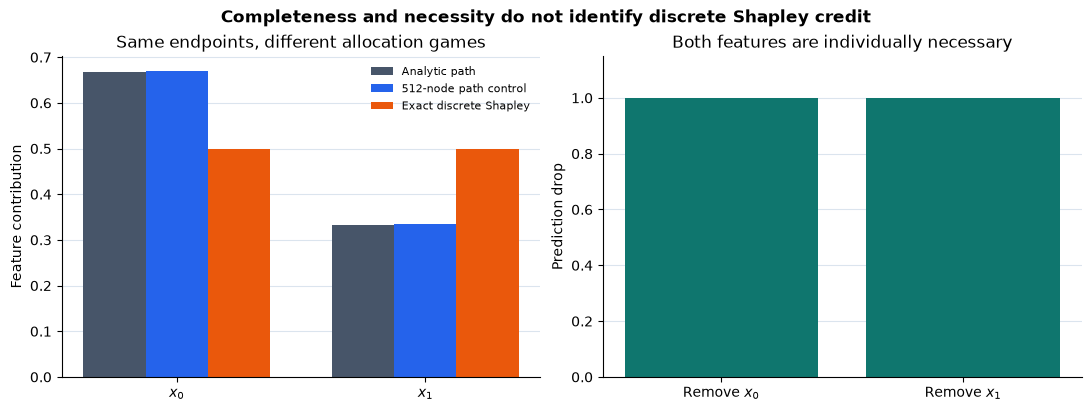

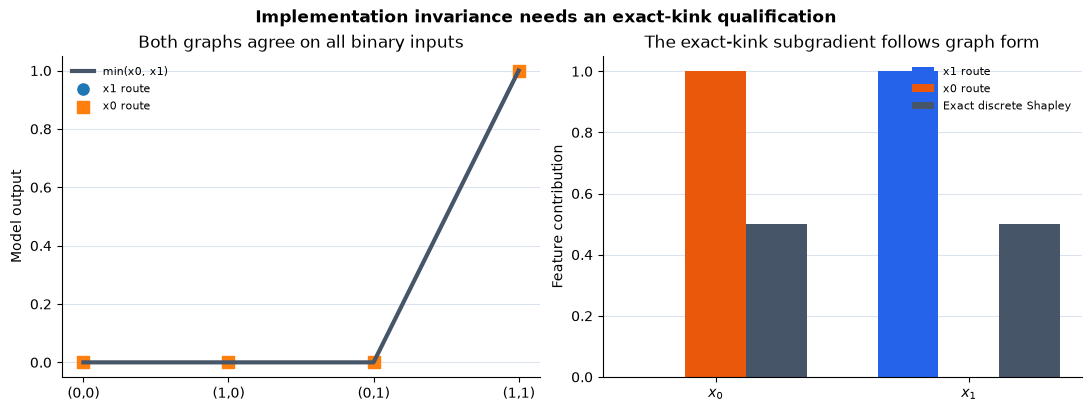

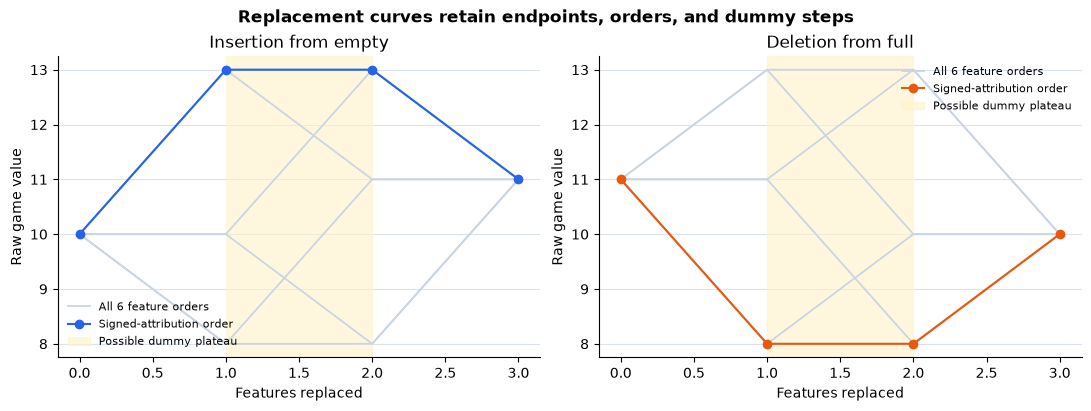

In [276]:
if MAIN:
    game_check = diagnose_path_vs_coalition(
        gauss_legendre_pairs,
        ranked_coalition_curves,
    )
if MAIN:
    gradient_show_figure(
        gradient_plots.plot_path_vs_coalition(game_check),
        "10_path_vs_coalition",
    )
if MAIN:
    gradient_show_figure(
        gradient_plots.plot_kink_representation(game_check),
        "11_kink_representation",
    )
if MAIN:
    gradient_show_figure(
        gradient_plots.plot_replacement_fixture(game_check),
        "12_replacement_fixture",
    )

### The threshold control: complete paths are not discrete Shapley

For

$$
f(x_0,x_1)=\operatorname{ReLU}(2x_0+x_1-2),\qquad x=(1,1),\quad b=(0,0),
$$

the diagonal path becomes active after $\alpha=2/3$. Its Expected Gradients allocation is
`(2/3,1/3)`. The four donor-replacement coalition values are `(0,0,0,1)`, whose exact Shapley
allocation is `(1/2,1/2)`. Both sum to one, and replacing either feature alone drops the output from
one to zero. Completeness and single-feature causal necessity do not force equal credit across these
two games.

### The exact-kink qualification

On nonnegative inputs,

$$
\min(x_0,x_1)=x_1-\operatorname{ReLU}(x_1-x_0)
=x_0-\operatorname{ReLU}(x_0-x_1).
$$

Along the path from `(0,0)` to `(1,1)`, both ReLU arguments stay exactly at the nondifferentiable
kink. PyTorch's zero derivative assigns `(0,1)` to the first graph and `(1,0)` to the mirrored
graph, while the discrete game gives `(1/2,1/2)`. This does not refute almost-everywhere
implementation invariance away from kinks. It exposes that an exact nondifferentiable path needs a
subgradient convention, and equivalent graphs can encode different conventions there. All four
binary inputs agree in output, and each feature is necessary at `(1,1)`.

In [277]:
if MAIN:
    gradient_methods = SimpleNamespace(
        sample_path_schedule=sample_path_schedule,
        interpolate_paths=interpolate_paths,
        input_gradients=input_gradients,
        expected_gradient_samples=expected_gradient_samples,
        summarize_expected_gradients=summarize_expected_gradients,
        expected_gradients=expected_gradients,
        gauss_legendre_pairs=gauss_legendre_pairs,
        noisy_expected_gradient_samples=noisy_expected_gradient_samples,
        ranked_coalition_curves=ranked_coalition_curves,
    )

### Try It Yourself 1 — move a path through the gate

Edit the query, donor, weights, bias, alpha schedule, and sample count. Recompute the path-gradient
samples, quadrature control, exact four-coalition Shapley, and both single-feature replacements.
Avoid placing a hand-derived test alpha exactly on the ReLU kink.

In [278]:
def gradient_threshold_play(
    methods,
    weights: Sequence[float] = (2.0, 1.0),
    bias: float = -2.0,
    query: Sequence[float] = (1.0, 1.0),
    reference: Sequence[float] = (0.0, 0.0),
    samples: int = 512,
    seed: int = 161510,
):
    schedule_fn = gradient__method(methods, "sample_path_schedule")
    sample_fn = gradient__method(methods, "expected_gradient_samples")
    summarize_fn = gradient__method(methods, "summarize_expected_gradients")
    quadrature_fn = gradient__method(methods, "gauss_legendre_pairs")
    curves_fn = gradient__method(methods, "ranked_coalition_curves")
    model = _threshold_model(weights, bias)
    query_tensor = t.as_tensor(query, dtype=gradient_DTYPE).reshape(1, -1)
    reference_tensor = t.as_tensor(reference, dtype=gradient_DTYPE).reshape(1, -1)
    if query_tensor.shape != reference_tensor.shape:
        raise ValueError("query and reference must have the same feature count.")
    if query_tensor.shape[1] != len(weights):
        raise ValueError("weights must contain one value per query feature.")
    indices, alpha = schedule_fn(t.tensor([0], dtype=t.int64), 1, samples, seed)
    draws = sample_fn(model, query_tensor, reference_tensor, indices, alpha)
    mean, standard_error = summarize_fn(draws, (samples,))
    quadrature = quadrature_fn(model, query_tensor, reference_tensor, 512).mean(dim=1)

    feature_count = query_tensor.shape[1]
    if feature_count != 2:
        raise ValueError("The editable teaching play currently requires exactly two features.")
    masks = t.arange(4, dtype=t.int64)
    present = masks[:, None].bitwise_and(1 << t.arange(2)) != 0
    hybrids = t.where(present, query_tensor, reference_tensor)
    values = gradient__prediction(model, hybrids).reshape(1, -1)
    exact = _two_feature_shapley(values).reshape(1, -1)
    curves = {
        "expected_gradients": curves_fn(values, mean[0]),
        "exact_shapley": curves_fn(values, exact),
    }
    return {
        "weights": t.as_tensor(weights, dtype=gradient_DTYPE),
        "bias": float(bias),
        "query": query_tensor,
        "reference": reference_tensor,
        "alpha": alpha,
        "draws": draws,
        "mean": mean[0],
        "standard_error": standard_error[0],
        "quadrature": quadrature,
        "coalition_values": values,
        "exact_shapley": exact,
        "prediction": gradient__prediction(model, query_tensor)[0],
        "base": gradient__prediction(model, reference_tensor)[0],
        "curves": curves,
        "samples": samples,
        "seed": seed,
    }

def gradient_run_diagnostics(methods=None):
    schedule = diagnose_schedule(gradient__method(methods, "sample_path_schedule"))
    interpolation = diagnose_interpolation(gradient__method(methods, "interpolate_paths"))
    gradients = diagnose_gradients(gradient__method(methods, "input_gradients"))
    samples = diagnose_expected_gradient_samples(
        gradient__method(methods, "expected_gradient_samples"),
        gradient__method(methods, "sample_path_schedule"),
    )
    convergence = diagnose_convergence(
        gradient__method(methods, "sample_path_schedule"),
        gradient__method(methods, "expected_gradient_samples"),
        gradient__method(methods, "summarize_expected_gradients"),
    )
    estimator = diagnose_expected_gradients(
        gradient__method(methods, "expected_gradients"),
        gradient__method(methods, "sample_path_schedule"),
    )
    quadrature = diagnose_quadrature(
        gradient__method(methods, "gauss_legendre_pairs"),
        gradient__method(methods, "input_gradients"),
    )
    background = gradient_diagnose_background_average(gradient__method(methods, "gauss_legendre_pairs"))
    noise = diagnose_noise_target(
        gradient__method(methods, "noisy_expected_gradient_samples"),
        gradient__method(methods, "expected_gradient_samples"),
        gradient__method(methods, "summarize_expected_gradients"),
    )
    game = diagnose_path_vs_coalition(
        gradient__method(methods, "gauss_legendre_pairs"),
        gradient__method(methods, "ranked_coalition_curves"),
    )
    namespace = methods
    if namespace is None:
        gradientshap_methods = SimpleNamespace(**gradient_module_gradientshap_methods_namespace())

        namespace = gradientshap_methods
    play = gradient_threshold_play(namespace)
    return {
        "schedule": schedule,
        "interpolation": interpolation,
        "gradients": gradients,
        "samples": samples,
        "convergence": convergence,
        "estimator": estimator,
        "quadrature": quadrature,
        "background": background,
        "noise": noise,
        "game": game,
        "threshold_play": play,
    }

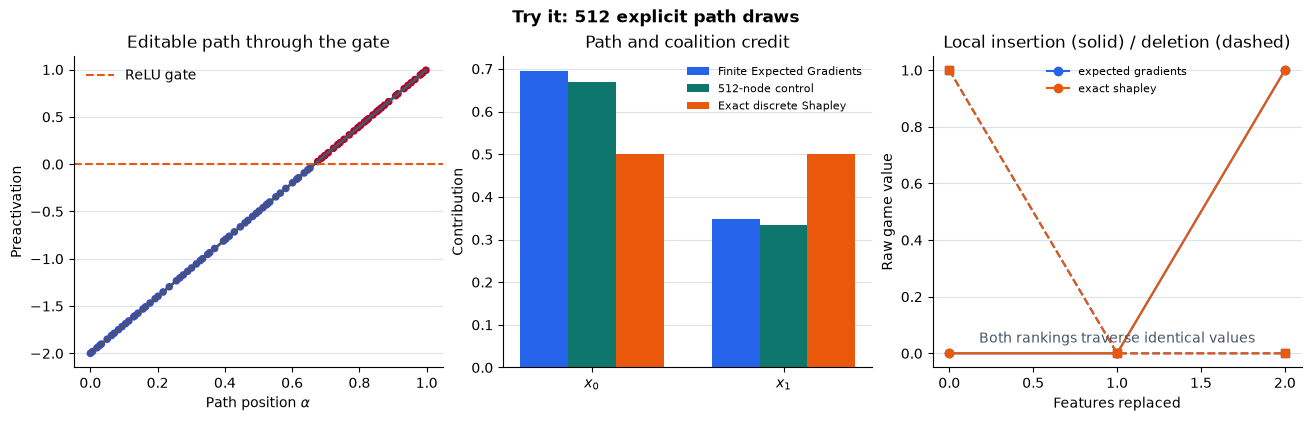

In [279]:
if MAIN:
    gradient_tiny_play = gradient_threshold_play(
        gradient_methods,
        weights=(2.0, 1.0),
        bias=-2.0,
        query=(1.0, 1.0),
        reference=(0.0, 0.0),
        samples=512,
        seed=161510,
    )
if MAIN:
    gradient_show_figure(gradient_plots.plot_threshold_play(gradient_tiny_play), "13_threshold_play")

<details><summary>Ideas to try</summary>

- Make both weights equal and check which symmetries the query and reference must also satisfy.
- Move the bias until a finite schedule has only active or only inactive draws.
- Double the sample count while preserving the old prefix; compare the actual error with the SE.
- Put the path exactly on a kink, then perturb one coordinate by `1e-8` and inspect the derivative
convention.

</details>

## The frozen-design real study

> **Execution boundary.** The cells below reproduce all 21 section
> 16.14 state hashes, persist the fitted and prepared study before the literal audit load, and then
> evaluate every held-out recipe. This ordering keeps explanation-side choices separate from the
> audit evidence.

The intended study holds the predictors and data fixed so the attribution method is the variable:

- the same 1,030 UCI Concrete rows and recipe-disjoint 758/153/119 split as section 16.14;
- the same three clean and three shuffled-target `8 -> 32 -> 32 -> 1` ReLU functions plus ridge;
- raw feature inputs, raw MPa outputs, and state-hash parity with the section 16.14 predictors;
- all seven models and all 272 held-out rows, with no selected-error subset;
- the same primary 64 intact donors, nested sizes 16 and 128, and two independent 64-row designs;
- nested Monte Carlo budgets `(8,32,128,512,2048)` on one literal row-stable schedule;
- 256- and 512-node all-background quadrature retained separately;
- exact 256-coalition Shapley, DeepSHAP, and endpoint gradient-times-delta as distinct comparisons;
- Gaussian scales `(0,0.02,0.10)` in train-standardized input units, mapped back to raw units;
- global feature orders learned from 153 explanation rows before audit values are loaded;
- 100 fixed random feature orders for the 119-row audit replacement experiment.

The reused predictors isolate method behavior but do not constitute an independent model or dataset
replication. The frozen protocol refits them from source, verifies all 21 initial, standardized, and
raw-folded state hashes against section 16.14, and stops before attribution if any identity differs.

The visible study source will be split into short cells for state reconstruction, schedule creation,
path evaluation, quadrature, exact-game comparisons, background/noise evaluation, and replacement
curves. Mechanical schema validation may be imported; the scientific call flow and every meaningful
transformation must remain visible.

### Visible supporting scientific function: `FEATURES`

In [280]:
gradient_helper_gradientshap_study_FEATURES = 8

### Visible supporting scientific function: `FORWARD_BATCH`

In [281]:
gradient_helper_gradientshap_study_FORWARD_BATCH = 32_768

### Visible supporting scientific function: `_batched_prediction`

In [282]:
if MAIN:
    import torch as t

def gradient_helper_gradientshap_study__batched_prediction(model: t.nn.Module, values: t.Tensor) -> t.Tensor:
    flat = values.reshape(-1, gradient_helper_gradientshap_study_FEATURES)
    with t.no_grad():
        prediction = t.cat(
            [
                model(flat[start : start + gradient_helper_gradientshap_study_FORWARD_BATCH]).squeeze(-1)
                for start in range(0, len(flat), gradient_helper_gradientshap_study_FORWARD_BATCH)
            ]
        )
    return prediction.reshape(values.shape[:-1])

### Visible supporting scientific function: `_output_tensor`

In [283]:
if MAIN:
    from typing import Any
if MAIN:
    import torch as t

def gradient_helper_gradientshap_study__output_tensor(value: Any, shape: tuple[int, ...], name: str) -> t.Tensor:
    if not isinstance(value, t.Tensor):
        raise TypeError(f"{name} must be a Torch tensor.")
    if value.device.type != "cpu" or value.dtype != t.float64:
        raise TypeError(f"{name} must be a CPU float64 tensor.")
    if tuple(value.shape) != shape or not bool(t.isfinite(value).all()):
        raise ValueError(f"{name} has the wrong shape or contains nonfinite values.")
    return value

### Visible supporting scientific function: `_checked_curves`

In [284]:
if MAIN:
    from typing import Any
if MAIN:
    from collections.abc import Mapping
if MAIN:
    import torch as t

def gradient_helper_gradientshap_study__checked_curves(
    values: t.Tensor, phi: t.Tensor, order: t.Tensor, methods: Any
) -> dict[str, t.Tensor]:
    orders = order[None, :].expand(len(values), gradient_helper_gradientshap_study_FEATURES).clone()
    result = methods.ranked_coalition_curves(values, phi, orders)
    expected = {
        "orders": (len(values), gradient_helper_gradientshap_study_FEATURES),
        "insertion_masks": (len(values), gradient_helper_gradientshap_study_FEATURES + 1),
        "deletion_masks": (len(values), gradient_helper_gradientshap_study_FEATURES + 1),
        "insertion": (len(values), gradient_helper_gradientshap_study_FEATURES + 1),
        "deletion": (len(values), gradient_helper_gradientshap_study_FEATURES + 1),
    }
    if not isinstance(result, Mapping) or set(result) != set(expected):
        raise ValueError("Replacement curves returned an unexpected payload.")
    for name, shape in expected.items():
        value = result[name]
        if not isinstance(value, t.Tensor) or tuple(value.shape) != shape:
            raise ValueError(f"Replacement curve {name} has the wrong shape.")
        if name in {"orders", "insertion_masks", "deletion_masks"}:
            if value.dtype != t.int64:
                raise TypeError(f"Replacement curve {name} must be int64.")
        else:
            gradient_helper_gradientshap_study__output_tensor(value, shape, name)
    return dict(result)

### Visible supporting scientific function: `_clone_state`

In [285]:
if MAIN:
    from collections.abc import Mapping
if MAIN:
    import torch as t

def gradient_helper_gradientshap_study__clone_state(state: Mapping[str, t.Tensor]) -> dict[str, t.Tensor]:
    if not isinstance(state, Mapping):
        raise TypeError("A model state must be a tensor mapping.")
    result: dict[str, t.Tensor] = {}
    for name, value in state.items():
        if not isinstance(name, str) or not isinstance(value, t.Tensor):
            raise TypeError("State keys must be strings and values must be tensors.")
        if value.device.type != "cpu" or value.dtype != t.float64:
            raise TypeError("Every model-state tensor must be CPU float64.")
        if not bool(t.isfinite(value).all()):
            raise ValueError("Model-state tensors must be finite.")
        result[name] = value.detach().clone()
    return result

### Visible supporting scientific function: `_combine_baselines`

In [286]:
if MAIN:
    from collections.abc import Mapping
if MAIN:
    import torch as t

def gradient_helper_gradientshap_study__combine_baselines(
    explanation: Mapping[str, t.Tensor], audit: Mapping[str, t.Tensor]
) -> dict[str, t.Tensor]:
    result: dict[str, t.Tensor] = {}
    for name in explanation:
        if name == "base_deep":
            if not t.equal(explanation[name], audit[name]):
                raise ValueError("Primary DeepSHAP base changed across row blocks.")
            result[name] = explanation[name]
        else:
            result[name] = t.cat([explanation[name], audit[name]], dim=0)
    return result

### Visible supporting scientific function: `_combine_mc`

In [287]:
if MAIN:
    from typing import Any
if MAIN:
    from collections.abc import Mapping
if MAIN:
    import torch as t

def gradient_helper_gradientshap_study__combine_mc(
    explanation: Mapping[str, Any], audit: Mapping[str, Any]
) -> dict[str, Any]:
    if not t.equal(explanation["budgets"], audit["budgets"]):
        raise ValueError("Nested budgets changed between explanation and audit blocks.")
    if not t.equal(explanation["base_full"], audit["base_full"]):
        raise ValueError("Primary background base changed across the audit boundary.")
    return {
        "source_ids": t.cat([explanation["source_ids"], audit["source_ids"]]),
        "baseline_index": t.cat(
            [explanation["baseline_index"], audit["baseline_index"]]
        ),
        "alpha": t.cat([explanation["alpha"], audit["alpha"]]),
        "samples": t.cat([explanation["samples"], audit["samples"]]),
        "budgets": explanation["budgets"],
        "phi_prefix": t.cat(
            [explanation["phi_prefix"], audit["phi_prefix"]], dim=1
        ),
        "se_prefix": t.cat(
            [explanation["se_prefix"], audit["se_prefix"]], dim=1
        ),
        "base_full": explanation["base_full"],
        "prediction": t.cat([explanation["prediction"], audit["prediction"]]),
        "completeness_residual_prefix": t.cat(
            [
                explanation["completeness_residual_prefix"],
                audit["completeness_residual_prefix"],
            ],
            dim=1,
        ),
    }

### Visible supporting scientific function: `MODEL_KEYS`

In [288]:
gradient_helper_gradientshap_study_MODEL_KEYS = (
    "clean_0",
    "clean_1",
    "clean_2",
    "shuffled_0",
    "shuffled_1",
    "shuffled_2",
    "ridge",
)

### Visible supporting scientific function: `_combine_quadrature`

In [289]:
if MAIN:
    from collections.abc import Mapping
if MAIN:
    import torch as t

def gradient_helper_gradientshap_study__combine_quadrature(
    explanation: Mapping[str, t.Tensor], audit: Mapping[str, t.Tensor]
) -> dict[str, t.Tensor]:
    result: dict[str, t.Tensor] = {}
    for name in explanation:
        result[name] = t.cat([explanation[name], audit[name]], dim=0)
    return result

### Visible supporting scientific function: `_combine_primary`

In [290]:
if MAIN:
    from typing import Any
if MAIN:
    from collections.abc import Mapping

def gradient_helper_gradientshap_study__combine_primary(
    prepared: Mapping[str, Any], audit_primary: Mapping[str, Any]
) -> dict[str, Any]:
    return {
        key: {
            "mc": gradient_helper_gradientshap_study__combine_mc(prepared["primary"][key]["mc"], audit_primary[key]["mc"]),
            "quadrature": gradient_helper_gradientshap_study__combine_quadrature(
                prepared["primary"][key]["quadrature"],
                audit_primary[key]["quadrature"],
            ),
            "baselines": gradient_helper_gradientshap_study__combine_baselines(
                prepared["primary"][key]["baselines"],
                audit_primary[key]["baselines"],
            ),
        }
        for key in gradient_helper_gradientshap_study_MODEL_KEYS
    }

### Visible supporting scientific function: `RANDOM_ORDER_SEED`

In [291]:
gradient_helper_gradientshap_study_RANDOM_ORDER_SEED = 161480

### Visible supporting scientific function: `_fixed_random_orders`

In [292]:
if MAIN:
    import numpy as np
if MAIN:
    import torch as t

def gradient_helper_gradientshap_study__fixed_random_orders() -> t.Tensor:
    rng = np.random.default_rng(gradient_helper_gradientshap_study_RANDOM_ORDER_SEED)
    return t.from_numpy(np.stack([rng.permutation(gradient_helper_gradientshap_study_FEATURES) for _ in range(100)]))

### Visible supporting scientific function: `_float_tensor`

In [293]:
if MAIN:
    from typing import Any
if MAIN:
    import torch as t

def gradient_helper_gradientshap_study__float_tensor(value: Any, name: str, dimensions: int) -> t.Tensor:
    tensor = value if isinstance(value, t.Tensor) else t.as_tensor(value)
    if tensor.device.type != "cpu" or tensor.dtype != t.float64:
        raise TypeError(f"{name} must be a CPU float64 tensor or array.")
    if tensor.ndim != dimensions or not bool(t.isfinite(tensor).all()):
        raise ValueError(f"{name} has the wrong shape or contains nonfinite values.")
    return tensor.detach().clone()

### Visible supporting scientific function: `_normalization_tensors`

In [294]:
if MAIN:
    from typing import Any
if MAIN:
    from collections.abc import Mapping
if MAIN:
    import torch as t

def gradient_helper_gradientshap_study__normalization_tensors(normalization: Mapping[str, Any]) -> tuple[t.Tensor, ...]:
    if not isinstance(normalization, Mapping):
        raise TypeError("normalization must be a mapping.")
    x_mean = gradient_helper_gradientshap_study__float_tensor(normalization.get("x_mean"), "x_mean", 1)
    x_std = gradient_helper_gradientshap_study__float_tensor(normalization.get("x_std"), "x_std", 1)
    y_mean = gradient_helper_gradientshap_study__float_tensor(normalization.get("y_mean"), "y_mean", 0)
    y_std = gradient_helper_gradientshap_study__float_tensor(normalization.get("y_std"), "y_std", 0)
    if x_mean.shape != (gradient_helper_gradientshap_study_FEATURES,) or x_std.shape != (gradient_helper_gradientshap_study_FEATURES,):
        raise ValueError("Normalization must describe exactly eight input features.")
    if bool((x_std <= 0).any()) or not bool(y_std > 0):
        raise ValueError("Training standard deviations must be positive.")
    return x_mean, x_std, y_mean, y_std

### Visible supporting scientific function: `_folding_error`

In [295]:
if MAIN:
    from typing import Any
if MAIN:
    from collections.abc import Mapping
if MAIN:
    import torch as t

def gradient_helper_gradientshap_study__folding_error(
    kind: str,
    standardized_state: Mapping[str, t.Tensor],
    raw_state: Mapping[str, t.Tensor],
    normalization: Mapping[str, Any],
    x_raw: t.Tensor,
) -> tuple[t.Tensor, float]:
    x_mean, x_std, y_mean, y_std = gradient_helper_gradientshap_study__normalization_tensors(normalization)
    standard = gradient__model_from_state({"kind": kind, "state": standardized_state})
    raw = gradient__model_from_state({"kind": kind, "state": raw_state})
    with t.no_grad():
        expected = standard((x_raw - x_mean) / x_std).squeeze(-1) * y_std + y_mean
        prediction = raw(x_raw).squeeze(-1)
    return prediction, float((prediction - expected).abs().max())

### Visible supporting scientific function: `_identity_hash`

In [296]:
if MAIN:
    from typing import Any
if MAIN:
    from chapter16_shapley_attribution_baselines.exercises.part3_model_specific_shap.gradient_gradientshap_data import tensor_mapping_sha256 as gradient_plumbing_gradientshap_data_tensor_mapping_sha256

def gradient_helper_gradientshap_study__identity_hash(**arrays: Any) -> str:
    return gradient_plumbing_gradientshap_data_tensor_mapping_sha256(arrays)

### Visible supporting scientific function: `_ids_tensor`

In [297]:
if MAIN:
    from typing import Any
if MAIN:
    import torch as t

def gradient_helper_gradientshap_study__ids_tensor(value: Any, rows: int, name: str) -> t.Tensor:
    tensor = value if isinstance(value, t.Tensor) else t.as_tensor(value)
    if tensor.device.type != "cpu" or tensor.dtype != t.int64:
        raise TypeError(f"{name} must be a CPU int64 tensor or array.")
    if tensor.shape != (rows,) or len(t.unique(tensor)) != rows:
        raise ValueError(f"{name} must contain one unique identity per row.")
    return tensor.detach().clone()

### Visible supporting scientific function: `_require_disjoint_ids`

In [298]:
if MAIN:
    import torch as t

def gradient_helper_gradientshap_study__require_disjoint_ids(**splits: t.Tensor) -> None:
    names = tuple(splits)
    for left_index, left_name in enumerate(names):
        for right_name in names[left_index + 1 :]:
            if bool(t.isin(splits[left_name], splits[right_name]).any()):
                raise ValueError(
                    f"{left_name} and {right_name} source-row identities must be disjoint."
                )

### Visible supporting scientific function: `_require_namespace`

In [299]:
if MAIN:
    from typing import Any

def gradient_helper_gradientshap_study__require_namespace(namespace: Any, names: tuple[str, ...], label: str) -> None:
    missing = [name for name in names if not callable(getattr(namespace, name, None))]
    if missing:
        raise TypeError(f"{label} namespace is missing {missing}.")

### Visible supporting scientific function: `_rows`

In [300]:
if MAIN:
    from typing import Any
if MAIN:
    from collections.abc import Mapping
if MAIN:
    import torch as t

def gradient_helper_gradientshap_study__rows(rows: Mapping[str, Any], name: str) -> tuple[t.Tensor, t.Tensor, t.Tensor]:
    if not isinstance(rows, Mapping) or not {"x", "y", "ids"} <= set(rows):
        raise TypeError(f"{name} must contain x, y and ids.")
    x = gradient_helper_gradientshap_study__float_tensor(rows["x"], f"{name}.x", 2)
    y = gradient_helper_gradientshap_study__float_tensor(rows["y"], f"{name}.y", 1)
    if x.shape != (len(y), gradient_helper_gradientshap_study_FEATURES) or len(y) == 0:
        raise ValueError(f"{name} must contain nonempty eight-feature rows.")
    ids = gradient_helper_gradientshap_study__ids_tensor(rows["ids"], len(y), f"{name}.ids")
    return x, y, ids

### Visible supporting scientific function: `_seed_words`

In [301]:
if MAIN:
    import hashlib

def gradient_helper_gradientshap_study__seed_words(seed: int, source_id: int, stream_tag: str) -> int:
    name = f"arena16.15/gradientshap/v1/{seed}/{source_id}/{stream_tag}"
    return int.from_bytes(hashlib.sha256(name.encode()).digest()[:16], "little")

### Visible supporting scientific function: `HIDDEN`

In [302]:
gradient_helper_gradientshap_study_HIDDEN = 32

### Visible supporting scientific function: `_state_shapes`

In [303]:
def gradient_helper_gradientshap_study__state_shapes(kind: str) -> dict[str, tuple[int, ...]]:
    if kind == "mlp":
        return {
            "0.weight": (gradient_helper_gradientshap_study_HIDDEN, gradient_helper_gradientshap_study_FEATURES),
            "0.bias": (gradient_helper_gradientshap_study_HIDDEN,),
            "2.weight": (gradient_helper_gradientshap_study_HIDDEN, gradient_helper_gradientshap_study_HIDDEN),
            "2.bias": (gradient_helper_gradientshap_study_HIDDEN,),
            "4.weight": (1, gradient_helper_gradientshap_study_HIDDEN),
            "4.bias": (1,),
        }
    if kind == "ridge":
        return {"0.weight": (1, gradient_helper_gradientshap_study_FEATURES), "0.bias": (1,)}
    raise ValueError(f"Unsupported fitted-model kind: {kind!r}.")

### Visible supporting scientific function: `_validate_fitted`

In [304]:
if MAIN:
    from typing import Any
if MAIN:
    from collections.abc import Mapping

def gradient_helper_gradientshap_study__validate_fitted(fitted: Mapping[str, Any]) -> None:
    if not isinstance(fitted, Mapping) or fitted.get("phase") != "fitted_before_attribution":
        raise ValueError("Use the complete train-only fitted payload.")
    if not isinstance(fitted.get("models"), Mapping):
        raise ValueError("The fitted payload must contain all model records.")
    if tuple(fitted["models"]) != gradient_helper_gradientshap_study_MODEL_KEYS:
        raise ValueError("The fitted payload must retain all seven models in frozen order.")
    gradient_helper_gradientshap_study__normalization_tensors(fitted.get("normalization"))
    x = gradient_helper_gradientshap_study__float_tensor(fitted.get("train_x_raw"), "train_x_raw", 2)
    y = gradient_helper_gradientshap_study__float_tensor(fitted.get("train_y_raw"), "train_y_raw", 1)
    ids = gradient_helper_gradientshap_study__ids_tensor(fitted.get("train_ids"), len(y), "train_ids")
    if x.shape != (len(y), gradient_helper_gradientshap_study_FEATURES) or len(ids) != len(y):
        raise ValueError("Fitted training arrays have incompatible shapes.")
    for key in gradient_helper_gradientshap_study_MODEL_KEYS:
        expected_kind = "ridge" if key == "ridge" else "mlp"
        if fitted["models"][key].get("kind") != expected_kind:
            raise ValueError(f"{key} has the wrong model kind.")
        gradient__model_from_state(fitted["models"][key])

### Visible supporting scientific function: `_validate_evaluation_inputs`

In [305]:
if MAIN:
    from typing import Any
if MAIN:
    from collections.abc import Mapping
if MAIN:
    from chapter16_shapley_attribution_baselines.exercises.part3_model_specific_shap.gradient_gradientshap_data import load_manifest as gradient_plumbing_gradientshap_data_load_manifest
if MAIN:
    import torch as t

def gradient_helper_gradientshap_study__validate_evaluation_inputs(
    fitted: Mapping[str, Any],
    prepared: Mapping[str, Any],
    train: Mapping[str, Any],
    explain: Mapping[str, Any],
    audit: Mapping[str, Any],
) -> dict[str, t.Tensor]:
    gradient_helper_gradientshap_study__validate_fitted(fitted)
    if prepared.get("phase") != "prepared_before_audit":
        raise ValueError("Persist the prepared payload before audit evaluation.")
    if prepared.get("audit_used_for_selection") is not False:
        raise ValueError("Audit rows cannot select models, schedules, backgrounds or rankings.")
    if prepared.get("reproduction", {}).get("status") != "PASS":
        raise ValueError("The 21-state reproduction gate must pass before evaluation.")
    train_x, train_y, train_ids = gradient_helper_gradientshap_study__rows(train, "train")
    explain_x, explain_y, explain_ids = gradient_helper_gradientshap_study__rows(explain, "explain")
    audit_x, audit_y, audit_ids = gradient_helper_gradientshap_study__rows(audit, "audit")
    gradient_helper_gradientshap_study__require_disjoint_ids(train=train_ids, explanation=explain_ids, audit=audit_ids)
    if not t.equal(train_ids, fitted["train_ids"]):
        raise ValueError("Training identities changed after fitting.")
    if not t.equal(train_x, fitted["train_x_raw"]) or not t.equal(
        train_y, fitted["train_y_raw"]
    ):
        raise ValueError("Training values changed after fitting.")
    if not t.equal(explain_ids, prepared["explain_ids"]):
        raise ValueError("Explanation identities changed after preparation.")
    if not t.equal(explain_x, prepared["explain_x_raw"]) or not t.equal(
        explain_y, prepared["explain_targets"]
    ):
        raise ValueError("Explanation values changed after preparation.")
    manifest = gradient_plumbing_gradientshap_data_load_manifest()
    expected_audit = t.as_tensor(manifest["splits"]["audit"], dtype=t.int64)
    if not t.equal(audit_ids, expected_audit):
        raise ValueError("Audit identities differ from the literal pinned split.")
    identities = prepared.get("payload_identities", {})
    if identities.get("train") != gradient_helper_gradientshap_study__identity_hash(ids=train_ids, x=train_x, y=train_y):
        raise ValueError("Prepared training identity seal changed.")
    if identities.get("explain") != gradient_helper_gradientshap_study__identity_hash(
        ids=explain_ids, x=explain_x, y=explain_y
    ):
        raise ValueError("Prepared explanation identity seal changed.")
    expected_backgrounds = gradient__background_indices(train_ids, manifest)
    for name, indices in expected_backgrounds.items():
        item = prepared.get("backgrounds", {}).get(name, {})
        if not t.equal(item.get("indices"), indices):
            raise ValueError(f"Prepared {name} background indices changed.")
        if not t.equal(item.get("source_ids"), train_ids[indices]):
            raise ValueError(f"Prepared {name} background identities changed.")
        if not t.equal(item.get("x_raw"), train_x[indices]):
            raise ValueError(f"Prepared {name} background values changed.")
        expected_hash = gradient_helper_gradientshap_study__identity_hash(
            indices=indices, ids=train_ids[indices], x=train_x[indices]
        )
        if identities.get("backgrounds", {}).get(name) != expected_hash:
            raise ValueError(f"Prepared {name} background seal changed.")
    primary_mc = prepared.get("primary", {}).get(gradient_helper_gradientshap_study_MODEL_KEYS[0], {}).get("mc", {})
    schedule_manifest = prepared.get("schedule_manifest", {})
    if schedule_manifest.get("baseline_index_sha256") != gradient_helper_gradientshap_study__identity_hash(
        value=primary_mc.get("baseline_index")
    ):
        raise ValueError("Prepared donor schedule seal changed.")
    if schedule_manifest.get("alpha_sha256") != gradient_helper_gradientshap_study__identity_hash(
        value=primary_mc.get("alpha")
    ):
        raise ValueError("Prepared alpha schedule seal changed.")
    return {
        "train_x": train_x,
        "train_y": train_y,
        "train_ids": train_ids,
        "explain_x": explain_x,
        "explain_y": explain_y,
        "explain_ids": explain_ids,
        "audit_x": audit_x,
        "audit_y": audit_y,
        "audit_ids": audit_ids,
    }

In [306]:
if MAIN:
    deep_methods = SimpleNamespace(**deep_module_deepshap_methods_namespace())
if MAIN:
    _batched_prediction = gradient_helper_gradientshap_study__batched_prediction
if MAIN:
    _checked_curves = gradient_helper_gradientshap_study__checked_curves
if MAIN:
    gradient__clone_state = gradient_helper_gradientshap_study__clone_state
if MAIN:
    _combine_baselines = gradient_helper_gradientshap_study__combine_baselines
if MAIN:
    _combine_mc = gradient_helper_gradientshap_study__combine_mc
if MAIN:
    _combine_primary = gradient_helper_gradientshap_study__combine_primary
if MAIN:
    _combine_quadrature = gradient_helper_gradientshap_study__combine_quadrature
if MAIN:
    gradient__fixed_random_orders = gradient_helper_gradientshap_study__fixed_random_orders
if MAIN:
    gradient__float_tensor = gradient_helper_gradientshap_study__float_tensor
if MAIN:
    gradient__folding_error = gradient_helper_gradientshap_study__folding_error
if MAIN:
    _identity_hash = gradient_helper_gradientshap_study__identity_hash
if MAIN:
    gradient__ids_tensor = gradient_helper_gradientshap_study__ids_tensor
if MAIN:
    gradient__normalization_tensors = gradient_helper_gradientshap_study__normalization_tensors
if MAIN:
    gradient__output_tensor = gradient_helper_gradientshap_study__output_tensor
if MAIN:
    gradient__require_disjoint_ids = gradient_helper_gradientshap_study__require_disjoint_ids
if MAIN:
    _require_namespace = gradient_helper_gradientshap_study__require_namespace
if MAIN:
    gradient__rows = gradient_helper_gradientshap_study__rows
if MAIN:
    _seed_words = gradient_helper_gradientshap_study__seed_words
if MAIN:
    gradient__state_shapes = gradient_helper_gradientshap_study__state_shapes
if MAIN:
    gradient__validate_evaluation_inputs = gradient_helper_gradientshap_study__validate_evaluation_inputs
if MAIN:
    gradient__validate_fitted = gradient_helper_gradientshap_study__validate_fitted

In [307]:
gradient_FEATURES = 8

gradient_HIDDEN = 32

gradient_TRAINING_STEPS = 800

gradient_LEARNING_RATE = 0.003

gradient_WEIGHT_DECAY = 0.0001

gradient_RIDGE_PENALTY = 0.01

gradient_MODEL_KEYS = (
    "clean_0",
    "clean_1",
    "clean_2",
    "shuffled_0",
    "shuffled_1",
    "shuffled_2",
    "ridge",
)

gradient_MODEL_SEEDS = (161410, 161411, 161412)

gradient_SHUFFLE_SEEDS = (161420, 161421, 161422)

BACKGROUND_SPECS = {
    "primary64": (161460, 64),
    "nested16": (161460, 16),
    "nested128": (161460, 128),
    "independent64_a": (161461, 64),
    "independent64_b": (161462, 64),
}

BUDGETS = (8, 32, 128, 512, 2048)

QUADRATURE_NODES = (256, 512)

NOISE_SIGMAS = (0.0, 0.02, 0.10)

PRIMARY_SCHEDULE_SEED = 161510

REPLICATE_SCHEDULE_SEED = 161511

NOISE_SCHEDULE_SEED = 161512

REFERENCE_SEEDS = {"shap": 161513, "captum_numpy": 161514, "captum_torch": 161515}

gradient_RANDOM_ORDER_SEED = 161480

REPLICATES = 64

REPLICATE_MODELS = ("clean_0", "shuffled_0", "ridge")

PATH_DISTANCE_SAMPLES = 128

COALITION_DISTANCE_DONORS = 8

FORWARD_BATCH = 32_768

DISTANCE_BATCH = 1_024

In [308]:
gradient_FEATURE_NAMES = (
    "Cement",
    "Slag",
    "Fly ash",
    "Water",
    "Superplasticizer",
    "Coarse aggregate",
    "Fine aggregate",
    "Age",
)

if MAIN:
    gradient_MODEL_LABELS = {
        **{f"clean_{i}": f"clean MLP seed {seed}" for i, seed in enumerate(gradient_MODEL_SEEDS)},
        **{
            f"shuffled_{i}": f"shuffled MLP seed {seed}"
            for i, seed in enumerate(gradient_MODEL_SEEDS)
        },
        "ridge": "ridge control",
    }

gradient_UNITS = {
    "input": "source feature units",
    "target": "MPa",
    "prediction": "MPa",
    "base": "MPa",
    "attribution": "MPa",
    "game": "MPa",
    "squared_error": "MPa squared",
    "distance": "train-standardized Euclidean distance",
}

gradient_METHOD_NAMES = (
    "sample_path_schedule",
    "interpolate_paths",
    "input_gradients",
    "expected_gradient_samples",
    "summarize_expected_gradients",
    "expected_gradients",
    "gauss_legendre_pairs",
    "noisy_expected_gradient_samples",
    "ranked_coalition_curves",
)

DEEP_METHOD_NAMES = (
    "rescale_multipliers",
    "background_deepshap",
    "coalition_masks",
    "coalition_values",
    "exact_shapley",
    "gradient_delta",
)

The data loader supplies raw rows and identities. The next function reconstructs a supported raw
`nn.Sequential` from a retained state dictionary; normalization is folded into the model weights, so
every later attribution stays in raw feature and raw MPa units.

In [309]:
def gradient__model_from_state(record: Mapping[str, Any]) -> t.nn.Sequential:
    """Rebuild one supported raw-input/raw-MPa model from its retained state."""
    if not isinstance(record, Mapping) or not {"kind", "state"} <= set(record):
        raise TypeError("A fitted model record must contain kind and state.")
    kind = str(record["kind"])
    state = gradient__clone_state(record["state"])
    shapes = gradient__state_shapes(kind)
    if set(state) != set(shapes):
        raise ValueError(f"{kind} state has unexpected parameter names.")
    if any(tuple(state[name].shape) != shape for name, shape in shapes.items()):
        raise ValueError(f"{kind} state has an unexpected parameter shape.")
    if kind == "mlp":
        model = t.nn.Sequential(
            t.nn.Linear(gradient_FEATURES, gradient_HIDDEN, dtype=t.float64),
            t.nn.ReLU(),
            t.nn.Linear(gradient_HIDDEN, gradient_HIDDEN, dtype=t.float64),
            t.nn.ReLU(),
            t.nn.Linear(gradient_HIDDEN, 1, dtype=t.float64),
        )
    else:
        model = t.nn.Sequential(t.nn.Linear(gradient_FEATURES, 1, dtype=t.float64))
    model.load_state_dict(state, strict=True)
    model.eval()
    return model

### Refit the seven known predictors

Compute normalization only from the 758 training rows. The six neural controls use the exact fixed
seeds and 800 full-batch updates; three receive clean targets and three receive fixed shuffled
targets. Folding is explicit so the standardized and raw-unit functions can be compared before any
attribution is calculated.

In [310]:
def gradient__training_normalization(train: Mapping[str, Any]) -> dict[str, t.Tensor]:
    """Compute the four train-only population moments used by every fit."""
    x_raw, y_raw, _ = gradient__rows(train, "train")
    normalization = {
        "x_mean": x_raw.mean(0),
        "x_std": x_raw.std(0, correction=0),
        "y_mean": y_raw.mean(),
        "y_std": y_raw.std(correction=0),
    }
    gradient__normalization_tensors(normalization)
    return normalization

In [311]:
def gradient__train_mlp(
    model: t.nn.Sequential,
    x_standardized: t.Tensor,
    target_standardized: t.Tensor,
) -> tuple[dict[str, t.Tensor], t.Tensor]:
    """Run exactly 800 full-batch float64 Adam updates and retain every loss."""
    optimizer = t.optim.Adam(
        model.parameters(), lr=gradient_LEARNING_RATE, weight_decay=gradient_WEIGHT_DECAY
    )
    losses: list[t.Tensor] = []
    model.train()
    with t.enable_grad():
        for _ in range(gradient_TRAINING_STEPS):
            optimizer.zero_grad()
            loss = (model(x_standardized).squeeze(-1) - target_standardized).square().mean()
            loss.backward()
            optimizer.step()
            losses.append(loss.detach().clone())
    return gradient__clone_state(model.state_dict()), t.stack(losses)

def gradient__fold_mlp_state(
    state: Mapping[str, t.Tensor], normalization: Mapping[str, Any]
) -> dict[str, t.Tensor]:
    """Fold train normalization into the first and last MLP affine layers."""
    folded = gradient__clone_state(state)
    if set(folded) != set(gradient__state_shapes("mlp")):
        raise ValueError("Cannot fold an unexpected MLP state.")
    x_mean, x_std, y_mean, y_std = gradient__normalization_tensors(normalization)
    first_weight = folded["0.weight"].clone()
    folded["0.weight"] = first_weight / x_std[None, :]
    folded["0.bias"] = folded["0.bias"] - first_weight @ (x_mean / x_std)
    folded["4.weight"] = y_std * folded["4.weight"]
    folded["4.bias"] = y_std * folded["4.bias"] + y_mean
    return folded

def gradient__fold_ridge_state(
    state: Mapping[str, t.Tensor], normalization: Mapping[str, Any]
) -> dict[str, t.Tensor]:
    """Fold standardized ridge coefficients into raw feature and MPa units."""
    folded = gradient__clone_state(state)
    if set(folded) != set(gradient__state_shapes("ridge")):
        raise ValueError("Cannot fold an unexpected ridge state.")
    x_mean, x_std, y_mean, y_std = gradient__normalization_tensors(normalization)
    weight = folded["0.weight"].clone()
    folded["0.weight"] = y_std * weight / x_std[None, :]
    folded["0.bias"] = y_std * (
        folded["0.bias"] - (weight * (x_mean / x_std)[None, :]).sum(1)
    ) + y_mean
    return folded

The MLP fit retains its initial state, standardized state, folded raw state, target permutation,
loss trace, and training predictions. Ridge is fitted once by the declared normal-equation solve and
provides the affine path-versus-coalition agreement control.

In [312]:
def gradient_fit_one_mlp_control(
    train: Mapping[str, Any],
    normalization: Mapping[str, Any],
    seed: int,
    shuffle_seed: int | None,
) -> dict[str, Any]:
    """Fit and fully retain one clean or shuffled 8-32-32-1 control."""
    if seed not in gradient_MODEL_SEEDS:
        raise ValueError("seed must be one of the three frozen model seeds.")
    if shuffle_seed is not None and shuffle_seed not in gradient_SHUFFLE_SEEDS:
        raise ValueError("shuffle_seed must be a frozen paired shuffle seed or None.")
    x_raw, y_raw, _ = gradient__rows(train, "train")
    x_mean, x_std, y_mean, y_std = gradient__normalization_tensors(normalization)
    x = (x_raw - x_mean) / x_std
    y = (y_raw - y_mean) / y_std
    t.manual_seed(seed)
    model = t.nn.Sequential(
        t.nn.Linear(gradient_FEATURES, gradient_HIDDEN, dtype=t.float64),
        t.nn.ReLU(),
        t.nn.Linear(gradient_HIDDEN, gradient_HIDDEN, dtype=t.float64),
        t.nn.ReLU(),
        t.nn.Linear(gradient_HIDDEN, 1, dtype=t.float64),
    )
    initial_state = gradient__clone_state(model.state_dict())
    permutation = t.arange(len(y), dtype=t.int64)
    if shuffle_seed is not None:
        permutation = t.from_numpy(np.random.default_rng(shuffle_seed).permutation(len(y)))
    standardized_state, loss_trace = gradient__train_mlp(model, x, y[permutation])
    raw_state = gradient__fold_mlp_state(standardized_state, normalization)
    prediction, folding_error = gradient__folding_error(
        "mlp", standardized_state, raw_state, normalization, x_raw
    )
    if folding_error > 1e-10:
        raise AssertionError("Raw-unit MLP folding changed its training predictions.")
    return {
        "kind": "mlp",
        "control": "clean" if shuffle_seed is None else "shuffled",
        "seed": seed,
        "initial_state": initial_state,
        "standardized_state": standardized_state,
        "state": raw_state,
        "loss_trace": loss_trace,
        "target_permutation": permutation,
        "training_targets_raw": y_raw[permutation].clone(),
        "training_prediction": prediction,
        "folding_max_abs_error": folding_error,
        "parameters": {
            "architecture": [gradient_FEATURES, gradient_HIDDEN, gradient_HIDDEN, 1],
            "steps": gradient_TRAINING_STEPS,
            "learning_rate": gradient_LEARNING_RATE,
            "weight_decay": gradient_WEIGHT_DECAY,
            "optimizer": "Adam",
            "risk": "mean_squared_error",
            "batch": "full_training_split",
            "shuffle_seed": shuffle_seed,
            "dtype": "float64",
            "parameter_count": sum(value.numel() for value in raw_state.values()),
        },
    }

In [313]:
def gradient_fit_ridge_control(
    train: Mapping[str, Any], normalization: Mapping[str, Any]
) -> dict[str, Any]:
    """Solve the fixed penalty-0.01 standardized ridge normal equations once."""
    x_raw, y_raw, _ = gradient__rows(train, "train")
    x_mean, x_std, y_mean, y_std = gradient__normalization_tensors(normalization)
    x = (x_raw - x_mean) / x_std
    y = (y_raw - y_mean) / y_std
    design = t.cat([x, t.ones((len(x), 1), dtype=t.float64)], dim=1)
    penalty = t.eye(gradient_FEATURES + 1, dtype=t.float64) * gradient_RIDGE_PENALTY
    penalty[-1, -1] = 0.0
    coefficient = t.linalg.solve(
        design.T @ design / len(x) + penalty,
        design.T @ y / len(x),
    )
    standardized_state = {
        "0.weight": coefficient[:gradient_FEATURES][None, :].clone(),
        "0.bias": coefficient[gradient_FEATURES:].clone(),
    }
    raw_state = gradient__fold_ridge_state(standardized_state, normalization)
    prediction, folding_error = gradient__folding_error(
        "ridge", standardized_state, raw_state, normalization, x_raw
    )
    if folding_error > 1e-10:
        raise AssertionError("Raw-unit ridge folding changed its training predictions.")
    standard_model = gradient__model_from_state({"kind": "ridge", "state": standardized_state})
    with t.no_grad():
        ridge_loss = (standard_model(x).squeeze(-1) - y).square().mean()
    return {
        "kind": "ridge",
        "control": "ridge",
        "seed": 0,
        "initial_state": {},
        "standardized_state": standardized_state,
        "state": raw_state,
        "loss_trace": ridge_loss[None].clone(),
        "target_permutation": t.arange(len(y), dtype=t.int64),
        "training_targets_raw": y_raw.clone(),
        "training_prediction": prediction,
        "folding_max_abs_error": folding_error,
        "parameters": {
            "penalty": gradient_RIDGE_PENALTY,
            "penalize_intercept": False,
            "risk": "mean_squared_error",
            "dtype": "float64",
            "parameter_count": gradient_FEATURES + 1,
        },
    }

In [314]:
def gradient_fit_models(train: Mapping[str, Any]) -> dict[str, Any]:
    """Refit all seven known predictors from the pinned training rows."""
    x_raw, y_raw, train_ids = gradient__rows(train, "train")
    t.set_num_threads(4)
    t.use_deterministic_algorithms(True)
    normalization = gradient__training_normalization(train)
    models: dict[str, Any] = {}
    for index, seed in enumerate(gradient_MODEL_SEEDS):
        models[f"clean_{index}"] = gradient_fit_one_mlp_control(
            train, normalization, seed, None
        )
    for index, seed in enumerate(gradient_MODEL_SEEDS):
        models[f"shuffled_{index}"] = gradient_fit_one_mlp_control(
            train, normalization, seed, gradient_SHUFFLE_SEEDS[index]
        )
    models["ridge"] = gradient_fit_ridge_control(train, normalization)
    for record in models.values():
        record["state_hashes"] = {
            "initial_state": tensor_mapping_sha256(record["initial_state"]),
            "standardized_state": tensor_mapping_sha256(record["standardized_state"]),
            "raw_folded_state": tensor_mapping_sha256(record["state"]),
        }
    return {
        "models": models,
        "normalization": normalization,
        "train_ids": train_ids,
        "train_x_raw": x_raw,
        "train_y_raw": y_raw,
        "units": dict(gradient_UNITS),
        "feature_names": gradient_FEATURE_NAMES,
        "model_labels": dict(gradient_MODEL_LABELS),
        "phase": "fitted_before_attribution",
    }

### Stop unless all 21 model states match section 16.14

The comparison is useful only if GradientSHAP and DeepSHAP explain identical fitted functions. The
hard gate below checks the initial, standardized, and raw-folded state of each of the seven models,
plus training identities, normalization, targets, permutations, loss traces, and predictions. A
mismatch raises before `prepare_study` can draw a path schedule.

In [315]:
def verify_16_14_reproduction(
    fitted: Mapping[str, Any], manifest: Mapping[str, Any]
) -> dict[str, Any]:
    """Hard-fail unless all 21 states and every deterministic fit identity agree."""
    gradient__validate_fitted(fitted)
    evidence = manifest.get("known_16_14_evidence", {})
    expected_hashes = evidence.get("model_state_hashes", {})
    if tuple(expected_hashes) != gradient_MODEL_KEYS:
        raise ValueError("Manifest must contain all seven known 16.14 state records.")
    observed: dict[str, dict[str, str]] = {}
    mismatches: list[str] = []
    state_fields = {
        "initial_state": "initial_state",
        "standardized_state": "standardized_state",
        "raw_folded_state": "state",
    }
    for key in gradient_MODEL_KEYS:
        record = fitted["models"][key]
        observed[key] = {
            label: tensor_mapping_sha256(record[field])
            for label, field in state_fields.items()
        }
        for label in state_fields:
            if observed[key][label] != expected_hashes[key][label]:
                mismatches.append(f"{key}.{label}")
        if record.get("state_hashes") != observed[key]:
            mismatches.append(f"{key}.retained_state_hashes")

    expected_train_ids = t.as_tensor(manifest.get("splits", {}).get("train"), dtype=t.int64)
    train_ids_match = t.equal(fitted["train_ids"], expected_train_ids)
    if not train_ids_match:
        mismatches.append("train_ids")
    normalization = gradient__training_normalization(
        {
            "x": fitted["train_x_raw"],
            "y": fitted["train_y_raw"],
            "ids": fitted["train_ids"],
        }
    )
    if any(
        not t.equal(normalization[name], fitted["normalization"][name])
        for name in normalization
    ):
        mismatches.append("normalization")

    recipe = manifest.get("model_recipe", {})
    training_recipe_match = (
        recipe.get("model_keys") == list(gradient_MODEL_KEYS)
        and recipe.get("model_seeds") == list(gradient_MODEL_SEEDS)
        and recipe.get("shuffle_seeds") == list(gradient_SHUFFLE_SEEDS)
        and recipe.get("training_steps") == gradient_TRAINING_STEPS
        and recipe.get("learning_rate") == gradient_LEARNING_RATE
        and recipe.get("weight_decay") == gradient_WEIGHT_DECAY
        and recipe.get("ridge_penalty") == gradient_RIDGE_PENALTY
    )
    for index, key in enumerate(gradient_MODEL_KEYS):
        record = fitted["models"][key]
        expected_permutation = t.arange(len(fitted["train_ids"]), dtype=t.int64)
        if key.startswith("shuffled_"):
            expected_permutation = t.from_numpy(
                np.random.default_rng(gradient_SHUFFLE_SEEDS[index - 3]).permutation(
                    len(fitted["train_ids"])
                )
            )
        if not t.equal(record.get("target_permutation"), expected_permutation):
            mismatches.append(f"{key}.target_permutation")
        expected_targets = fitted["train_y_raw"][expected_permutation]
        if not t.equal(record.get("training_targets_raw"), expected_targets):
            mismatches.append(f"{key}.training_targets_raw")
        expected_steps = 1 if key == "ridge" else gradient_TRAINING_STEPS
        trace = record.get("loss_trace")
        if not isinstance(trace, t.Tensor) or trace.shape != (expected_steps,):
            mismatches.append(f"{key}.loss_trace")
        with t.no_grad():
            prediction = gradient__model_from_state(record)(fitted["train_x_raw"]).squeeze(-1)
        if not t.equal(record.get("training_prediction"), prediction):
            mismatches.append(f"{key}.training_prediction")
        if float(record.get("folding_max_abs_error", float("inf"))) > 1e-10:
            mismatches.append(f"{key}.folding_max_abs_error")
    if not training_recipe_match:
        mismatches.append("training_recipe")
    if mismatches:
        raise AssertionError(
            "16.14 reproduction mismatch before attribution: " + ", ".join(mismatches)
        )
    return {
        "status": "PASS",
        "known_section": "16.14",
        "fitted_artifact_sha256": evidence.get("fitted_artifact_sha256"),
        "model_state_hashes": observed,
        "expected_model_state_hashes": expected_hashes,
        "mismatches": (),
        "train_ids_match": train_ids_match,
        "training_recipe_match": training_recipe_match,
    }

### Fix backgrounds and one shared path schedule

All five backgrounds are selected by the frozen source-ID hash rule. Every model receives the same
K=2048 donor and alpha table for each source row, and every smaller budget is a literal prefix.

In [316]:
def gradient__background_indices(
    train_ids: Any, manifest: Mapping[str, Any]
) -> dict[str, t.Tensor]:
    """Recreate all five background index arrays and verify every donor identity."""
    ids = gradient__ids_tensor(train_ids, len(train_ids), "train_ids")
    declared = manifest.get("backgrounds", {})
    if tuple(declared) != tuple(BACKGROUND_SPECS):
        raise ValueError("Manifest background names or order changed.")
    result: dict[str, t.Tensor] = {}
    for name, (seed, size) in BACKGROUND_SPECS.items():
        order = t.from_numpy(gradient_background_order(ids.numpy(), seed))
        indices = order[:size].clone()
        item = declared[name]
        if item.get("seed") != seed or item.get("rows") != size:
            raise ValueError(f"{name} changed its seed or donor count.")
        expected_indices = t.as_tensor(item.get("train_indices"), dtype=t.int64)
        expected_ids = t.as_tensor(item.get("source_ids"), dtype=t.int64)
        if not t.equal(indices, expected_indices) or not t.equal(ids[indices], expected_ids):
            raise ValueError(f"{name} donor indices or source identities changed.")
        result[name] = indices
    return result

def _primary_schedule(
    rows: Mapping[str, Any], background_rows: int, methods: Any
) -> dict[str, t.Tensor]:
    """Create the one shared K=2048 primary schedule for a named row block."""
    _require_namespace(methods, gradient_METHOD_NAMES, "Student methods")
    _, _, source_ids = gradient__rows(rows, "rows")
    indices, alpha = methods.sample_path_schedule(
        source_ids, background_rows, max(BUDGETS), PRIMARY_SCHEDULE_SEED
    )
    return {"source_ids": source_ids, "baseline_index": indices, "alpha": alpha}

### Retain the estimator and its numerical control

`_monte_carlo_block` keeps every contribution draw before calculating nested means, ordinary SE, and
finite completeness residuals. `_quadrature_block` separately keeps every donor-wise 256- and
512-node path integral and their drift; 512 nodes remain a numerical control rather than truth.

In [317]:
def _monte_carlo_block(
    model: t.nn.Module,
    rows: Mapping[str, Any],
    background: t.Tensor,
    schedule: Mapping[str, t.Tensor],
    methods: Any,
) -> dict[str, Any]:
    """Retain all per-draw contributions and every declared nested prefix."""
    x, _, source_ids = gradient__rows(rows, "rows")
    if not t.equal(source_ids, schedule["source_ids"]):
        raise ValueError("Schedule source identities do not match the explained rows.")
    samples = methods.expected_gradient_samples(
        model, x, background, schedule["baseline_index"], schedule["alpha"], FORWARD_BATCH
    )
    samples = gradient__output_tensor(samples, (len(x), max(BUDGETS), gradient_FEATURES), "samples")
    phi_prefix, se_prefix = methods.summarize_expected_gradients(samples, BUDGETS)
    phi_prefix = gradient__output_tensor(phi_prefix, (len(BUDGETS), len(x), gradient_FEATURES), "phi_prefix")
    se_prefix = gradient__output_tensor(se_prefix, (len(BUDGETS), len(x), gradient_FEATURES), "se_prefix")
    with t.no_grad():
        base = model(background).squeeze(-1).mean()
        prediction = model(x).squeeze(-1)
    residual = phi_prefix.sum(-1) - (prediction[None, :] - base)
    return {
        "source_ids": source_ids,
        "baseline_index": schedule["baseline_index"],
        "alpha": schedule["alpha"],
        "samples": samples,
        "budgets": t.tensor(BUDGETS, dtype=t.int64),
        "phi_prefix": phi_prefix,
        "se_prefix": se_prefix,
        "base_full": base.detach(),
        "prediction": prediction.detach(),
        "completeness_residual_prefix": residual.detach(),
    }

In [318]:
def _quadrature_block(
    model: t.nn.Module,
    rows: Mapping[str, Any],
    background: t.Tensor,
    methods: Any,
) -> dict[str, t.Tensor]:
    """Retain donor-wise Q=256/Q=512 numerical path controls and drift."""
    x, _, _ = gradient__rows(rows, "rows")
    low, high = QUADRATURE_NODES
    pair_low = methods.gauss_legendre_pairs(
        model, x, background, low, row_batch=4, forward_batch=FORWARD_BATCH
    )
    pair_high = methods.gauss_legendre_pairs(
        model, x, background, high, row_batch=4, forward_batch=FORWARD_BATCH
    )
    shape = (len(x), len(background), gradient_FEATURES)
    pair_low = gradient__output_tensor(pair_low, shape, f"pair_{low}")
    pair_high = gradient__output_tensor(pair_high, shape, f"pair_{high}")
    mean_low, mean_high = pair_low.mean(1), pair_high.mean(1)
    return {
        f"pair_{low}": pair_low,
        f"pair_{high}": pair_high,
        f"mean_{low}": mean_low,
        f"mean_{high}": mean_high,
        "drift": mean_high - mean_low,
    }

### Compare the continuous path with a discrete replacement game

For eight features we can retain all 256 coalitions and every query/coalition/donor prediction. The
same raw model and donor rows then produce exact feature Shapley, DeepSHAP, and endpoint
gradient-times-delta controls. Their differences are measured outcomes, never a parity gate.

In [319]:
def _coalition_hybrid_predictions(
    model: t.nn.Module,
    x: t.Tensor,
    background: t.Tensor,
    masks: t.Tensor,
    *,
    row_batch: int = 4,
    forward_batch: int = FORWARD_BATCH,
) -> t.Tensor:
    """Retain every query/coalition/donor prediction in bounded forward batches."""
    result = t.empty((len(x), len(masks), len(background)), dtype=t.float64)
    with t.no_grad():
        for start in range(0, len(x), row_batch):
            query = x[start : start + row_batch]
            hybrids = t.where(
                masks[None, :, None, :],
                query[:, None, None, :],
                background[None, None, :, :],
            )
            flat = hybrids.reshape(-1, gradient_FEATURES)
            output = t.cat(
                [
                    model(flat[index : index + forward_batch]).squeeze(-1)
                    for index in range(0, len(flat), forward_batch)
                ]
            )
            result[start : start + len(query)] = output.reshape(
                len(query), len(masks), len(background)
            )
    return result

In [320]:
def _comparison_baselines(
    model: t.nn.Module,
    rows: Mapping[str, Any],
    background: t.Tensor,
    deep_methods: Any,
) -> dict[str, t.Tensor]:
    """Retain exact-game hybrids, DeepSHAP pairs, and endpoint gradients."""
    _require_namespace(deep_methods, DEEP_METHOD_NAMES, "DeepSHAP control")
    x, _, _ = gradient__rows(rows, "rows")
    with t.no_grad():
        prediction = model(x).squeeze(-1)
    masks = deep_methods.coalition_masks(gradient_FEATURES)
    hybrid_prediction = _coalition_hybrid_predictions(model, x, background, masks)
    coalition_values = hybrid_prediction.mean(-1)
    phi_exact = deep_methods.exact_shapley(coalition_values)
    base_deep, phi_deep = deep_methods.background_deepshap(model, x, background)
    multipliers = deep_methods.rescale_multipliers(model, x, background)
    deep_pair = multipliers * (x[:, None, :] - background[None, :, :])
    phi_gradient = deep_methods.gradient_delta(model, x, background)
    return {
        "prediction": gradient__output_tensor(prediction, (len(x),), "prediction"),
        "hybrid_prediction": gradient__output_tensor(
            hybrid_prediction,
            (len(x), 2**gradient_FEATURES, len(background)),
            "hybrid_prediction",
        ),
        "coalition_values": gradient__output_tensor(
            coalition_values, (len(x), 2**gradient_FEATURES), "coalition_values"
        ),
        "phi_exact": gradient__output_tensor(phi_exact, (len(x), gradient_FEATURES), "phi_exact"),
        "base_deep": gradient__output_tensor(base_deep, (), "base_deep"),
        "phi_deep": gradient__output_tensor(phi_deep, (len(x), gradient_FEATURES), "phi_deep"),
        "deep_pair": gradient__output_tensor(
            deep_pair, (len(x), len(background), gradient_FEATURES), "deep_pair"
        ),
        "phi_gradient": gradient__output_tensor(
            phi_gradient, (len(x), gradient_FEATURES), "phi_gradient"
        ),
    }

Global rankings are fixed by mean absolute attribution over all 153 explanation rows. This happens
before the audit split is loaded and separately for exact Shapley, DeepSHAP, endpoint gradient,
K=2048 Expected Gradients, and 512-node quadrature.

In [321]:
def _global_rankings(primary: Mapping[str, Any]) -> dict[str, dict[str, t.Tensor]]:
    """Freeze stable mean-absolute feature orders from explanation rows only."""
    fields = {
        "exact": lambda item: item["baselines"]["phi_exact"],
        "deep": lambda item: item["baselines"]["phi_deep"],
        "gradient": lambda item: item["baselines"]["phi_gradient"],
        "eg_k2048": lambda item: item["mc"]["phi_prefix"][-1],
        "quadrature_512": lambda item: item["quadrature"][f"mean_{QUADRATURE_NODES[1]}"],
    }
    return {
        method: {
            key: t.argsort(getter(primary[key]).abs().mean(0), descending=True, stable=True)
            for key in gradient_MODEL_KEYS
        }
        for method, getter in fields.items()
    }

In [322]:
def gradient_prepare_study(
    fitted: Mapping[str, Any],
    train: Mapping[str, Any],
    explain: Mapping[str, Any],
    *,
    methods: Any,
    deep_methods: Any,
) -> dict[str, Any]:
    """Prepare and seal all explanation-side choices before audit is supplied."""
    _require_namespace(methods, gradient_METHOD_NAMES, "Student methods")
    _require_namespace(deep_methods, DEEP_METHOD_NAMES, "DeepSHAP control")
    manifest = load_manifest()
    reproduction = verify_16_14_reproduction(fitted, manifest)
    train_x, train_y, train_ids = gradient__rows(train, "train")
    explain_x, explain_y, explain_ids = gradient__rows(explain, "explain")
    gradient__require_disjoint_ids(train=train_ids, explanation=explain_ids)
    if not t.equal(train_ids, fitted["train_ids"]):
        raise ValueError("Training identities changed after fitting.")
    if not t.equal(train_x, fitted["train_x_raw"]) or not t.equal(
        train_y, fitted["train_y_raw"]
    ):
        raise ValueError("Training values changed after fitting.")
    expected_explain = t.as_tensor(manifest["splits"]["explain"], dtype=t.int64)
    if not t.equal(explain_ids, expected_explain):
        raise ValueError("Explanation identities differ from the pinned split.")

    indices = gradient__background_indices(train_ids, manifest)
    backgrounds = {
        name: {
            "seed": BACKGROUND_SPECS[name][0],
            "indices": index,
            "source_ids": train_ids[index],
            "x_raw": train_x[index],
        }
        for name, index in indices.items()
    }
    primary_background = backgrounds["primary64"]["x_raw"]
    schedule = _primary_schedule(explain, len(primary_background), methods)
    primary: dict[str, Any] = {}
    for key in gradient_MODEL_KEYS:
        model = gradient__model_from_state(fitted["models"][key])
        primary[key] = {
            "mc": _monte_carlo_block(model, explain, primary_background, schedule, methods),
            "quadrature": _quadrature_block(model, explain, primary_background, methods),
            "baselines": _comparison_baselines(
                model, explain, primary_background, deep_methods
            ),
        }
    random_orders = gradient__fixed_random_orders()
    schedule_manifest = {
        "namespace": "arena16.15/gradientshap/v1",
        "seed": PRIMARY_SCHEDULE_SEED,
        "budgets": t.tensor(BUDGETS, dtype=t.int64),
        "source_ids": explain_ids,
        "baseline_index_sha256": _identity_hash(value=schedule["baseline_index"]),
        "alpha_sha256": _identity_hash(value=schedule["alpha"]),
    }
    payload_identities = {
        "train": _identity_hash(ids=train_ids, x=train_x, y=train_y),
        "explain": _identity_hash(ids=explain_ids, x=explain_x, y=explain_y),
        "backgrounds": {
            name: _identity_hash(
                indices=item["indices"], ids=item["source_ids"], x=item["x_raw"]
            )
            for name, item in backgrounds.items()
        },
    }
    return {
        "phase": "prepared_before_audit",
        "audit_used_for_selection": False,
        "reproduction": reproduction,
        "explain_ids": explain_ids,
        "explain_x_raw": explain_x,
        "explain_targets": explain_y,
        "backgrounds": backgrounds,
        "primary": primary,
        "rankings": _global_rankings(primary),
        "random_orders": random_orders,
        "schedule_manifest": schedule_manifest,
        "payload_identities": payload_identities,
        "units": dict(gradient_UNITS),
        "feature_names": gradient_FEATURE_NAMES,
        "model_labels": dict(gradient_MODEL_LABELS),
    }

The preparation boundary must persist model states, background identities, path schedules, and
global explanation-split rankings before the literal audit load. Audit values may evaluate those
choices but may not revise them.

### Visible supporting scientific function: `EXTERNAL_DETERMINISTIC_ARTIFACT`

In [323]:
gradient_helper_run_native_EXTERNAL_DETERMINISTIC_ARTIFACT = "replicate_samples.pt"

### Visible supporting scientific function: `SMALL_DETERMINISTIC_ARTIFACTS`

In [324]:
gradient_helper_run_native_SMALL_DETERMINISTIC_ARTIFACTS = (
    "fitted.pt",
    "prepared.pt",
    "evaluated.pt",
    "reference.pt",
    "diagnostics.pt",
    "play.pt",
)

### Visible supporting scientific function: `DETERMINISTIC_ARTIFACTS`

In [325]:
if MAIN:
    gradient_helper_run_native_DETERMINISTIC_ARTIFACTS = gradient_helper_run_native_SMALL_DETERMINISTIC_ARTIFACTS + (
        gradient_helper_run_native_EXTERNAL_DETERMINISTIC_ARTIFACT,
    )

### Visible supporting scientific function: `REPLICATE_SHAPE`

In [326]:
gradient_helper_run_native_REPLICATE_SHAPE = (64, 3, 64, 2048, 8)

### Visible supporting scientific function: `REPLICATE_ELEMENTS`

In [327]:
if MAIN:
    import math

if MAIN:
    gradient_helper_run_native_REPLICATE_ELEMENTS = math.prod(gradient_helper_run_native_REPLICATE_SHAPE)

### Visible supporting scientific function: `TIMING_ARTIFACT`

In [328]:
gradient_helper_run_native_TIMING_ARTIFACT = "timings.pt"

### Visible supporting scientific function: `_array`

In [329]:
if MAIN:
    from typing import Any, Iterator
if MAIN:
    import numpy as np
if MAIN:
    import torch

def gradient_helper_run_native__array(value: Any) -> tuple[np.ndarray, str]:
    if isinstance(value, np.ndarray):
        array = value
        kind = "numpy.ndarray"
    elif isinstance(value, torch.Tensor):
        if value.device.type != "cpu":
            raise ValueError("Scientific payload tensors must be on CPU before persistence.")
        array = value.detach().numpy()
        kind = "torch.Tensor"
    else:
        raise TypeError(f"Expected NumPy array or Torch tensor, found {type(value).__name__}.")
    if array.dtype.hasobject:
        raise TypeError("Object arrays cannot enter deterministic evidence.")
    if not array.flags.c_contiguous:
        array = np.ascontiguousarray(array)
    return array, kind

### Visible supporting scientific function: `HASH_CHUNK_BYTES`

In [330]:
if MAIN:
    gradient_helper_run_native_HASH_CHUNK_BYTES = 64 * 1024 * 1024

### Visible supporting scientific function: `_array_value_sha256`

In [331]:
if MAIN:
    from typing import Any, Iterator
if MAIN:
    import hashlib

def gradient_helper_run_native__array_value_sha256(value: Any) -> str:
    """Hash contiguous array bytes in bounded views, including multi-gigabyte arrays."""
    array, _ = gradient_helper_run_native__array(value)
    byte_view = memoryview(array).cast("B")
    result = hashlib.sha256()
    for start in range(0, len(byte_view), gradient_helper_run_native_HASH_CHUNK_BYTES):
        result.update(byte_view[start : start + gradient_helper_run_native_HASH_CHUNK_BYTES])
    return result.hexdigest()

### Visible supporting scientific function: `_array_identity`

In [332]:
if MAIN:
    from typing import Any, Iterator

def gradient_helper_run_native__array_identity(value: Any) -> dict[str, Any]:
    array, kind = gradient_helper_run_native__array(value)
    return {
        "kind": kind,
        "shape": list(array.shape),
        "dtype": str(array.dtype),
        "elements": int(array.size),
        "value_sha256": gradient_helper_run_native__array_value_sha256(value),
    }

### Visible supporting scientific function: `manifest_path`

In [333]:
if MAIN:
    from pathlib import Path

def gradient_helper_run_native_manifest_path(artifact: Path) -> Path:
    return Path(artifact).with_suffix(".manifest.json")

### Visible supporting scientific function: `_external_reference`

In [334]:
if MAIN:
    from typing import Any, Iterator
if MAIN:
    from pathlib import Path

def gradient_helper_run_native__external_reference(samples: Any, manifest: dict[str, Any]) -> dict[str, Any]:
    identity = gradient_helper_run_native__array_identity(samples)
    return {
        "storage": "external_pt",
        "artifact": gradient_helper_run_native_EXTERNAL_DETERMINISTIC_ARTIFACT,
        "manifest": gradient_helper_run_native_manifest_path(Path(gradient_helper_run_native_EXTERNAL_DETERMINISTIC_ARTIFACT)).name,
        "payload_path": "/sampling_replicates/samples",
        **identity,
        "artifact_sha256": manifest["artifact_sha256"],
        "artifact_size_bytes": manifest["size_bytes"],
    }

### Visible supporting scientific function: `_persisted_evaluated`

In [335]:
if MAIN:
    from typing import Any, Iterator

def gradient_helper_run_native__persisted_evaluated(evaluated: dict[str, Any], reference: dict[str, Any]) -> dict[str, Any]:
    """Shallow-copy only the route to the external sample leaf; do not copy arrays."""
    result = dict(evaluated)
    replicates = dict(result["sampling_replicates"])
    replicates["samples"] = reference
    result["sampling_replicates"] = replicates
    return result

### Visible supporting scientific function: `BUDGETS`

In [336]:
gradient_helper_run_native_BUDGETS = (8, 32, 128, 512, 2048)

### Visible supporting scientific function: `REPLICATE_MODELS`

In [337]:
gradient_helper_run_native_REPLICATE_MODELS = ("clean_0", "shuffled_0", "ridge")

### Visible supporting scientific function: `_require_array`

In [338]:
if MAIN:
    from typing import Any, Iterator
if MAIN:
    import numpy as np

def gradient_helper_run_native__require_array(value: Any, shape: tuple[int, ...], dtype: np.dtype, name: str) -> None:
    array, _ = gradient_helper_run_native__array(value)
    if array.shape != shape or array.dtype != dtype:
        raise ValueError(f"{name} must have shape {shape} and dtype {dtype}.")

### Visible supporting scientific function: `_validate_replicate_branch`

In [339]:
if MAIN:
    from typing import Any, Iterator
if MAIN:
    import numpy as np

def gradient_helper_run_native__validate_replicate_branch(replicates: dict[str, Any]) -> None:
    """Require every declared schedule, split, estimate, and diagnostic array before save."""
    required = {
        "source_ids",
        "row_split",
        "split_labels",
        "models",
        "model_labels",
        "budgets",
        "replicate_seeds",
        "baseline_index",
        "alpha",
        "samples",
        "phi_prefix",
        "se_prefix",
        "q512",
        "q512_error",
        "coverage_95",
        "coverage_rate",
    }
    if not isinstance(replicates, dict) or not required <= set(replicates):
        raise ValueError("Sampling-replicate evidence is missing required complete branches.")
    r, m, n, k, d = gradient_helper_run_native_REPLICATE_SHAPE
    p = len(gradient_helper_run_native_BUDGETS)
    if tuple(replicates["models"]) != gradient_helper_run_native_REPLICATE_MODELS:
        raise ValueError("Sampling-replicate model order changed.")
    if tuple(replicates["split_labels"]) != ("explanation", "audit"):
        raise ValueError("Sampling-replicate split labels changed.")
    gradient_helper_run_native__require_array(replicates["source_ids"], (n,), np.dtype("int64"), "replicate source_ids")
    gradient_helper_run_native__require_array(replicates["row_split"], (n,), np.dtype("int64"), "replicate row_split")
    split = gradient_helper_run_native__array(replicates["row_split"])[0]
    if not np.array_equal(split, np.r_[np.zeros(n // 2), np.ones(n - n // 2)]):
        raise ValueError("Replicate rows must retain explanation then audit split identity.")
    gradient_helper_run_native__require_array(replicates["budgets"], (p,), np.dtype("int64"), "replicate budgets")
    if not np.array_equal(gradient_helper_run_native__array(replicates["budgets"])[0], np.asarray(gradient_helper_run_native_BUDGETS)):
        raise ValueError("Replicate budgets changed from the frozen nested prefixes.")
    gradient_helper_run_native__require_array(replicates["replicate_seeds"], (r,), np.dtype("uint64"), "replicate seeds")
    gradient_helper_run_native__require_array(replicates["baseline_index"], (r, n, k), np.dtype("int64"), "replicate donors")
    gradient_helper_run_native__require_array(replicates["alpha"], (r, n, k), np.dtype("float64"), "replicate alphas")
    gradient_helper_run_native__require_array(replicates["samples"], gradient_helper_run_native_REPLICATE_SHAPE, np.dtype("float64"), "replicate samples")
    prefix_shape = (r, m, p, n, d)
    gradient_helper_run_native__require_array(replicates["phi_prefix"], prefix_shape, np.dtype("float64"), "replicate means")
    gradient_helper_run_native__require_array(replicates["se_prefix"], prefix_shape, np.dtype("float64"), "replicate SE")
    gradient_helper_run_native__require_array(replicates["q512"], (m, n, d), np.dtype("float64"), "replicate q512")
    gradient_helper_run_native__require_array(replicates["q512_error"], prefix_shape, np.dtype("float64"), "replicate errors")
    gradient_helper_run_native__require_array(replicates["coverage_95"], prefix_shape, np.dtype("bool"), "replicate coverage")
    gradient_helper_run_native__require_array(replicates["coverage_rate"], (m, p), np.dtype("float64"), "coverage rates")

### Visible supporting scientific function: `digest`

In [340]:
if MAIN:
    from pathlib import Path
if MAIN:
    import hashlib

def gradient_helper_run_native_digest(path: Path) -> str:
    """Stream a file SHA256 without materializing a large payload as bytes."""
    result = hashlib.sha256()
    with Path(path).open("rb") as handle:
        while chunk := handle.read(gradient_helper_run_native_HASH_CHUNK_BYTES):
            result.update(chunk)
    return result.hexdigest()

### Visible supporting scientific function: `_verify_boundary`

In [341]:
if MAIN:
    from typing import Any, Iterator
if MAIN:
    from pathlib import Path
if MAIN:
    import json

def gradient_helper_run_native__verify_boundary(directory: Path) -> dict[str, Any]:
    boundary_path = directory / "before_audit.json"
    if not boundary_path.is_file():
        raise ValueError("Prepared evidence must be sealed before audit evaluation.")
    boundary = json.loads(boundary_path.read_text())
    if boundary.get("audit_loaded") is not False:
        raise ValueError("The recorded preparation boundary is invalid.")
    for name in ("fitted", "prepared"):
        artifact = directory / f"{name}.pt"
        manifest = gradient_helper_run_native_manifest_path(artifact)
        if gradient_helper_run_native_digest(artifact) != boundary.get(f"{name}_sha256"):
            raise ValueError(f"{name.title()} evidence changed after the audit boundary.")
        if gradient_helper_run_native_digest(manifest) != boundary.get(f"{name}_manifest_sha256"):
            raise ValueError(f"{name.title()} manifest changed after the audit boundary.")
    return boundary

### Visible supporting scientific function: `_path`

In [342]:
if MAIN:
    from typing import Any, Iterator

def gradient_helper_run_native__path(parent: str, item: Any) -> str:
    token = str(item).replace("~", "~0").replace("/", "~1")
    return f"{parent}/{token}" if parent else f"/{token}"

### Visible supporting scientific function: `_reject_live_modules`

In [343]:
if MAIN:
    from typing import Any, Iterator
if MAIN:
    import torch

def gradient_helper_run_native__reject_live_modules(value: Any, path: str = "/") -> None:
    if isinstance(value, torch.nn.Module):
        raise TypeError(f"Payload {path} contains a live module; persist complete states instead.")
    if isinstance(value, dict):
        for key, item in value.items():
            gradient_helper_run_native__reject_live_modules(item, gradient_helper_run_native__path(path.rstrip("/"), key))
    elif isinstance(value, (list, tuple)):
        for index, item in enumerate(value):
            gradient_helper_run_native__reject_live_modules(item, gradient_helper_run_native__path(path.rstrip("/"), index))

### Visible supporting scientific function: `_write_manifest`

In [344]:
if MAIN:
    from typing import Any, Iterator
if MAIN:
    from pathlib import Path
if MAIN:
    import json

def gradient_helper_run_native__write_manifest(path: Path, manifest: dict[str, Any]) -> Path:
    path.write_text(json.dumps(manifest, indent=2, allow_nan=False) + "\n")
    return path

### Visible supporting scientific function: `_scalar_record`

In [345]:
if MAIN:
    from typing import Any, Iterator
if MAIN:
    import hashlib
if MAIN:
    import numpy as np

def gradient_helper_run_native__scalar_record(value: Any) -> dict[str, Any]:
    if isinstance(value, np.generic):
        return {
            "kind": "numpy.scalar",
            "dtype": str(value.dtype),
            "value": gradient_helper_run_native__scalar_record(value.item()),
        }
    if value is None:
        return {"kind": "none", "value": None}
    if isinstance(value, bool):
        return {"kind": "bool", "value": value}
    if isinstance(value, int):
        return {"kind": "int", "value": str(value)}
    if isinstance(value, float):
        return {"kind": "float", "value_hex": value.hex()}
    if isinstance(value, str):
        return {"kind": "str", "value": value}
    if isinstance(value, bytes):
        return {
            "kind": "bytes",
            "size_bytes": len(value),
            "value_sha256": hashlib.sha256(value).hexdigest(),
        }
    raise TypeError(f"Unsupported deterministic payload leaf: {type(value).__name__}")

### Visible supporting scientific function: `_manifest_records`

In [346]:
if MAIN:
    from typing import Any, Iterator
if MAIN:
    import numpy as np
if MAIN:
    import torch

def gradient_helper_run_native__manifest_records(value: Any, path: str = "") -> Iterator[dict[str, Any]]:
    if isinstance(value, (np.ndarray, torch.Tensor)):
        array, kind = gradient_helper_run_native__array(value)
        yield {
            "path": path or "/",
            "kind": kind,
            "dtype": str(array.dtype),
            "shape": list(array.shape),
            "elements": int(array.size),
            "value_sha256": gradient_helper_run_native__array_value_sha256(value),
        }
        return
    if isinstance(value, dict):
        keys = list(value)
        if not all(isinstance(key, (str, int)) and not isinstance(key, bool) for key in keys):
            raise TypeError("Deterministic payload dictionaries require string or integer keys.")
        yield {
            "path": path or "/",
            "kind": "dict",
            "keys": [
                {"kind": "str", "value": key}
                if isinstance(key, str)
                else {"kind": "int", "value": str(key)}
                for key in keys
            ],
        }
        for key in keys:
            yield from gradient_helper_run_native__manifest_records(value[key], gradient_helper_run_native__path(path, key))
        return
    if isinstance(value, (list, tuple)):
        yield {
            "path": path or "/",
            "kind": "tuple" if isinstance(value, tuple) else "list",
            "length": len(value),
        }
        for index, item in enumerate(value):
            yield from gradient_helper_run_native__manifest_records(item, gradient_helper_run_native__path(path, index))
        return
    yield {"path": path or "/", **gradient_helper_run_native__scalar_record(value)}

### Visible supporting scientific function: `payload_manifest`

In [347]:
if MAIN:
    from typing import Any, Iterator
if MAIN:
    from pathlib import Path

def gradient_helper_run_native_payload_manifest(value: Any, artifact: Path) -> dict[str, Any]:
    """Describe every payload leaf and bind it to the serialized artifact bytes."""
    records = list(gradient_helper_run_native__manifest_records(value))
    array_records = [record for record in records if "elements" in record]
    return {
        "schema_version": 1,
        "artifact": Path(artifact).name,
        "artifact_sha256": gradient_helper_run_native_digest(artifact),
        "size_bytes": Path(artifact).stat().st_size,
        "records": records,
        "counts": {
            "arrays": len(array_records),
            "array_elements": sum(record["elements"] for record in array_records),
            "records": len(records),
        },
    }

### Visible supporting scientific function: `save_payload`

In [348]:
if MAIN:
    from typing import Any, Iterator
if MAIN:
    from pathlib import Path
if MAIN:
    import torch

def gradient_helper_run_native_save_payload(directory: Path, name: str, value: Any) -> tuple[Path, dict[str, Any]]:
    """Direct-save a course-owned payload, then write its recursive identity."""
    if Path(name).name != name or not name.endswith(".pt"):
        raise ValueError("Payload names must be simple .pt filenames.")
    gradient_helper_run_native__reject_live_modules(value)
    path = Path(directory) / name
    path.parent.mkdir(parents=True, exist_ok=True)
    torch.save(value, path)
    manifest = gradient_helper_run_native_payload_manifest(value, path)
    gradient_helper_run_native__write_manifest(gradient_helper_run_native_manifest_path(path), manifest)
    return path, manifest

### Visible supporting scientific function: `_sample_count`

In [349]:
if MAIN:
    from typing import Any, Iterator
if MAIN:
    import numpy as np
if MAIN:
    import torch

def gradient_helper_run_native__sample_count(blocks: dict[str, Any]) -> int:
    total = 0
    for item in blocks.values():
        mc = item.get("mc", item).get("samples") if isinstance(item, dict) else None
        if isinstance(mc, (np.ndarray, torch.Tensor)):
            total += int(mc.numel() if isinstance(mc, torch.Tensor) else mc.size)
    return total

### Visible supporting scientific function: `summarize`

In [350]:
if MAIN:
    from typing import Any, Iterator

def gradient_helper_run_native_summarize(
    fitted: dict[str, Any],
    prepared: dict[str, Any],
    evaluated: dict[str, Any],
    reference: dict[str, Any],
    manifests: dict[str, dict[str, Any]],
) -> dict[str, Any]:
    """Build an index from actual 16.15 payload shapes, without outcome claims."""
    models = fitted["models"]
    replicate = evaluated["sampling_replicates"]["samples"]
    identity = gradient_helper_run_native__array_identity(replicate)
    return {
        "study": "16.15_gradientshap_expected_gradients",
        "phase": evaluated.get("phase"),
        "model_keys": list(models),
        "model_fits": len(models),
        "optimizer_updates": sum(
            len(item.get("loss_trace", ()))
            for item in models.values()
            if item.get("kind") != "ridge"
        ),
        "train_rows": len(fitted["train_ids"]),
        "explanation_rows": len(prepared["explain_ids"]),
        "audit_rows": len(evaluated["audit_ids"]),
        "all_model_rows": len(models)
        * (len(prepared["explain_ids"]) + len(evaluated["audit_ids"])),
        "nested_budgets": list(gradient_helper_run_native_BUDGETS),
        "quadrature_nodes": [256, 512],
        "background_variants": len(evaluated.get("background_variants", {})),
        "noise_variants": sum(
            isinstance(name, str) and name.startswith("sigma_")
            for name in evaluated.get("noise_variants", {})
        ),
        "sampling_replicates": int(identity["shape"][0]),
        "replicate_sample_shape": identity["shape"],
        "replicate_sample_dtype": identity["dtype"],
        "replicate_sample_coordinates": identity["elements"],
        "replicate_sample_sha256": identity["value_sha256"],
        "primary_sample_coordinates": gradient_helper_run_native__sample_count(prepared.get("primary", {}))
        + gradient_helper_run_native__sample_count(evaluated.get("audit_primary", {})),
        "audit_used_for_selection": prepared["audit_used_for_selection"],
        "reference_status": reference.get("status"),
        "deterministic_artifacts": list(gradient_helper_run_native_DETERMINISTIC_ARTIFACTS),
        "manifest_array_count": sum(item["counts"]["arrays"] for item in manifests.values()),
        "manifest_array_elements": sum(
            item["counts"]["array_elements"] for item in manifests.values()
        ),
    }

### Visible supporting scientific function: `persist_completed`

In [351]:
if MAIN:
    from typing import Any, Iterator
if MAIN:
    from pathlib import Path
if MAIN:
    import json
if MAIN:
    import numpy as np

def gradient_helper_run_native_persist_completed(
    directory: Path,
    fitted: dict[str, Any],
    prepared: dict[str, Any],
    evaluated: dict[str, Any],
    diagnostics: dict[str, Any],
    reference: dict[str, Any],
    play: dict[str, Any],
    timings: dict[str, Any] | None = None,
) -> dict[str, Any]:
    """Persist all results and externalize only the complete replicate sample tensor."""
    directory = Path(directory)
    gradient_helper_run_native__verify_boundary(directory)
    if evaluated.get("phase") != "evaluated_after_audit":
        raise ValueError("Evaluated payload must declare phase='evaluated_after_audit'.")
    if evaluated.get("audit_used_for_selection") is not False:
        raise ValueError("Evaluation must preserve audit_used_for_selection=False.")
    replicates = evaluated.get("sampling_replicates", {})
    gradient_helper_run_native__validate_replicate_branch(replicates)
    samples = replicates.get("samples")
    array, _ = gradient_helper_run_native__array(samples)
    if array.shape != gradient_helper_run_native_REPLICATE_SHAPE or array.dtype != np.dtype("float64"):
        raise ValueError(
            f"Replicate samples must be CPU float64 with exact shape {gradient_helper_run_native_REPLICATE_SHAPE}."
        )

    _, replicate_manifest = gradient_helper_run_native_save_payload(directory, gradient_helper_run_native_EXTERNAL_DETERMINISTIC_ARTIFACT, samples)
    external = gradient_helper_run_native__external_reference(samples, replicate_manifest)
    persisted_evaluation = gradient_helper_run_native__persisted_evaluated(evaluated, external)
    manifests = {
        "fitted.pt": json.loads(gradient_helper_run_native_manifest_path(directory / "fitted.pt").read_text()),
        "prepared.pt": json.loads(gradient_helper_run_native_manifest_path(directory / "prepared.pt").read_text()),
        gradient_helper_run_native_EXTERNAL_DETERMINISTIC_ARTIFACT: replicate_manifest,
    }
    for name, value in (
        ("evaluated.pt", persisted_evaluation),
        ("reference.pt", reference),
        ("diagnostics.pt", diagnostics),
        ("play.pt", play),
    ):
        _, manifests[name] = gradient_helper_run_native_save_payload(directory, name, value)
    gradient_helper_run_native_save_payload(directory, gradient_helper_run_native_TIMING_ARTIFACT, timings or {})
    summary = gradient_helper_run_native_summarize(fitted, prepared, evaluated, reference, manifests)
    if summary["replicate_sample_coordinates"] != gradient_helper_run_native_REPLICATE_ELEMENTS:
        raise ValueError("The full declared sampling-replicate array was not retained.")
    (directory / "summary.json").write_text(json.dumps(summary, indent=2) + "\n")
    inventory = {
        "schema_version": 1,
        "deterministic": {
            name: {
                "artifact_sha256": manifests[name]["artifact_sha256"],
                "size_bytes": manifests[name]["size_bytes"],
                "manifest": gradient_helper_run_native_manifest_path(Path(name)).name,
                "manifest_sha256": gradient_helper_run_native_digest(gradient_helper_run_native_manifest_path(directory / name)),
                "external_large_payload": name == gradient_helper_run_native_EXTERNAL_DETERMINISTIC_ARTIFACT,
            }
            for name in gradient_helper_run_native_DETERMINISTIC_ARTIFACTS
        },
        "timing": {
            "artifact": gradient_helper_run_native_TIMING_ARTIFACT,
            "artifact_sha256": gradient_helper_run_native_digest(directory / gradient_helper_run_native_TIMING_ARTIFACT),
            "manifest": gradient_helper_run_native_manifest_path(Path(gradient_helper_run_native_TIMING_ARTIFACT)).name,
            "manifest_sha256": gradient_helper_run_native_digest(gradient_helper_run_native_manifest_path(directory / gradient_helper_run_native_TIMING_ARTIFACT)),
        },
    }
    (directory / "artifact_manifest.json").write_text(json.dumps(inventory, indent=2) + "\n")
    present = {path.name for path in directory.glob("*.pt")}
    expected = set(gradient_helper_run_native_DETERMINISTIC_ARTIFACTS) | {gradient_helper_run_native_TIMING_ARTIFACT}
    if present != expected:
        raise ValueError(f"Native artifact set mismatch: {sorted(present)}")
    return summary

### Visible supporting scientific function: `_primary_background_ids`

In [352]:
if MAIN:
    from typing import Any, Iterator
if MAIN:
    import numpy as np

def gradient_helper_run_native__primary_background_ids(prepared: dict[str, Any]) -> np.ndarray:
    backgrounds = prepared.get("backgrounds", {})
    primary = backgrounds.get("primary64", {})
    for key in ("source_ids", "ids"):
        if key in primary:
            return np.asarray(primary[key], dtype=np.int64)
    if "background_ids" in prepared:
        return np.asarray(prepared["background_ids"], dtype=np.int64)
    raise ValueError("Prepared payload must retain primary64 source IDs.")

### Visible supporting scientific function: `_require_reproduction_gate`

In [353]:
if MAIN:
    from typing import Any, Iterator

def gradient_helper_run_native__require_reproduction_gate(prepared: dict[str, Any]) -> None:
    reproduction = prepared.get("reproduction")
    if not isinstance(reproduction, dict) or reproduction.get("status") != "PASS":
        raise ValueError("Prepared attribution requires a passing 16.14 state reproduction gate.")
    expected = reproduction.get("expected_model_state_hashes", {})
    actual = reproduction.get("model_state_hashes", {})
    state_hash_count = sum(
        len(states) for states in expected.values() if isinstance(states, dict)
    ) if isinstance(expected, dict) else 0
    if state_hash_count != 21 or expected != actual:
        raise ValueError("All 21 initial, standardized, and raw model hashes must match exactly.")
    mismatches = reproduction.get("mismatches")
    if not isinstance(mismatches, (list, tuple, dict)) or len(mismatches) != 0:
        raise ValueError("A model-state mismatch must stop before GradientSHAP attribution.")

### Visible supporting scientific function: `write_before_audit`

In [354]:
if MAIN:
    from typing import Any, Iterator
if MAIN:
    from pathlib import Path
if MAIN:
    import json
if MAIN:
    import numpy as np

def gradient_helper_run_native_write_before_audit(directory: Path, prepared: dict[str, Any]) -> dict[str, Any]:
    """Seal fitted and prepared bytes before the literal audit load."""
    directory = Path(directory)
    if prepared.get("phase") != "prepared_before_audit":
        raise ValueError("Prepared payload must declare phase='prepared_before_audit'.")
    if prepared.get("audit_used_for_selection") is not False:
        raise ValueError("Prepared rankings must explicitly exclude the audit split.")
    gradient_helper_run_native__require_reproduction_gate(prepared)
    files = [directory / "fitted.pt", directory / "prepared.pt"]
    manifests = [gradient_helper_run_native_manifest_path(path) for path in files]
    if not all(path.is_file() for path in files + manifests):
        raise ValueError("Save fitted/prepared payloads and manifests before sealing audit.")
    explain_ids = np.asarray(prepared["explain_ids"], dtype=np.int64)
    background_ids = gradient_helper_run_native__primary_background_ids(prepared)
    boundary = {
        "schema_version": 1,
        "phase": "prepared_before_audit",
        "audit_loaded": False,
        "fitted_sha256": gradient_helper_run_native_digest(files[0]),
        "fitted_manifest_sha256": gradient_helper_run_native_digest(manifests[0]),
        "prepared_sha256": gradient_helper_run_native_digest(files[1]),
        "prepared_manifest_sha256": gradient_helper_run_native_digest(manifests[1]),
        "explain_ids": gradient_helper_run_native__array_identity(explain_ids),
        "background_ids": gradient_helper_run_native__array_identity(background_ids),
        "state_hash_count": 21,
    }
    (directory / "before_audit.json").write_text(json.dumps(boundary, indent=2) + "\n")
    return boundary

### Visible supporting scientific function: `persist_prepared`

In [355]:
if MAIN:
    from typing import Any, Iterator
if MAIN:
    from pathlib import Path

def gradient_helper_run_native_persist_prepared(directory: Path, fitted: dict, prepared: dict) -> dict[str, Any]:
    directory = Path(directory)
    directory.mkdir(parents=True, exist_ok=True)
    gradient_helper_run_native_save_payload(directory, "fitted.pt", fitted)
    gradient_helper_run_native_save_payload(directory, "prepared.pt", prepared)
    return gradient_helper_run_native_write_before_audit(directory, prepared)

### Visible supporting scientific function: `write_notebook_summary`

In [356]:
if MAIN:
    from pathlib import Path
if MAIN:
    import json

def gradient_helper_run_native_write_notebook_summary(output_root: Path, native_directory: Path, summary: dict) -> Path:
    output_root = Path(output_root).resolve()
    native_directory = Path(native_directory).resolve()
    native_directory.relative_to(output_root)
    payload = dict(summary, native_directory=str(native_directory))
    path = output_root / "native_summary.json"
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(payload, indent=2) + "\n")
    return path

In [357]:
if MAIN:
    gradient_persist_completed = gradient_helper_run_native_persist_completed
if MAIN:
    persist_prepared = gradient_helper_run_native_persist_prepared
if MAIN:
    gradient_write_notebook_summary = gradient_helper_run_native_write_notebook_summary

if MAIN:
    native_directory = canonical_dir / "artifacts" / "gradient" / "native"
if MAIN:
    gradient_train = gradient_load_split("train")
if MAIN:
    gradient_explain = gradient_load_split("explain")
if MAIN:
    gradient_fitted = gradient_fit_models(gradient_train)
if MAIN:
    reproduction = verify_16_14_reproduction(gradient_fitted, load_manifest())
if MAIN:
    gradient_fitted = dict(gradient_fitted)
if MAIN:
    gradient_fitted["reproduction"] = reproduction
if MAIN:
    gradient_prepared = gradient_prepare_study(
        gradient_fitted,
        gradient_train,
        gradient_explain,
        methods=gradient_methods,
        deep_methods=deep_methods,
    )
if MAIN:
    before_audit = persist_prepared(native_directory, gradient_fitted, gradient_prepared)

if MAIN:
    print("16.14 state reproduction:", reproduction["status"])
if MAIN:
    print(
        "State hashes checked:",
        sum(len(item) for item in reproduction["model_state_hashes"].values()),
    )
if MAIN:
    print("Prepared phase:", gradient_prepared["phase"])
if MAIN:
    print("Audit loaded at this boundary:", before_audit["audit_loaded"])

16.14 state reproduction: PASS
State hashes checked: 21
Prepared phase: prepared_before_audit
Audit loaded at this boundary: False


In [358]:
if MAIN:
    gradient_audit = gradient_load_split("audit")

In [359]:
def gradient__performance_table(
    fitted: Mapping[str, Any], audit: Mapping[str, Any]
) -> dict[str, Any]:
    """Return audit MSE for every model and the train-mean predictor."""
    audit_x, audit_y, _ = gradient__rows(audit, "audit")
    result: dict[str, Any] = {}
    with t.no_grad():
        for key in gradient_MODEL_KEYS:
            prediction = gradient__model_from_state(fitted["models"][key])(audit_x).squeeze(-1)
            result[key] = {
                "kind": fitted["models"][key]["kind"],
                "control": fitted["models"][key]["control"],
                "prediction": prediction,
                "mse": (prediction - audit_y).square().mean(),
            }
    result["training_mean_mse"] = (
        audit_y - fitted["train_y_raw"].mean()
    ).square().mean()
    return result

The evaluation preserves model quality as a control, then recomputes `clean_0` under all five
background supports. This separates a change in the finite estimand from Monte Carlo error at a
fixed background.

In [360]:
def _background_block(
    fitted: Mapping[str, Any],
    rows: Mapping[str, Any],
    background: Mapping[str, Any],
    methods: Any,
    deep_methods: Any,
) -> dict[str, Any]:
    model = gradient__model_from_state(fitted["models"]["clean_0"])
    schedule = _primary_schedule(rows, len(background["x_raw"]), methods)
    return {
        "source_ids": gradient__rows(rows, "rows")[2],
        "targets": gradient__rows(rows, "rows")[1],
        "background_seed": background["seed"],
        "background_indices": background["indices"],
        "background_source_ids": background["source_ids"],
        "background_x_raw": background["x_raw"],
        "mc": _monte_carlo_block(
            model, rows, background["x_raw"], schedule, methods
        ),
        "quadrature": _quadrature_block(
            model, rows, background["x_raw"], methods
        ),
        "baselines": _comparison_baselines(
            model, rows, background["x_raw"], deep_methods
        ),
    }

def _background_comparison(
    fitted: Mapping[str, Any],
    rows: Mapping[str, Any],
    backgrounds: Mapping[str, Any],
    methods: Any,
    deep_methods: Any,
) -> dict[str, Any]:
    """Compute complete clean_0 blocks for every supplied finite background."""
    return {
        name: _background_block(
            fitted, rows, background, methods, deep_methods
        )
        for name, background in backgrounds.items()
    }

The noise branch reuses the clean schedule and one explicit standard-normal table. Sigma zero
aliases the clean contribution tensor; positive sigma is compared with both the clean prediction
difference and the mean supplied-noisy-query prediction difference.

In [361]:
def _standard_normal_schedule(source_ids: t.Tensor, samples: int) -> t.Tensor:
    arrays = []
    for source_id in source_ids.tolist():
        rng = np.random.Generator(
            np.random.PCG64(
                _seed_words(NOISE_SCHEDULE_SEED, int(source_id), "standard_normal")
            )
        )
        arrays.append(rng.standard_normal((samples, gradient_FEATURES)))
    return t.tensor(np.stack(arrays), dtype=t.float64)

def _noise_comparison(
    fitted: Mapping[str, Any],
    rows: Mapping[str, Any],
    primary: Mapping[str, Any],
    methods: Any,
) -> dict[str, Any]:
    """Retain clean and positive-noise estimators with both completeness targets."""
    x, _, source_ids = gradient__rows(rows, "rows")
    model = gradient__model_from_state(fitted["models"]["clean_0"])
    clean = primary["clean_0"]["mc"]
    samples = clean["samples"].shape[1]
    standard_normal = _standard_normal_schedule(source_ids, samples)
    _, x_std, _, _ = gradient__normalization_tensors(fitted["normalization"])
    base = clean["base_full"]
    clean_prediction = clean["prediction"]
    result: dict[str, Any] = {
        "standard_normal": standard_normal,
        "source_ids": source_ids,
    }
    for sigma in NOISE_SIGMAS:
        name = "sigma_0" if sigma == 0 else f"sigma_{sigma:.2f}".replace(".", "_")
        if sigma == 0:
            noise_raw = standard_normal * 0.0
            noisy_prediction = clean_prediction[:, None].expand(-1, samples)
            contribution = clean["samples"]
        else:
            noise_raw = standard_normal * (sigma * x_std)[None, None, :]
            contribution = methods.noisy_expected_gradient_samples(
                model,
                x,
                primary["_background_x_raw"],
                clean["baseline_index"],
                clean["alpha"],
                noise_raw,
                FORWARD_BATCH,
            )
            noisy_prediction = _batched_prediction(model, x[:, None, :] + noise_raw)
        phi, se = methods.summarize_expected_gradients(contribution, (samples,))
        smoothed_prediction = noisy_prediction.mean(1)
        smoothed_prediction_se = noisy_prediction.std(1, correction=1) / samples**0.5
        result[name] = {
            "sigma_standardized": sigma,
            "noise_raw": noise_raw,
            "samples": contribution,
            "noisy_prediction_samples": noisy_prediction,
            "phi": phi[0],
            "se": se[0],
            "clean_target_residual": phi[0].sum(-1)
            - (clean_prediction - base),
            "smoothed_target_residual": phi[0].sum(-1)
            - (smoothed_prediction - base),
            "smoothed_target_se": smoothed_prediction_se,
        }
    return result

Independent schedules diagnose whether the reported ordinary SE describes repeated Monte Carlo
variation. The fixed 64-row subset and three models are retained for all 64 schedules and all five
budgets; the complete `(64,3,64,2048,8)` contribution tensor is never summarized away.

In [362]:
def _replicate_seed(replicate: int) -> int:
    name = (
        "arena16.15/gradientshap/v1/"
        f"{REPLICATE_SCHEDULE_SEED}/replicate/{replicate}"
    )
    return int.from_bytes(hashlib.sha256(name.encode()).digest()[:8], "little")

def _replicate_comparison(
    fitted: Mapping[str, Any],
    rows: Mapping[str, Any],
    primary: Mapping[str, Any],
    methods: Any,
) -> dict[str, Any]:
    """Retain 64 shared schedules and all three-model per-draw contributions."""
    x, _, source_ids = gradient__rows(rows, "replicate rows")
    background = primary["_background_x_raw"]
    design = load_manifest()["replicate_diagnostic_candidate"]
    explain_ids = t.as_tensor(design["explanation_source_ids"], dtype=t.int64)
    audit_ids = t.as_tensor(design["audit_source_ids"], dtype=t.int64)
    if not t.equal(source_ids, t.cat([explain_ids, audit_ids])):
        raise ValueError("Replicate rows changed their frozen split boundary or order.")
    row_split = t.cat(
        [
            t.zeros(len(explain_ids), dtype=t.int64),
            t.ones(len(audit_ids), dtype=t.int64),
        ]
    )
    samples_per_replicate = max(BUDGETS)
    baseline_index = t.empty(
        (REPLICATES, len(x), samples_per_replicate), dtype=t.int64
    )
    alpha = t.empty(
        (REPLICATES, len(x), samples_per_replicate), dtype=t.float64
    )
    samples = t.empty(
        (
            REPLICATES,
            len(REPLICATE_MODELS),
            len(x),
            samples_per_replicate,
            gradient_FEATURES,
        ),
        dtype=t.float64,
    )
    seed_values = [_replicate_seed(index) for index in range(REPLICATES)]
    declared = load_manifest()["sampling_design_candidate"].get("replicate_seeds")
    if declared is not None and seed_values != declared[:REPLICATES]:
        raise ValueError("Derived replicate seeds differ from the frozen manifest.")
    seeds = t.tensor(seed_values, dtype=t.uint64)
    for replicate in range(REPLICATES):
        indices, draws = methods.sample_path_schedule(
            source_ids,
            len(background),
            samples_per_replicate,
            int(seeds[replicate].item()),
        )
        baseline_index[replicate] = indices
        alpha[replicate] = draws
        for model_index, key in enumerate(REPLICATE_MODELS):
            model = gradient__model_from_state(fitted["models"][key])
            samples[replicate, model_index] = methods.expected_gradient_samples(
                model, x, background, indices, draws, FORWARD_BATCH
            )
    phi_prefix = t.empty(
        (REPLICATES, len(REPLICATE_MODELS), len(BUDGETS), len(x), gradient_FEATURES),
        dtype=t.float64,
    )
    se_prefix = t.empty_like(phi_prefix)
    for replicate in range(REPLICATES):
        for model_index in range(len(REPLICATE_MODELS)):
            phi, se = methods.summarize_expected_gradients(
                samples[replicate, model_index], BUDGETS
            )
            phi_prefix[replicate, model_index] = phi
            se_prefix[replicate, model_index] = se
    q512 = t.stack(
        [
            primary[key]["quadrature"][f"mean_{QUADRATURE_NODES[1]}"]
            for key in REPLICATE_MODELS
        ]
    )
    error = phi_prefix - q512[None, :, None, :, :]
    coverage = error.abs() <= 1.96 * se_prefix
    return {
        "source_ids": source_ids,
        "row_split": row_split,
        "split_labels": ("explanation", "audit"),
        "models": REPLICATE_MODELS,
        "model_labels": tuple(gradient_MODEL_LABELS[key] for key in REPLICATE_MODELS),
        "budgets": t.tensor(BUDGETS, dtype=t.int64),
        "replicate_seeds": seeds,
        "baseline_index": baseline_index,
        "alpha": alpha,
        "samples": samples,
        "phi_prefix": phi_prefix,
        "se_prefix": se_prefix,
        "q512": q512,
        "q512_error": error,
        "coverage_95": coverage,
        "coverage_rate": coverage.to(t.float64).mean(dim=(0, 3, 4)),
    }

Nearest-training-row distance is computed for every predeclared interpolation point and coalition
hybrid after train-only standardization. It is a geometric warning surface, not a density estimate,
physical-feasibility score, or row-selection rule.

In [363]:
def _nearest_train_distance(
    points: t.Tensor, train_standardized: t.Tensor
) -> t.Tensor:
    result = t.empty(len(points), dtype=t.float64)
    for start in range(0, len(points), DISTANCE_BATCH):
        block = points[start : start + DISTANCE_BATCH]
        result[start : start + len(block)] = t.cdist(block, train_standardized).min(1).values
    return result

def _distance_comparison(
    train: Mapping[str, Any],
    rows: Mapping[str, Any],
    primary: Mapping[str, Any],
) -> dict[str, Any]:
    """Retain every declared nearest-training distance and its exact identity."""
    train_x, _, train_ids = gradient__rows(train, "train")
    x, _, source_ids = gradient__rows(rows, "rows")
    x_mean = train_x.mean(0)
    x_std = train_x.std(0, correction=0)
    train_z = (train_x - x_mean) / x_std
    query_z = (x - x_mean) / x_std
    background = primary["_background_x_raw"]
    background_ids = primary["_background_source_ids"]
    schedule = primary["clean_0"]["mc"]

    path_indices = schedule["baseline_index"][:, :PATH_DISTANCE_SAMPLES]
    path_alpha = schedule["alpha"][:, :PATH_DISTANCE_SAMPLES]
    donors = background[path_indices]
    path_points = donors + path_alpha[:, :, None] * (x[:, None, :] - donors)
    path_distance = _nearest_train_distance(
        ((path_points - x_mean) / x_std).reshape(-1, gradient_FEATURES), train_z
    )

    masks = (
        t.arange(2**gradient_FEATURES, dtype=t.int64)[:, None]
        .bitwise_and(1 << t.arange(gradient_FEATURES, dtype=t.int64)[None, :])
        .ne(0)
    )
    donor_count = min(COALITION_DISTANCE_DONORS, len(background))
    coalition_distances: list[t.Tensor] = []
    for query in x:
        donor = background[:donor_count]
        hybrid = t.where(
            masks[None, :, :], query[None, None, :], donor[:, None, :]
        )
        coalition_distances.append(
            _nearest_train_distance(
                ((hybrid - x_mean) / x_std).reshape(-1, gradient_FEATURES), train_z
            )
        )
    coalition_distance = t.cat(coalition_distances)

    path_source = source_ids[:, None].expand(-1, PATH_DISTANCE_SAMPLES).reshape(-1)
    path_donor = background_ids[path_indices].reshape(-1)
    coalition_source = source_ids[:, None, None].expand(
        -1, donor_count, 2**gradient_FEATURES
    ).reshape(-1)
    coalition_donor = background_ids[:donor_count][None, :, None].expand(
        len(x), -1, 2**gradient_FEATURES
    ).reshape(-1)
    coalition_mask = t.arange(2**gradient_FEATURES, dtype=t.int64)[None, None, :].expand(
        len(x), donor_count, -1
    ).reshape(-1)
    return {
        "normalization": {"x_mean": x_mean, "x_std": x_std},
        "path": {
            "source_id": path_source,
            "donor_id": path_donor,
            "alpha": path_alpha.reshape(-1),
            "distance": path_distance,
        },
        "coalition": {
            "source_id": coalition_source,
            "donor_id": coalition_donor,
            "mask": coalition_mask,
            "distance": coalition_distance,
        },
        "query_distance": _nearest_train_distance(query_z, train_z),
        "donor_distance": _nearest_train_distance(
            (background[:donor_count] - x_mean) / x_std, train_z
        ),
        "donor_source_ids": background_ids[:donor_count],
        "scope": {
            "training_rows": len(train_ids),
            "query_rows": len(source_ids),
            "path_samples_per_row": PATH_DISTANCE_SAMPLES,
            "coalition_donors_per_row": donor_count,
            "coalition_masks": 2**gradient_FEATURES,
            "meaning": "geometry_not_density_or_ood_probability",
        },
    }

Finally, explanation-only feature orders and all 100 random orders traverse the already retained
audit coalition games. Raw MPa insertion and deletion values remain visible even when a curve is
nonmonotone or a random order performs well.

In [364]:
def _replacement_evaluation(
    prepared: Mapping[str, Any],
    audit_primary: Mapping[str, Any],
    methods: Any,
) -> dict[str, Any]:
    """Apply frozen global and all random orders to every audit coalition table."""
    method_fields = {
        "exact": ("baselines", "phi_exact"),
        "deep": ("baselines", "phi_deep"),
        "gradient": ("baselines", "phi_gradient"),
        "eg_k2048": ("mc", "phi_prefix"),
        "quadrature_512": ("quadrature", f"mean_{QUADRATURE_NODES[1]}"),
    }
    result: dict[str, Any] = {}
    random_insertion = []
    random_deletion = []
    random_insertion_masks = None
    random_deletion_masks = None
    for key in gradient_MODEL_KEYS:
        values = audit_primary[key]["baselines"]["coalition_values"]
        result[key] = {}
        for method, (branch, field) in method_fields.items():
            phi = audit_primary[key][branch][field]
            if method == "eg_k2048":
                phi = phi[-1]
            result[key][method] = _checked_curves(
                values, phi, prepared["rankings"][method][key], methods
            )
        model_insertion = []
        model_deletion = []
        for order in prepared["random_orders"]:
            curve = _checked_curves(
                values, t.zeros((len(values), gradient_FEATURES), dtype=t.float64), order, methods
            )
            model_insertion.append(curve["insertion"])
            model_deletion.append(curve["deletion"])
            if random_insertion_masks is None:
                random_insertion_masks = []
                random_deletion_masks = []
            if key == gradient_MODEL_KEYS[0]:
                random_insertion_masks.append(curve["insertion_masks"])
                random_deletion_masks.append(curve["deletion_masks"])
        random_insertion.append(t.stack(model_insertion, dim=1))
        random_deletion.append(t.stack(model_deletion, dim=1))
    result["random"] = {
        "models": gradient_MODEL_KEYS,
        "orders": prepared["random_orders"],
        "insertion_masks": t.stack(random_insertion_masks, dim=1),
        "deletion_masks": t.stack(random_deletion_masks, dim=1),
        "insertion": t.stack(random_insertion),
        "deletion": t.stack(random_deletion),
    }
    return result

In [365]:
def gradient_evaluate_study(
    fitted: Mapping[str, Any],
    prepared: Mapping[str, Any],
    train: Mapping[str, Any],
    explain: Mapping[str, Any],
    audit: Mapping[str, Any],
    *,
    methods: Any,
    deep_methods: Any,
) -> dict[str, Any]:
    """Evaluate every frozen control after receiving the literal audit split."""
    _require_namespace(methods, gradient_METHOD_NAMES, "Student methods")
    _require_namespace(deep_methods, DEEP_METHOD_NAMES, "DeepSHAP control")
    row_blocks = gradient__validate_evaluation_inputs(fitted, prepared, train, explain, audit)
    primary_background = prepared["backgrounds"]["primary64"]["x_raw"]
    audit_schedule = _primary_schedule(audit, len(primary_background), methods)
    audit_primary: dict[str, Any] = {}
    for key in gradient_MODEL_KEYS:
        model = gradient__model_from_state(fitted["models"][key])
        audit_primary[key] = {
            "mc": _monte_carlo_block(
                model, audit, primary_background, audit_schedule, methods
            ),
            "quadrature": _quadrature_block(model, audit, primary_background, methods),
            "baselines": _comparison_baselines(
                model, audit, primary_background, deep_methods
            ),
        }
    all_rows = _combine_primary(prepared, audit_primary)
    all_row_data = {
        "x": t.cat([row_blocks["explain_x"], row_blocks["audit_x"]]),
        "y": t.cat([row_blocks["explain_y"], row_blocks["audit_y"]]),
        "ids": t.cat([row_blocks["explain_ids"], row_blocks["audit_ids"]]),
    }
    row_split = t.cat(
        [
            t.zeros(len(row_blocks["explain_ids"]), dtype=t.int64),
            t.ones(len(row_blocks["audit_ids"]), dtype=t.int64),
        ]
    )

    primary_variant = {
        "source_ids": all_row_data["ids"],
        "targets": all_row_data["y"],
        "row_split": row_split,
        "background_seed": prepared["backgrounds"]["primary64"]["seed"],
        "background_indices": prepared["backgrounds"]["primary64"]["indices"],
        "background_source_ids": prepared["backgrounds"]["primary64"]["source_ids"],
        "background_x_raw": primary_background,
        **all_rows["clean_0"],
    }
    alternatives = {
        name: value
        for name, value in prepared["backgrounds"].items()
        if name != "primary64"
    }
    background_variants = {"primary64": primary_variant}
    background_variants.update(
        _background_comparison(
            fitted, all_row_data, alternatives, methods, deep_methods
        )
    )
    for value in background_variants.values():
        value.setdefault("row_split", row_split)

    primary_context = {
        **all_rows,
        "_background_x_raw": primary_background,
        "_background_source_ids": prepared["backgrounds"]["primary64"]["source_ids"],
    }
    manifest = load_manifest()
    replicate_ids = t.as_tensor(
        manifest["replicate_diagnostic_candidate"]["explanation_source_ids"]
        + manifest["replicate_diagnostic_candidate"]["audit_source_ids"],
        dtype=t.int64,
    )
    locations = {int(source): index for index, source in enumerate(all_row_data["ids"].tolist())}
    if any(int(source) not in locations for source in replicate_ids):
        raise ValueError("Replicate source IDs are absent from the held-out row order.")
    replicate_positions = t.tensor(
        [locations[int(source)] for source in replicate_ids], dtype=t.int64
    )
    replicate_rows = {
        "x": all_row_data["x"][replicate_positions],
        "y": all_row_data["y"][replicate_positions],
        "ids": replicate_ids,
    }
    replicate_primary = {
        key: {
            "quadrature": {
                name: value[replicate_positions]
                for name, value in all_rows[key]["quadrature"].items()
            }
        }
        for key in REPLICATE_MODELS
    }
    replicate_primary["_background_x_raw"] = primary_background

    return {
        "phase": "evaluated_after_audit",
        "audit_used_for_selection": False,
        "reproduction": prepared["reproduction"],
        "performance": gradient__performance_table(fitted, audit),
        "audit_ids": row_blocks["audit_ids"],
        "audit_targets": row_blocks["audit_y"],
        "audit_primary": audit_primary,
        "all_rows": all_rows,
        "all_row_x_raw": all_row_data["x"],
        "all_row_targets": all_row_data["y"],
        "all_row_split": row_split,
        "background_variants": background_variants,
        "noise_variants": _noise_comparison(
            fitted, all_row_data, primary_context, methods
        ),
        "sampling_replicates": _replicate_comparison(
            fitted, replicate_rows, replicate_primary, methods
        ),
        "distance_diagnostic": _distance_comparison(
            train, all_row_data, primary_context
        ),
        "replacement_curves": _replacement_evaluation(
            prepared, audit_primary, methods
        ),
        "random_orders": prepared["random_orders"],
        "units": dict(gradient_UNITS),
        "feature_names": gradient_FEATURE_NAMES,
        "model_labels": dict(gradient_MODEL_LABELS),
        "query_source_ids": all_row_data["ids"],
    }

In [366]:
def gradient_native_play(
    fitted: Mapping[str, Any],
    prepared: Mapping[str, Any],
    evaluated: Mapping[str, Any],
    train: Mapping[str, Any],
    explain: Mapping[str, Any],
    audit: Mapping[str, Any],
    *,
    methods: Any,
    deep_methods: Any,
    model_key: str = "clean_0",
    split: str = "audit",
    row_index: int = 0,
    background_key: str = "primary64",
    samples: int = 2048,
    sigma: float = 0.0,
) -> dict[str, Any]:
    """Recompute one editable real recipe without changing aggregate evidence."""
    _require_namespace(methods, gradient_METHOD_NAMES, "Student methods")
    _require_namespace(deep_methods, DEEP_METHOD_NAMES, "DeepSHAP control")
    gradient__validate_evaluation_inputs(fitted, prepared, train, explain, audit)
    if evaluated.get("phase") != "evaluated_after_audit":
        raise ValueError("Run the complete frozen evaluation before the real play.")
    if model_key not in gradient_MODEL_KEYS:
        raise ValueError("Choose one of the seven retained model keys.")
    if split not in {"explain", "audit"}:
        raise ValueError("split must be 'explain' or 'audit'.")
    selected_rows = explain if split == "explain" else audit
    x_all, y_all, ids_all = gradient__rows(selected_rows, split)
    if not 0 <= row_index < len(x_all):
        raise ValueError("row_index must select an existing held-out row.")
    if background_key not in prepared["backgrounds"]:
        raise ValueError("Choose one of the five frozen background keys.")
    if type(samples) is not int or samples < 2 or samples > max(BUDGETS):
        raise ValueError("samples must be an integer from 2 through 2048.")
    if sigma not in NOISE_SIGMAS:
        raise ValueError("sigma must be one of the three predeclared scales.")
    background_record = prepared["backgrounds"][background_key]
    background = background_record["x_raw"]
    x = x_all[row_index : row_index + 1]
    selected = {"x": x, "y": y_all[row_index : row_index + 1], "ids": ids_all[row_index : row_index + 1]}
    indices, alpha = methods.sample_path_schedule(
        selected["ids"], len(background), samples, PRIMARY_SCHEDULE_SEED
    )
    model = gradient__model_from_state(fitted["models"][model_key])
    if sigma == 0:
        mc_samples = methods.expected_gradient_samples(
            model, x, background, indices, alpha, FORWARD_BATCH
        )
    else:
        standard_normal = _standard_normal_schedule(selected["ids"], samples)
        _, x_std, _, _ = gradient__normalization_tensors(fitted["normalization"])
        noise = standard_normal * (sigma * x_std)[None, None, :]
        mc_samples = methods.noisy_expected_gradient_samples(
            model, x, background, indices, alpha, noise, FORWARD_BATCH
        )
    phi, se = methods.summarize_expected_gradients(mc_samples, (samples,))
    quadrature = _quadrature_block(model, selected, background, methods)
    baselines = _comparison_baselines(model, selected, background, deep_methods)
    local_values = baselines["coalition_values"]
    local_phi = {
        "eg": phi[0],
        "quadrature_512": quadrature[f"mean_{QUADRATURE_NODES[1]}"],
        "exact": baselines["phi_exact"],
        "deep": baselines["phi_deep"],
        "gradient": baselines["phi_gradient"],
    }
    curves = {
        name: methods.ranked_coalition_curves(local_values, value)
        for name, value in local_phi.items()
    }
    with t.no_grad():
        prediction = model(x).squeeze(-1)[0]
        base = model(background).squeeze(-1).mean()
    return {
        "selection": {
            "model_key": model_key,
            "model_label": gradient_MODEL_LABELS[model_key],
            "split": split,
            "row_index": row_index,
            "source_id": int(ids_all[row_index]),
            "query": x[0],
            "target": y_all[row_index],
            "background_key": background_key,
            "background_source_ids": background_record["source_ids"],
            "background_x_raw": background,
            "samples": samples,
            "sigma_standardized": sigma,
            "audit_reuse": "exploratory" if split == "audit" else "not_audit",
        },
        "prediction": prediction,
        "base": base,
        "mc_samples": mc_samples[0],
        "phi_eg": phi[0, 0],
        "se_eg": se[0, 0],
        "phi_q512": quadrature[f"mean_{QUADRATURE_NODES[1]}"][0],
        "phi_exact": baselines["phi_exact"][0],
        "phi_deep": baselines["phi_deep"][0],
        "phi_gradient": baselines["phi_gradient"][0],
        "coalition_values": local_values[0],
        "local_replacement_curves": {
            name: {field: item[0] for field, item in curve.items()}
            for name, curve in curves.items()
        },
        "units": dict(gradient_UNITS),
        "feature_names": gradient_FEATURE_NAMES,
    }

## Package references answer a narrower question

Installed `shap.GradientExplainer` and `captum.attr.GradientShap` are implementation references, not
the definition of the lesson's scientific schedule. Their public APIs consume random numbers in
different orders, so equal integer seeds do not imply equal donor, alpha, or noise draws. Strict
parity requires reconstructing each package's actual schedule and comparing the student estimator on
those same draws.

For SHAP 0.49.1, the PyTorch implementation needs a state-restoring adapter around its float64
buffer behavior. It seeds NumPy with `rseed`, but nonzero local smoothing also consumes Torch RNG.
Its returned `samples.var(0) / sqrt(K)` field is a package variance proxy: it is neither the
ordinary variance of the sample mean `s²/K` nor the ordinary standard error `s/sqrt(K)` computed in
Exercise
5. SHAP's scalar-model attributions and uncertainty also use different output containers.

Captum 0.9.0 draws donors and alphas with NumPy and Gaussian noise with Torch. Its
`return_convergence_delta=True` result contains one delta per repeated noisy sample, not the
residual of the final averaged attribution. Both adapters must restore RNG state, default dtype,
model mode, buffers, and existing parameter gradients even when the author call raises.

### Visible supporting scientific function: `REFERENCE_SAMPLES`

In [367]:
gradient_helper_gradientshap_reference_REFERENCE_SAMPLES = 128

### Visible supporting scientific function: `ALL_ROWS`

In [368]:
gradient_helper_gradientshap_reference_ALL_ROWS = 272

### Visible supporting scientific function: `AUTHOR_ATOL`

In [369]:
gradient_helper_gradientshap_reference_AUTHOR_ATOL = 1e-10

### Visible supporting scientific function: `AUTHOR_RTOL`

In [370]:
gradient_helper_gradientshap_reference_AUTHOR_RTOL = 1e-10

### Visible supporting scientific function: `BACKGROUND_ROWS`

In [371]:
gradient_helper_gradientshap_reference_BACKGROUND_ROWS = 64

### Visible supporting scientific function: `CAPTUM_NUMPY_SEED`

In [372]:
gradient_helper_gradientshap_reference_CAPTUM_NUMPY_SEED = 161514

### Visible supporting scientific function: `CAPTUM_TORCH_SEED`

In [373]:
gradient_helper_gradientshap_reference_CAPTUM_TORCH_SEED = 161515

### Visible supporting scientific function: `CAPTUM_WARNINGS`

In [374]:
gradient_helper_gradientshap_reference_CAPTUM_WARNINGS = (
    "Captum 0.9.0 draws all donors, then Torch noise, then all alphas in one full-query call.",
    "Splitting the 272 rows into public Captum calls would change the draw table.",
    "author_convergence_delta contains one delta per query/sample pair; it is neither estimator uncertainty nor the averaged-vector completeness residual.",
    "Captum's positive-noise stream is generated from a float32 stdev buffer under the pinned ordinary default-dtype convention.",
)

### Visible supporting scientific function: `EXPECTED_VERSIONS`

In [375]:
gradient_helper_gradientshap_reference_EXPECTED_VERSIONS = {
    "shap": "0.49.1",
    "captum": "0.9.0",
}

### Visible supporting scientific function: `FEATURES`

In [376]:
gradient_helper_gradientshap_reference_FEATURES = 8

### Visible supporting scientific function: `MODEL_KEYS`

In [377]:
gradient_helper_gradientshap_reference_MODEL_KEYS = (
    "clean_0",
    "clean_1",
    "clean_2",
    "shuffled_0",
    "shuffled_1",
    "shuffled_2",
    "ridge",
)

### Visible supporting scientific function: `SHAP_BATCH_SIZE`

In [378]:
gradient_helper_gradientshap_reference_SHAP_BATCH_SIZE = 128

### Visible supporting scientific function: `SHAP_NUMPY_SEED`

In [379]:
gradient_helper_gradientshap_reference_SHAP_NUMPY_SEED = 161513

### Visible supporting scientific function: `SHAP_TORCH_SEED`

In [380]:
gradient_helper_gradientshap_reference_SHAP_TORCH_SEED = 161515

### Visible supporting scientific function: `SHAP_WARNINGS`

In [381]:
gradient_helper_gradientshap_reference_SHAP_WARNINGS = (
    "SHAP 0.49.1 draws one donor then one alpha for each sample and query row; row order is part of the draw identity.",
    "SHAP rseed controls its legacy NumPy stream but does not seed Torch local-smoothing noise.",
    "The scalar-output raw attribution shape is (N,D,1); author_phi is the normalized (N,D) view.",
    "author_shap_variance_proxy is samples.var(ddof=0)/sqrt(K), neither ordinary variance-of-mean nor standard error, and is excluded from parity acceptance.",
    "The adapter temporarily uses the input dtype as Torch's default to repair SHAP's implicit sample-buffer dtype and restores it afterward.",
)

### Visible supporting scientific function: `_numpy`

In [382]:
if MAIN:
    from typing import Any
if MAIN:
    from torch import Tensor, nn
if MAIN:
    import numpy as np

def gradient_helper_gradientshap_reference__numpy(value: Any) -> np.ndarray:
    if isinstance(value, Tensor):
        return value.detach().cpu().numpy()
    return np.asarray(value)

### Visible supporting scientific function: `_array_sha256`

In [383]:
if MAIN:
    from typing import Any
if MAIN:
    import hashlib
if MAIN:
    import json
if MAIN:
    import numpy as np

def gradient_helper_gradientshap_reference__array_sha256(value: Any) -> str:
    """Hash array dtype, shape, and complete C-order bytes."""
    array = np.ascontiguousarray(gradient_helper_gradientshap_reference__numpy(value))
    digest = hashlib.sha256()
    digest.update(str(array.dtype).encode())
    digest.update(json.dumps(list(array.shape)).encode())
    digest.update(array.tobytes())
    return digest.hexdigest()

### Visible supporting scientific function: `_compact_model_result`

In [384]:
if MAIN:
    from typing import Any
if MAIN:
    from collections.abc import Callable, Iterator, Mapping

def gradient_helper_gradientshap_reference__compact_model_result(result: Mapping[str, Any], backend: str) -> dict[str, Any]:
    common = {
        "author_phi": result["author_phi"],
        "student_phi": result["student_phi"],
        "student_contributions": result["student_contributions"],
        "ordinary_standard_error": result["ordinary_standard_error"],
        "prediction": result["prediction"],
        "full_background_base": result["full_background_base"],
        "sampled_background_base": result["sampled_background_base"],
        "parity_max_abs_error": result["parity_max_abs_error"],
        "parity_passed": result["parity_passed"],
        "identity_sha256": result["identity_sha256"],
    }
    if backend == "shap":
        common.update(
            author_phi_raw=result["author_phi_raw"],
            author_shap_variance_proxy=result["author_shap_variance_proxy"],
            student_shap_variance_proxy=result["student_shap_variance_proxy"],
            variance_proxy_max_abs_error=result["variance_proxy_max_abs_error"],
        )
    else:
        common.update(
            author_convergence_delta=result["author_convergence_delta"],
            student_repeated_convergence_delta=result[
                "student_repeated_convergence_delta"
            ],
            convergence_delta_max_abs_error=result["convergence_delta_max_abs_error"],
        )
    return common

### Visible supporting scientific function: `_float64_tensor`

In [385]:
if MAIN:
    from torch import Tensor, nn
if MAIN:
    import torch as t

def gradient_helper_gradientshap_reference__float64_tensor(name: str, value: Tensor, ndim: int) -> Tensor:
    if type(value) is not Tensor:
        raise TypeError(f"{name} must be a torch.Tensor.")
    if value.device.type != "cpu" or value.dtype != t.float64:
        raise TypeError(f"{name} must be a CPU float64 tensor.")
    if value.ndim != ndim or value.numel() == 0:
        raise ValueError(f"{name} must be a nonempty {ndim}-dimensional tensor.")
    if not bool(t.isfinite(value).all()):
        raise ValueError(f"{name} must contain only finite values.")
    return value

### Visible supporting scientific function: `_source_ids`

In [386]:
if MAIN:
    from torch import Tensor, nn
if MAIN:
    import numpy as np

def gradient_helper_gradientshap_reference__source_ids(value: Tensor | np.ndarray | None, rows: int) -> np.ndarray:
    if value is None:
        return np.arange(rows, dtype=np.int64)
    array = gradient_helper_gradientshap_reference__numpy(value)
    if array.dtype != np.int64 or array.shape != (rows,):
        raise ValueError(f"source_ids must have int64 shape ({rows},).")
    if np.any(array < 0):
        raise ValueError("source_ids must be nonnegative.")
    if len(np.unique(array)) != rows:
        raise ValueError("source_ids must be unique so row order has an unambiguous identity.")
    return np.array(array, copy=True)

### Visible supporting scientific function: `_validate_model`

In [387]:
if MAIN:
    from torch import Tensor, nn
if MAIN:
    import torch as t

def gradient_helper_gradientshap_reference__validate_model(model: nn.Module, features: int) -> nn.Module:
    if not isinstance(model, nn.Module):
        raise TypeError("model must be a torch.nn.Module.")
    for parameter in model.parameters():
        if parameter.device.type != "cpu" or parameter.dtype != t.float64:
            raise TypeError("Every model parameter must be a CPU float64 tensor.")
        if not bool(t.isfinite(parameter).all()):
            raise ValueError("Every model parameter must be finite.")
    for buffer in model.buffers():
        if buffer.device.type != "cpu":
            raise TypeError("Every model buffer must be on CPU.")
        if buffer.is_floating_point() and buffer.dtype != t.float64:
            raise TypeError("Every floating model buffer must be float64.")
        if buffer.is_floating_point() and not bool(t.isfinite(buffer).all()):
            raise ValueError("Every floating model buffer must be finite.")
    if features < 1:
        raise ValueError("features must be positive.")
    return model

### Visible supporting scientific function: `FORWARD_BATCH`

In [388]:
gradient_helper_gradientshap_reference_FORWARD_BATCH = 32_768

### Visible supporting scientific function: `_close`

In [389]:
if MAIN:
    from typing import Any
if MAIN:
    import numpy as np

def gradient_helper_gradientshap_reference__close(actual: Any, expected: Any) -> bool:
    actual_array, expected_array = gradient_helper_gradientshap_reference__numpy(actual), gradient_helper_gradientshap_reference__numpy(expected)
    return bool(
        actual_array.shape == expected_array.shape
        and np.isfinite(actual_array).all()
        and np.isfinite(expected_array).all()
        and np.allclose(
            actual_array,
            expected_array,
            atol=gradient_helper_gradientshap_reference_AUTHOR_ATOL,
            rtol=gradient_helper_gradientshap_reference_AUTHOR_RTOL,
        )
    )

### Visible supporting scientific function: `_model_state_sha256`

In [390]:
if MAIN:
    import hashlib
if MAIN:
    from torch import Tensor, nn

def gradient_helper_gradientshap_reference__model_state_sha256(model: nn.Module) -> str:
    digest = hashlib.sha256()
    for name, value in model.state_dict().items():
        digest.update(name.encode())
        digest.update(gradient_helper_gradientshap_reference__array_sha256(value).encode())
    return digest.hexdigest()

### Visible supporting scientific function: `_model_structure_sha256`

In [391]:
if MAIN:
    import hashlib
if MAIN:
    import json
if MAIN:
    from torch import Tensor, nn

def gradient_helper_gradientshap_reference__model_structure_sha256(model: nn.Module) -> str:
    description: list[dict[str, Any]] = []
    for name, module in model.named_modules():
        item: dict[str, Any] = {"name": name, "type": type(module).__qualname__}
        if isinstance(module, nn.Linear):
            item.update(
                in_features=module.in_features,
                out_features=module.out_features,
                bias=module.bias is not None,
            )
        if isinstance(module, nn.ReLU):
            item["inplace"] = module.inplace
        description.append(item)
    return hashlib.sha256(
        json.dumps(description, sort_keys=True, separators=(",", ":")).encode()
    ).hexdigest()

### Visible supporting scientific function: `_identity`

In [392]:
if MAIN:
    from typing import Any
if MAIN:
    from collections.abc import Callable, Iterator, Mapping
if MAIN:
    from torch import Tensor, nn
if MAIN:
    import numpy as np

def gradient_helper_gradientshap_reference__identity(
    model: nn.Module,
    queries: Tensor,
    background: Tensor,
    ids: np.ndarray,
    draws: Mapping[str, np.ndarray],
    author_phi: np.ndarray,
    replay: Mapping[str, Any],
    **extra: Any,
) -> dict[str, str]:
    result = {
        "model_state": gradient_helper_gradientshap_reference__model_state_sha256(model),
        "model_structure": gradient_helper_gradientshap_reference__model_structure_sha256(model),
        "source_ids": gradient_helper_gradientshap_reference__array_sha256(ids),
        "queries": gradient_helper_gradientshap_reference__array_sha256(queries),
        "background": gradient_helper_gradientshap_reference__array_sha256(background),
        "donor_indices": gradient_helper_gradientshap_reference__array_sha256(draws["donor_indices"]),
        "alphas": gradient_helper_gradientshap_reference__array_sha256(draws["alphas"]),
        "noise": gradient_helper_gradientshap_reference__array_sha256(draws["noise"]),
        "author_phi": gradient_helper_gradientshap_reference__array_sha256(author_phi),
        "student_phi": gradient_helper_gradientshap_reference__array_sha256(replay["student_phi"]),
        "student_contributions": gradient_helper_gradientshap_reference__array_sha256(replay["student_contributions"]),
    }
    result.update({name: gradient_helper_gradientshap_reference__array_sha256(value) for name, value in extra.items()})
    return result

### Visible supporting scientific function: `_max_abs`

In [393]:
if MAIN:
    from typing import Any
if MAIN:
    import math
if MAIN:
    import numpy as np

def gradient_helper_gradientshap_reference__max_abs(actual: Any, expected: Any) -> float:
    actual_array = gradient_helper_gradientshap_reference__numpy(actual).astype(np.float64, copy=False)
    expected_array = gradient_helper_gradientshap_reference__numpy(expected).astype(np.float64, copy=False)
    if actual_array.shape != expected_array.shape:
        return math.inf
    return float(np.abs(actual_array - expected_array).max(initial=0.0))

### Visible supporting scientific function: `_model_output`

In [394]:
if MAIN:
    from torch import Tensor, nn
if MAIN:
    import torch as t

def gradient_helper_gradientshap_reference__model_output(model: nn.Module, inputs: Tensor) -> Tensor:
    output = model(inputs)
    if type(output) is not Tensor or output.shape != (len(inputs), 1):
        raise ValueError("Package reference models must return float64 shape (rows, 1).")
    if output.device.type != "cpu" or output.dtype != t.float64:
        raise TypeError("Package reference models must return CPU float64 values.")
    if not bool(t.isfinite(output).all()):
        raise ValueError("The model returned a nonfinite value.")
    return output[:, 0]

### Visible supporting scientific function: `_positive_int`

In [395]:
def gradient_helper_gradientshap_reference__positive_int(name: str, value: int) -> int:
    if type(value) is not int or value < 1:
        raise ValueError(f"{name} must be a positive integer.")
    return value

### Visible supporting scientific function: `_preserve_execution_state`

In [396]:
if MAIN:
    from collections.abc import Callable, Iterator, Mapping
if MAIN:
    import contextlib
if MAIN:
    import copy
if MAIN:
    from torch import Tensor, nn
if MAIN:
    import numpy as np
if MAIN:
    import random
if MAIN:
    import torch as t

def initialize_helper_gradient_115_29_gradient_helper_gradientshap_reference__preserve_execution_state():
    global gradient_helper_gradientshap_reference__preserve_execution_state
    @contextlib.contextmanager
    def gradient_helper_gradientshap_reference__preserve_execution_state(model: nn.Module) -> Iterator[None]:
        """Restore all caller-visible execution state on success and exceptions."""
        python_state = random.getstate()
        numpy_state = copy.deepcopy(np.random.get_state())
        torch_state = t.random.get_rng_state().clone()
        default_dtype = t.get_default_dtype()
        modes = [(module, module.training) for module in model.modules()]
        parameters = [
            (
                parameter,
                parameter.detach().clone(),
                parameter.requires_grad,
                parameter.grad,
                None if parameter.grad is None else parameter.grad.detach().clone(),
            )
            for parameter in model.parameters()
        ]
        buffers = [(buffer, buffer.detach().clone()) for buffer in model.buffers()]
        try:
            yield
        finally:
            random.setstate(python_state)
            np.random.set_state(numpy_state)
            t.random.set_rng_state(torch_state)
            t.set_default_dtype(default_dtype)
            for module, training in modes:
                module.training = training
            with t.no_grad():
                for parameter, value, requires_grad, original_grad, gradient in parameters:
                    parameter.copy_(value)
                    parameter.requires_grad_(requires_grad)
                    if original_grad is None:
                        parameter.grad = None
                    else:
                        parameter.grad = original_grad
                        original_grad.copy_(gradient)
                for buffer, value in buffers:
                    buffer.copy_(value)


if MAIN:
    initialize_helper_gradient_115_29_gradient_helper_gradientshap_reference__preserve_execution_state()

### Visible supporting scientific function: `_seed`

In [397]:
def gradient_helper_gradientshap_reference__seed(name: str, value: int) -> int:
    if type(value) is not int or value < 0 or value >= 2**32:
        raise ValueError(f"{name} must be an integer in [0, 2**32).")
    return value

### Visible supporting scientific function: `_state_restoring_adapter`

In [398]:
if MAIN:
    from typing import Any
if MAIN:
    from collections.abc import Callable, Iterator, Mapping
if MAIN:
    import functools
if MAIN:
    from torch import Tensor, nn

def gradient_helper_gradientshap_reference__state_restoring_adapter(function: Callable[..., dict[str, Any]]) -> Callable[..., dict[str, Any]]:
    """Wrap a model-first adapter so even validation and import failures restore state."""

    @functools.wraps(function)
    def wrapped(model: nn.Module, *args: Any, **kwargs: Any) -> dict[str, Any]:
        if not isinstance(model, nn.Module):
            return function(model, *args, **kwargs)
        with gradient_helper_gradientshap_reference__preserve_execution_state(model):
            return function(model, *args, **kwargs)

    return wrapped

### Visible supporting scientific function: `_validate_inputs`

In [399]:
if MAIN:
    from torch import Tensor, nn
if MAIN:
    import numpy as np

def gradient_helper_gradientshap_reference__validate_inputs(
    model: nn.Module,
    queries: Tensor,
    background: Tensor,
    source_ids: Tensor | np.ndarray | None,
) -> tuple[nn.Module, np.ndarray]:
    gradient_helper_gradientshap_reference__float64_tensor("queries", queries, 2)
    gradient_helper_gradientshap_reference__float64_tensor("background", background, 2)
    if queries.shape[1] != background.shape[1]:
        raise ValueError("queries and background must have the same feature dimension.")
    return gradient_helper_gradientshap_reference__validate_model(model, queries.shape[1]), gradient_helper_gradientshap_reference__source_ids(source_ids, len(queries))

### Visible supporting scientific function: `captum_draw_table`

In [400]:
if MAIN:
    import math
if MAIN:
    import numpy as np
if MAIN:
    import torch as t

def gradient_helper_gradientshap_reference_captum_draw_table(
    rows: int,
    features: int,
    background_rows: int,
    samples: int,
    *,
    numpy_seed: int,
    torch_seed: int,
    stdev: float,
) -> dict[str, np.ndarray]:
    """Recreate Captum 0.9.0's all-donor, noise, then all-alpha sequence."""
    rows = gradient_helper_gradientshap_reference__positive_int("rows", rows)
    features = gradient_helper_gradientshap_reference__positive_int("features", features)
    background_rows = gradient_helper_gradientshap_reference__positive_int("background_rows", background_rows)
    samples = gradient_helper_gradientshap_reference__positive_int("samples", samples)
    numpy_seed = gradient_helper_gradientshap_reference__seed("numpy_seed", numpy_seed)
    torch_seed = gradient_helper_gradientshap_reference__seed("torch_seed", torch_seed)
    if not isinstance(stdev, (int, float)) or not math.isfinite(stdev):
        raise ValueError("stdev must be a finite nonnegative number.")
    stdev = float(stdev)
    if stdev < 0:
        raise ValueError("stdev must be nonnegative.")

    legacy = np.random.RandomState(numpy_seed)
    donor_indices = legacy.choice(background_rows, rows * samples).reshape(rows, samples)
    generator = t.Generator(device="cpu").manual_seed(torch_seed)
    # Captum 0.9.0 NoiseTunnel constructs this buffer from Torch's default
    # dtype.  The canonical adapter below pins that default to float32.
    stdevs = t.tensor(stdev, dtype=t.float32).repeat(rows * samples, features)
    noise = t.normal(0.0, stdevs, generator=generator).reshape(rows, samples, features)
    alphas = legacy.uniform(0.0, 1.0, rows * samples).reshape(rows, samples)
    return {
        "donor_indices": donor_indices.astype(np.int64, copy=False),
        "alphas": alphas.astype(np.float64, copy=False),
        "noise": noise.numpy().astype(np.float64),
    }

### Visible supporting scientific function: `EXPECTED_SOURCE_SHA256`

In [401]:
gradient_helper_gradientshap_reference_EXPECTED_SOURCE_SHA256 = {
    "shap/explainers/_gradient.py": "ae1d0fe9405e62c9400c655e6d5af792ccc989a7632fd05171a731776551840a",
    "captum/attr/_core/gradient_shap.py": "b2333e8819b82eb18693ae5a8a78c7a9ff1e30986179de2ee97b2820dcbff00c",
    "captum/attr/_core/noise_tunnel.py": "d013c38cdbb4a10d4717a4e38ac063903cacc0b54389a6591a9bcbc4a9fa8606",
    "captum/_utils/common.py": "a1fc8b6752c48a76ffd3305983fed7972c7013ae6764ddb837c873c8eaa4198e",
}

### Visible supporting scientific function: `_sha256`

In [402]:
if MAIN:
    from pathlib import Path
if MAIN:
    import hashlib

def gradient_helper_gradientshap_reference__sha256(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        for block in iter(lambda: handle.read(1 << 20), b""):
            digest.update(block)
    return digest.hexdigest()

### Visible supporting scientific function: `reference_environment`

In [403]:
if MAIN:
    from typing import Any
if MAIN:
    from pathlib import Path
if MAIN:
    import numpy as np
if MAIN:
    import torch as t

def gradient_helper_gradientshap_reference_reference_environment() -> dict[str, Any]:
    """Require the exact installed package implementations."""
    import captum
    import shap

    versions = {
        "numpy": np.__version__,
        "torch": t.__version__,
        "shap": shap.__version__,
        "captum": captum.__version__,
    }
    # Only the reference implementations are pinned (also by source hash below); numpy and torch
    # are recorded, not required, so environment upgrades keep this check running.
    pinned = {key: versions[key] for key in gradient_helper_gradientshap_reference_EXPECTED_VERSIONS}
    if pinned != gradient_helper_gradientshap_reference_EXPECTED_VERSIONS:
        raise ValueError(f"GradientSHAP reference version mismatch: {versions}.")

    shap_root = Path(shap.__file__).resolve().parent
    captum_root = Path(captum.__file__).resolve().parent
    installed = {
        "shap/explainers/_gradient.py": shap_root / "explainers/_gradient.py",
        "captum/attr/_core/gradient_shap.py": captum_root / "attr/_core/gradient_shap.py",
        "captum/attr/_core/noise_tunnel.py": captum_root / "attr/_core/noise_tunnel.py",
        "captum/_utils/common.py": captum_root / "_utils/common.py",
    }
    # The installed sources are pinned below. The author's cached source copies and evidence file
    # are not needed to run the lesson, so they are not checked here.
    installed_hashes = {}
    for name, expected in gradient_helper_gradientshap_reference_EXPECTED_SOURCE_SHA256.items():
        installed_hashes[name] = gradient_helper_gradientshap_reference__sha256(installed[name])
        if installed_hashes[name] != expected:
            raise ValueError(f"Pinned package source changed: {name}.")
    return {
        "versions": versions,
        "installed_source_sha256": installed_hashes,
    }

### Visible supporting scientific function: `_method`

In [404]:
if MAIN:
    from typing import Any
if MAIN:
    from collections.abc import Callable, Iterator, Mapping
if MAIN:
    from torch import Tensor, nn

def gradient_helper_gradientshap_reference__method(methods: Any, name: str) -> Callable[..., Tensor]:
    function = methods.get(name) if isinstance(methods, Mapping) else getattr(methods, name, None)
    if not callable(function):
        raise TypeError(f"methods must expose callable {name}.")
    return function

### Visible supporting scientific function: `_model_values`

In [405]:
if MAIN:
    from torch import Tensor, nn
if MAIN:
    import torch as t

def gradient_helper_gradientshap_reference__model_values(model: nn.Module, inputs: Tensor, batch: int = gradient_helper_gradientshap_reference_FORWARD_BATCH) -> Tensor:
    values: list[Tensor] = []
    with t.no_grad():
        for start in range(0, len(inputs), batch):
            values.append(gradient_helper_gradientshap_reference__model_output(model, inputs[start : start + batch]).detach())
    return t.cat(values)

### Visible supporting scientific function: `_validate_draw_table`

In [406]:
if MAIN:
    from typing import Any
if MAIN:
    from collections.abc import Callable, Iterator, Mapping
if MAIN:
    import numpy as np

def gradient_helper_gradientshap_reference__validate_draw_table(
    draws: Mapping[str, Any], rows: int, samples: int, features: int, donors: int
) -> dict[str, np.ndarray]:
    if not isinstance(draws, Mapping) or set(draws) != {"donor_indices", "alphas", "noise"}:
        raise ValueError("draws must contain exactly donor_indices, alphas, and noise.")
    indices = gradient_helper_gradientshap_reference__numpy(draws["donor_indices"])
    alphas = gradient_helper_gradientshap_reference__numpy(draws["alphas"])
    noise = gradient_helper_gradientshap_reference__numpy(draws["noise"])
    if indices.dtype != np.int64 or indices.shape != (rows, samples):
        raise ValueError("donor_indices has the wrong shape or dtype.")
    if alphas.dtype != np.float64 or alphas.shape != (rows, samples):
        raise ValueError("alphas has the wrong shape or dtype.")
    if noise.dtype != np.float64 or noise.shape != (rows, samples, features):
        raise ValueError("noise has the wrong shape or dtype.")
    if indices.min() < 0 or indices.max() >= donors:
        raise ValueError("donor_indices selects a row outside the supplied background.")
    if not np.isfinite(alphas).all() or np.any((alphas < 0) | (alphas > 1)):
        raise ValueError("alphas must be finite values in [0,1].")
    if not np.isfinite(noise).all():
        raise ValueError("noise must contain only finite values.")
    return {
        "donor_indices": np.array(indices, copy=True),
        "alphas": np.array(alphas, copy=True),
        "noise": np.array(noise, copy=True),
    }

### Visible supporting scientific function: `replay_draw_table`

In [407]:
if MAIN:
    from typing import Any
if MAIN:
    from collections.abc import Callable, Iterator, Mapping
if MAIN:
    from torch import Tensor, nn
if MAIN:
    import math
if MAIN:
    import numpy as np
if MAIN:
    import torch as t

def initialize_helper_gradient_115_41_gradient_helper_gradientshap_reference_replay_draw_table():
    global gradient_helper_gradientshap_reference_replay_draw_table
    @gradient_helper_gradientshap_reference__state_restoring_adapter
    def gradient_helper_gradientshap_reference_replay_draw_table(
        model: nn.Module,
        queries: Tensor,
        background: Tensor,
        draws: Mapping[str, Any],
        methods: Any,
        *,
        forward_batch: int = gradient_helper_gradientshap_reference_FORWARD_BATCH,
    ) -> dict[str, np.ndarray | float]:
        """Replay one explicit package draw table through the visible student methods."""
        model, _ = gradient_helper_gradientshap_reference__validate_inputs(model, queries, background, None)
        forward_batch = gradient_helper_gradientshap_reference__positive_int("forward_batch", forward_batch)
        if not isinstance(draws, Mapping) or "donor_indices" not in draws:
            raise ValueError("draws must be a mapping with a donor_indices table.")
        index_shape = gradient_helper_gradientshap_reference__numpy(draws["donor_indices"]).shape
        if len(index_shape) != 2:
            raise ValueError("donor_indices must be a two-dimensional table.")
        samples = index_shape[1]
        table = gradient_helper_gradientshap_reference__validate_draw_table(
            draws, len(queries), samples, queries.shape[1], len(background)
        )
        indices = t.from_numpy(table["donor_indices"].copy())
        alphas = t.from_numpy(table["alphas"].copy())
        noise = t.from_numpy(table["noise"].copy())
        query_copy, background_copy = queries.detach().clone(), background.detach().clone()

        with gradient_helper_gradientshap_reference__preserve_execution_state(model):
            model.eval()
            if np.count_nonzero(table["noise"]) == 0:
                function = gradient_helper_gradientshap_reference__method(methods, "expected_gradient_samples")
                contributions = function(
                    model,
                    query_copy,
                    background_copy,
                    indices,
                    alphas,
                    forward_batch=forward_batch,
                )
            else:
                function = gradient_helper_gradientshap_reference__method(methods, "noisy_expected_gradient_samples")
                contributions = function(
                    model,
                    query_copy,
                    background_copy,
                    indices,
                    alphas,
                    noise,
                    forward_batch=forward_batch,
                )
            gradient_helper_gradientshap_reference__float64_tensor("student contributions", contributions, 3)
            expected_shape = (len(queries), samples, queries.shape[1])
            if tuple(contributions.shape) != expected_shape:
                raise ValueError(f"Student contributions must have shape {expected_shape}.")
            donors = background_copy[indices]
            noisy_queries = query_copy[:, None, :] + noise
            flat_donors = donors.reshape(-1, queries.shape[1])
            flat_noisy = noisy_queries.reshape(-1, queries.shape[1])
            donor_values = gradient_helper_gradientshap_reference__model_values(model, flat_donors, forward_batch).reshape(
                len(queries), samples
            )
            noisy_values = gradient_helper_gradientshap_reference__model_values(model, flat_noisy, forward_batch).reshape(
                len(queries), samples
            )
            prediction = gradient_helper_gradientshap_reference__model_values(model, query_copy, forward_batch)
            background_values = gradient_helper_gradientshap_reference__model_values(model, background_copy, forward_batch)

        phi = contributions.mean(dim=1)
        standard_error = (
            contributions.std(dim=1, correction=1) / math.sqrt(samples)
            if samples >= 2
            else t.full_like(phi, math.nan)
        )
        variance_proxy = contributions.var(dim=1, correction=0) / math.sqrt(samples)
        repeated_delta = contributions.sum(dim=2) - (noisy_values - donor_values)
        return {
            "student_phi": phi.detach().numpy().copy(),
            "student_contributions": contributions.detach().numpy().copy(),
            "ordinary_standard_error": standard_error.detach().numpy().copy(),
            "shap_variance_proxy": variance_proxy.detach().numpy().copy(),
            "repeated_convergence_delta": repeated_delta.detach().numpy().reshape(-1).copy(),
            "prediction": prediction.detach().numpy().copy(),
            "full_background_base": float(background_values.mean()),
            "sampled_background_base": donor_values.mean(dim=1).detach().numpy().copy(),
            "noisy_query_values": noisy_values.detach().numpy().copy(),
        }


if MAIN:
    initialize_helper_gradient_115_41_gradient_helper_gradientshap_reference_replay_draw_table()

### Visible supporting scientific function: `captum_same_draw_reference`

In [408]:
if MAIN:
    from typing import Any
if MAIN:
    from torch import Tensor, nn
if MAIN:
    import numpy as np
if MAIN:
    import torch as t

def initialize_helper_gradient_115_42_gradient_helper_gradientshap_reference_captum_same_draw_reference():
    global gradient_helper_gradientshap_reference_captum_same_draw_reference
    @gradient_helper_gradientshap_reference__state_restoring_adapter
    def gradient_helper_gradientshap_reference_captum_same_draw_reference(
        model: nn.Module,
        queries: Tensor,
        background: Tensor,
        methods: Any,
        *,
        samples: int,
        numpy_seed: int,
        torch_seed: int,
        stdev: float = 0.0,
        source_ids: Tensor | np.ndarray | None = None,
        forward_batch: int = gradient_helper_gradientshap_reference_FORWARD_BATCH,
    ) -> dict[str, Any]:
        """Call Captum 0.9.0 once and replay its exact full-query draw table."""
        from captum.attr import GradientShap
        import captum

        model, ids = gradient_helper_gradientshap_reference__validate_inputs(model, queries, background, source_ids)
        samples = gradient_helper_gradientshap_reference__positive_int("samples", samples)
        gradient_helper_gradientshap_reference__seed("numpy_seed", numpy_seed)
        gradient_helper_gradientshap_reference__seed("torch_seed", torch_seed)
        gradient_helper_gradientshap_reference_reference_environment()
        draws = gradient_helper_gradientshap_reference_captum_draw_table(
            len(queries),
            queries.shape[1],
            len(background),
            samples,
            numpy_seed=numpy_seed,
            torch_seed=torch_seed,
            stdev=stdev,
        )
        query_copy, background_copy = queries.detach().clone(), background.detach().clone()
        state_before = gradient_helper_gradientshap_reference__model_state_sha256(model)
        with gradient_helper_gradientshap_reference__preserve_execution_state(model):
            # Pin the source-observed NoiseTunnel convention.  This is restored even
            # if construction, attribution, or result validation raises.
            t.set_default_dtype(t.float32)
            np.random.seed(numpy_seed)
            t.manual_seed(torch_seed)
            model.eval()
            gradient_helper_gradientshap_reference__model_output(model, query_copy[:1])
            raw_phi, raw_delta = GradientShap(model).attribute(
                query_copy,
                background_copy,
                n_samples=samples,
                stdevs=float(stdev),
                return_convergence_delta=True,
            )
            if type(raw_phi) is not Tensor or raw_phi.shape != queries.shape:
                raise AssertionError("Captum returned an unexpected attribution tensor.")
            if raw_phi.device.type != "cpu" or raw_phi.dtype != t.float64:
                raise AssertionError("Captum attribution must remain CPU float64.")
            if type(raw_delta) is not Tensor or raw_delta.shape != (len(queries) * samples,):
                raise AssertionError("Captum returned an unexpected repeated-delta tensor.")
            author_phi = raw_phi.detach().numpy().copy()
            author_delta = raw_delta.detach().numpy().copy()

        replay = gradient_helper_gradientshap_reference_replay_draw_table(
            model,
            queries,
            background,
            draws,
            methods,
            forward_batch=forward_batch,
        )
        state_after = gradient_helper_gradientshap_reference__model_state_sha256(model)
        if state_after != state_before:
            raise AssertionError("Captum reference adapter did not restore the model state.")
        parity_error = gradient_helper_gradientshap_reference__max_abs(author_phi, replay["student_phi"])
        delta_error = gradient_helper_gradientshap_reference__max_abs(author_delta, replay["repeated_convergence_delta"])
        return {
            "backend": "captum",
            "version": captum.__version__,
            "samples": samples,
            "numpy_seed": numpy_seed,
            "torch_seed": torch_seed,
            "stdev": float(stdev),
            "source_ids": ids,
            "draws": draws,
            "author_phi": author_phi,
            "student_phi": replay["student_phi"],
            "student_contributions": replay["student_contributions"],
            "ordinary_standard_error": replay["ordinary_standard_error"],
            "author_convergence_delta": author_delta,
            "student_repeated_convergence_delta": replay["repeated_convergence_delta"],
            "prediction": replay["prediction"],
            "full_background_base": replay["full_background_base"],
            "sampled_background_base": replay["sampled_background_base"],
            "parity_max_abs_error": parity_error,
            "convergence_delta_max_abs_error": delta_error,
            "parity_passed": gradient_helper_gradientshap_reference__close(author_phi, replay["student_phi"]),
            "warnings": gradient_helper_gradientshap_reference_CAPTUM_WARNINGS,
            "identity_sha256": gradient_helper_gradientshap_reference__identity(
                model,
                queries,
                background,
                ids,
                draws,
                author_phi,
                replay,
                author_convergence_delta=author_delta,
                student_repeated_convergence_delta=replay["repeated_convergence_delta"],
            ),
        }


if MAIN:
    initialize_helper_gradient_115_42_gradient_helper_gradientshap_reference_captum_same_draw_reference()

### Visible supporting scientific function: `_smoothed_relu`

In [409]:
if MAIN:
    from torch import Tensor, nn
if MAIN:
    import torch as t

def gradient_helper_gradientshap_reference__smoothed_relu() -> nn.Sequential:
    model = nn.Sequential(
        nn.Linear(1, 1, bias=False, dtype=t.float64),
        nn.ReLU(),
        nn.Linear(1, 1, bias=False, dtype=t.float64),
    )
    with t.no_grad():
        model[0].weight.fill_(1.0)
        model[2].weight.fill_(1.0)
    return model.eval()

### Visible supporting scientific function: `shap_draw_table`

In [410]:
if MAIN:
    import math
if MAIN:
    import numpy as np
if MAIN:
    import torch as t

def gradient_helper_gradientshap_reference_shap_draw_table(
    rows: int,
    features: int,
    background_rows: int,
    samples: int,
    *,
    numpy_seed: int,
    torch_seed: int,
    local_smoothing: float,
) -> dict[str, np.ndarray]:
    """Recreate SHAP 0.49.1's row-major donor/alpha/noise sequence locally."""
    rows = gradient_helper_gradientshap_reference__positive_int("rows", rows)
    features = gradient_helper_gradientshap_reference__positive_int("features", features)
    background_rows = gradient_helper_gradientshap_reference__positive_int("background_rows", background_rows)
    samples = gradient_helper_gradientshap_reference__positive_int("samples", samples)
    numpy_seed = gradient_helper_gradientshap_reference__seed("numpy_seed", numpy_seed)
    torch_seed = gradient_helper_gradientshap_reference__seed("torch_seed", torch_seed)
    if not isinstance(local_smoothing, (int, float)) or not math.isfinite(local_smoothing):
        raise ValueError("local_smoothing must be a finite nonnegative number.")
    local_smoothing = float(local_smoothing)
    if local_smoothing < 0:
        raise ValueError("local_smoothing must be nonnegative.")

    legacy = np.random.RandomState(numpy_seed)
    donor_indices = np.empty((rows, samples), dtype=np.int64)
    alphas = np.empty((rows, samples), dtype=np.float64)
    for row in range(rows):
        for sample in range(samples):
            donor_indices[row, sample] = legacy.choice(background_rows)
            alphas[row, sample] = legacy.uniform()

    generator = t.Generator(device="cpu").manual_seed(torch_seed)
    noise = np.zeros((rows, samples, features), dtype=np.float64)
    if local_smoothing > 0:
        for row in range(rows):
            for sample in range(samples):
                noise[row, sample] = (
                    t.empty(features, dtype=t.float64)
                    .normal_(generator=generator)
                    .mul(local_smoothing)
                    .numpy()
                )
    return {
        "donor_indices": donor_indices,
        "alphas": alphas,
        "noise": noise,
    }

### Visible supporting scientific function: `shap_same_draw_reference`

In [411]:
if MAIN:
    from typing import Any
if MAIN:
    from torch import Tensor, nn
if MAIN:
    import numpy as np
if MAIN:
    import torch as t

def initialize_helper_gradient_115_45_gradient_helper_gradientshap_reference_shap_same_draw_reference():
    global gradient_helper_gradientshap_reference_shap_same_draw_reference
    @gradient_helper_gradientshap_reference__state_restoring_adapter
    def gradient_helper_gradientshap_reference_shap_same_draw_reference(
        model: nn.Module,
        queries: Tensor,
        background: Tensor,
        methods: Any,
        *,
        samples: int,
        numpy_seed: int,
        torch_seed: int,
        batch_size: int = gradient_helper_gradientshap_reference_SHAP_BATCH_SIZE,
        local_smoothing: float = 0.0,
        source_ids: Tensor | np.ndarray | None = None,
        forward_batch: int = gradient_helper_gradientshap_reference_FORWARD_BATCH,
    ) -> dict[str, Any]:
        """Call SHAP 0.49.1 and replay its exact draws through student methods."""
        import shap

        model, ids = gradient_helper_gradientshap_reference__validate_inputs(model, queries, background, source_ids)
        samples = gradient_helper_gradientshap_reference__positive_int("samples", samples)
        batch_size = gradient_helper_gradientshap_reference__positive_int("batch_size", batch_size)
        gradient_helper_gradientshap_reference__seed("numpy_seed", numpy_seed)
        gradient_helper_gradientshap_reference__seed("torch_seed", torch_seed)
        gradient_helper_gradientshap_reference_reference_environment()
        draws = gradient_helper_gradientshap_reference_shap_draw_table(
            len(queries),
            queries.shape[1],
            len(background),
            samples,
            numpy_seed=numpy_seed,
            torch_seed=torch_seed,
            local_smoothing=local_smoothing,
        )
        query_copy, background_copy = queries.detach().clone(), background.detach().clone()
        state_before = gradient_helper_gradientshap_reference__model_state_sha256(model)
        with gradient_helper_gradientshap_reference__preserve_execution_state(model):
            t.set_default_dtype(t.float64)
            np.random.seed(numpy_seed)
            t.manual_seed(torch_seed)
            model.eval()
            gradient_helper_gradientshap_reference__model_output(model, query_copy[:1])
            explainer = shap.GradientExplainer(
                model,
                background_copy,
                batch_size=batch_size,
                local_smoothing=float(local_smoothing),
            )
            raw_phi, raw_variance = explainer.shap_values(
                query_copy,
                nsamples=samples,
                rseed=numpy_seed,
                return_variances=True,
            )
            raw_phi_array = np.asarray(raw_phi, dtype=np.float64)
            if raw_phi_array.shape != (*queries.shape, 1):
                raise AssertionError(
                    f"SHAP scalar-output attribution had unexpected shape {raw_phi_array.shape}."
                )
            author_phi = raw_phi_array[..., 0].copy()
            if not isinstance(raw_variance, list) or len(raw_variance) != 1:
                raise AssertionError("SHAP scalar-output variance must be list[one ndarray].")
            variance_proxy = np.asarray(raw_variance[0], dtype=np.float64)
            if variance_proxy.shape != tuple(queries.shape) or not np.isfinite(variance_proxy).all():
                raise AssertionError("SHAP returned an invalid variance-proxy array.")
            prediction = gradient_helper_gradientshap_reference__model_values(model, query_copy).numpy().copy()
            full_background_base = float(gradient_helper_gradientshap_reference__model_values(model, background_copy).mean())

        replay = gradient_helper_gradientshap_reference_replay_draw_table(
            model,
            queries,
            background,
            draws,
            methods,
            forward_batch=forward_batch,
        )
        state_after = gradient_helper_gradientshap_reference__model_state_sha256(model)
        if state_after != state_before:
            raise AssertionError("SHAP reference adapter did not restore the model state.")
        parity_error = gradient_helper_gradientshap_reference__max_abs(author_phi, replay["student_phi"])
        variance_error = gradient_helper_gradientshap_reference__max_abs(variance_proxy, replay["shap_variance_proxy"])
        prediction_error = gradient_helper_gradientshap_reference__max_abs(prediction, replay["prediction"])
        base_error = abs(full_background_base - float(replay["full_background_base"]))
        return {
            "backend": "shap",
            "version": shap.__version__,
            "samples": samples,
            "numpy_seed": numpy_seed,
            "torch_seed": torch_seed,
            "batch_size": batch_size,
            "local_smoothing": float(local_smoothing),
            "source_ids": ids,
            "draws": draws,
            "author_phi_raw": raw_phi_array.copy(),
            "author_phi": author_phi,
            "student_phi": replay["student_phi"],
            "student_contributions": replay["student_contributions"],
            "ordinary_standard_error": replay["ordinary_standard_error"],
            "author_shap_variance_proxy": variance_proxy.copy(),
            "student_shap_variance_proxy": replay["shap_variance_proxy"],
            "prediction": prediction,
            "full_background_base": full_background_base,
            "sampled_background_base": replay["sampled_background_base"],
            "parity_max_abs_error": parity_error,
            "variance_proxy_max_abs_error": variance_error,
            "prediction_max_abs_error": prediction_error,
            "base_max_abs_error": base_error,
            "parity_passed": gradient_helper_gradientshap_reference__close(author_phi, replay["student_phi"]),
            "warnings": gradient_helper_gradientshap_reference_SHAP_WARNINGS,
            "identity_sha256": gradient_helper_gradientshap_reference__identity(
                model,
                queries,
                background,
                ids,
                draws,
                author_phi,
                replay,
                author_phi_raw=raw_phi_array,
                author_shap_variance_proxy=variance_proxy,
                student_shap_variance_proxy=replay["shap_variance_proxy"],
            ),
        }


if MAIN:
    initialize_helper_gradient_115_45_gradient_helper_gradientshap_reference_shap_same_draw_reference()

### Visible supporting scientific function: `positive_noise_reference`

In [412]:
if MAIN:
    from typing import Any
if MAIN:
    import math
if MAIN:
    import numpy as np
if MAIN:
    import torch as t

def gradient_helper_gradientshap_reference_positive_noise_reference(methods: Any) -> dict[str, Any]:
    """Check both positive-noise streams on an analytic one-dimensional ReLU.

    With a zero donor, every non-kink draw contributes ``ReLU(x + noise)``.
    This gives an exact finite-draw oracle for each package while the Gaussian
    population target remains ``sigma*pdf(x/sigma) + x*cdf(x/sigma)``.
    """
    model = gradient_helper_gradientshap_reference__smoothed_relu()
    query = t.tensor([[0.15]], dtype=t.float64)
    background = t.tensor([[0.0]], dtype=t.float64)
    sigma = 0.2
    samples = 257
    ids = np.array([915001], dtype=np.int64)
    shap_result = gradient_helper_gradientshap_reference_shap_same_draw_reference(
        model,
        query,
        background,
        methods,
        samples=samples,
        numpy_seed=gradient_helper_gradientshap_reference_SHAP_NUMPY_SEED,
        torch_seed=gradient_helper_gradientshap_reference_SHAP_TORCH_SEED,
        batch_size=257,
        local_smoothing=sigma,
        source_ids=ids,
    )
    captum_result = gradient_helper_gradientshap_reference_captum_same_draw_reference(
        model,
        query,
        background,
        methods,
        samples=samples,
        numpy_seed=gradient_helper_gradientshap_reference_CAPTUM_NUMPY_SEED,
        torch_seed=gradient_helper_gradientshap_reference_CAPTUM_TORCH_SEED,
        stdev=sigma,
        source_ids=ids,
    )
    ratio = float(query[0, 0] / sigma)
    normal_pdf = math.exp(-0.5 * ratio**2) / math.sqrt(2 * math.pi)
    normal_cdf = 0.5 * (1.0 + math.erf(ratio / math.sqrt(2.0)))
    population_target = sigma * normal_pdf + float(query[0, 0]) * normal_cdf

    package_results = {}
    all_passed = True
    for name, result in (("shap", shap_result), ("captum", captum_result)):
        finite_draw_oracle = np.maximum(
            float(query[0, 0]) + result["draws"]["noise"][0, :, 0], 0.0
        ).mean()
        finite_draw_error = abs(float(result["author_phi"][0, 0]) - finite_draw_oracle)
        passed = bool(result["parity_passed"] and finite_draw_error <= gradient_helper_gradientshap_reference_AUTHOR_ATOL)
        all_passed &= passed
        package_results[name] = {
            "same_draw": result,
            "finite_draw_analytic_phi": finite_draw_oracle,
            "finite_draw_analytic_max_abs_error": finite_draw_error,
            "population_smoothed_relu_phi": population_target,
            "finite_draw_minus_population": finite_draw_oracle - population_target,
            "positive_noise_confirmed": bool(np.any(result["draws"]["noise"] != 0)),
            "passed": passed,
        }
    return {
        "status": "PASS" if all_passed else "FAIL",
        "fixture": "ReLU(x), zero donor, x=0.15, sigma=0.2",
        "samples": samples,
        "packages": package_results,
        "warning": "SHAP and Captum use different draw tables and noise dtypes; their finite Monte Carlo vectors are not cross-package equality targets.",
    }

### Visible supporting scientific function: `validate_reference`

In [413]:
if MAIN:
    from typing import Any
if MAIN:
    from collections.abc import Callable, Iterator, Mapping
if MAIN:
    from torch import Tensor, nn
if MAIN:
    import numpy as np

def gradient_helper_gradientshap_reference_validate_reference(
    models: Mapping[str, nn.Module],
    queries: Tensor,
    background: Tensor,
    source_ids: Tensor | np.ndarray,
    methods: Any,
    *,
    samples: int = gradient_helper_gradientshap_reference_REFERENCE_SAMPLES,
) -> dict[str, Any]:
    """Run complete same-draw package parity over all seven models and 272 rows."""
    if not isinstance(models, Mapping) or tuple(models) != gradient_helper_gradientshap_reference_MODEL_KEYS:
        raise ValueError("models must contain the seven frozen model keys in protocol order.")
    gradient_helper_gradientshap_reference__float64_tensor("queries", queries, 2)
    gradient_helper_gradientshap_reference__float64_tensor("background", background, 2)
    ids = gradient_helper_gradientshap_reference__source_ids(source_ids, len(queries))
    if tuple(queries.shape) != (gradient_helper_gradientshap_reference_ALL_ROWS, gradient_helper_gradientshap_reference_FEATURES):
        raise ValueError(f"queries must have frozen shape ({gradient_helper_gradientshap_reference_ALL_ROWS},{gradient_helper_gradientshap_reference_FEATURES}).")
    if tuple(background.shape) != (gradient_helper_gradientshap_reference_BACKGROUND_ROWS, gradient_helper_gradientshap_reference_FEATURES):
        raise ValueError(
            f"background must contain all {gradient_helper_gradientshap_reference_BACKGROUND_ROWS} primary donors and {gradient_helper_gradientshap_reference_FEATURES} features."
        )
    if samples != gradient_helper_gradientshap_reference_REFERENCE_SAMPLES:
        raise ValueError(f"Full package reference coverage is frozen at K={gradient_helper_gradientshap_reference_REFERENCE_SAMPLES}.")
    environment = gradient_helper_gradientshap_reference_reference_environment()

    package_results: dict[str, dict[str, Any]] = {
        "shap": {"models": {}},
        "captum": {"models": {}},
    }
    maxima = {"shap": 0.0, "captum": 0.0}
    all_passed = True
    shared_draw_hashes: dict[str, dict[str, str]] = {}
    for key in gradient_helper_gradientshap_reference_MODEL_KEYS:
        model = gradient_helper_gradientshap_reference__validate_model(models[key], gradient_helper_gradientshap_reference_FEATURES)
        shap_result = gradient_helper_gradientshap_reference_shap_same_draw_reference(
            model,
            queries,
            background,
            methods,
            samples=samples,
            numpy_seed=gradient_helper_gradientshap_reference_SHAP_NUMPY_SEED,
            torch_seed=gradient_helper_gradientshap_reference_SHAP_TORCH_SEED,
            batch_size=gradient_helper_gradientshap_reference_SHAP_BATCH_SIZE,
            local_smoothing=0.0,
            source_ids=ids,
        )
        captum_result = gradient_helper_gradientshap_reference_captum_same_draw_reference(
            model,
            queries,
            background,
            methods,
            samples=samples,
            numpy_seed=gradient_helper_gradientshap_reference_CAPTUM_NUMPY_SEED,
            torch_seed=gradient_helper_gradientshap_reference_CAPTUM_TORCH_SEED,
            stdev=0.0,
            source_ids=ids,
        )
        for backend, result in (("shap", shap_result), ("captum", captum_result)):
            package_results[backend]["models"][key] = gradient_helper_gradientshap_reference__compact_model_result(result, backend)
            maxima[backend] = max(maxima[backend], float(result["parity_max_abs_error"]))
            all_passed &= bool(result["parity_passed"])
            hashes = {
                name: result["identity_sha256"][name]
                for name in ("source_ids", "queries", "background", "donor_indices", "alphas", "noise")
            }
            if backend not in shared_draw_hashes:
                shared_draw_hashes[backend] = hashes
                package_results[backend]["draws"] = result["draws"]
            elif hashes != shared_draw_hashes[backend]:
                raise AssertionError(f"{backend} draw identity changed between models.")

    package_results["shap"].update(
        version=gradient_helper_gradientshap_reference_EXPECTED_VERSIONS["shap"],
        warnings=gradient_helper_gradientshap_reference_SHAP_WARNINGS,
        max_parity_error=maxima["shap"],
        all_models_passed=all(
            item["parity_passed"] for item in package_results["shap"]["models"].values()
        ),
        draw_identity_sha256=shared_draw_hashes["shap"],
    )
    package_results["captum"].update(
        version=gradient_helper_gradientshap_reference_EXPECTED_VERSIONS["captum"],
        warnings=gradient_helper_gradientshap_reference_CAPTUM_WARNINGS,
        max_parity_error=maxima["captum"],
        all_models_passed=all(
            item["parity_passed"] for item in package_results["captum"]["models"].values()
        ),
        draw_identity_sha256=shared_draw_hashes["captum"],
    )

    positive_noise = gradient_helper_gradientshap_reference_positive_noise_reference(methods)
    package_draws_distinct = any(
        shared_draw_hashes["shap"][name] != shared_draw_hashes["captum"][name]
        for name in ("donor_indices", "alphas")
    )
    passes = {
        "sources_pinned": True,
        "shap_same_draw_all_models": bool(package_results["shap"]["all_models_passed"]),
        "captum_same_draw_all_models": bool(package_results["captum"]["all_models_passed"]),
        "positive_noise_same_draw": positive_noise["status"] == "PASS",
        "package_draw_tables_distinct": package_draws_distinct,
    }
    all_passed &= all(passes.values())
    counts = {
        "models": 7,
        "model_rows": 1904,
        "background_rows": 64,
        "samples_per_package": 128,
        "shap_vectors": 1904,
        "shap_coordinates": 15232,
        "captum_vectors": 1904,
        "captum_coordinates": 15232,
        "package_vectors": 3808,
        "package_coordinates": 30464,
    }
    return {
        "status": "PASS" if all_passed else "FAIL",
        "environment": environment,
        "versions": {
            "shap": gradient_helper_gradientshap_reference_EXPECTED_VERSIONS["shap"],
            "captum": gradient_helper_gradientshap_reference_EXPECTED_VERSIONS["captum"],
        },
        "counts": counts,
        "tolerances": {
            "same_draw_atol": gradient_helper_gradientshap_reference_AUTHOR_ATOL,
            "same_draw_rtol": gradient_helper_gradientshap_reference_AUTHOR_RTOL,
        },
        "passes": passes,
        "scope": {
            "models": len(gradient_helper_gradientshap_reference_MODEL_KEYS),
            "model_keys": gradient_helper_gradientshap_reference_MODEL_KEYS,
            "rows_per_model": gradient_helper_gradientshap_reference_ALL_ROWS,
            "background_rows": gradient_helper_gradientshap_reference_BACKGROUND_ROWS,
            "features": gradient_helper_gradientshap_reference_FEATURES,
            "samples_per_query": samples,
            "model_rows_per_package": len(gradient_helper_gradientshap_reference_MODEL_KEYS) * gradient_helper_gradientshap_reference_ALL_ROWS,
            "local_coordinates_per_package": len(gradient_helper_gradientshap_reference_MODEL_KEYS) * gradient_helper_gradientshap_reference_ALL_ROWS * gradient_helper_gradientshap_reference_FEATURES,
            "draws_per_package": len(gradient_helper_gradientshap_reference_MODEL_KEYS) * gradient_helper_gradientshap_reference_ALL_ROWS * samples,
            "contribution_coordinates_per_package": (
                len(gradient_helper_gradientshap_reference_MODEL_KEYS) * gradient_helper_gradientshap_reference_ALL_ROWS * samples * gradient_helper_gradientshap_reference_FEATURES
            ),
        },
        "identity_sha256": {
            "source_ids": gradient_helper_gradientshap_reference__array_sha256(ids),
            "queries": gradient_helper_gradientshap_reference__array_sha256(queries),
            "background": gradient_helper_gradientshap_reference__array_sha256(background),
        },
        "packages": package_results,
        "positive_noise": positive_noise,
        "acceptance": {
            "atol": gradient_helper_gradientshap_reference_AUTHOR_ATOL,
            "rtol": gradient_helper_gradientshap_reference_AUTHOR_RTOL,
            "requires_same_draws": True,
            "shap_variance_proxy_is_acceptance_metric": False,
            "captum_convergence_delta_is_acceptance_metric": False,
            "cross_package_same_seed_parity_is_claimed": False,
        },
    }

In [414]:
if MAIN:
    REFERENCE_SAMPLES = gradient_helper_gradientshap_reference_REFERENCE_SAMPLES
if MAIN:
    gradient_validate_reference = gradient_helper_gradientshap_reference_validate_reference

In [415]:
def reference_check(
    models: Mapping[str, nn.Module],
    queries: Tensor,
    background: Tensor,
    source_ids: Tensor | np.ndarray,
    methods: Any,
) -> dict[str, Any]:
    """Visible learner call for the frozen all-model, all-row package check."""
    return gradient_validate_reference(
        models,
        queries,
        background,
        source_ids,
        methods,
        samples=REFERENCE_SAMPLES,
    )

## Signature result: convergence, target movement, and a different game

The completed notebook generates these visible figures from its fresh own-answer run. Use the
analytic fixtures as controls while reading the measured Concrete results:

1. **Monte Carlo convergence.** Plot median and 10–90% absolute coordinate error against 512-node
quadrature over all 1,904 model-row explanations at every nested budget. Overlay thin per-model
traces and ordinary SE calibration. Do not assume a universal `K` from the paper.
2. **Complete yet different.** Plot all 15,232 signed Expected Gradients coordinates against exact
feature Shapley, with completeness residuals in a separate panel. The threshold fixture predicts
disagreement, while the all-row panel shows its scale and structure on the trained models.
3. **Background movement.** For `clean_0` and every held-out row, separate deterministic
all-background quadrature movement from K=2048 sampling error across five declared backgrounds.
4. **Gaussian target shift.** Compare attribution sums with both the clean prediction difference and
the mean supplied-noisy-query prediction difference. At nonzero sigma, only the latter is the noisy
estimator's target.
5. **Computational intervention.** Apply explanation-only global orders to all audit rows and show
raw MPa insertion/deletion curves beside all 100 random orders. No curve ranking is an acceptance
gate for attribution exactness.
6. **Path geometry.** Compare nearest-training-row distances of interpolation points, coalition
hybrids, and observed endpoints after train-only standardization. This is an OOD distance
diagnostic, not a density estimate or causal validity proof.

In [416]:
if MAIN:
    gradient_evaluated = gradient_evaluate_study(
        gradient_fitted,
        gradient_prepared,
        gradient_train,
        gradient_explain,
        gradient_audit,
        methods=gradient_methods,
        deep_methods=deep_methods,
    )
if MAIN:
    models = {
        key: gradient__model_from_state(record)
        for key, record in gradient_fitted["models"].items()
    }
if MAIN:
    gradient_reference = reference_check(
        models,
        gradient_evaluated["all_row_x_raw"],
        gradient_prepared["backgrounds"]["primary64"]["x_raw"],
        gradient_evaluated["query_source_ids"],
        gradient_methods,
    )
if MAIN:
    gradient_diagnostics = gradient_run_diagnostics(methods=gradient_methods)
if MAIN:
    gradient_fixed_play = gradient_native_play(
        gradient_fitted,
        gradient_prepared,
        gradient_evaluated,
        gradient_train,
        gradient_explain,
        gradient_audit,
        methods=gradient_methods,
        deep_methods=deep_methods,
    )
if MAIN:
    gradient_summary = gradient_persist_completed(
        native_directory,
        gradient_fitted,
        gradient_prepared,
        gradient_evaluated,
        gradient_diagnostics,
        gradient_reference,
        gradient_fixed_play,
        timings={},
    )
if MAIN:
    gradient_write_notebook_summary(canonical_dir / "artifacts" / "gradient", native_directory, gradient_summary)

if MAIN:
    print("Reference parity:", gradient_reference["status"])
if MAIN:
    print("Package vectors checked:", gradient_reference["counts"]["package_vectors"])
if MAIN:
    print("All model-row explanations:", gradient_summary["all_model_rows"])
if MAIN:
    print("Audit used for selection:", gradient_summary["audit_used_for_selection"])

Reference parity: PASS
Package vectors checked: 3808
All model-row explanations: 1904
Audit used for selection: False


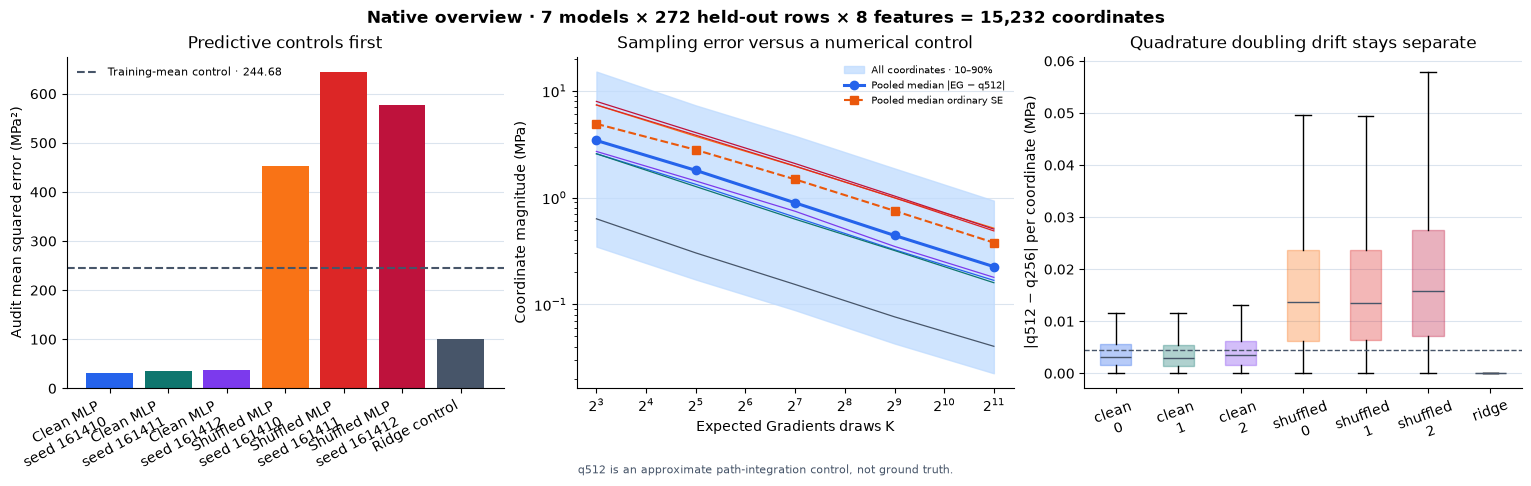

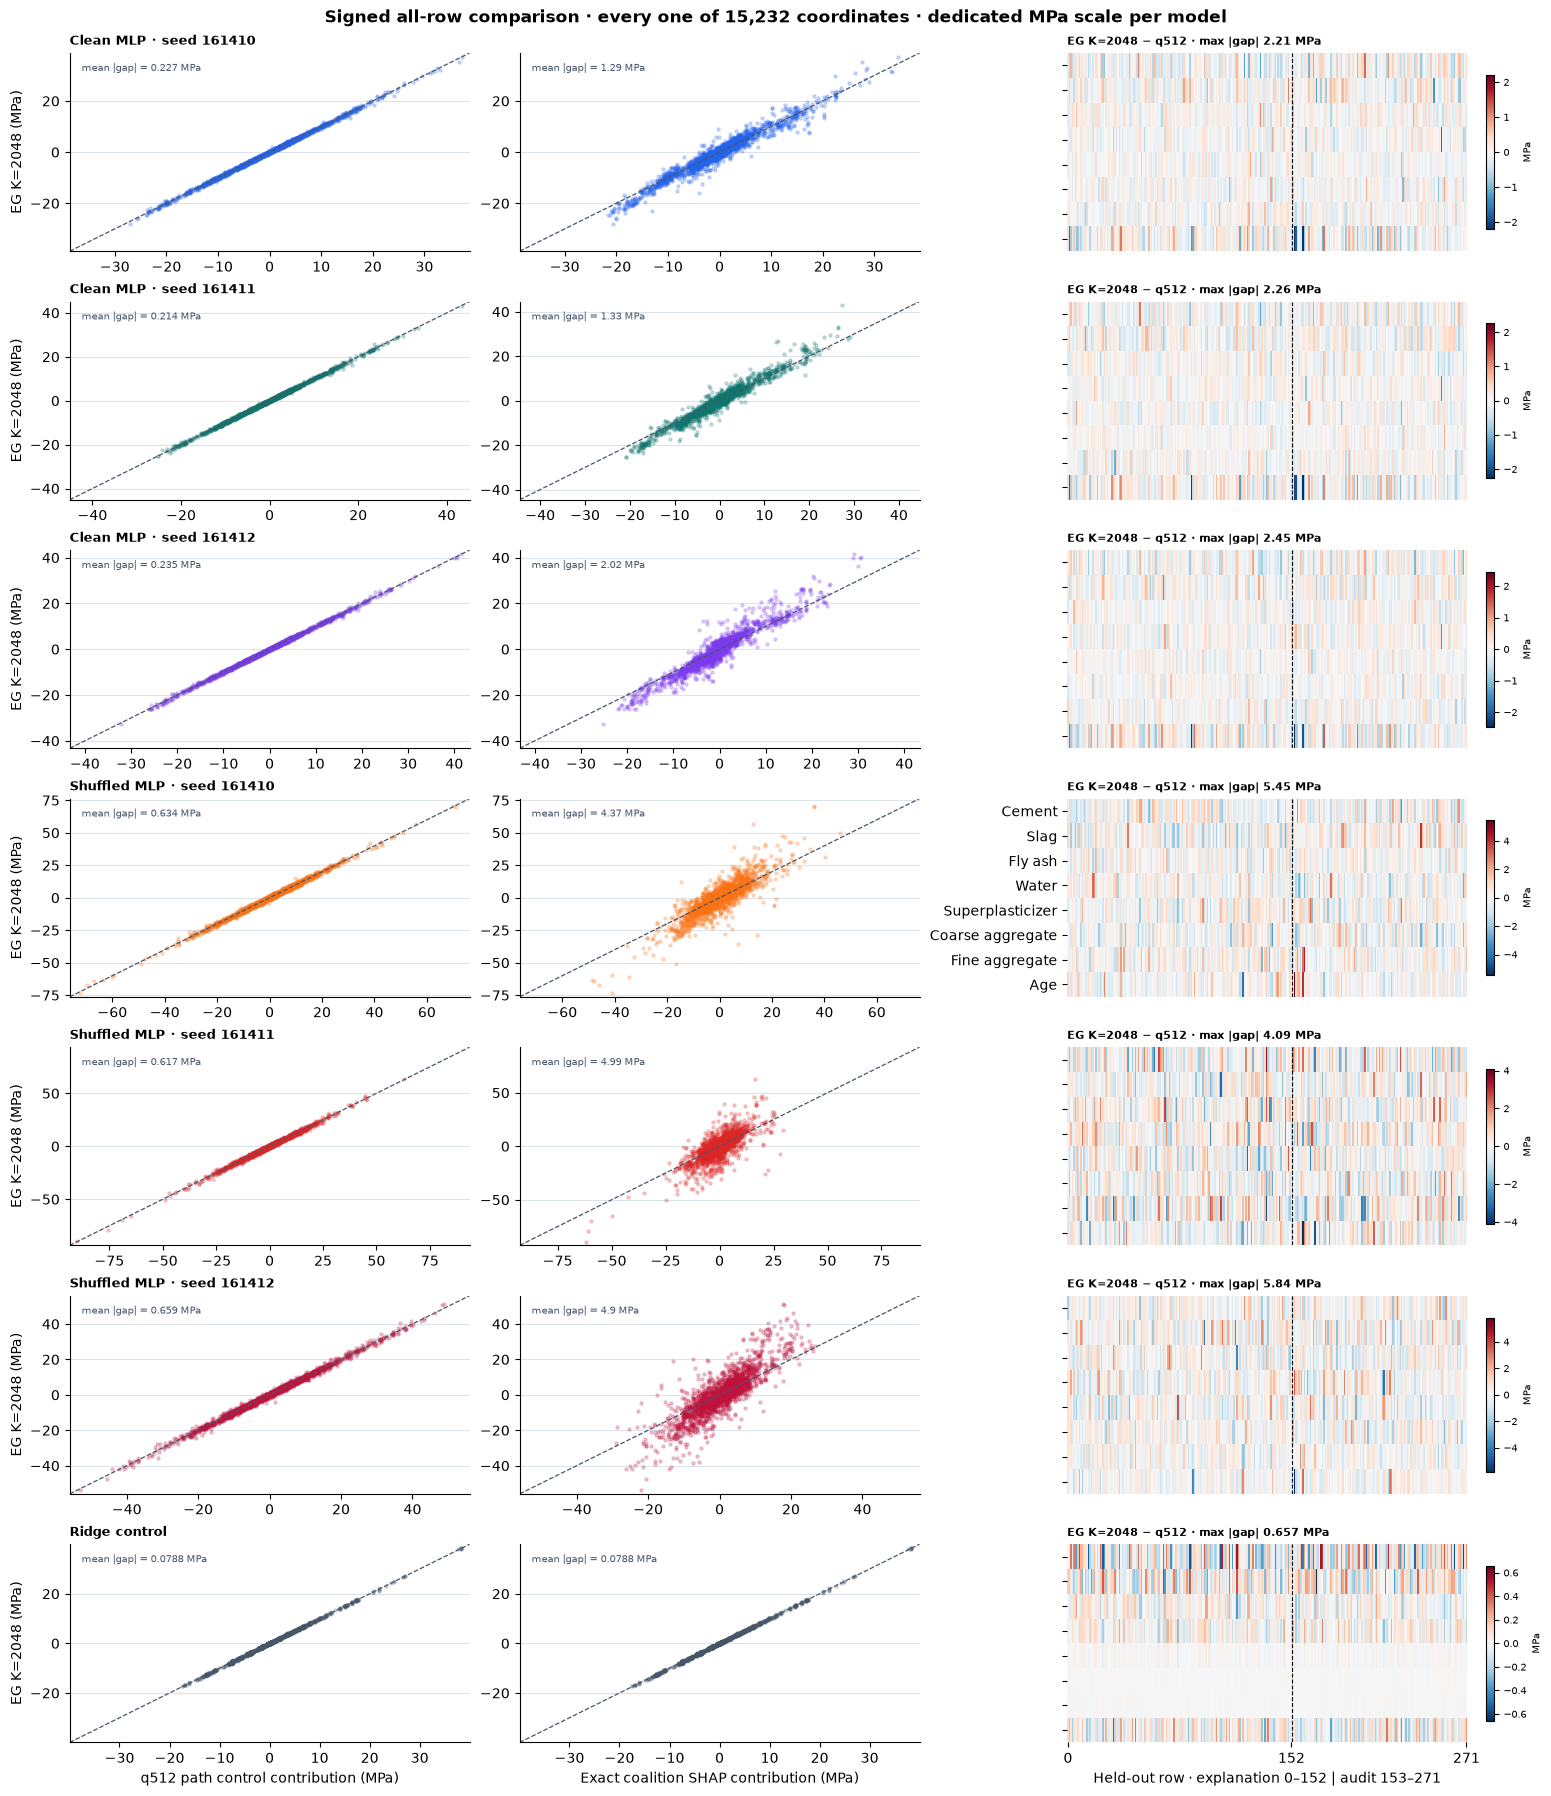

In [417]:
if MAIN:
    gradient_show_figure(
        gradient_plots.plot_native_overview(gradient_prepared, gradient_evaluated),
        "14_native_overview",
    )
if MAIN:
    gradient_show_figure(
        gradient_plots.plot_allrow_method_map(gradient_evaluated),
        "15_allrow_method_map",
    )

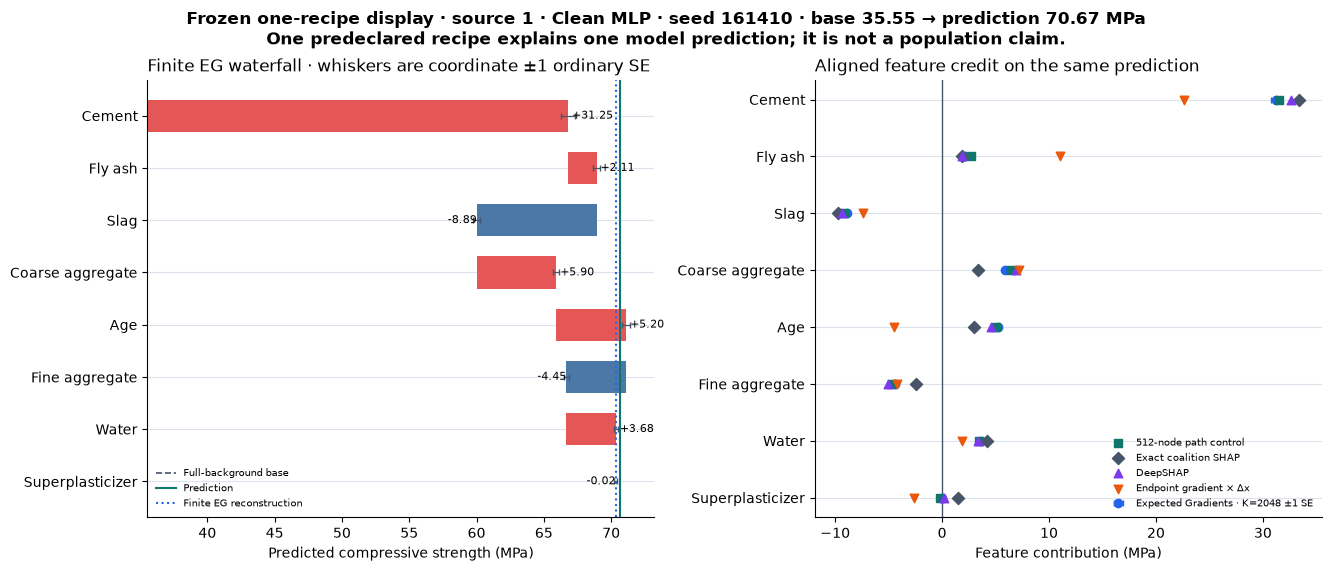

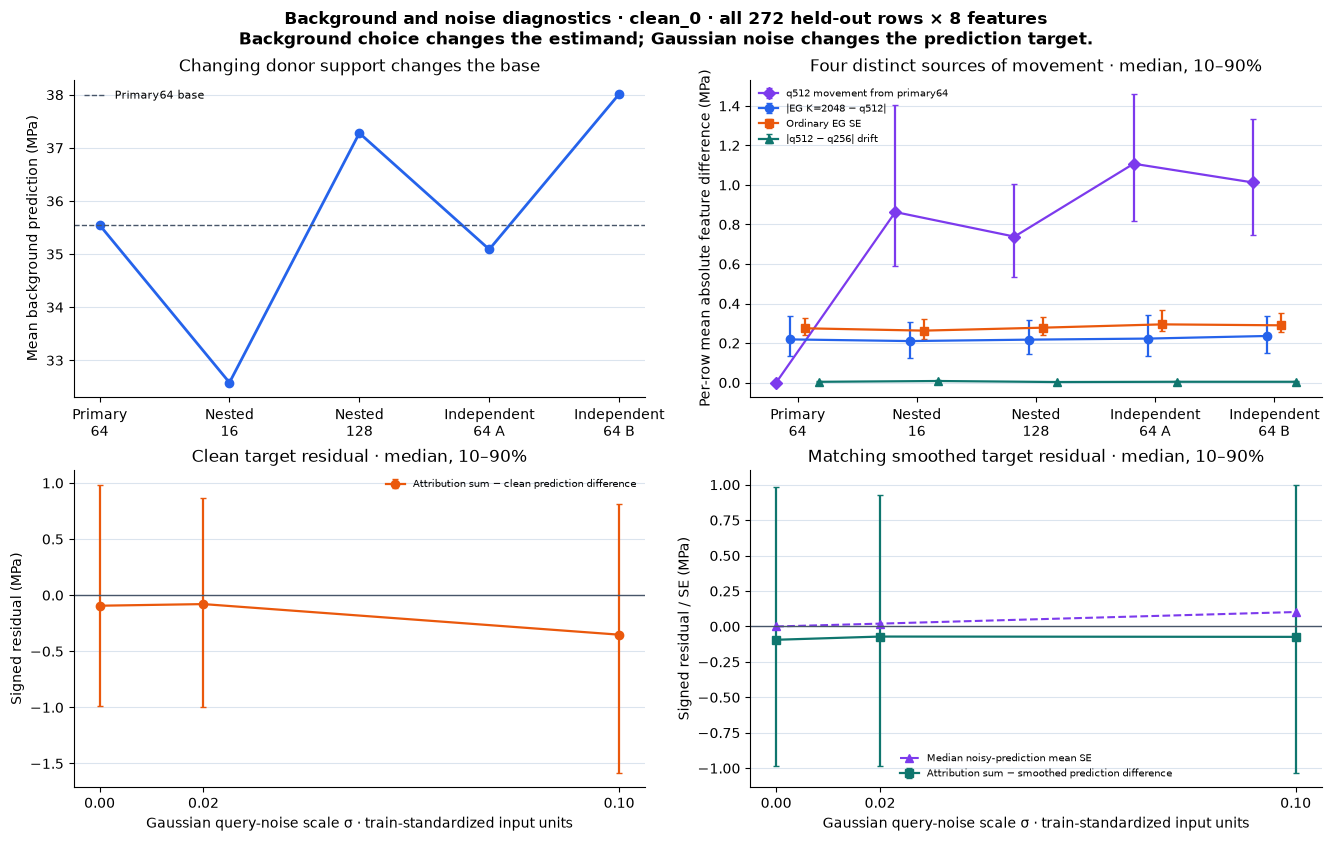

In [418]:
if MAIN:
    gradient_show_figure(
        gradient_plots.plot_fixed_waterfall(gradient_fixed_play, feature_names=gradient_FEATURE_NAMES),
        "16_fixed_waterfall",
    )
if MAIN:
    gradient_show_figure(
        gradient_plots.plot_background_and_noise(gradient_evaluated),
        "17_background_and_noise",
    )

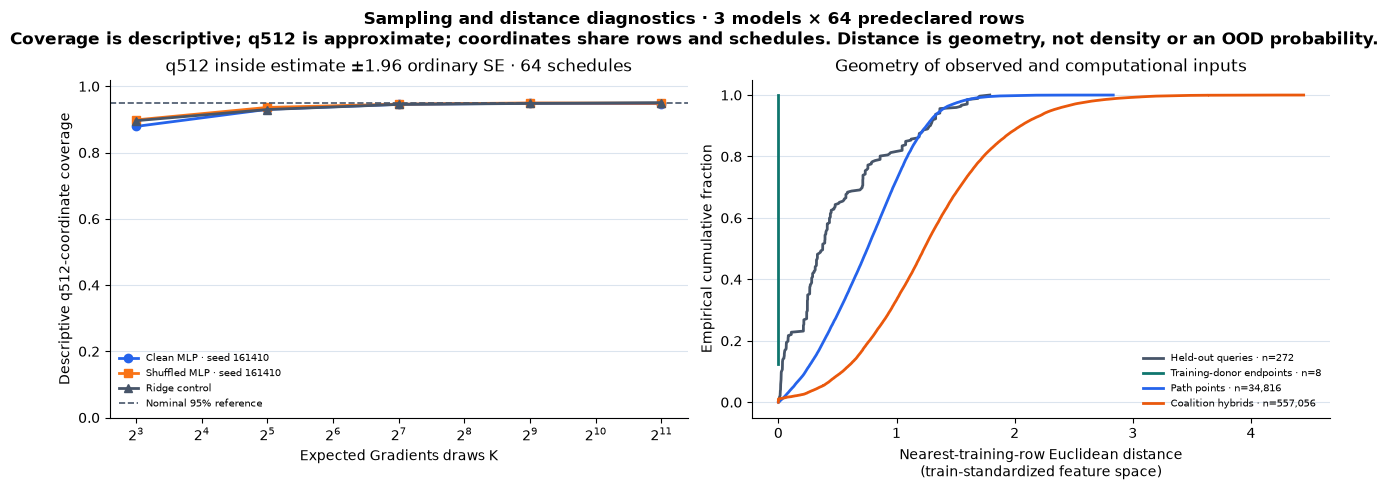

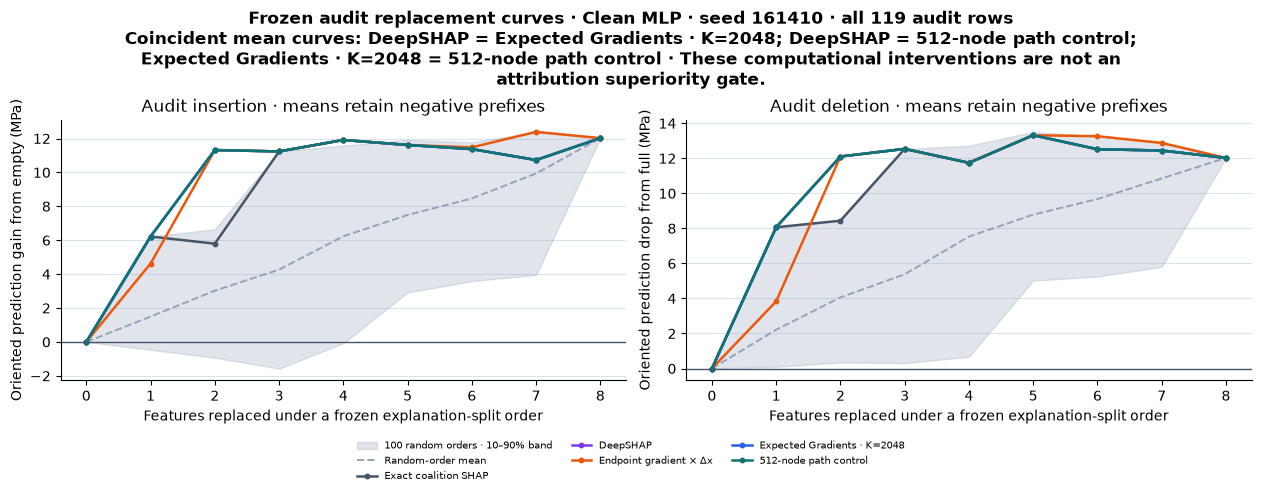

In [419]:
if MAIN:
    gradient_show_figure(
        gradient_plots.plot_replicates_and_distance(gradient_evaluated),
        "18_replicates_and_distance",
    )
if MAIN:
    gradient_show_figure(
        gradient_plots.plot_replacement_curves(gradient_evaluated, model_key="clean_0"),
        "19_replacement_curves",
    )

### Try It Yourself 2 — choose a recipe, background, budget, and noise scale

The canonical first run must use the first audit recipe, `clean_0`, the primary 64-row background,
K=2048, and sigma zero. After reproducing that fixed display, edit the model, any held-out source
row, one of the five background designs, a nested K budget, or a predeclared sigma. Recompute the
clean/noisy samples, quadrature control, exact feature game, and local replacement curves rather
than slicing cached arrays.

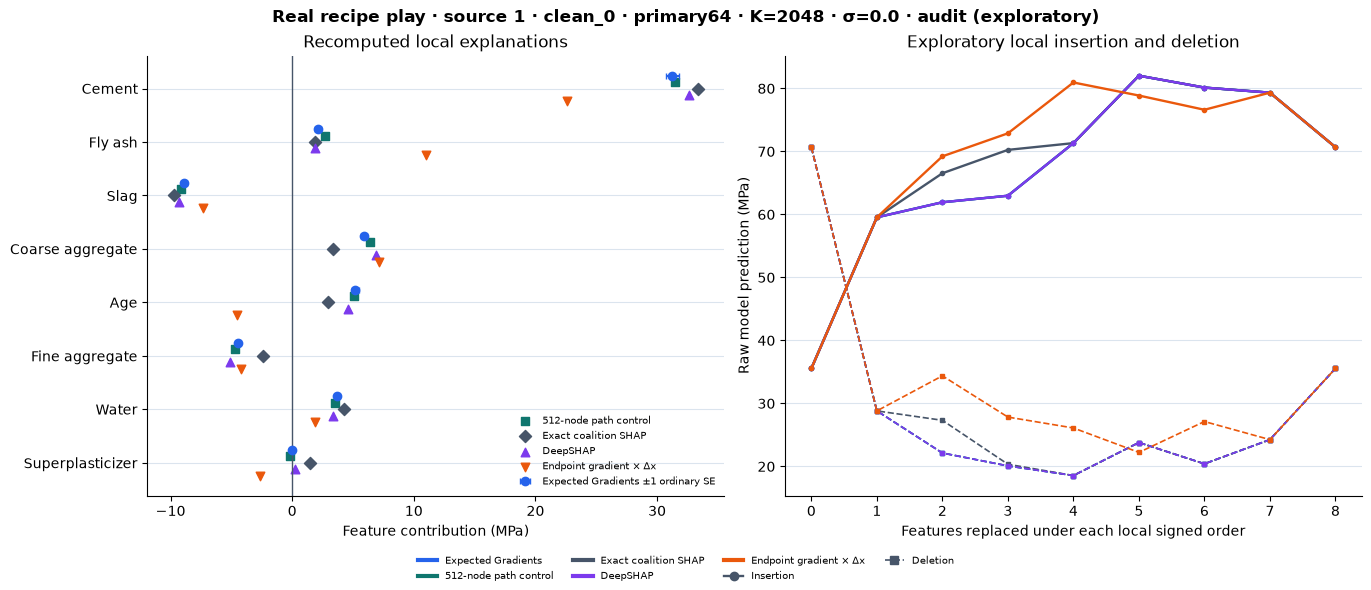

In [420]:
if MAIN:
    gradient_real_play = gradient_native_play(
        gradient_fitted,
        gradient_prepared,
        gradient_evaluated,
        gradient_train,
        gradient_explain,
        gradient_audit,
        methods=gradient_methods,
        deep_methods=deep_methods,
        model_key="clean_0",
        split="audit",
        row_index=0,
        background_key="primary64",
        samples=2048,
        sigma=0.0,
    )
if MAIN:
    gradient_show_figure(
        gradient_plots.plot_real_recipe_play(gradient_real_play, feature_names=gradient_FEATURE_NAMES),
        "20_real_recipe_play",
    )

<details><summary>Ideas to try</summary>

- Hold model and row fixed while moving from nested 16 to primary 64 to nested 128 donors.
- Compare sigma zero with `0.02` and `0.10`; read the clean and smoothed residuals separately.
- Find a row whose EG and exact global orders agree while their signed magnitudes differ.
- Compare K=32 and K=2048 on the same literal prefix, then inspect whether the ordinary SE predicted
the observed change.
- Compare a clean and shuffled model on the same recipe before interpreting either explanation.

These choices occur after audit evaluation. They are exploratory diagnostics and cannot support a
new confirmatory audit claim.

</details>

## How to interpret the completed study

Read the eventual figures in this order:

1. Require clean predictors to beat the training-mean and shuffled-target controls before discussing
attribution quality.
2. Validate the nine methods on analytic fixtures and require strict same-draw author parity. Keep
that implementation check separate from convergence to the path target.
3. Compare nested Monte Carlo estimates with quadrature doubling and ordinary SE. A small SE with a
large 256-to-512 change points to integration-control limits; a large SE is sampling instability.
4. Compare completeness residuals with signed coordinate differences. A path method may converge
and be complete while disagreeing with exact feature-coalition Shapley.
5. Read background movement beside sampling error. Alternate empirical supports ask different
questions; they are not replicate confidence intervals for one population target.
6. At nonzero noise, compare with the smoothed-query prediction. A clean-target discrepancy can be
the intended target shift rather than failed local accuracy.
7. Read global audit replacement curves beside random orders and all-row variability. A favorable
early prefix does not establish exact attribution or physical causality.

## Limitations and method scope

Expected Gradients uses straight paths and ordinary derivatives. Exact ReLU kinks require a
subgradient convention, finite Monte Carlo estimates have sampling error, and finite quadrature is
approximate for gradient jumps. Background choice is part of the estimand. Convex interpolation,
Gaussian perturbation, and feature-coalition replacement can create inputs far from observed
recipes.

The Concrete background is empirical and observational. Replacing cement, water, aggregate, or age
inside a predictor is a computational intervention on its input. It is not a randomized physical
experiment or evidence that the attribution is a causal effect in concrete production.

For classification, explaining a logit, probability, or loss would define different scalar
functions. This study avoids that ambiguity by explaining raw MPa. It does not add attribution-prior
training: changing the training objective would require a new pre-fit protocol, lambda selection,
performance guardrails, and repeated training evidence.

## Further research

- Compare independent schedule replicates with nominal `estimate ± 1.96 SE` coverage on a
predeclared coordinate set without treating coordinates as independent experiments.
- Test antithetic or stratified alpha sampling as optional variance-reduction estimators, reporting
measured variance instead of assuming improvement.
- Split ReLU paths analytically at known activation kinks and compare exact piecewise integration
with Gauss-Legendre drift.
- Replace isotropic Gaussian noise with a declared domain-aware perturbation and derive its new
smoothed target before measuring it.
- Add attribution-prior training only under a separately frozen study that retains predictive
performance and repeated-seed controls.

## Reading

- Erion et al., [*Improving performance of deep learning models with axiomatic attribution priors
and expected gradients*](https://arxiv.org/abs/1906.10670).
- Sundararajan, Taly and Yan,
[*Axiomatic Attribution for Deep Networks*](https://proceedings.mlr.press/v70/sundararajan17a.html).
- Lundberg and Lee,
[*A Unified Approach to Interpreting Model Predictions*](https://arxiv.org/abs/1705.07874).
- Official SHAP
[`GradientExplainer`
documentation](https://shap.readthedocs.io/en/stable/generated/shap.GradientExplainer.html).
- Official Captum
[`GradientShap` documentation](https://captum.ai/api/gradient_shap.html).

# Bonus

## Finish the comparison

For each method, state the player set, scalar output, missingness or path distribution, background,
comparison metric and denominator. Explain how a complete attribution, an exact coalition allocation
and a converged path expectation differ. Keep every original limitation, negative result and
predeclared audit boundary above.